# VCA grey-box fit V2

Goal: a model of the VCA that predicts the position well at higher frequencies, in particular in the application band, 35–55 Hz.

1. **Raw data, and from raw data to fit data:** what the log contains (timing, mains pickup, stale rows, the laser's distortion and modes, the accelerometer), and the processing decided from it; a new loader.
2. **Simulation and standard validation:** one simulator (sent current through a drive delay, RK4, burn-in) and one check that every model goes through.
3. **Model C**, the baseline, on the new data; **the drive delay** (D1).
4. **The slow offset:** a measurement disturbance, judged apart from the oscillation; an output-error fit.
5. **The laser's sensor model** (a mode at 34 Hz); two dead ends (a second mode, a drive lead).
6. **The spring from low frequencies:** the plain chirps at large stroke, with the laser's clipping masked.
7. **A learned correction on the output** for the slow offset, judged in free run on both regimes.

**Colours in every validation figure:** measured in black; the model being validated in red (test solid, train faint); the reference model in grey.

## Setup

Constants, the data loader, the RK4 step, the rollout and the fit helper. The validation is defined once, in its own section below the data.


In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy import signal
from scipy.optimize import least_squares, lsq_linear

sns.set_theme(style="whitegrid")

FS_LOG, DECIM = 2000.0, 2
TS = 1/1000.0                       # discretization inter-sampling time
M = 51.5                            # kg
GAMMA0, C0 = 283.0, 1700.0          # datasheet; iteration
CMU0, G00 = 2.423, 22.3e-3          # PDF eq. 13; measured gap in experiment
s_ds = lambda x: (283 - 0.0198 * (x * 1e3) - 0.578 * (x * 1e3)**2) / 283   # datasheet K_f(z) shape, z in mm, 1 at the centre
LF_MAX, HF_MIN = 5.0, 37.0          # Hz; Low freq range and high freq range, ub and lb (37 Hz: above the 35.5 Hz laser-mount mode)
H_FIT, H_EVAL, STRIDE = 500, 500, 10 # steps for fitting the data
FOH = False                         # Zero-order hold
TAU = 0.65e-3                       # s, position is logged this much later than the commanded current (tuned on actual current: retune); undone in load
TAU_ACC = 2.65e-3                   # s, accelerometer is logged this much later than the commanded current (tuned on actual current: retune); undone in load
T_CUT = 5.0                         # s, end of each run left out of the HF band
ACC_SCALE_V_PER_G = 0.0578 * 0.65   # accelerometer V/g: plot-script 0.0578 corrected by the gain against position above 35 Hz (0.60-0.68)
F_MAX_A = 55.0                      # Hz, Methods A-C use the scheduled chirp up to this frequency (55 = whole run; 34 stays below the 35.5 Hz mode)

b_lp, a_lp = signal.butter(4, 100.0 / (FS_LOG / 2))   # 4th-order 100 Hz low-pass


def load(path):
    "Read one log; return filtered current, position and acceleration at 1 kHz (t >= 0), velocity, and band masks."
    # chirp start/end frequency and duration from the file name, e.g. ..._1.0to55.0Hz_120.0s_...
    m = re.search(r"_([\d.]+)to([\d.]+)Hz_([\d.]+)s_", path.name)
    f0, f1, T = map(float, m.groups()) if m else (np.nan,) * 3   # no chirp in the name (e.g. PRBS): band masks are empty
    raw = np.loadtxt(path, delimiter=",", skiprows=2)   # skip header and the duplicate first row
    lp = lambda s: signal.filtfilt(b_lp, a_lp, s)       # zero-phase, also the anti-alias filter for decimation
    # columns 0 time_s, 2 target_current_A (commanded, sent over EtherCAT), 11 position_mm, 12 ai2_corrected_V (bias removed in firmware)
    t = raw[:, 0]
    x = np.interp(t + TAU, t, lp(raw[:, 11] * 1e-3))   # shift position back by TAU to align it with the current
    for f_n in (50.0, 150.0):                           # mains pickup in the laser signal
        x = signal.filtfilt(*signal.iirnotch(f_n, 30.0, fs=FS_LOG), x)
    a = (np.interp(t + TAU_ACC, t, lp(raw[:, 12])) / ACC_SCALE_V_PER_G * 9.81 if raw.shape[1] > 12   # measured acceleration, shifted back by TAU_ACC
         else np.full(len(t), np.nan))                          # older logs have no ai2_corrected_V
    keep = slice(np.searchsorted(t, 0.0), None, DECIM)  # drop the t < 0 idle window, 2 kHz -> 1 kHz
    d = dict(t=t[keep], i=lp(raw[:, 2])[keep], x=x[keep], a_meas=a[keep])
    d["v"] = np.gradient(d["x"], TS)                    # velocity: initial states and LLS
    d["a_x"] = np.gradient(d["v"], TS)                  # acceleration from position
    d["a"] = d["a_x"]                                   # fits use position-derived acceleration; accelerometer only plotted
    f = f0 * (f1 / f0) ** (d["t"] / T)                  # instantaneous frequency of the exponential chirp
    d["lf"] = f <= LF_MAX                               # old low band, used by methods B-D
    d["hf"] = (f >= HF_MIN) & (d["t"] <= d["t"][-1] - T_CUT)
    d["sweep"] = f <= F_MAX_A                           # Methods A-C window: scheduled chirp from its start up to F_MAX_A
    return d


def step(x, v, u0, u1, acc, ts=TS):
    "One RK4 step, length ts, of (x, v) with input u0 at the start and u1 at the end of the step."
    um = 0.5 * (u0 + u1)
    k1x, k1v = v, acc(x, v, u0)
    k2x, k2v = v + ts / 2 * k1v, acc(x + ts / 2 * k1x, v + ts / 2 * k1v, um)
    k3x, k3v = v + ts / 2 * k2v, acc(x + ts / 2 * k2x, v + ts / 2 * k2v, um)
    k4x, k4v = v + ts * k3v, acc(x + ts * k3x, v + ts * k3v, u1)
    return x + ts / 6 * (k1x + 2 * k2x + 2 * k3x + k4x), v + ts / 6 * (k1v + 2 * k2v + 2 * k3v + k4v)


def rollout(Fs, p, d, s, H):
    "Predicted x, shape (len(s), H+1), from the measured state at each start index s. p = [Gamma, c, *spring]."
    acc = lambda x, v, u: (p[0] * u - p[1] * v - Fs(x, u, p[2:])) / M      # Fs gets the current too, for Gamma(x)
    x, v, out = d["x"][s], d["v"][s], [d["x"][s]]
    with np.errstate(all="ignore"):
        for k in range(H):
            u0 = d["i"][s + k]
            x, v = step(x, v, u0, d["i"][s + k + 1] if FOH else u0, acc)
            out.append(x)
    return np.stack(out, axis=1)


def starts(d, band, H):
    "Every STRIDE-th sample of the band whose H-step horizon fits in the record."
    s = np.flatnonzero(band)[::STRIDE]
    return s[s + H < len(d["x"])]


def target(d, s, H):
    "Measured x over the horizon of each start, shape (len(s), H+1)."
    return d["x"][s[:, None] + np.arange(H + 1)]


def fit(Fs, p0, d, band, lb=-np.inf, free=slice(None), detrend=False):
    "H-step-ahead fit of p0[free]; detrend removes per-start mean and slope of the error (free-mass drift)."
    s = starts(d, band, H_FIT)
    X = target(d, s, H_FIT)[:, 1:]
    p = np.array(p0, float)
    def res(q):
        p[free] = q
        e = np.nan_to_num(rollout(Fs, p, d, s, H_FIT)[:, 1:], nan=1.0, posinf=1.0, neginf=-1.0) - X   # diverged rollout -> 1 m
        return (signal.detrend(e, axis=1) if detrend else e).ravel()
    r = least_squares(res, p[free], x_scale=np.abs(p[free]), bounds=(lb, np.inf))
    p[free] = r.x
    print(f"{r.message} ({r.nfev} evaluations)")
    return p


# self-check: undamped linear spring from x = 1 mm must follow cos(wt)
_k = 1e5
_d = dict(x=np.full(2, 1e-3), v=np.zeros(2), i=np.zeros(1000))
_x = rollout(lambda x, u, q: q[0] * x, [0.0, 0.0, _k], _d, np.array([0]), 900)[0]
assert np.allclose(_x, 1e-3 * np.cos(np.sqrt(_k / M) * TS * np.arange(901)), atol=1e-8)

## Cache for the slow fits

The output-error fits below each simulate thousands of predictions per evaluation and take several minutes. With `USE_CACHE = True` their results are stored in `CACHE_PATH` the first time and loaded from there on later runs. Each result is stored under its name and a fingerprint of its inputs (start values and settings), so a changed fit is recomputed automatically.

- **`USE_CACHE = False`** recomputes everything (and refreshes the cache), for example after a change to the data or the processing that the fingerprint does not see.
- **The cache is a local file:** `data/` is git-ignored, so each person builds their own on the first run.
- **Only load a cache you made yourself:** it is a pickle file, and loading one runs code from it.

In [2]:
import hashlib
import pickle

USE_CACHE = True                                        # False: recompute every slow fit and refresh the cache
CACHE_PATH = Path("data", "hf_notebook_cache.pkl")
_CACHE = {}
if USE_CACHE and CACHE_PATH.exists():
    with open(CACHE_PATH, "rb") as f_:
        _CACHE = pickle.load(f_)


def cached(name, inputs, compute):
    "Result of compute(), stored under name and a fingerprint of inputs; loaded from the cache when both match."
    key = (name, hashlib.sha1(pickle.dumps(inputs)).hexdigest())
    if USE_CACHE and key in _CACHE:
        print(f"[cache] {name}: loaded")
        return _CACHE[key]
    result = compute()
    _CACHE[key] = result
    with open(CACHE_PATH, "wb") as f_:
        pickle.dump(_CACHE, f_)
    return result

## Raw data

The logs exactly as written by the firmware: every column, at the logged 2 kHz, with no filter, notch, time shift or decimation. Each log starts with a 3 s idle window at 0 A ($t < 0$, actuator at rest), followed by the run itself ($t \geq 0$).

**Shown:** position, current and accelerometer against time, for the run in `RAW_PLOT` (the train run of the scheduled chirp, which the model is fitted on). The current panel shows both the commanded current (`target_current_A`, the model input) and the current the drive measures (`actual_current_A`). The accelerometer is `ai2_corrected_V`, in volts with the bias from the idle window removed. The idle window is shaded.

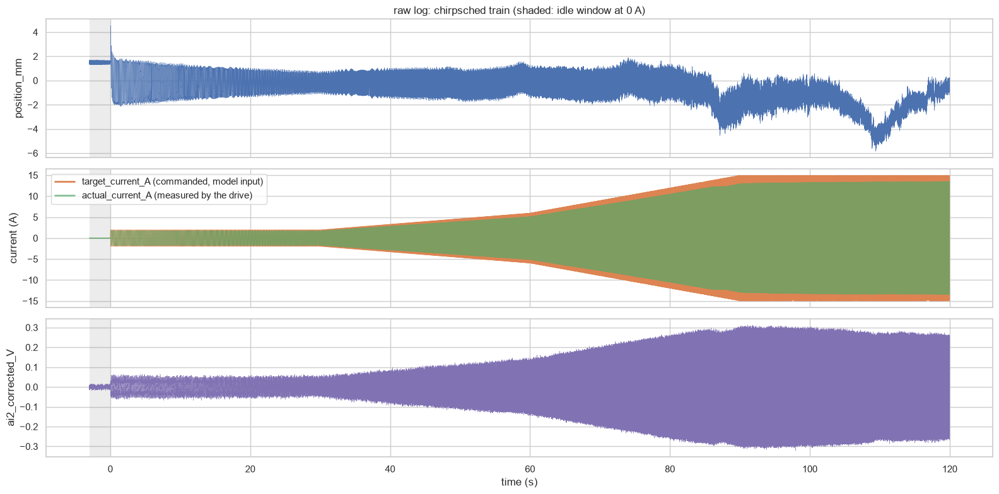

In [3]:
import pandas as pd

RAW_PLOT = ("chirpsched", "train")                      # run shown in the time plots
RAW_LOGS = {(exp, s): next(Path("data", s).glob(f"voice_coil_log_{exp}_*.csv")) for exp in ("chirpsched", "chirp") for s in ("train", "test")}


def read_raw(path):
    "The log exactly as written: every row and column, header names stripped of spaces."
    df = pd.read_csv(path)
    df.columns = df.columns.str.strip()
    return df


RAW_DF = {key: read_raw(path) for key, path in RAW_LOGS.items()}

# position, current and accelerometer against time, for one run
df = RAW_DF[RAW_PLOT]
t = df["time_s"]
fig, ax = plt.subplots(3, 1, figsize=(16, 8), sharex=True)
ax[0].plot(t, df["position_mm"], lw=0.3, color="C0")
ax[0].set_ylabel("position_mm")
ax[1].plot(t, df["target_current_A"], lw=0.3, color="C1", label="target_current_A (commanded, model input)")
ax[1].plot(t, df["actual_current_A"], lw=0.3, color="C2", alpha=0.7, label="actual_current_A (measured by the drive)")
ax[1].set_ylabel("current (A)")
for h in ax[1].legend(loc="upper left").get_lines():
    h.set_linewidth(2)                                  # legend lines readable despite the thin traces
ax[2].plot(t, df["ai2_corrected_V"], lw=0.3, color="C4")
ax[2].set_ylabel("ai2_corrected_V")
for a_ in ax:
    a_.axvspan(t.iloc[0], 0.0, color="0.5", alpha=0.15, lw=0)
ax[0].set_title(f"raw log: {RAW_PLOT[0]} {RAW_PLOT[1]} (shaded: idle window at 0 A)")
ax[-1].set_xlabel("time (s)")
plt.tight_layout(); plt.show()


## From raw data to fit data

The raw log is all we have. This section works out, from the data itself, what the logged signals are and how they should be turned into the inputs of a fit. Nothing from earlier processing is assumed; the four questions are taken one at a time.

### 1. Timing: what is in one row of the log?

A row is written every 0.5 ms. It holds a time stamp, three currents (`target_current_A`, `demand_current_A`, `actual_current_A`), the laser and accelerometer voltages (`ai1_value_V`, `ai2_value_V`), the position derived from the laser (`position_mm`) and the bias-corrected accelerometer (`ai2_corrected_V`).

- Which of the three currents is the input to the actuator?
- When was each value in a row measured? A common time stamp does not mean a common sampling instant.
- How often does each channel really update?

**The current the master sent.** Every logged column is the drive's reply in that cycle; the current the master sent is not logged. In these open-loop runs it is a fixed function of time, so it can be recomputed exactly. In the firmware that recorded these logs (commit `829db32`, `control_loop.c`), the master computes the current for a cycle from the same elapsed time that is written as `time_s` in that row:

$$i_\text{sent}(t) = A(t)\,\sin\!\Big(2\pi f_0 L\,\big(e^{t/L} - 1\big)\Big), \qquad L = \frac{T}{\ln(f_1/f_0)}$$

with $f_0$, $f_1$ and $T$ from the file name, and the amplitude $A(t)$ from the schedule in the file name (`0.0s2.0A-30.0s6.0A-60.0s15.0A-r30.0s`: from each breakpoint, a linear ramp of 30 s to the new amplitude). The raw value is rounded to the drive's integer units; that rounding is ignored here.

**Comparison.** Each logged current $y$ is compared with the sent current shifted by a delay $\tau$ and scaled by a gain $g$:

$$y(t) \approx g\; i_\text{sent}(t - \tau)$$

$i_\text{sent}$ is a formula, so it is evaluated at $t - \tau$ directly, with no interpolation. Per 5 Hz band of the chirp, $\tau$ is found on a grid of `TAU_GRID` and $g$ by least squares at each $\tau$. A pure delay gives the same $\tau$ in every band; a filter-like lag gives a $\tau$ that changes with frequency.

Shown, for the scheduled chirp (train): the raw samples of the three logged currents (one point per row, 0.5 ms apart) against $i_\text{sent}$ over `ZOOM_LEN` = 20 ms from `ZOOM_T0` = 100 s, where the chirp is near 46 Hz; and $\tau$ and $g$ per band for each logged current.

target_current_A  whole sweep: delay 1.16 ms, gain 0.996, rms misfit 8.7 % of the signal std


demand_current_A  whole sweep: delay 1.24 ms, gain 0.996, rms misfit 7.7 % of the signal std


actual_current_A  whole sweep: delay 1.60 ms, gain 0.877, rms misfit 8.0 % of the signal std


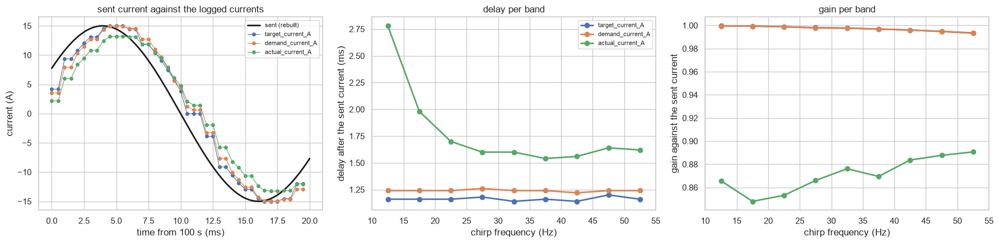

In [4]:
ZOOM_T0, ZOOM_LEN = 100.0, 0.02                         # s, start and length of the raw-sample zoom
TAU_GRID = np.arange(0.0, 5.0 + 1e-9, 0.02) * 1e-3   # s, delays tried
SENT_BANDS = np.arange(10.0, 55.0 + 1e-9, 5.0)        # Hz, band edges


def sent_current_fn(path):
    "Current the master sent, as a function of time, rebuilt from the chirp and schedule in the file name (firmware 829db32; plain chirps: 985ce63, same formula)."
    m = re.search(r"chirpsched_(.+?)-r([\d.]+)s_([\d.]+)to([\d.]+)Hz_([\d.]+)s_", path.name)
    if m:                                               # scheduled chirp: amplitude breakpoints with linear ramps
        bps = [tuple(map(float, re.fullmatch(r"([\d.]+)s([\d.]+)A", b).groups())) for b in m.group(1).split("-")]
        ramp, f0, f1, T = map(float, m.groups()[1:])
    else:                                               # plain chirp: constant amplitude
        m = re.search(r"chirp_([\d.]+)A_([\d.]+)to([\d.]+)Hz_([\d.]+)s_", path.name)
        a0, f0, f1, T = map(float, m.groups())
        bps, ramp = [(0.0, a0)], 0.0
    L = T / np.log(f1 / f0)

    def amp(t):
        "Firmware chirp_sched_amplitude_A: last breakpoint at or before t, ramped in from the previous one."
        a = np.full_like(t, bps[0][1])
        for (t_prev, a_prev), (t_i, a_i) in zip(bps[:-1], bps[1:]):
            into = t - t_i
            a = np.where(into >= 0, np.where(into < ramp, a_prev + (a_i - a_prev) * into / ramp, a_i), a)
        return a

    def i_sent(t):
        t = np.asarray(t, float)
        on = (t >= 0) & (t < T)                           # 0 A in the idle window and after the sweep
        return np.where(on, amp(t) * np.sin(2 * np.pi * f0 * L * (np.exp(t / L) - 1.0)), 0.0)

    return i_sent, (lambda t: f0 * (f1 / f0) ** (np.asarray(t) / T))


def delay_gain(t, y, i_sent):
    "Delay tau on TAU_GRID and gain g (least squares) that best fit y(t) = g i_sent(t - tau); also the relative rms misfit."
    best = (np.inf, None, None)
    for tau in TAU_GRID:
        s = i_sent(t - tau)
        g = (s @ y) / (s @ s)
        r = np.sqrt(np.mean((y - g * s) ** 2)) / np.std(y)
        if r < best[0]:
            best = (r, tau, g)
    return best[1], best[2], best[0]


path = RAW_LOGS["chirpsched", "train"]
i_sent, f_of_t = sent_current_fn(path)
run = RAW_DF["chirpsched", "train"]
run = run[run["time_s"] >= 0]
t_all = run["time_s"].to_numpy()
CURRENTS = ["target_current_A", "demand_current_A", "actual_current_A"]

res = {c: [] for c in CURRENTS}
for lo, hi in zip(SENT_BANDS[:-1], SENT_BANDS[1:]):
    m = (f_of_t(t_all) >= lo) & (f_of_t(t_all) < hi)
    for c in CURRENTS:
        res[c].append(delay_gain(t_all[m], run[c].to_numpy()[m], i_sent))
for c in CURRENTS:
    tau, g, r = delay_gain(t_all, run[c].to_numpy(), i_sent)
    print(f"{c:17s} whole sweep: delay {tau * 1e3:.2f} ms, gain {g:.3f}, rms misfit {r * 100:.1f} % of the signal std")

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
z = (t_all >= ZOOM_T0) & (t_all < ZOOM_T0 + ZOOM_LEN)
t_fine = np.linspace(ZOOM_T0, ZOOM_T0 + ZOOM_LEN, 400)
ax[0].plot((t_fine - ZOOM_T0) * 1e3, i_sent(t_fine), color="k", lw=2, label="sent (rebuilt)")
for j, c in enumerate(CURRENTS):
    ax[0].plot((t_all[z] - ZOOM_T0) * 1e3, run[c].to_numpy()[z], "o-", ms=4, lw=0.8, color=f"C{j}", label=c)
ax[0].set(xlabel=f"time from {ZOOM_T0:.0f} s (ms)", ylabel="current (A)", title="sent current against the logged currents")
ax[0].legend(fontsize=8)
f_mid = 0.5 * (SENT_BANDS[:-1] + SENT_BANDS[1:])
for j, c in enumerate(CURRENTS):
    tau, g, _ = np.array(res[c], dtype=float).T
    ax[1].plot(f_mid, tau * 1e3, "o-", color=f"C{j}", lw=2, ms=6, label=c)
    ax[2].plot(f_mid, g, "o-", color=f"C{j}", lw=2, ms=6, label=c)
ax[1].set(xlabel="chirp frequency (Hz)", ylabel="delay after the sent current (ms)", title="delay per band", xticks=SENT_BANDS)
ax[2].set(xlabel="chirp frequency (Hz)", ylabel="gain against the sent current", title="gain per band", xticks=SENT_BANDS)
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()


def prbs_current_fn(path):
    "Current the master sent in a PRBS run, as a function of time (firmware 07ab654): a 15-bit LFSR (x^15 + x^14 + 1, seed 1), +A or -A, each bit held PRBS_HOLD_CYCLES cycles."
    A, bw, T = map(float, re.search(r"prbs_([\d.]+)A_([\d.]+)Hz_([\d.]+)s_", path.name).groups())
    hold = int(400.0 / (bw * 0.5))                      # PRBS_HOLD_CYCLES at a 0.5 ms cycle
    n_bits = int(T * 2000 / hold) + 2
    lfsr, seq = 1, np.empty(n_bits)
    for k in range(n_bits):                             # seq[k]: output while bit k is held
        seq[k] = A if lfsr & 1 else -A
        lfsr = (((lfsr << 1) | (((lfsr >> 14) ^ (lfsr >> 13)) & 1)) & 0x7FFF)

    def i_fn(t):
        t = np.asarray(t, float)
        k = np.clip(np.rint(t * 2000.0).astype(np.int64) // hold, 0, n_bits - 1)
        return np.where((t >= 0) & (t < T), seq[k], 0.0)

    return i_fn


**Findings (scheduled chirp, train).**

- **The logged target current is not what the master sent.** It is the sent current arriving about 1.2 ms later, unchanged in size. The demand current is the same.
- **So the logged target current adds nothing as an input.** The earlier notebooks used it; it only adds a delay and stale rows.
- **The current through the coil is smaller and later.** The drive's measured current is about 12 % below what was sent and arrives about 1.6 ms later.
- **Below 20 Hz the measured current lags even more** (up to 2.8 ms), which no simple filter explains. Section 4 shows this is mostly a frequency effect, also at a constant 6 A, with a little extra lag at small current; it is not the cause of the force loss at small current found there.

**Decision: the input is the sent current, through an explicit drive block.** $i_\text{sent}$ is exact, noise-free, with known timing, and it is what a controller knows. The model becomes a chain:

$$i_\text{sent} \;\xrightarrow{\text{drive}}\; i_\text{coil} \;\xrightarrow{\text{mechanics}}\; x$$

Mechanics (Model C, driven by the coil current):

$$m\ddot{x} = (\Gamma + \Gamma_1 x)\, i_\text{coil} - c\,\dot{x} - F_\text{mag}(x)$$

Drive block, first form D1, a delay and a gain:

$$i_\text{coil}(t) = g\; i_\text{sent}(t - \tau_d), \qquad D(s) = g\, e^{-s\tau_d}$$

- $g$ and $\Gamma$ only appear as the product $g\Gamma$, so $g = 1$ and $\Gamma$ is the force per *sent* ampere.
- $i_\text{sent}$ is a formula, so $i_\text{sent}(t - \tau_d)$ is evaluated exactly, for any $\tau_d$; D1 adds no state.
- $\tau_d$ collects every delay between the sent current and the measured position: the drive, and the laser's own path. Position data cannot tell those apart.

**Why the delay has its own parameter.** Without it, the delay is absorbed elsewhere. Above the spring resonance the mass dominates, $m\ddot{x} \approx \Gamma i$, and for $i = I\sin\omega t$:

$$\Gamma\, i(t - \tau) \approx \Gamma\, i(t) - \Gamma\tau\,\frac{di}{dt}, \qquad -\Gamma\tau\,\frac{di}{dt} \approx m\,\omega^2\tau\,\dot{x}$$

a negative damping $m\omega^2\tau$ that grows with frequency: for $\tau$ = 1.2 ms about 240 N·s/m at 10 Hz and about 6100 N·s/m at 50 Hz, against Model C's $c \approx$ 1600 N·s/m.

**Check on all runs.** The reconstruction of $i_\text{sent}$ and the delay of the readback were found on the scheduled chirp (train). The same comparison (`delay_gain` per 5 Hz band, `target_current_A` against $i_\text{sent}$) on all four runs: if the reconstruction holds, every run gives a gain of 1 and the same delay in every band.

scheduled train: 2 A, ramp to 6 A from 15 Hz     whole sweep: delay 1.16 ms, gain 0.996, rms misfit 8.7 %; delay per band 1.14-1.20 ms


scheduled test: 3 A, ramp to 7 A from 15 Hz      whole sweep: delay 1.16 ms, gain 0.997, rms misfit 8.2 %; delay per band 1.14-1.18 ms


plain train: 6.5 A                               whole sweep: delay 1.16 ms, gain 0.998, rms misfit 6.3 %; delay per band 1.12-1.22 ms


plain test: 6.0 A                                whole sweep: delay 1.16 ms, gain 0.998, rms misfit 6.2 %; delay per band 1.12-1.18 ms


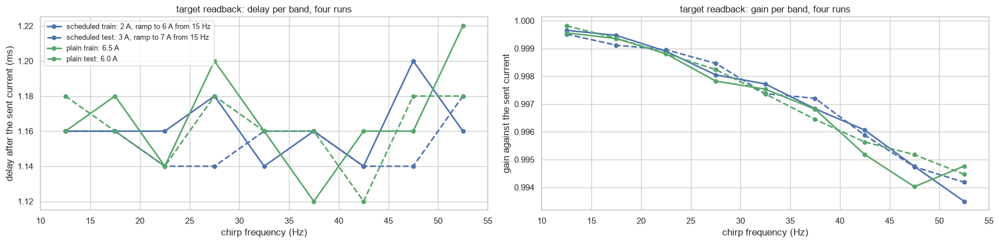

In [5]:
RUNS_AMP = [                                            # (run, label, colour, line style): the four runs
            (("chirpsched", "train"), "scheduled train: 2 A, ramp to 6 A from 15 Hz", "C0", "-"),
            (("chirpsched", "test"), "scheduled test: 3 A, ramp to 7 A from 15 Hz", "C0", "--"),
            (("chirp", "train"), "plain train: 6.5 A", "C2", "-"),
            (("chirp", "test"), "plain test: 6.0 A", "C2", "--")]
fig, ax = plt.subplots(1, 2, figsize=(18, 4.5))
f_mid_s = 0.5 * (SENT_BANDS[:-1] + SENT_BANDS[1:])
for key, label, color, ls in RUNS_AMP:
    d_ = RAW_DF[key]
    i_fn, f_fn = sent_current_fn(RAW_LOGS[key])
    t_ = d_["time_s"].to_numpy()
    y_ = d_["target_current_A"].to_numpy()
    res_ = np.array([delay_gain(t_[m_], y_[m_], i_fn)
                     for lo, hi in zip(SENT_BANDS[:-1], SENT_BANDS[1:])
                     for m_ in [(t_ >= 0) & (f_fn(t_) >= lo) & (f_fn(t_) < hi)]], dtype=float)
    tau_all, g_all, r_all = delay_gain(t_[(t_ >= 0) & (f_fn(t_) >= SENT_BANDS[0])], y_[(t_ >= 0) & (f_fn(t_) >= SENT_BANDS[0])], i_fn)
    print(f"{label:48s} whole sweep: delay {tau_all * 1e3:.2f} ms, gain {g_all:.3f}, rms misfit {r_all * 100:.1f} %; "
          f"delay per band {res_[:, 0].min() * 1e3:.2f}-{res_[:, 0].max() * 1e3:.2f} ms")
    ax[0].plot(f_mid_s, res_[:, 0] * 1e3, "o" + ls, color=color, lw=2, ms=5, label=label)
    ax[1].plot(f_mid_s, res_[:, 1], "o" + ls, color=color, lw=2, ms=5, label=label)
ax[0].set(xlabel="chirp frequency (Hz)", ylabel="delay after the sent current (ms)", title="target readback: delay per band, four runs", xticks=SENT_BANDS)
ax[1].set(xlabel="chirp frequency (Hz)", ylabel="gain against the sent current", title="target readback: gain per band, four runs", xticks=SENT_BANDS)
ax[0].legend(fontsize=9)
plt.tight_layout(); plt.show()

**Finding (all runs).**

- **The reconstruction of the sent current holds on all four runs.** The target readback is the sent current 1.16 ms late, with a gain of 1, in every run and every band, for the scheduled and the plain chirps alike.

### 2. Content: what is in each signal besides the motion?

The sensors measure the motion plus whatever else reaches them: electrical noise, mains interference, the actuator's own structure. The idle window (0 A, at rest) shows what is there without motion.

- What does each signal contain at rest, and at which frequencies?
- What of that is also present during the run, and is any of it inside the 10–55 Hz band of the chirp?
- What should be done with it: leave it, remove it, or describe it in the model?

**Position at rest and in motion.** The spectrum of the raw laser position (`position_mm`, as logged at 2 kHz), as an amplitude spectral density, the square root of the Welch PSD ( Hann window, `NPERSEG_C` samples per segment, half overlap, mean removed), for the scheduled chirp (train):

- the idle window: 3 s at 0 A, actuator at rest, so nothing in it is motion;
- the run: 120 s of chirp, 10–55 Hz (shaded).

Both use the same segment length, so they are directly comparable. Anything in the run that is not in the idle window appears only when the actuator moves.

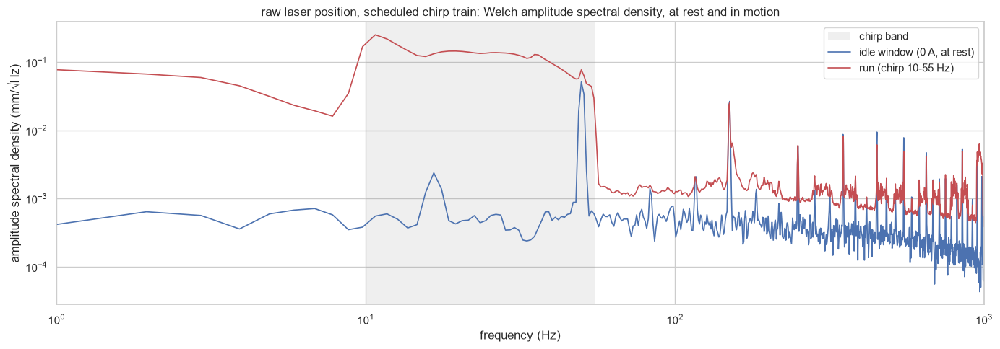

In [6]:
NPERSEG_C = 2048                                        # samples per Welch segment: 1.02 s at 2 kHz, 0.98 Hz resolution

df = RAW_DF["chirpsched", "train"]
FS_RAW = 1 / np.median(np.diff(df["time_s"].to_numpy()[1:]))   # Hz, logged rate (first row is a duplicate time stamp)
x_mm = df["position_mm"].to_numpy()
parts = {"idle window (0 A, at rest)": x_mm[df["time_s"].to_numpy() < 0],
         "run (chirp 10-55 Hz)": x_mm[df["time_s"].to_numpy() >= 0]}

fig, ax = plt.subplots(figsize=(14, 5))
ax.axvspan(10, 55, color="0.5", alpha=0.12, lw=0, label="chirp band")
for (label, x), color in zip(parts.items(), ("C0", "C3")):
    f, P = signal.welch(x, fs=FS_RAW, window="hann", nperseg=NPERSEG_C, noverlap=NPERSEG_C // 2, detrend="constant")
    ax.loglog(f[1:], np.sqrt(P[1:]), color=color, lw=1.2, label=label)
ax.set(xlabel="frequency (Hz)", ylabel="amplitude spectral density (mm/√Hz)", xlim=(1, FS_RAW / 2),
       title="raw laser position, scheduled chirp train: Welch amplitude spectral density, at rest and in motion")
ax.legend()
plt.tight_layout(); plt.show()

**Over time: spectrogram.** The same raw position over the whole log, idle window included, as a short-time Fourier transform (Hann window, `NPERSEG_S` samples, 75 % overlap), in dB of the amplitude spectral density. The frequency axis is logarithmic, so the exponential chirp is a straight line. Components that stay at one frequency (mains) are horizontal lines; anything that follows the chirp, or its multiples, rises with it.

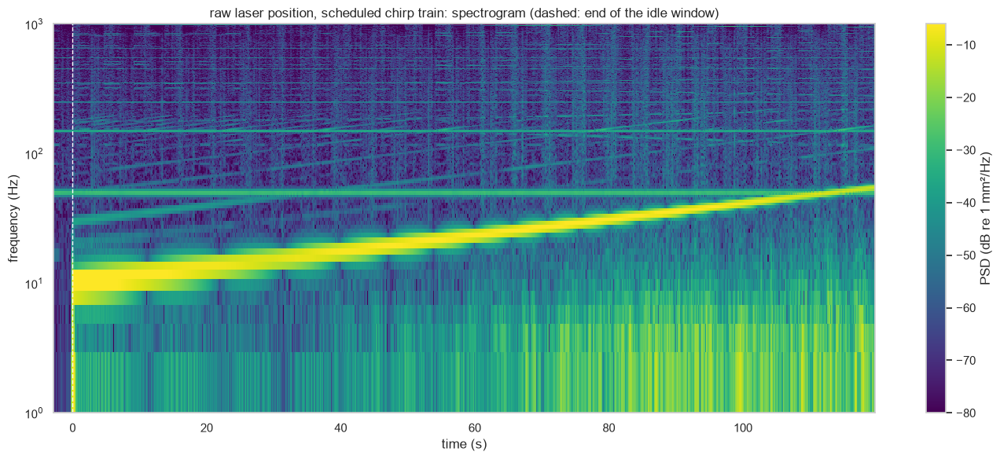

In [7]:
NPERSEG_S = 1024                                        # samples per spectrogram segment: 0.51 s at 2 kHz, 2 Hz resolution

t_log = df["time_s"].to_numpy()
f, tt, S = signal.spectrogram(x_mm, fs=FS_RAW, window="hann", nperseg=NPERSEG_S, noverlap=3 * NPERSEG_S // 4,
                              detrend="constant", scaling="density")
fig, ax = plt.subplots(figsize=(14, 6))
pc = ax.pcolormesh(tt + t_log[0], f[1:], 10 * np.log10(S[1:] + 1e-20), shading="auto", cmap="viridis",
                   vmin=10 * np.log10(1e-4 ** 2), vmax=10 * np.log10(0.5 ** 2))   # dB re 1 mm²/Hz: from about the idle floor up
ax.axvline(0.0, color="w", ls="--", lw=1)
ax.set(yscale="log", ylim=(1, FS_RAW / 2), xlabel="time (s)", ylabel="frequency (Hz)",
       title="raw laser position, scheduled chirp train: spectrogram (dashed: end of the idle window)")
fig.colorbar(pc, ax=ax, label="PSD (dB re 1 mm²/Hz)")
plt.tight_layout(); plt.show()

**Findings (position, scheduled chirp train).**

- **Over most of the band the motion dominates.** From 10 to about 45 Hz the position during the run is about 100 times the noise floor at rest.
- **At the top of the band the mains pickup is as large as the motion.** The 50 Hz line is there at rest, at about the same level as the motion near 50 Hz. It is the main contamination inside the application band.
- **The pickup is more than one line.** It has odd harmonics (150, 250, 350 Hz, ...) up to 1 kHz, all present at rest.
- **The motion has harmonics of its own.** A line at three times the chirp frequency, and fainter higher multiples, rise with the chirp. They are not pickup: they appear only in motion and follow the excitation.
- **There is slow motion below about 8 Hz that the chirp does not drive directly.** It grows in the second half of the run, as the amplitude ramps up, near the spring resonance. Its cause is open.
- **The broadband background rises during the run, in bursts.** Above the chirp band it is two to four times the floor at rest. Its cause is open.

**The 50 Hz pickup over time.** The pickup is not to be notched: a notch also removes the real motion near 50 Hz. Two alternatives remain:
- **remove it before fitting:** estimate the pickup over the run, bridge the stretch where the chirp is near 50 Hz, and subtract it;
- **model it:** add it to the measurement equation, as the firmware's Kalman filter does ([vca_ekf.c](vca_ekf.c)), and estimate its parameters together with the model:
$$y(t) = x(t) + p(t) + e(t), \qquad p(t) = A_p \cos\!\big(2\pi f_m t - \theta_p\big)$$

Which one fits depends on how steady the pickup is. If $A_p$, $f_m$ and $\theta_p$ are constant over a run, the model needs three parameters; if they wander, the pickup has to be tracked over time.

**Measurement.** In windows of `WIN_P` = 1 s, every `STEP_P` = 0.5 s, the raw position is fitted by least squares with
$$y(t) \approx \underbrace{a\cos 2\pi f_\text{ref} t + b\sin 2\pi f_\text{ref} t}_{\text{pickup}} + \underbrace{\sum_{n=1}^{N} \big(c_n \cos n\varphi(t) + d_n \sin n\varphi(t)\big)}_{\text{chirp motion and its harmonics}} + \underbrace{\sum_{j=0}^{3} e_j\,(t - \bar t)^j}_{\text{slow motion}}$$
with $f_\text{ref}$ = 50 Hz and $\varphi(t)$ the known phase of the sent chirp (the motion follows it with a phase and gain that are nearly constant within 1 s). The pickup amplitude and phase in the window are $A = \sqrt{a^2 + b^2}$ and $\theta = \operatorname{atan2}(b, a)$. A mains frequency $f_m \neq f_\text{ref}$ shows up as a phase that drifts linearly, $\theta(t) = \theta_0 + 2\pi (f_m - f_\text{ref})\, t$.

The harmonics go up to `F_HARM_MAX` = 100 Hz, $N = \lfloor 100\,\text{Hz}/f \rfloor$: at low chirp frequencies and large strokes the motion has many, and any of them near 50 Hz would otherwise leak into the pickup. Windows where the chirp is within `GAP_P` = 2 Hz of 50 Hz, or a harmonic within `GAP_H` = 1 Hz (about the resolution of a 1 s window), are left out: there the pickup and the motion cannot be told apart. Windows that cross $t = 0$ are left out too.

Shown: the pickup amplitude, and its phase after removing the best constant-frequency line, against time, with the sent current amplitude for reference. Printed: the amplitude at rest and in the run, the best constant mains frequency, and how far a pickup with constant $A_p$, $f_m$, $\theta_p$ would be off.

pickup amplitude: at rest 89.0 µm, in the run 93.7 µm (range 81.6-101.3 µm)
best constant mains frequency: 50.0114 Hz; phase about that line: rms 50.1°, max 146.3°
a pickup with constant amplitude, frequency and phase is off by 74.4 µm rms (max 178.7 µm), against a pickup of 93.2 µm


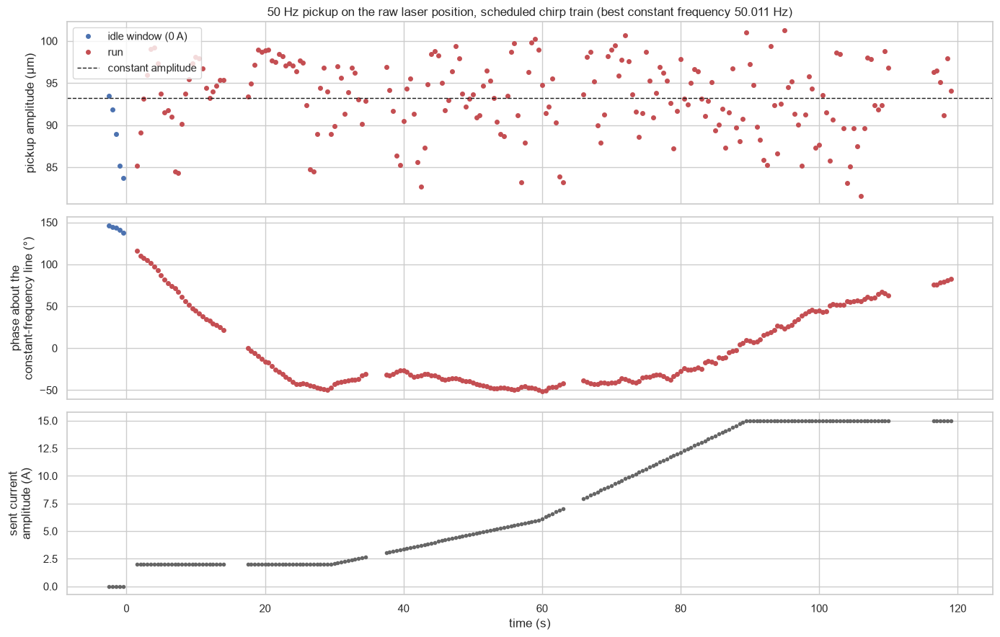

In [8]:
WIN_P, STEP_P = 1.0, 0.5                                # s, window length and step of the pickup fit
GAP_P = 2.0                                             # Hz, windows left out where the chirp or a harmonic is this close to 50 Hz
F_REF = 50.0                                            # Hz, demodulation frequency of the pickup
F_HARM_MAX = 100.0                                      # Hz, chirp harmonics up to this frequency are fitted alongside
GAP_H = 1.0                                             # Hz, windows left out where a harmonic (n >= 2) is this close to 50 Hz

path = RAW_LOGS["chirpsched", "train"]


def chirp_phase_fn(path):
    "Phase of the sent chirp as a function of time, from f0, f1 and T in the file name (firmware 829db32 / 985ce63)."
    f0_c, f1_c, T_c = map(float, re.search(r"_([\d.]+)to([\d.]+)Hz_([\d.]+)s_", path.name).groups())
    L_c = T_c / np.log(f1_c / f0_c)
    return lambda t: 2 * np.pi * f0_c * L_c * (np.exp(t / L_c) - 1.0)


def pickup_windows(t_log, x_log, path):
    "Pickup amplitude and unwrapped phase per WIN_P window (window centres tc), with the run's chirp, its harmonics up to F_HARM_MAX and the slow motion fitted alongside."
    is_chirp = "chirp" in path.name                    # a PRBS has no chirp: then only the 50 Hz term and the cubic
    i_fn, f_fn = sent_current_fn(path) if is_chirp else (prbs_current_fn(path), None)
    chirp_phase = chirp_phase_fn(path) if is_chirp else None
    rows = []
    for t0 in np.arange(t_log[0], t_log[-1] - WIN_P, STEP_P):
        if t0 < 0 < t0 + WIN_P:
            continue                                    # window crosses the start of the run
        m = (t_log >= t0) & (t_log < t0 + WIN_P)
        tm, tc = t_log[m], t_log[m].mean()
        cols = [np.cos(2 * np.pi * F_REF * tm), np.sin(2 * np.pi * F_REF * tm)]
        if tc >= 0 and is_chirp:
            fc = f_fn(tc)
            ns = np.arange(1, max(3, int(F_HARM_MAX // fc)) + 1)    # harmonics of the chirp up to F_HARM_MAX
            if abs(fc - F_REF) < GAP_P or np.any(np.abs(ns[1:] * fc - F_REF) < GAP_H):
                continue                                # chirp or a harmonic too close to 50 Hz: not separable
            ph = chirp_phase(tm)
            for n in ns:
                cols += [np.cos(n * ph), np.sin(n * ph)]
        cols += [(tm - tc) ** j for j in range(4)]
        q = np.linalg.lstsq(np.column_stack(cols), x_log[m], rcond=None)[0]
        rows.append((tc, np.hypot(q[0], q[1]), np.arctan2(q[1], q[0]), np.max(np.abs(i_fn(tm)))))
    tc, A, th, i_amp = np.array(rows).T
    return tc, A, np.unwrap(th), i_amp


t_log, x_log = df["time_s"].to_numpy(), df["position_mm"].to_numpy()
tc, A, th, i_amp = pickup_windows(t_log, x_log, path)

# best constant pickup: constant amplitude, phase linear in time (constant mains frequency)
slope, th0 = np.polyfit(tc, th, 1)
f_m = F_REF + slope / (2 * np.pi)
th_res = th - (th0 + slope * tc)
A_const = np.mean(A)
err = np.abs(A * np.exp(1j * th) - A_const * np.exp(1j * (th0 + slope * tc)))   # mm, distance between measured and constant pickup
idle, inrun = tc < 0, tc >= 0
print(f"pickup amplitude: at rest {np.median(A[idle]) * 1e3:.1f} µm, in the run {np.median(A[inrun]) * 1e3:.1f} µm "
      f"(range {A[inrun].min() * 1e3:.1f}-{A[inrun].max() * 1e3:.1f} µm)")
print(f"best constant mains frequency: {f_m:.4f} Hz; phase about that line: rms {np.degrees(np.std(th_res)):.1f}°, "
      f"max {np.degrees(np.abs(th_res).max()):.1f}°")
print(f"a pickup with constant amplitude, frequency and phase is off by {np.sqrt(np.mean(err ** 2)) * 1e3:.1f} µm rms "
      f"(max {err.max() * 1e3:.1f} µm), against a pickup of {A_const * 1e3:.1f} µm")

fig, ax = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for a_, y_, lab in [(ax[0], A * 1e3, "pickup amplitude (µm)"), (ax[1], np.degrees(th_res), "phase about the\nconstant-frequency line (°)")]:
    a_.plot(tc[idle], y_[idle], "o", ms=4, color="C0", label="idle window (0 A)")
    a_.plot(tc[inrun], y_[inrun], "o", ms=4, color="C3", label="run")
    a_.set_ylabel(lab)
ax[0].axhline(A_const * 1e3, color="k", ls="--", lw=1, label="constant amplitude")
ax[0].legend(loc="upper left")
ax[2].plot(tc, i_amp, "o", ms=3, color="0.4")
ax[2].set(ylabel="sent current\namplitude (A)", xlabel="time (s)")
ax[0].set_title(f"50 Hz pickup on the raw laser position, scheduled chirp train (best constant frequency {f_m:.3f} Hz)")
plt.tight_layout(); plt.show()

**Removing the pickup.** The pickup has a steady amplitude and a phase that drifts slowly and smoothly (the mains frequency wanders by a few hundredths of a hertz). So it is described by one amplitude and a smooth phase:

$$p(t) = A_p \cos\!\big(2\pi f_\text{ref}\, t - \theta_p(t)\big)$$

- $A_p$: the mean of the window amplitudes above.
- $\theta_p(t)$: a cubic least-squares spline through the window phases, with a knot every `KNOT_P` = 10 s. It bridges the windows left out where the chirp is near 50 Hz.

The cleaned position is the raw position minus the pickup, at every logged sample: $y_\text{clean}(t) = y(t) - p(t)$.

**Check.**
1. The window phases with the spline through them.
2. The same window fit repeated on $y_\text{clean}$: what is left at 50 Hz, at rest and in the run.
3. The spectrum near 50 Hz (Welch, as above, `NPERSEG_C` samples), before and after, at rest and in the run. At rest the 50 Hz line should drop to the noise floor; in the run the motion around 50 Hz should stay.

Only the 50 Hz line is removed; its harmonics (150 Hz and up) lie outside the chirp band and are left for now.

50 Hz left at rest: median 4.8 µm, max 10.5 µm (before: median 89.0 µm)
50 Hz left in the run: median 5.1 µm, max 12.1 µm (before: median 93.7 µm)
phase spline: rms misfit 2.1° (pickup amplitude 93.2 µm)


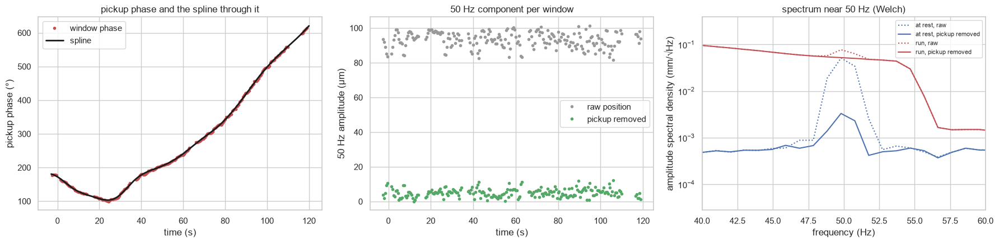

In [9]:
from scipy.interpolate import make_lsq_spline

KNOT_P = 10.0                                           # s, knot spacing of the phase spline



def fit_pickup(tc, A, th):
    "Pickup model from the window estimates: constant amplitude, cubic spline phase with a knot every KNOT_P s. Returns p(t) and the phase spline."
    knots_in = np.arange(tc.min() + KNOT_P, tc.max() - KNOT_P / 2, KNOT_P)
    th_spline = make_lsq_spline(tc, th, np.r_[[tc.min()] * 4, knots_in, [tc.max()] * 4], k=3)
    A_p = np.mean(A)
    return (lambda t: A_p * np.cos(2 * np.pi * F_REF * t - th_spline(t, extrapolate=True))), th_spline


pickup, th_spline = fit_pickup(tc, A, th)
A_p = np.mean(A)                                        # mm, pickup amplitude (constant)
x_clean = x_log - pickup(t_log)                         # mm, raw position with the 50 Hz pickup removed

tc2, A2, _, _ = pickup_windows(t_log, x_clean, path)
for lab, m_ in (("at rest", tc2 < 0), ("in the run", tc2 >= 0)):
    print(f"50 Hz left {lab}: median {np.median(A2[m_]) * 1e3:.1f} µm, max {A2[m_].max() * 1e3:.1f} µm "
          f"(before: median {np.median(A[(tc < 0) if lab == 'at rest' else (tc >= 0)]) * 1e3:.1f} µm)")
print(f"phase spline: rms misfit {np.degrees(np.std(th - th_spline(tc))):.1f}° (pickup amplitude {A_p * 1e3:.1f} µm)")

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
tg = np.linspace(t_log[0], t_log[-1], 1000)
ax[0].plot(tc, np.degrees(th), "o", ms=3, color="C3", label="window phase")
ax[0].plot(tg, np.degrees(th_spline(tg, extrapolate=True)), color="k", lw=2, label="spline")
ax[0].set(xlabel="time (s)", ylabel="pickup phase (°)", title="pickup phase and the spline through it")
ax[0].legend()
ax[1].plot(tc, A * 1e3, "o", ms=3, color="0.6", label="raw position")
ax[1].plot(tc2, A2 * 1e3, "o", ms=3, color="C2", label="pickup removed")
ax[1].set(xlabel="time (s)", ylabel="50 Hz amplitude (µm)", title="50 Hz component per window")
ax[1].legend()
t_rest = t_log < 0
for (lab, m_), color in zip((("at rest", t_rest), ("run", ~t_rest)), ("C0", "C3")):
    for x_, ls, tag in ((x_log, ":", "raw"), (x_clean, "-", "pickup removed")):
        f, Pxx = signal.welch(x_[m_], fs=FS_RAW, window="hann", nperseg=NPERSEG_C, noverlap=NPERSEG_C // 2, detrend="constant")
        ax[2].semilogy(f, np.sqrt(Pxx), ls, color=color, lw=1.5, label=f"{lab}, {tag}")
ax[2].set(xlim=(40, 60), xlabel="frequency (Hz)", ylabel="amplitude spectral density (mm/√Hz)", title="spectrum near 50 Hz (Welch)")
ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Findings (50 Hz pickup, scheduled chirp train).**

- **The pickup has a steady size.** About 93 µm throughout, at rest and in the run, independent of the current.
- **Its frequency drifts, slowly and smoothly.** The mains frequency wanders by a few hundredths of a hertz, which turns the phase by about 200° over the run. A pickup with one fixed frequency is off by almost its own size.
- **A constant amplitude with a smooth phase describes it.** The spline follows the phase within 2°, also across the stretches where the chirp is near 50 Hz.
- **Subtracting it removes about 95 % and keeps the motion.** The 50 Hz component drops from about 93 to about 5 µm, and the spectrum of the run passes smoothly through 50 Hz, where a notch would cut out real motion.
- **The remaining 5 µm is small and accepted.** It is likely the slightly smaller pickup at rest; next to the motion near 50 Hz (about 0.6 mm) it does not matter.
- **Decision: the pickup is removed by subtracting this fitted $p(t)$, not by a notch.** Its harmonics (150 Hz and up) lie outside the chirp band and are left for now.

**The pickup on all runs.** The same steps (window estimates, constant amplitude, phase spline, subtraction) on the four runs. Each window fit models the run's own chirp with all its harmonics up to 100 Hz, and the slow motion with a cubic. With only the fundamental and the 3rd harmonic, the windows of the plain chirps before about 62 s (below about 8 Hz, strokes up to ±20 mm) scattered widely (20° rms phase, up to 190 µm left): there the motion has many harmonics, and those near 50 Hz leaked into the pickup estimate.

Shown per run against time: the pickup amplitude per window; the window phase about the run's own spline; and the 50 Hz left per window after the subtraction.

scheduled train: 2 A, ramp to 6 A from 15 Hz     pickup 89 µm at rest, 94 µm in the run; phase about the spline rms 2.1°; 50 Hz left: median 5.1 µm, max 12.1 µm


scheduled test: 3 A, ramp to 7 A from 15 Hz      pickup 92 µm at rest, 93 µm in the run; phase about the spline rms 2.5°; 50 Hz left: median 4.0 µm, max 11.5 µm


plain train: 6.5 A                               pickup 93 µm at rest, 94 µm in the run; phase about the spline rms 4.1°; 50 Hz left: median 5.3 µm, max 39.7 µm


plain test: 6.0 A                                pickup 92 µm at rest, 92 µm in the run; phase about the spline rms 3.2°; 50 Hz left: median 5.1 µm, max 35.4 µm


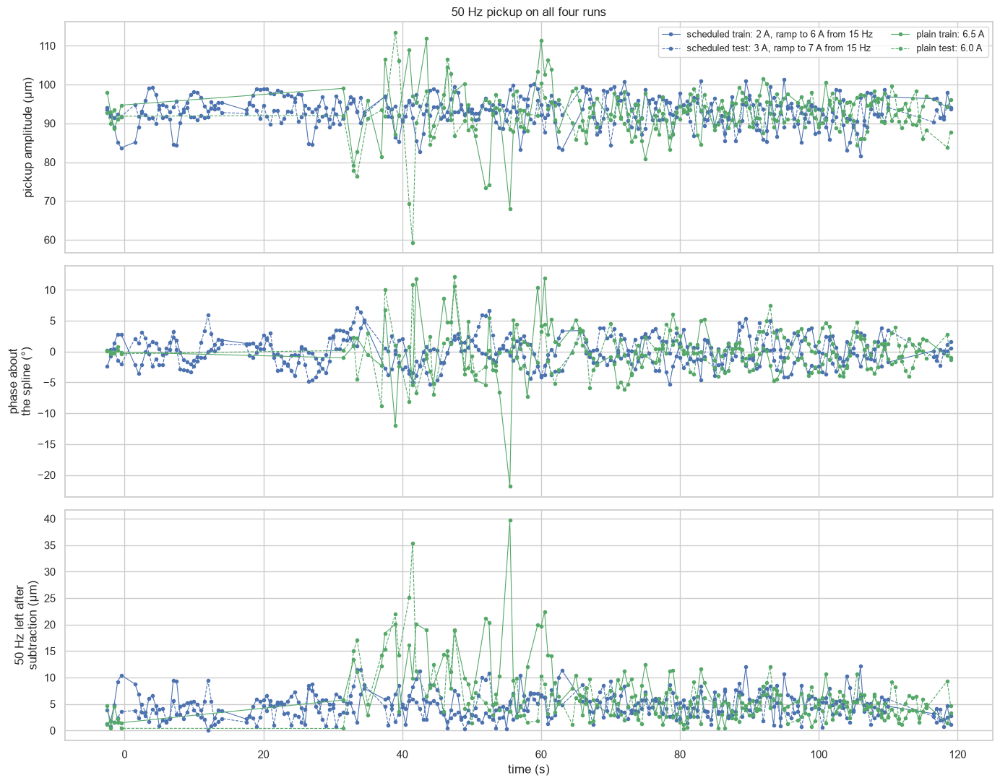

In [10]:
fig, ax = plt.subplots(3, 1, figsize=(14, 11), sharex=True)
for key, label, color, ls in RUNS_AMP:
    d_ = RAW_DF[key]
    t_, x_ = d_["time_s"].to_numpy(), d_["position_mm"].to_numpy()
    tc_, A_, th_, _ = pickup_windows(t_, x_, RAW_LOGS[key])
    p_fn, sp_ = fit_pickup(tc_, A_, th_)
    tc2_, A2_, _, _ = pickup_windows(t_, x_ - p_fn(t_), RAW_LOGS[key])
    res_ = np.degrees(th_ - sp_(tc_))
    print(f"{label:48s} pickup {np.median(A_[tc_ < 0]) * 1e3:.0f} µm at rest, {np.median(A_[tc_ >= 0]) * 1e3:.0f} µm in the run; "
          f"phase about the spline rms {np.std(res_):.1f}°; 50 Hz left: median {np.median(A2_) * 1e3:.1f} µm, max {A2_.max() * 1e3:.1f} µm")
    for a_, y_ in ((ax[0], A_ * 1e3), (ax[1], res_), (ax[2], A2_ * 1e3)):
        a_.plot(tc_ if a_ is not ax[2] else tc2_, y_, "o" + ls, ms=3, lw=0.8, color=color, label=label)
ax[0].set(ylabel="pickup amplitude (µm)", title="50 Hz pickup on all four runs")
ax[1].set(ylabel="phase about\nthe spline (°)")
ax[2].set(ylabel="50 Hz left after\nsubtraction (µm)", xlabel="time (s)")
ax[0].legend(fontsize=9, ncol=2)
plt.tight_layout(); plt.show()

**Findings (pickup on all runs).**

- **The pickup removal carries over to all four runs.** The phase stays within 2–4° of its spline and about 5 µm of the 93 µm pickup is left, for the scheduled and the plain chirps alike.
- **Large strokes need all harmonics of the motion in the window fit.** With only the fundamental and the 3rd harmonic, the plain chirps' early windows scattered by 20° and up to 190 µm: harmonics near 50 Hz leaked into the pickup estimate. With all harmonics up to 100 Hz that is gone.
- **Some scatter remains at 3–8 Hz in the plain chirps** (up to about 40 µm at a few windows), far below the motion there (up to ±20 mm).
- **Below about 3 Hz the pickup is not measured, only bridged.** The harmonics lie too close to 50 Hz to separate, so the spline bridges the plain chirps from the idle window to about 32 s. A known limit: negligible for the position, possibly not for a velocity taken there.

### 3. Sample rate: at what rate should we work?

The log has a row every 0.5 ms; the chirp reaches 55 Hz.

- What rate do the signals really carry (see the update rate in 1)?
- What rate does the model need, to represent 10–55 Hz and its timing accurately?

**Stale rows and the broadband background.** About half of the rows repeat the previous row's value: the drive did not deliver a new sample in that cycle (section 1). When the mass moves, a repeated value is off by the motion over one cycle, roughly $\dot{x}\,T_s$ with $T_s$ = 0.5 ms. Because the repeats come irregularly, that error spreads over all frequencies. At rest it vanishes, since the repeated value equals the new one.

If this is the cause of the bursts in the broadband background (section 2), their level follows from the stale rows and the motion alone. Test, on the scheduled chirp (train):

1. **Stale rows:** rows where `position_mm` equals the previous row.
2. **Predicted error:** a smooth position $\tilde{x}$ (raw position, 100 Hz zero-phase low-pass) stands in for the true motion. At every stale row $k$ the error is its step over one row, $\hat{e}_k = -(\tilde{x}_k - \tilde{x}_{k-1})$, else 0.
3. **Broadband level:** the raw position and $\hat{e}$ are both high-passed at `F_HP` = 400 Hz (above the chirp harmonics that are visible in the spectrogram), and their rms is taken per `WIN_B` = 1 s window.
4. **Compare:** the measured level against $\sqrt{\sigma_0^2 + \hat{\sigma}_e^2}$, with $\sigma_0$ the level at rest (idle window) and $\hat{\sigma}_e$ the predicted stale-row level. If the stale rows explain the bursts, the two follow each other.

Shown: the two levels against time, and the fraction of stale rows per window.

broadband level (> 400 Hz): at rest 18.65 µm, in the run median 35.10 µm, max 62.60 µm
predicted from the stale rows (with the level at rest): median 34.57 µm; correlation with the measured level in the run: 0.98


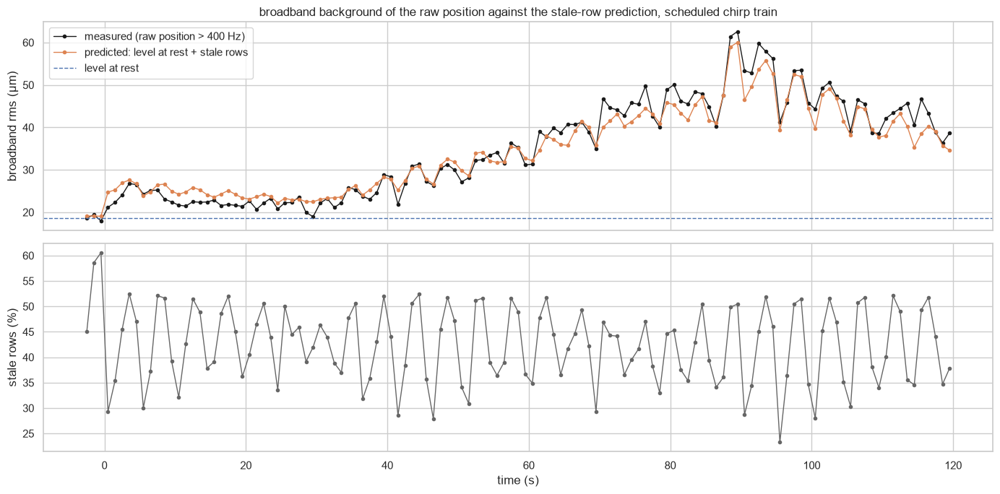

In [11]:
F_HP = 400.0                                            # Hz, high-pass for the broadband level (above the chirp harmonics)
WIN_B = 1.0                                             # s, window for the rms

df = RAW_DF["chirpsched", "train"]
t_log, x_raw = df["time_s"].to_numpy(), df["position_mm"].to_numpy()
stale = np.r_[False, np.diff(x_raw) == 0]               # row repeats the previous row
b_s, a_s = signal.butter(4, 100.0 / (FS_RAW / 2))       # smooth stand-in for the true motion
x_smooth = signal.filtfilt(b_s, a_s, x_raw)
e_hat = np.where(stale, -np.r_[0.0, np.diff(x_smooth)], 0.0)   # mm, predicted error of the stale rows

b_h, a_h = signal.butter(4, F_HP / (FS_RAW / 2), btype="high")
hp = lambda s: signal.filtfilt(b_h, a_h, s)
x_hp, e_hp = hp(x_raw), hp(e_hat)

edges = np.arange(t_log[0], t_log[-1], WIN_B)
tw, meas, pred, frac = [], [], [], []
for t0 in edges:
    m = (t_log >= t0) & (t_log < t0 + WIN_B)
    if t0 < 0 < t0 + WIN_B:
        continue                                        # window crosses the start of the run
    tw.append(t0 + WIN_B / 2)
    meas.append(np.sqrt(np.mean(x_hp[m] ** 2)))
    pred.append(np.sqrt(np.mean(e_hp[m] ** 2)))
    frac.append(stale[m].mean())
tw, meas, pred, frac = map(np.array, (tw, meas, pred, frac))
sig0 = np.median(meas[tw < 0])                          # broadband level at rest
pred_tot = np.sqrt(sig0 ** 2 + pred ** 2)
run_w = tw >= 0
print(f"broadband level (> {F_HP:.0f} Hz): at rest {sig0 * 1e3:.2f} µm, in the run median {np.median(meas[run_w]) * 1e3:.2f} µm, "
      f"max {meas[run_w].max() * 1e3:.2f} µm")
print(f"predicted from the stale rows (with the level at rest): median {np.median(pred_tot[run_w]) * 1e3:.2f} µm; "
      f"correlation with the measured level in the run: {np.corrcoef(meas[run_w], pred_tot[run_w])[0, 1]:.2f}")

fig, ax = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
ax[0].plot(tw, meas * 1e3, "o-", ms=3, lw=1, color="k", label=f"measured (raw position > {F_HP:.0f} Hz)")
ax[0].plot(tw, pred_tot * 1e3, "o-", ms=3, lw=1, color="C1", label="predicted: level at rest + stale rows")
ax[0].axhline(sig0 * 1e3, color="C0", ls="--", lw=1, label="level at rest")
ax[0].set(ylabel="broadband rms (µm)", title="broadband background of the raw position against the stale-row prediction, scheduled chirp train")
ax[0].legend(loc="upper left")
ax[1].plot(tw, frac * 100, "o-", ms=3, lw=1, color="0.4")
ax[1].set(ylabel="stale rows (%)", xlabel="time (s)")
plt.tight_layout(); plt.show()

**Findings (stale rows, scheduled chirp train).**

- **The stale rows explain the broadband background.** The prediction from the stale rows and the motion follows the measured level window by window (correlation 0.98); the bursts and the growth with the amplitude are both reproduced.
- **The drive delivers a new position in only 50–70 % of the rows.** The signals carry roughly 1.0–1.4 kHz of real samples, unevenly spaced, not 2 kHz.
- **The fraction of stale rows swings with a period of about 5 s.** That fits a beat between the master's and the drive's clocks, which are not synchronised: not only the number but also the spacing of the real samples varies.
- **At rest the count overstates the stale rows.** The position is quantised in steps of about 8 µm, so two real readings can also be equal.

**How much of the stale-row error lies in the chirp band?** Low-pass filtering removes the stale-row error above the band, but not the part inside it. At a stale row the error is minus the motion's step over one row, so part of it moves with the velocity and acts like a small extra delay. The predicted error $\hat{e}$ (above) and the velocity $\dot{\tilde{x}}$ of the smooth position are band-passed to 10–55 Hz (4th-order Butterworth, zero-phase), and split by least squares into

$$\hat{e}_\text{band} = -\tau_\text{eq}\,\dot{\tilde{x}}_\text{band} + r$$

- $\tau_\text{eq}$: the equivalent delay, which acts like a timing error;
- $r$: the rest, which acts like noise in the band, compared with the motion in the same band (the position with the pickup removed, band-passed the same way).

Shown: the spectra (Welch, as above) of the run position, of the predicted stale-row error $\hat{e}$, and of its noise-like part after the delay-like part is removed, $\hat{e} + \tau_\text{eq}\dot{\tilde{x}}$.

equivalent delay of the stale rows: 0.204 ms
in 10-55 Hz: motion 776 µm rms, stale-row error 27.7 µm rms, of which noise-like 6.9 µm rms (0.89 % of the motion)


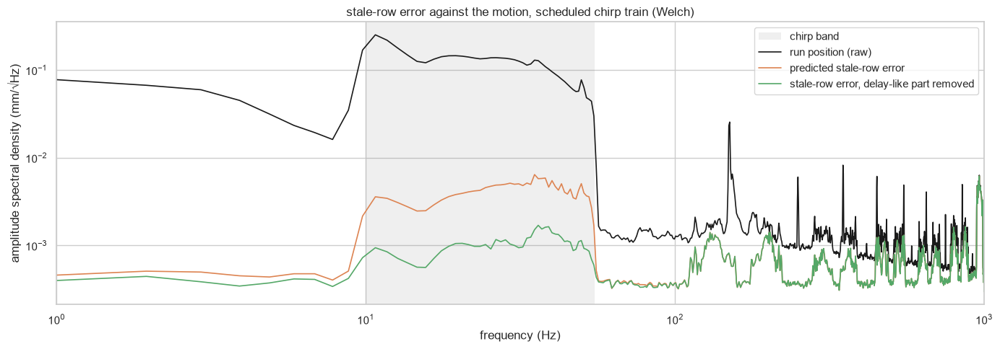

In [12]:
b_b, a_b = signal.butter(4, [10.0 / (FS_RAW / 2), 55.0 / (FS_RAW / 2)], btype="band")
bp = lambda s: signal.filtfilt(b_b, a_b, s)
run_r = t_log >= 0
v_smooth = np.gradient(x_smooth, 1 / FS_RAW)            # mm/s, velocity of the smooth position (uniform 0.5 ms rows; the time stamps repeat once at the start)
e_b, v_b, x_b = bp(e_hat)[run_r], bp(v_smooth)[run_r], bp(x_clean)[run_r]
tau_eq = -(e_b @ v_b) / (v_b @ v_b)                     # s, equivalent delay of the stale rows
r_b = e_b + tau_eq * v_b                                # noise-like part in the band
rms = lambda s: np.sqrt(np.mean(s ** 2))
print(f"equivalent delay of the stale rows: {tau_eq * 1e3:.3f} ms")
print(f"in 10-55 Hz: motion {rms(x_b) * 1e3:.0f} µm rms, stale-row error {rms(e_b) * 1e3:.1f} µm rms, "
      f"of which noise-like {rms(r_b) * 1e3:.1f} µm rms ({rms(r_b) / rms(x_b) * 100:.2f} % of the motion)")

fig, ax = plt.subplots(figsize=(14, 5))
ax.axvspan(10, 55, color="0.5", alpha=0.12, lw=0, label="chirp band")
e_noise = e_hat + tau_eq * v_smooth                     # stale-row error without its delay-like part
for s_, lab, color in ((x_raw[run_r], "run position (raw)", "k"), (e_hat[run_r], "predicted stale-row error", "C1"),
                       (e_noise[run_r], "stale-row error, delay-like part removed", "C2")):
    f, Pxx = signal.welch(s_, fs=FS_RAW, window="hann", nperseg=NPERSEG_C, noverlap=NPERSEG_C // 2, detrend="constant")
    ax.loglog(f[1:], np.sqrt(Pxx[1:]), color=color, lw=1.2, label=lab)
ax.set(xlim=(1, FS_RAW / 2), xlabel="frequency (Hz)", ylabel="amplitude spectral density (mm/√Hz)",
       title="stale-row error against the motion, scheduled chirp train (Welch)")
ax.legend()
plt.tight_layout(); plt.show()

**Findings (stale rows in the chirp band).**

- **Inside the band the stale rows act almost entirely as a delay.** Their error is about 4 % of the motion, and nearly all of it moves with the velocity: an equivalent delay of 0.2 ms. That matches the average age of a stale value: about 41 % of the rows, each half a cycle old.
- **The noise they add inside the band is negligible.** Under 1 % of the motion.
- **Above the band they are the whole broadband floor.** A low-pass above the band removes them.
- **The beat between the clocks barely matters.** As the stale fraction swings, the equivalent delay moves by about ±0.05 ms, about 1° at 50 Hz.
- **Decision: keep all rows.** The 0.2 ms is absorbed by the drive delay $\tau_d$; the error above the band is removed by a low-pass. Dropping the stale rows would leave unevenly spaced samples and gain almost nothing.

**Which low-pass for velocity and acceleration?** The fit target, the position, needs almost no filtering (output error, section 4). Velocity and acceleration do: differentiating multiplies noise by $2\pi f$ and $(2\pi f)^2$. A low-pass with cutoff $f_c$ trades the noise it lets through against the motion it cuts away.

**Motion and noise, split directly.** Subtracting a noise spectrum from the run spectrum is too crude above the band: small errors in the noise estimate show up as motion that is not there. Instead, the run is cut into windows of `WIN_M` = 1 s, and in each the position (50 Hz pickup removed) is fitted by least squares with

$$x(t) \approx \sum_{n=1}^{N} \big(c_n \cos n\varphi(t) + d_n \sin n\varphi(t)\big) + \sum_{j=0}^{3} e_j\,(t - \bar t)^j + r(t), \qquad N = \lfloor 300\,\text{Hz} / f \rfloor$$

- **motion:** the chirp and its harmonics up to `F_MOTION_MAX` = 300 Hz, locked to the known chirp phase $\varphi$, with amplitudes $A_n = \sqrt{c_n^2 + d_n^2}$ at the frequencies $n f$; plus the slow motion (the cubic, which a low-pass above 60 Hz does not touch);
- **noise:** the residual $r$, its PSD averaged over the windows (Hann, one periodogram per window).
- a fitted sinusoid also picks up the noise at its frequency, about $S_r(nf)/T_w$ in power for a window of length $T_w$; that share is subtracted from each $	frac12 A_n^2$.

The error of the derivative of order $p$ ($p$ = 1 velocity, 2 acceleration) for a cutoff $f_c$:

$$\sigma^2(f_c) \approx \int H_{f_c}(f)^2\,(2\pi f)^{2p}\, S_r(f)\,df \;+\; \Big\langle \sum_n \big(1 - H_{f_c}(nf)\big)^2\,(2\pi n f)^{2p}\,\tfrac12 A_n^2 \Big\rangle_\text{windows}$$

with $H_{f_c}(f) = 1/\big(1 + (f/f_c)^8\big)$, a 4th-order Butterworth applied forwards and backwards (zero phase). The errors are given relative to the rms velocity and acceleration of the chirp motion.

The dashed curves add a 150 Hz term to each window fit, so the 150 Hz pickup line is counted as removed (left out in windows where a harmonic is within `GAP_H` of 150 Hz).

velocity    : best cutoff 115 Hz, error 11.64 %; with the 150 Hz line removed: best 165 Hz, error 9.80 %; at 100 Hz: 11.76 %


acceleration: best cutoff 120 Hz, error 48.30 %; with the 150 Hz line removed: best 165 Hz, error 40.07 %; at 100 Hz: 49.03 %


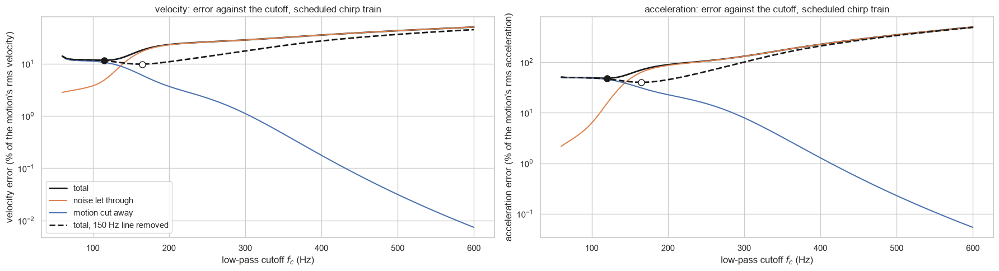

rms harmonic amplitude (um): n=1: 1175.1, n=2: 5.8, n=3: 18.8, n=4: 4.8, n=5: 12.5, n=6: 3.6, n=7: 7.5, n=8: 3.0, n=9: 6.9, n=10: 3.9, n=11: 4.8


In [13]:
WIN_M = 1.0                                             # s, window of the motion/noise split
F_MOTION_MAX = 300.0                                    # Hz, chirp harmonics up to this frequency count as motion
FC_GRID = np.arange(60.0, 600.0 + 1e-9, 5.0)           # Hz, cutoffs tried

path_m = RAW_LOGS["chirpsched", "train"]
_, f_fn_m = sent_current_fn(path_m)
phase_m = chirp_phase_fn(path_m)
run_m = t_log >= 0
t_m, x_m = t_log[run_m], x_clean[run_m] * 1e-3          # m, run part, 50 Hz pickup removed

harm, S_r, S_r150 = [], [], []                          # per window: (n f, A_n); residual periodograms
for t0 in np.arange(0.0, t_m[-1] - WIN_M, WIN_M):
    m = (t_m >= t0) & (t_m < t0 + WIN_M)
    tm, tc_ = t_m[m], t_m[m].mean()
    fc_ = f_fn_m(tc_)
    ns = np.arange(1, int(F_MOTION_MAX // fc_) + 1)
    ph = phase_m(tm)
    base = [f(n * ph) for n in ns for f in (np.cos, np.sin)] + [(tm - tc_) ** j for j in range(4)]
    for extra, store in (([], S_r), ([np.cos(2 * np.pi * 150.0 * tm), np.sin(2 * np.pi * 150.0 * tm)], S_r150)):
        if extra and np.any(np.abs(ns * fc_ - 150.0) < GAP_H):
            extra = []                                  # a harmonic too close to 150 Hz: keep the line in the residual
        X = np.column_stack(base + extra)
        q = np.linalg.lstsq(X, x_m[m], rcond=None)[0]
        f_w, P_w = signal.periodogram(x_m[m] - X @ q, fs=FS_RAW, window="hann", detrend=False)
        store.append(P_w)
        if not extra and store is S_r:
            harm.append((ns * fc_, np.hypot(q[0:2 * len(ns):2], q[1:2 * len(ns):2])))
S_r, S_r150 = np.mean(S_r, axis=0), np.mean(S_r150, axis=0)
df_w, w_w = f_w[1] - f_w[0], 2 * np.pi * f_w
# a fitted sinusoid also picks up the noise at its frequency (about S_r / WIN_M in power): remove that share
harm = [(fn, np.sqrt(2 * np.clip(An ** 2 / 2 - np.interp(fn, f_w, S_r) / WIN_M, 0.0, None))) for fn, An in harm]


def err_curve(S_n, p, order=4):
    "rms error of the p-th derivative against the cutoff (zero-phase Butterworth of this order): noise let through, motion cut away, total."
    noise = np.array([np.sum((1 / (1 + (f_w / fc) ** (2 * order))) ** 2 * w_w ** (2 * p) * S_n) * df_w for fc in FC_GRID])
    cut = np.array([np.mean([np.sum((1 - 1 / (1 + (fn / fc) ** (2 * order))) ** 2 * (2 * np.pi * fn) ** (2 * p) * An ** 2 / 2)
                             for fn, An in harm]) for fc in FC_GRID])
    return np.sqrt(noise), np.sqrt(cut), np.sqrt(noise + cut)


fig, ax = plt.subplots(1, 2, figsize=(18, 5))
for a_, p, name in ((ax[0], 1, "velocity"), (ax[1], 2, "acceleration")):
    ref = np.sqrt(np.mean([np.sum((2 * np.pi * fn) ** (2 * p) * An ** 2 / 2) for fn, An in harm]))
    n_, c_, tot = err_curve(S_r, p)
    _, _, tot2 = err_curve(S_r150, p)
    for y_, style, lab in ((tot, "k-", "total"), (n_, "C1-", "noise let through"), (c_, "C0-", "motion cut away"),
                           (tot2, "k--", "total, 150 Hz line removed")):
        a_.semilogy(FC_GRID, y_ / ref * 100, style, lw=2 if lab.startswith("total") else 1.5, label=lab)
    j, j2 = np.argmin(tot), np.argmin(tot2)
    a_.plot(FC_GRID[j], tot[j] / ref * 100, "o", color="k", ms=8)
    a_.plot(FC_GRID[j2], tot2[j2] / ref * 100, "o", color="k", ms=8, mfc="w")
    a_.set(xlabel="low-pass cutoff $f_c$ (Hz)", ylabel=f"{name} error (% of the motion's rms {name})",
           title=f"{name}: error against the cutoff, scheduled chirp train")
    print(f"{name:12s}: best cutoff {FC_GRID[j]:.0f} Hz, error {tot[j] / ref * 100:.2f} %; "
          f"with the 150 Hz line removed: best {FC_GRID[j2]:.0f} Hz, error {tot2[j2] / ref * 100:.2f} %; "
          f"at 100 Hz: {tot[np.argmin(abs(FC_GRID - 100))] / ref * 100:.2f} %")
ax[0].legend()
plt.tight_layout(); plt.show()

# how large are the harmonics? rms amplitude of each order over the run (noise share removed)
orders = {n: np.sqrt(np.mean([An[n - 1] ** 2 for fn, An in harm if len(An) >= n])) for n in range(1, 12)}
print("rms harmonic amplitude (um): " + ", ".join(f"n={n}: {orders[n] * 1e6:.1f}" for n in orders))


**Are the harmonics real motion?** The laser shows odd harmonics of the chirp that fall off slowly, roughly as $1/n$. Weighted by $(2\pi n f)$ for velocity and $(2\pi n f)^2$ for acceleration, they decide the cutoff. A $1/n$ series of odd harmonics in position is the signature of a square-wave-like shape, which for a 51.5 kg mass would need forces as large as the actuator's maximum for a single high harmonic. So they may be a distortion in the laser reading instead.

The accelerometer measures the same motion by a different principle. The same window fit (chirp harmonics up to `F_MOTION_MAX`, cubic, noise share removed) is applied to it, at its nominal scale. Per order $n$:

- **implied by the laser:** the acceleration the laser's harmonic would mean if it were real motion, $(2\pi n f)^2 A_n$;
- **measured by the accelerometer:** its own harmonic amplitude.

If the harmonics are real, the two agree within the accelerometer's own roll-off (it reads about 24 % low at 55 Hz against 20 Hz, more at higher frequencies: a factor 2–5 at a few hundred hertz is plausible). A difference of ten times or more points at the laser. Shown: the rms over the run per order, for both, with the accelerometer's noise-only expectation.

n= 1: implied by the laser   42.078 m/s², accelerometer  31.999 m/s² (noise-only 0.103); ratio accelerometer / laser 0.76
n= 2: implied by the laser    1.270 m/s², accelerometer   0.230 m/s² (noise-only 0.094); ratio accelerometer / laser 0.18
n= 3: implied by the laser   11.461 m/s², accelerometer   0.745 m/s² (noise-only 0.090); ratio accelerometer / laser 0.06
n= 4: implied by the laser    5.256 m/s², accelerometer   0.077 m/s² (noise-only 0.084); ratio accelerometer / laser 0.01
n= 5: implied by the laser   13.069 m/s², accelerometer   0.361 m/s² (noise-only 0.079); ratio accelerometer / laser 0.03
n= 6: implied by the laser    5.250 m/s², accelerometer   0.061 m/s² (noise-only 0.078); ratio accelerometer / laser 0.01
n= 7: implied by the laser    9.926 m/s², accelerometer   0.222 m/s² (noise-only 0.078); ratio accelerometer / laser 0.02
n= 8: implied by the laser    5.837 m/s², accelerometer   0.049 m/s² (noise-only 0.077); ratio accelerometer / laser 0.01
n= 9: implied by the las

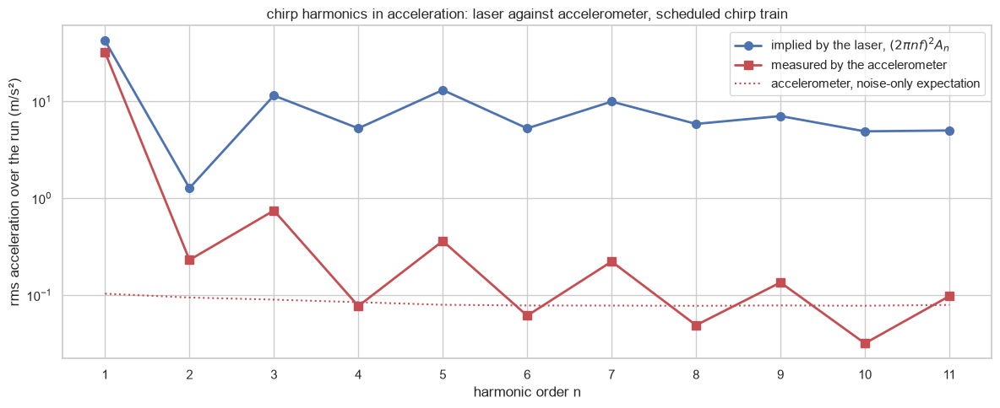

In [14]:
ACC_M_S2_PER_V = 9.81 / 0.0578                          # nominal accelerometer scale, 0.0578 V/g; positive sign (the plot script's minus sign gives a phase near 180°)
a_run = df["ai2_corrected_V"].to_numpy()[run_m] * ACC_M_S2_PER_V   # m/s², accelerometer, run part

harm_a, S_ra = [], []
for t0 in np.arange(0.0, t_m[-1] - WIN_M, WIN_M):        # the same windows as the laser fit above
    m = (t_m >= t0) & (t_m < t0 + WIN_M)
    tm, tc_ = t_m[m], t_m[m].mean()
    fc_ = f_fn_m(tc_)
    ns = np.arange(1, int(F_MOTION_MAX // fc_) + 1)
    ph = phase_m(tm)
    X = np.column_stack([f(n * ph) for n in ns for f in (np.cos, np.sin)] + [(tm - tc_) ** j for j in range(4)])
    q = np.linalg.lstsq(X, a_run[m], rcond=None)[0]
    f_wa, P_wa = signal.periodogram(a_run[m] - X @ q, fs=FS_RAW, window="hann", detrend=False)
    S_ra.append(P_wa)
    harm_a.append((ns * fc_, np.hypot(q[0:2 * len(ns):2], q[1:2 * len(ns):2])))
S_ra = np.mean(S_ra, axis=0)
harm_a = [(fn, np.sqrt(2 * np.clip(An ** 2 / 2 - np.interp(fn, f_wa, S_ra) / WIN_M, 0.0, None))) for fn, An in harm_a]

N_ORD = 11
rms_order = lambda pairs, conv: np.array([np.sqrt(np.mean([conv(fn[n - 1], An[n - 1]) ** 2 for fn, An in pairs if len(An) >= n]))
                                         for n in range(1, N_ORD + 1)])
acc_laser = rms_order(harm, lambda fn, An: (2 * np.pi * fn) ** 2 * An)    # m/s², implied by the laser
acc_meas = rms_order(harm_a, lambda fn, An: An)                          # m/s², accelerometer
acc_noise = np.array([np.sqrt(np.mean([2 * np.interp(fn[n - 1], f_wa, S_ra) / WIN_M for fn, An in harm_a if len(An) >= n]))
                      for n in range(1, N_ORD + 1)])
for n in range(1, N_ORD + 1):
    print(f"n={n:2d}: implied by the laser {acc_laser[n - 1]:8.3f} m/s², accelerometer {acc_meas[n - 1]:7.3f} m/s² "
          f"(noise-only {acc_noise[n - 1]:.3f}); ratio accelerometer / laser {acc_meas[n - 1] / acc_laser[n - 1]:.2f}")

orders_ = np.arange(1, N_ORD + 1)
fig, ax = plt.subplots(figsize=(12, 5))
ax.semilogy(orders_, acc_laser, "o-", color="C0", lw=2, ms=7, label="implied by the laser, $(2\\pi n f)^2 A_n$")
ax.semilogy(orders_, acc_meas, "s-", color="C3", lw=2, ms=7, label="measured by the accelerometer")
ax.semilogy(orders_, acc_noise, ":", color="C3", lw=1.5, label="accelerometer, noise-only expectation")
ax.set(xlabel="harmonic order n", ylabel="rms acceleration over the run (m/s²)", xticks=orders_,
       title="chirp harmonics in acceleration: laser against accelerometer, scheduled chirp train")
ax.legend()
plt.tight_layout(); plt.show()

**Findings (harmonics).**

- **The large harmonics in the laser are not motion.** Order by order (3rd to 11th), the accelerometer sees 15–100 times less than the laser implies; its own roll-off explains at most a factor 2–5. The fundamental agrees as expected (0.76, the accelerometer's known under-reading).
- **They are a distortion in the laser reading.** Odd harmonics falling off roughly as $1/n$ in position would need forces as large as the actuator's maximum for a single high harmonic.
- **The mass does have a small real nonlinearity.** The accelerometer shows odd harmonics clearly above its noise: about 2 % of the fundamental at $n$ = 3, 1 % at $n$ = 5.
- **For velocity and acceleration from the laser, the harmonics are noise.** The error curve above counted them as motion, which pushed the cutoff up and the errors to 10–50 %.
- **For the fit on position they are a small model error.** About 1.6 % of the motion at the 3rd harmonic; later possibly part of the laser's sensor model, as a static nonlinearity.

**The cutoff, with the laser's harmonics as noise.** The same error curve as above, but the window fit models only the chirp's fundamental and the slow motion as motion:

$$x(t) \approx c_1 \cos\varphi(t) + d_1 \sin\varphi(t) + \sum_{j=0}^{3} e_j\,(t - \bar t)^j + r(t)$$

Everything else, the laser's harmonics included, is in the residual $r$ and counts as noise. The small real harmonics the accelerometer sees (about 2 % at $n$ = 3) are counted as noise too, a minor simplification. With the motion inside 10–55 Hz, the cutoff is limited by the filter's own effect inside the band: printed is also the gain $H_{f_c}$ at 55 Hz for the best cutoff. The green curve is an 8th-order Butterworth (zero phase), which is flatter inside the band for the same cutoff.


velocity    : best cutoff 80 Hz, error 3.88 % (gain at 55 Hz 0.952); with the 150 Hz line removed: best 80 Hz, error 3.88 %
              8th order: best cutoff 65 Hz, error 3.59 % (gain at 55 Hz 0.935)
              8th order at 70 Hz: error 3.61 % (gain at 55 Hz 0.979)
              8th order at 75 Hz: error 3.71 % (gain at 55 Hz 0.993)


acceleration: best cutoff 75 Hz, error 4.85 % (gain at 55 Hz 0.923); with the 150 Hz line removed: best 75 Hz, error 4.84 %
              8th order: best cutoff 65 Hz, error 3.83 % (gain at 55 Hz 0.935)
              8th order at 70 Hz: error 3.98 % (gain at 55 Hz 0.979)
              8th order at 75 Hz: error 4.34 % (gain at 55 Hz 0.993)


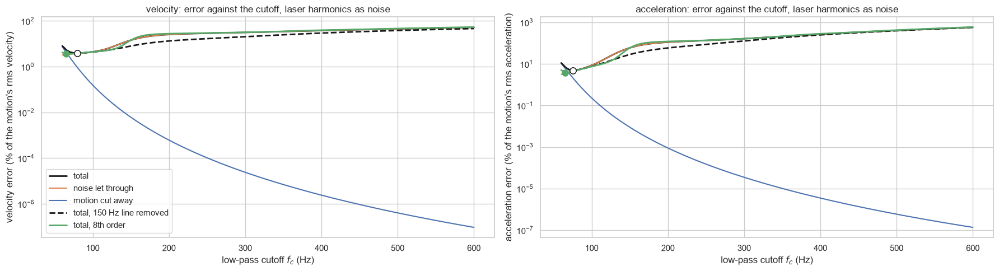

In [15]:
harm1, S_r1, S_r1_150 = [], [], []
for t0 in np.arange(0.0, t_m[-1] - WIN_M, WIN_M):        # the same windows as above
    m = (t_m >= t0) & (t_m < t0 + WIN_M)
    tm, tc_ = t_m[m], t_m[m].mean()
    fc_ = f_fn_m(tc_)
    ph = phase_m(tm)
    base = [np.cos(ph), np.sin(ph)] + [(tm - tc_) ** j for j in range(4)]
    for extra, store in (([], S_r1), ([np.cos(2 * np.pi * 150.0 * tm), np.sin(2 * np.pi * 150.0 * tm)], S_r1_150)):
        X = np.column_stack(base + extra)
        q = np.linalg.lstsq(X, x_m[m], rcond=None)[0]
        store.append(signal.periodogram(x_m[m] - X @ q, fs=FS_RAW, window="hann", detrend=False)[1])
        if store is S_r1:
            harm1.append((np.array([fc_]), np.array([np.hypot(q[0], q[1])])))
S_r1, S_r1_150 = np.mean(S_r1, axis=0), np.mean(S_r1_150, axis=0)
harm1 = [(fn, np.sqrt(2 * np.clip(An ** 2 / 2 - np.interp(fn, f_w, S_r1) / WIN_M, 0.0, None))) for fn, An in harm1]

harm_all = harm                                         # keep the all-harmonics split; err_curve reads the global harm
harm = harm1
fig, ax = plt.subplots(1, 2, figsize=(18, 5))
for a_, p, name in ((ax[0], 1, "velocity"), (ax[1], 2, "acceleration")):
    ref = np.sqrt(np.mean([np.sum((2 * np.pi * fn) ** (2 * p) * An ** 2 / 2) for fn, An in harm]))
    n_, c_, tot = err_curve(S_r1, p)
    _, _, tot2 = err_curve(S_r1_150, p)
    _, _, tot8 = err_curve(S_r1, p, order=8)
    for y_, style, lab in ((tot, "k-", "total"), (n_, "C1-", "noise let through"), (c_, "C0-", "motion cut away"),
                           (tot2, "k--", "total, 150 Hz line removed"), (tot8, "C2-", "total, 8th order")):
        a_.semilogy(FC_GRID, y_ / ref * 100, style, lw=2 if lab.startswith("total") else 1.5, label=lab)
    j, j2, j8 = np.argmin(tot), np.argmin(tot2), np.argmin(tot8)
    a_.plot(FC_GRID[j], tot[j] / ref * 100, "o", color="k", ms=8)
    a_.plot(FC_GRID[j2], tot2[j2] / ref * 100, "o", color="k", ms=8, mfc="w")
    a_.set(xlabel="low-pass cutoff $f_c$ (Hz)", ylabel=f"{name} error (% of the motion's rms {name})",
           title=f"{name}: error against the cutoff, laser harmonics as noise")
    print(f"{name:12s}: best cutoff {FC_GRID[j]:.0f} Hz, error {tot[j] / ref * 100:.2f} % "
          f"(gain at 55 Hz {1 / (1 + (55 / FC_GRID[j]) ** 8):.3f}); with the 150 Hz line removed: best {FC_GRID[j2]:.0f} Hz, "
          f"error {tot2[j2] / ref * 100:.2f} %")
    print(f"{"":12s}  8th order: best cutoff {FC_GRID[j8]:.0f} Hz, error {tot8[j8] / ref * 100:.2f} % (gain at 55 Hz {1 / (1 + (55 / FC_GRID[j8]) ** 16):.3f})")
    a_.plot(FC_GRID[j8], tot8[j8] / ref * 100, "o", color="C2", ms=8)
    for fc_s in (70.0, 75.0):
        js = np.argmin(abs(FC_GRID - fc_s))
        print(f"{"":12s}  8th order at {fc_s:.0f} Hz: error {tot8[js] / ref * 100:.2f} % (gain at 55 Hz {1 / (1 + (55 / fc_s) ** 16):.3f})")
harm = harm_all
ax[0].legend()
plt.tight_layout(); plt.show()

**Findings (cutoff for velocity and acceleration).**

- **With the laser's harmonics counted as noise, the best cutoff lies just above the band.** Higher cutoffs let in more of the laser's distortion and the stale-row noise, which grow with frequency in velocity and acceleration.
- **The 150 Hz pickup line does not matter.** At these cutoffs it is filtered out anyway; it does not need removing.
- **About 4 % error remains that no low-pass removes.** At low chirp frequencies the laser's harmonics fall inside the passband (the 3rd harmonic of a 20 Hz chirp sits at 60 Hz).
- **A steeper filter keeps the band flat at almost no cost.** A 4th-order filter at its best cutoff (75–80 Hz) passes 55 Hz at only 0.92–0.95, a systematic under-read at the top of the band. An 8th-order filter at 75 Hz passes 55 Hz at 0.993 with nearly the same error (3.7 % velocity, 4.3 % acceleration).
- **Decision: velocity and acceleration from the laser use an 8th-order Butterworth low-pass at 75 Hz, zero phase.** Applied as second-order sections (`sosfiltfilt`) for numerical stability. Zero phase uses future samples, which is fine offline; a real-time filter would add delay.

**The fit target at 1 kHz.** Halving the rate halves the cost of every simulation, but the stale-row noise between 500 Hz and 1 kHz would fold back into the band. The same 75 Hz filter (8th order, zero phase) is used as the anti-alias filter before keeping every other sample. It passes the band almost unchanged, adds no delay, and also removes the laser's distortion above about 90 Hz, which is not motion.

Shown: the spectrum (Welch) of the run position with the pickup removed, raw at 2 kHz, filtered at 2 kHz, and filtered and decimated to 1 kHz. Below 500 Hz the last two should coincide: nothing folded back. Printed: the filter's gain inside the band.

zero-phase gain at 10, 35, 50, 55 Hz: 1.0000, 1.0000, 0.9985, 0.9931


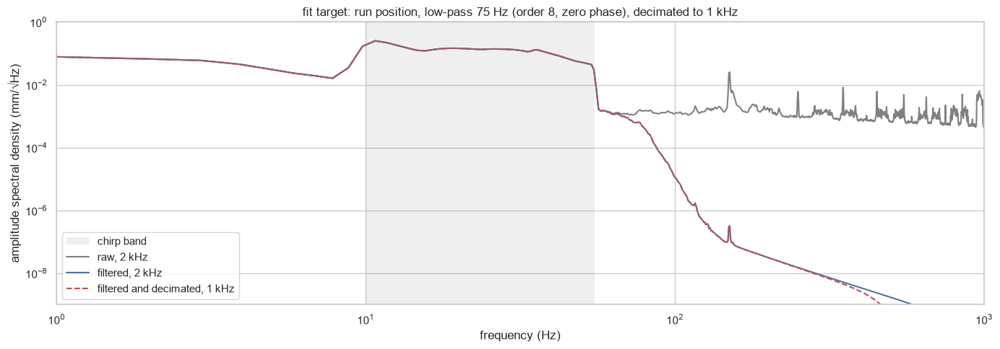

In [16]:
F_LP, ORDER_LP = 75.0, 8                                # Hz, low-pass for velocity, acceleration and the fit target
sos_lp = signal.butter(ORDER_LP, F_LP / (FS_RAW / 2), output="sos")
x_run = x_clean[run_m]                                  # mm, run part, pickup removed, 2 kHz
x_lp = signal.sosfiltfilt(sos_lp, x_run)               # zero phase
x_1k = x_lp[::2]                                        # 1 kHz

gain = lambda f: 1 / (1 + (f / F_LP) ** (2 * ORDER_LP))   # zero-phase gain
print("zero-phase gain at 10, 35, 50, 55 Hz: " + ", ".join(f"{gain(f):.4f}" for f in (10, 35, 50, 55)))

fig, ax = plt.subplots(figsize=(14, 5))
ax.axvspan(10, 55, color="0.5", alpha=0.12, lw=0, label="chirp band")
for s_, fs_, lab, color, ls in ((x_run, FS_RAW, "raw, 2 kHz", "0.5", "-"), (x_lp, FS_RAW, "filtered, 2 kHz", "C0", "-"),
                               (x_1k, FS_RAW / 2, "filtered and decimated, 1 kHz", "C3", "--")):
    n_ = NPERSEG_C if fs_ == FS_RAW else NPERSEG_C // 2  # same frequency resolution at both rates
    f_, P_ = signal.welch(s_, fs=fs_, window="hann", nperseg=n_, noverlap=n_ // 2, detrend="constant")
    ax.loglog(f_[1:], np.sqrt(P_[1:]), ls, color=color, lw=1.5, label=lab)
ax.set(xlim=(1, FS_RAW / 2), ylim=(1e-9, 1), xlabel="frequency (Hz)", ylabel="amplitude spectral density (mm/√Hz)",
       title=f"fit target: run position, low-pass {F_LP:.0f} Hz (order {ORDER_LP}, zero phase), decimated to 1 kHz")
ax.legend()
plt.tight_layout(); plt.show()

**Is RK4 at 1 ms accurate enough?** For the linear test equation $\dot{z} = j\omega z$, one RK4 step of length $T_s$ multiplies the state by

$$G(j\omega T_s) = 1 + z + \frac{z^2}{2} + \frac{z^3}{6} + \frac{z^4}{24}, \qquad z = j\omega T_s$$

instead of the exact $e^{j\omega T_s}$. Its phase error per step is $\angle G - \omega T_s$ and its amplitude error $|G| - 1$. At 55 Hz and $T_s$ = 1 ms, $\omega T_s \approx 0.35$.

Shown: an undamped oscillator at 55 Hz, simulated for 1 s with the notebook's own `step` at 1 ms and at 0.5 ms, against the exact solution. Printed: the phase and amplitude error after 0.1 s and 1 s, from the simulation and from $G$.

Ts = 1.0 ms, after 0.1 s: phase error -0.225°, amplitude -0.1165 % (from G); max |x - exact| in the simulation 0.392 % of the amplitude
Ts = 1.0 ms, after 1.0 s: phase error -2.254°, amplitude -1.1651 % (from G); max |x - exact| in the simulation 4.033 % of the amplitude
Ts = 0.5 ms, after 0.1 s: phase error -0.015°, amplitude -0.0037 % (from G); max |x - exact| in the simulation 0.025 % of the amplitude
Ts = 0.5 ms, after 1.0 s: phase error -0.146°, amplitude -0.0368 % (from G); max |x - exact| in the simulation 0.255 % of the amplitude


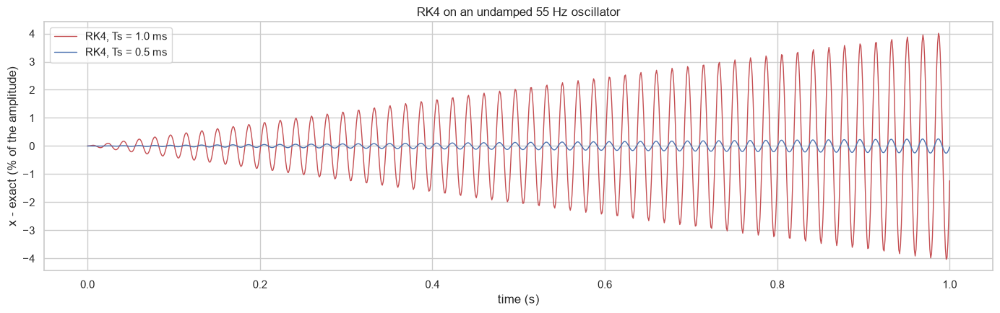

In [17]:
import math

F_TEST = 55.0                                           # Hz, highest chirp frequency
w_t = 2 * np.pi * F_TEST
acc_osc = lambda x, v, u: -w_t ** 2 * x                 # undamped oscillator

fig, ax = plt.subplots(figsize=(14, 4.5))
for ts_, color in ((1e-3, "C3"), (0.5e-3, "C0")):
    n_steps = int(round(1.0 / ts_))
    x_, v_, xs = 1.0, 0.0, [1.0]
    for _ in range(n_steps):
        x_, v_ = step(x_, v_, 0.0, 0.0, acc_osc, ts_)
        xs.append(x_)
    t_ = np.arange(n_steps + 1) * ts_
    err_ = np.array(xs) - np.cos(w_t * t_)
    G = sum((1j * w_t * ts_) ** k / math.factorial(k) for k in range(5))
    dphi, damp = np.angle(G) - w_t * ts_, abs(G) - 1
    for T_h in (0.1, 1.0):
        n_h = int(round(T_h / ts_))
        print(f"Ts = {ts_ * 1e3:.1f} ms, after {T_h:.1f} s: phase error {np.degrees(dphi * n_h):+.3f}°, amplitude {damp * n_h * 100:+.4f} % "
              f"(from G); max |x - exact| in the simulation {np.abs(err_[:n_h + 1]).max() * 100:.3f} % of the amplitude")
    ax.plot(t_, err_ * 100, color=color, lw=1, label=f"RK4, Ts = {ts_ * 1e3:.1f} ms")
ax.set(xlabel="time (s)", ylabel="x - exact (% of the amplitude)", title=f"RK4 on an undamped {F_TEST:.0f} Hz oscillator")
ax.legend()
plt.tight_layout(); plt.show()

**The real case: damped and driven.** The undamped oscillator is the worst case: its phase error builds up for ever. The actuator is damped and driven. Its free response, which carries any error, dies out with a time constant $2m/c \approx$ 65 ms; what remains is the forced response, whose error is RK4's error per step, not an accumulated one. Test:

$$m\ddot{x} + c\,\dot{x} + k\,x = \sin(2\pi\cdot 55\,t), \qquad m = 51.5\ \text{kg},\; c = 1600\ \text{N·s/m},\; k = 3.86\cdot10^4\ \text{N/m}$$

from rest, for 1 s, with RK4 at 1 ms and 0.5 ms against a 0.1 ms reference. The force is evaluated exactly at each RK4 stage, as it will be with $i_\text{sent}$ as a formula, so only the integration error is measured. Printed: the largest error, relative to the steady amplitude, during the start-up (first 0.3 s) and in steady state (last 0.5 s).

Ts = 1.0 ms: largest error 0.0047 % of the steady amplitude in the first 0.3 s, 0.0015 % in the last 0.5 s
Ts = 0.5 ms: largest error 0.0003 % of the steady amplitude in the first 0.3 s, 0.0001 % in the last 0.5 s


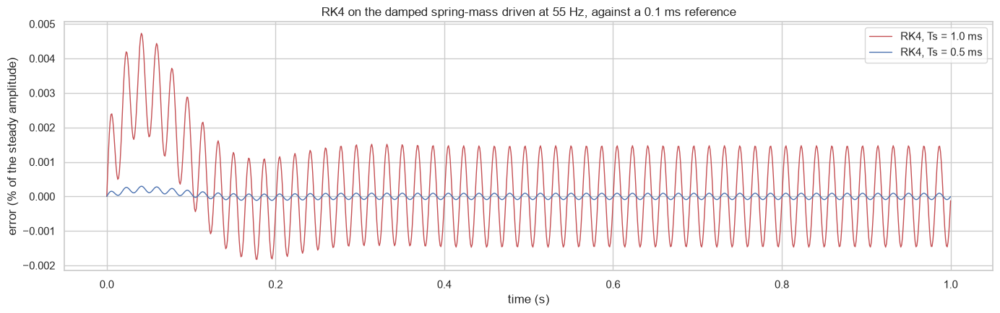

In [18]:
m_d, c_d, k_d, f_d = 51.5, 1600.0, 3.86e4, 55.0       # kg, N s/m, N/m, Hz
acc_d = lambda x, v, t: (np.sin(2 * np.pi * f_d * t) - c_d * v - k_d * x) / m_d


def rk4_exact_input(acc_t, ts, T):
    "RK4 from rest over T seconds with the input evaluated exactly at each stage; returns times and positions."
    n_ = int(round(T / ts))
    x, v, out = 0.0, 0.0, [0.0]
    for j in range(n_):
        t = j * ts
        k1x, k1v = v, acc_t(x, v, t)
        k2x, k2v = v + ts / 2 * k1v, acc_t(x + ts / 2 * k1x, v + ts / 2 * k1v, t + ts / 2)
        k3x, k3v = v + ts / 2 * k2v, acc_t(x + ts / 2 * k2x, v + ts / 2 * k2v, t + ts / 2)
        k4x, k4v = v + ts * k3v, acc_t(x + ts * k3x, v + ts * k3v, t + ts)
        x, v = x + ts / 6 * (k1x + 2 * k2x + 2 * k3x + k4x), v + ts / 6 * (k1v + 2 * k2v + 2 * k3v + k4v)
        out.append(x)
    return np.arange(n_ + 1) * ts, np.array(out)


t_ref, x_ref = rk4_exact_input(acc_d, 1e-4, 1.0)
amp = np.abs(x_ref[t_ref >= 0.5]).max()                 # steady amplitude
fig, ax = plt.subplots(figsize=(14, 4.5))
for ts_, color in ((1e-3, "C3"), (0.5e-3, "C0")):
    t_, x_ = rk4_exact_input(acc_d, ts_, 1.0)
    e_ = x_ - x_ref[::int(round(ts_ / 1e-4))]
    print(f"Ts = {ts_ * 1e3:.1f} ms: largest error {np.abs(e_[t_ <= 0.3]).max() / amp * 100:.4f} % of the steady amplitude "
          f"in the first 0.3 s, {np.abs(e_[t_ >= 0.5]).max() / amp * 100:.4f} % in the last 0.5 s")
    ax.plot(t_, e_ / amp * 100, color=color, lw=1, label=f"RK4, Ts = {ts_ * 1e3:.1f} ms")
ax.set(xlabel="time (s)", ylabel="error (% of the steady amplitude)", title="RK4 on the damped spring-mass driven at 55 Hz, against a 0.1 ms reference")
ax.legend()
plt.tight_layout(); plt.show()

**Findings (fit target and integration).**

- **The 75 Hz filter leaves the band intact and removes the rest.** Its gain is 1.000 up to 35 Hz and 0.993 at 55 Hz; above the band the noise and the laser's distortion drop by four to six orders of magnitude.
- **Decimating to 1 kHz after it is safe.** Below 500 Hz the filtered spectrum at 2 kHz and at 1 kHz coincide: nothing folds back.
- **RK4 at 1 ms is accurate enough for this system.** Damped and driven at 55 Hz, its error stays below 0.005 % of the motion. The undamped test (up to 4 % over 1 s) overstates it: there a phase error builds up for ever, while the real damping forgets it within about 65 ms.
- **Decision: the fit target is the laser position with the pickup removed, low-passed at 75 Hz (8th order, zero phase) and decimated to 1 kHz; the model is integrated with RK4 at 1 ms, with $i_\text{sent}$ evaluated exactly at each RK4 stage.** The notebook's current `step` averages the input over a step instead; the new simulator evaluates the formula at the stage times.

### 4. Acceleration: where does it come from?

A fit on Newton's law, $m\ddot{x} = F$, needs the acceleration. Two sources are logged:

- the laser position, differentiated twice;
- the accelerometer.

- What does each give in the 10–55 Hz band: size, noise, timing, and how well its scale is known?
- Does the fit need acceleration at all, or can it work on position directly?

**Decision: fit on position, not on acceleration.** Two ways to fit the model:

- **Equation error** (a fit on force, as Model C): $\;\hat\theta = \arg\min_\theta \sum_k \big(m\ddot{x}_k - \varphi(x_k, \dot{x}_k, i_k)^\top\theta\big)^2$. Linear in the parameters and fast, but it needs $\ddot{x}$ and $\dot{x}$ at every sample. Differentiating amplifies noise with $(2\pi f)^2$, and noise in $\dot{x}$ inside the regressors biases the parameters.
- **Output error** (a fit on position): $\;\hat\theta = \arg\min_\theta \sum_s \sum_{k=1}^{H} \big(\hat{x}_{s+k\mid s}(\theta) - x_{s+k}\big)^2$. No derivatives of the data apart from the starting velocity of each prediction; white noise adds scatter but no bias; and it judges the model on position, as the validation and the application do. It is nonlinear and needs starting values.

- **The output-error fit on position is the main method.**
- **The equation-error fit only supplies its starting values.**
- **Acceleration is then only needed for those starting values and the starting velocity.** The accelerometer becomes a possible independent check, not the fit target.

**The accelerometer against the laser.** Both sensors are compared with the exact sent current, and the laser's acceleration follows in the frequency domain, so nothing is differentiated in time:

$$R(f) = \frac{H_{i \to a_\text{meas}}(f)}{-\omega^2\, H_{i \to x}(f)}, \qquad H_{i \to y}(f) = \frac{G_{i y}(f)}{G_{i i}(f)}$$

- $H_{i \to y}$ is the $H_1$ estimate (Welch, `NPERSEG_R` samples) from the sent current $i_\text{sent}$ to sensor $y$. The input is exact, so noise on either sensor lowers the coherence but does not bias $H$.
- $x$: the raw laser position with the pickup removed. $a_\text{meas}$: `ai2_corrected_V` at the nominal scale, $9.81/0.0578$ m/s² per V (0.0578 V/g); the empirical correction of the earlier notebooks is not used. The sign is positive: with the minus sign of `scripts/plot_voice_coil_log.py` the phase of $R$ sits near 180°, so that sign is opposite to the laser's in these logs.
- A delay that both sensors share cancels in $R$; what is left is the difference between the two sensor chains.

If both measured the same motion perfectly, $R = 1$ at every frequency with zero phase. A constant $|R| \neq 1$ is a scale error; a phase that grows with frequency is a relative delay; a smooth roll-off is a filter in one chain; a narrow feature is a resonance in one sensor path.

Shown, over the chirp band of the scheduled chirp (train): $|R|$, the phase of $R$, and the coherence of both sensors with the sent current.

|R| over 10-55 Hz: 0.65 to 0.98 (at 15 Hz 0.95, at 50 Hz 0.69)
phase of R: -8° at 10 Hz to -31° at 55 Hz; as a pure delay (33-37 Hz left out): accelerometer 1.44 ms later than the laser


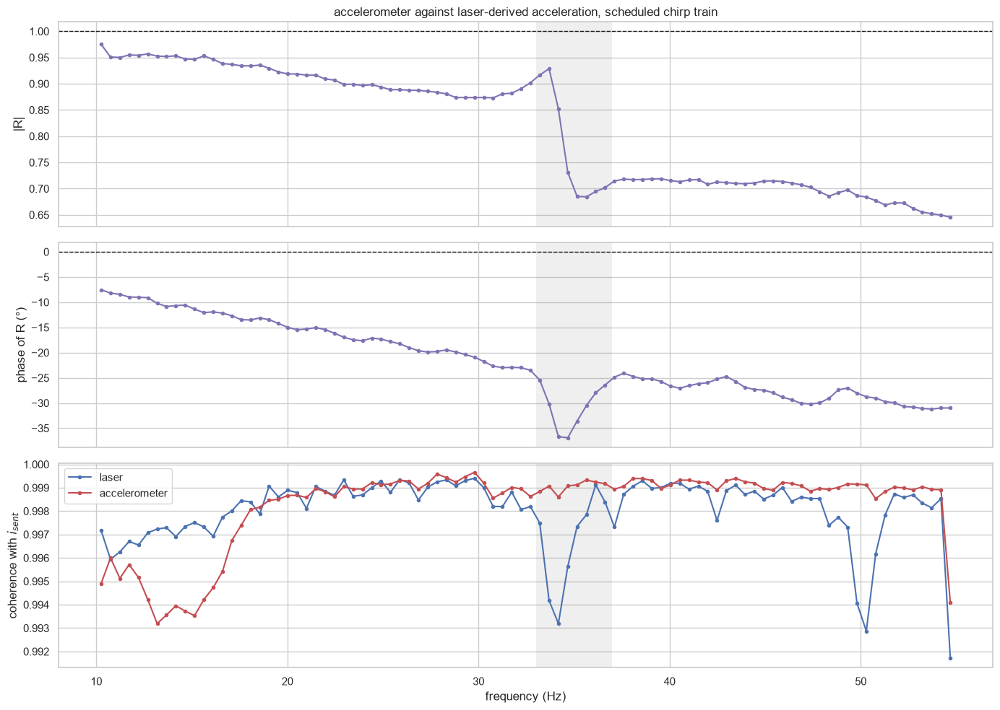

In [19]:
NPERSEG_R = 4096                                        # samples per Welch segment: 2.05 s at 2 kHz, 0.49 Hz resolution

run_r = t_log >= 0
i_r = i_sent(t_log[run_r])
x_r = x_clean[run_r] * 1e-3                             # m, laser with the pickup removed
a_r = df["ai2_corrected_V"].to_numpy()[run_r] * ACC_M_S2_PER_V   # m/s², accelerometer at its nominal scale


def h1(u, y):
    "H1 estimate of y / u with the coherence, Welch with NPERSEG_R samples."
    f, Puu = signal.welch(u, fs=FS_RAW, nperseg=NPERSEG_R)
    _, Puy = signal.csd(u, y, fs=FS_RAW, nperseg=NPERSEG_R)
    _, coh = signal.coherence(u, y, fs=FS_RAW, nperseg=NPERSEG_R)
    return f, Puy / Puu, coh


f_r, H_x, coh_x = h1(i_r, x_r)
_, H_a, coh_a = h1(i_r, a_r)
w_r = 2 * np.pi * f_r
with np.errstate(invalid="ignore"):                   # the 0 Hz bin has no ratio
    R = H_a / (-w_r ** 2 * np.where(w_r > 0, H_x, np.nan))
band_r = (f_r >= 10) & (f_r <= 55)
calm = band_r & ((f_r < 33) | (f_r > 37))              # away from the 34.8 Hz laser mode
ph = np.unwrap(np.angle(R[band_r]))
slope_r = np.polyfit(w_r[calm], np.unwrap(np.angle(R[calm])), 1)[0]
print(f"|R| over 10-55 Hz: {np.abs(R[band_r]).min():.2f} to {np.abs(R[band_r]).max():.2f} "
      f"(at 15 Hz {np.abs(R[np.argmin(abs(f_r - 15))]):.2f}, at 50 Hz {np.abs(R[np.argmin(abs(f_r - 50))]):.2f})")
print(f"phase of R: {np.degrees(ph[0]):.0f}° at 10 Hz to {np.degrees(ph[-1]):.0f}° at 55 Hz; "
      f"as a pure delay (33-37 Hz left out): accelerometer {-slope_r * 1e3:.2f} ms later than the laser")

fig, ax = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
ax[0].plot(f_r[band_r], np.abs(R[band_r]), "o-", ms=3, color="C4")
ax[0].axhline(1.0, color="k", ls="--", lw=1)
ax[0].set(ylabel="|R|", title="accelerometer against laser-derived acceleration, scheduled chirp train")
ax[1].plot(f_r[band_r], np.degrees(ph), "o-", ms=3, color="C4")
ax[1].axhline(0.0, color="k", ls="--", lw=1)
ax[1].set(ylabel="phase of R (°)")
ax[2].plot(f_r[band_r], coh_x[band_r], "o-", ms=3, color="C0", label="laser")
ax[2].plot(f_r[band_r], coh_a[band_r], "o-", ms=3, color="C3", label="accelerometer")
ax[2].set(ylabel="coherence with $i_{sent}$", xlabel="frequency (Hz)")
ax[2].legend()
for a_ in ax:
    a_.axvspan(33, 37, color="0.5", alpha=0.12, lw=0)
plt.tight_layout(); plt.show()

**Which sensor is right above 35 Hz?** The ratio $R$ shows that the two sensors differ, not which one is right. A third reference is needed that does not depend on parameters we have not identified yet.

For a mass driven by a force $\Gamma i$ and held by a spring and a damper,

$$m\,\Big|\frac{A}{I}(j\omega)\Big| = \frac{\Gamma}{\big|1 - \frac{k}{m\omega^2} - j\,\frac{c}{m\omega}\big|}$$

- The left side uses only the measured response and the mass, $m$ = 51.5 kg, which is known.
- The spring and the damper change the right side only slowly with frequency, and their effect fades above the spring resonance, so it tends to the motor constant $\Gamma$.
- A step of tens of percent within about 1 Hz cannot come from them, nor from the motor constant. If one sensor shows such a step and the other does not, the step is in that sensor.

Shown: $m|A/I|$ for each sensor, with $A/I$ = $H_{i \to a_\text{meas}}$ (accelerometer) and $-\omega^2 H_{i \to x}$ (laser) from above. The datasheet motor constant, 283 N/A at the centre, is drawn for reference. The phase is not shown: reading it needs the damping, which comes with the delay $\tau_d$ later.

laser         m|A/I| (N per sent A) at 15, 30, 33, 37, 45, 54 Hz: 190, 217, 201, 245, 232, 236
accelerometer m|A/I| (N per sent A) at 15, 30, 33, 37, 45, 54 Hz: 180, 190, 184, 175, 165, 153


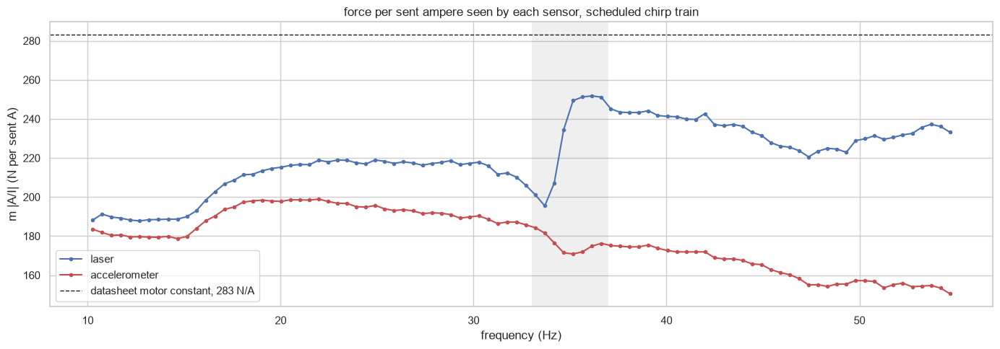

In [20]:
F_per_A = {"laser": M * np.abs(-w_r ** 2 * H_x), "accelerometer": M * np.abs(H_a)}   # N per sent A: m |A/I|
for name, F_ in F_per_A.items():
    print(f"{name:13s} m|A/I| (N per sent A) at 15, 30, 33, 37, 45, 54 Hz: "
          + ", ".join(f"{F_[np.argmin(abs(f_r - fe))]:.0f}" for fe in (15, 30, 33, 37, 45, 54)))

fig, ax = plt.subplots(figsize=(14, 5))
for (name, F_), color in zip(F_per_A.items(), ("C0", "C3")):
    ax.plot(f_r[band_r], F_[band_r], "o-", ms=3, color=color, label=name)
ax.axhline(283.0, color="k", ls="--", lw=1, label="datasheet motor constant, 283 N/A")
ax.axvspan(33, 37, color="0.5", alpha=0.12, lw=0)
ax.set(xlabel="frequency (Hz)", ylabel="m |A/I| (N per sent A)", title="force per sent ampere seen by each sensor, scheduled chirp train")
ax.legend()
plt.tight_layout(); plt.show()

**Findings (laser against accelerometer).**

- **The accelerometer's sign is opposite to the plotting script's.** With the script's minus sign the two sensors are 180° apart.
- **The step at 35 Hz is in the laser.** The laser's force per ampere dips at 34 Hz and jumps by about 25 % at 35.5 Hz, the shape of a resonance in its path; the accelerometer shows no step there.
- **Above the mode the laser over-reads by about 7–13 %.** Below it (20–31 Hz) the laser is flat; above it, it reads higher, right in the application band.
- **The accelerometer rolls off smoothly.** Its force per ampere falls by about 24 % from 20 to 55 Hz, a low-pass in its chain, so it is no flat reference either.
- **Both sensors rise together between 15 and 19 Hz, by about 12–15 %.** Seen by both, so not a sensor effect. It coincides with the start of the amplitude ramp (2 A towards 6 A, at 30 s, near 15 Hz): possibly less force per ampere at small current. Tested below.
- **Decision: the laser stays the fit sensor, with its mode described in the measurement equation.** $y = S(s)\,x + p(t) + e$, with $S$ a lightly damped zero-pole pair near 34.8 Hz and $S(0) = 1$, identified together with the model.

**Is the rise at 15–19 Hz an amplitude effect?** In the scheduled chirp (train) the rise coincides with the start of the amplitude ramp from 2 A. If the force per ampere is lower at small current, the rise follows the amplitude, not the frequency. Four runs tell the two apart:

| Run | Current near 10–19 Hz | Expected if amplitude | Expected if frequency |
|---|---|---|---|
| scheduled, train | 2 A, ramp to 6 A from 15 Hz | rise | rise |
| scheduled, test | 3 A, ramp to 7 A from 15 Hz | smaller rise | same rise |
| plain, train | 6.5 A, constant | flat | same rise |
| plain, test | 6.0 A, constant | flat | same rise |

Both scheduled runs start their ramp at 30 s, when the chirp is near 15 Hz, so the plain chirps carry the test. Shown: $m|A/I|$ over 10–30 Hz for each run and both sensors, as above (Welch $H_1$ from the sent current, raw laser and accelerometer). Only samples where the chirp is above 8 Hz are used, which leaves out the large low-frequency strokes of the plain chirps, where the laser clips.

scheduled train: 2 A, ramp to 6 A from 15 Hz     laser m|A/I| at 13 Hz 188, at 22 Hz 219 N/A (ratio 1.16)


scheduled test: 3 A, ramp to 7 A from 15 Hz      laser m|A/I| at 13 Hz 211, at 22 Hz 219 N/A (ratio 1.04)
plain train: 6.5 A                               laser m|A/I| at 13 Hz 224, at 22 Hz 222 N/A (ratio 0.99)


plain test: 6.0 A                                laser m|A/I| at 13 Hz 223, at 22 Hz 219 N/A (ratio 0.98)


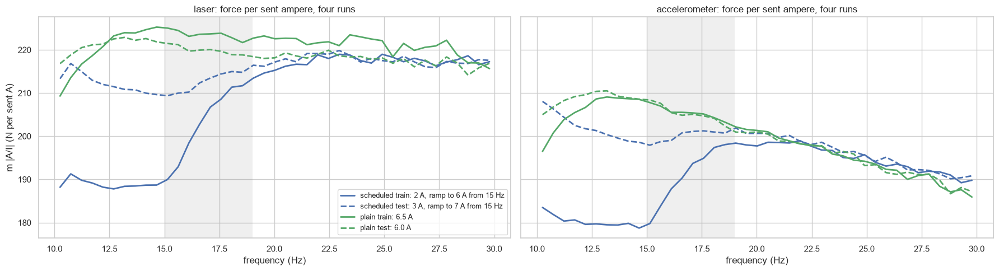

In [21]:
F_MIN_AMP = 8.0                                         # Hz, samples below this chirp frequency are left out

fig, ax = plt.subplots(1, 2, figsize=(18, 5), sharey=True)
for key, label, color, ls in RUNS_AMP:
    d_ = RAW_DF[key]
    i_fn, f_fn = sent_current_fn(RAW_LOGS[key])
    t_ = d_["time_s"].to_numpy()
    sel = (t_ >= 0) & (f_fn(t_) >= F_MIN_AMP)
    i_ = i_fn(t_[sel])
    f_a, Hx_, _ = h1(i_, d_["position_mm"].to_numpy()[sel] * 1e-3)
    _, Ha_, _ = h1(i_, d_["ai2_corrected_V"].to_numpy()[sel] * ACC_M_S2_PER_V)
    w_a = 2 * np.pi * f_a
    b_ = (f_a >= 10) & (f_a <= 30)
    F_las, F_acc = M * np.abs(w_a ** 2 * Hx_), M * np.abs(Ha_)   # N per sent A, laser and accelerometer
    for a_, F_ in ((ax[0], F_las), (ax[1], F_acc)):
        a_.plot(f_a[b_], F_[b_], ls, color=color, lw=2, label=label)
    lo, hi = F_las[np.argmin(abs(f_a - 13))], F_las[np.argmin(abs(f_a - 22))]
    print(f"{label:48s} laser m|A/I| at 13 Hz {lo:.0f}, at 22 Hz {hi:.0f} N/A (ratio {hi / lo:.2f})")
for a_, name in zip(ax, ("laser", "accelerometer")):
    a_.axvspan(15, 19, color="0.5", alpha=0.12, lw=0)
    a_.set(xlabel="frequency (Hz)", title=f"{name}: force per sent ampere, four runs")
ax[0].set_ylabel("m |A/I| (N per sent A)")
ax[0].legend(fontsize=9)
plt.tight_layout(); plt.show()

**Findings (amplitude).**

- **The rise at 15–19 Hz is an amplitude effect, not a frequency effect.** The plain chirps, at a constant 6–6.5 A, are flat there.
- **At small current the actuator delivers less force per ampere.** About 14 % less at 2 A and about 4 % less at 3 A than at 6 A; once the scheduled runs have ramped up (above about 20 Hz) all four runs agree.
- **Both sensors show it, so it is the actuator, not the measurement.** Where the loss sits, in the drive or in the mechanics, is tested next.

**Drive or mechanics?** The force per ampere is lower at small current. Either the drive delivers less current than it is sent, or the current arrives and part of its force is lost. The drive's measured current tells them apart. Section 1 compared it with the sent current on the scheduled train only, and found it lower and later below 20 Hz; with one run, frequency and amplitude could not be separated.

The same comparison (delay $\tau$ and gain $g$ of `actual_current_A` against $i_\text{sent}$ per 5 Hz band, `delay_gain` from section 1) is repeated on the four runs:

- **gain at small current lower, like the force:** the loss is in the drive;
- **gain flat across the runs:** the loss is in the mechanics.

scheduled train: 2 A, ramp to 6 A from 15 Hz     measured-current gain at 12.5, 22.5, 52.5 Hz: 0.866, 0.853, 0.891; delay 2.78, 1.70, 1.62 ms


scheduled test: 3 A, ramp to 7 A from 15 Hz      measured-current gain at 12.5, 22.5, 52.5 Hz: 0.850, 0.856, 0.890; delay 2.48, 1.64, 1.62 ms


plain train: 6.5 A                               measured-current gain at 12.5, 22.5, 52.5 Hz: 0.857, 0.853, 0.873; delay 2.16, 1.68, 1.70 ms


plain test: 6.0 A                                measured-current gain at 12.5, 22.5, 52.5 Hz: 0.850, 0.852, 0.871; delay 2.22, 1.68, 1.66 ms


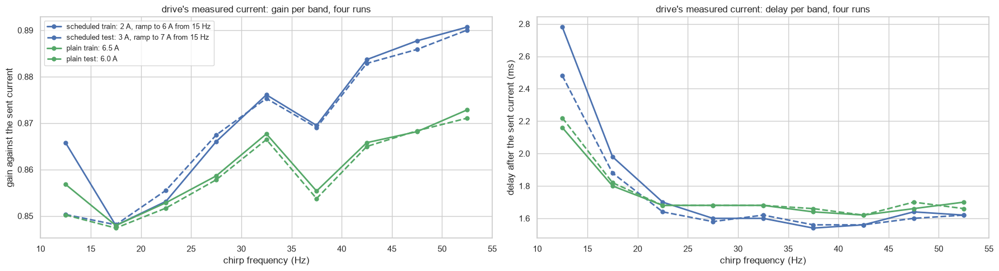

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(18, 5))
f_mid_s = 0.5 * (SENT_BANDS[:-1] + SENT_BANDS[1:])
for key, label, color, ls in RUNS_AMP:
    d_ = RAW_DF[key]
    i_fn, f_fn = sent_current_fn(RAW_LOGS[key])
    t_ = d_["time_s"].to_numpy()
    y_ = d_["actual_current_A"].to_numpy()
    res_ = np.array([delay_gain(t_[m_], y_[m_], i_fn)
                     for lo, hi in zip(SENT_BANDS[:-1], SENT_BANDS[1:])
                     for m_ in [(t_ >= 0) & (f_fn(t_) >= lo) & (f_fn(t_) < hi)]], dtype=float)
    ax[0].plot(f_mid_s, res_[:, 1], "o" + ls, color=color, lw=2, ms=5, label=label)
    ax[1].plot(f_mid_s, res_[:, 0] * 1e3, "o" + ls, color=color, lw=2, ms=5, label=label)
    print(f"{label:48s} measured-current gain at 12.5, 22.5, 52.5 Hz: {res_[0, 1]:.3f}, {res_[2, 1]:.3f}, {res_[-1, 1]:.3f}; "
          f"delay {res_[0, 0] * 1e3:.2f}, {res_[2, 0] * 1e3:.2f}, {res_[-1, 0] * 1e3:.2f} ms")
ax[0].set(xlabel="chirp frequency (Hz)", ylabel="gain against the sent current", title="drive's measured current: gain per band, four runs", xticks=SENT_BANDS)
ax[1].set(xlabel="chirp frequency (Hz)", ylabel="delay after the sent current (ms)", title="drive's measured current: delay per band, four runs", xticks=SENT_BANDS)
ax[0].legend(fontsize=9)
plt.tight_layout(); plt.show()

**Findings (drive or mechanics).**

- **The force loss at small current is not in the drive's current.** At 2 A the drive's measured current is as large, relative to the sent current, as at 6 A (gain 0.85–0.87 in all runs). The current arrives; part of its force is lost afterwards, in the mechanics: friction, cable drag, or a small force that does not scale with the current. This assumes the drive measures its own current correctly.
- **The extra lag of the drive's current below 20 Hz is mostly a frequency effect.** The plain chirps at a constant 6 A show it too (2.2 ms at 12.5 Hz against 1.7 ms above 20 Hz); small currents add a little on top (2.8 ms at 2 A).
- **The drive's gain rises slowly with frequency in every run**, from about 0.85 to 0.87–0.89.
- **All runs show a small dip in the drive's gain (about 1.5 %) at 35–40 Hz, near the laser mode.** The mode may not be purely in the laser path; too small to read more into yet.

**The starting velocity.** Each prediction starts from the measured position and an estimated velocity $\hat v_0 = v_0 + \delta v$. In the damped system a velocity error starts a free response that shifts the position by roughly

$$\delta x \approx \delta v\,\frac{m}{c}$$

before it dies out. At high frequency that can be large next to the motion itself, so the starting velocity may dominate the prediction error in the application band.

**How large is $\delta v$ from the 75 Hz filter, per frequency?** The accelerometer cannot tell: its own lag (about 1.5 ms, 27° at 50 Hz) and gain error (up to 25 %) would swamp an error of a few percent. Instead, per 1 s window of the scheduled chirp (train), from the split into the fundamental and the residual (above):

$$\delta v_\text{rms}^2 \approx \int H(f)^2\,(2\pi f)^2\,P_r(f)\,df \;+\; \big(1 - H(f_c)\big)^2\,\tfrac12\,(2\pi f_c A_1)^2$$

- $P_r$: the residual's spectrum in the window (noise, the laser's distortion included);
- $f_c$, $A_1$: the chirp frequency and the fundamental amplitude in the window;
- $H$: the 75 Hz filter (8th order, zero phase).

Shown: $\delta v_\text{rms}$ relative to the motion's rms velocity, against the chirp frequency. Printed: the implied $\delta x$ relative to the motion's amplitude, with $m/c \approx$ 32 ms as an order of magnitude only (51.5 kg and about 1600 N·s/m; the damping is not identified yet).

10-20 Hz: velocity error 6.6 % of the motion's rms velocity; implied position shift about 12 % of the motion's amplitude
20-35 Hz: velocity error 2.6 % of the motion's rms velocity; implied position shift about 11 % of the motion's amplitude
35-45 Hz: velocity error 3.2 % of the motion's rms velocity; implied position shift about 18 % of the motion's amplitude
45-55 Hz: velocity error 3.9 % of the motion's rms velocity; implied position shift about 28 % of the motion's amplitude


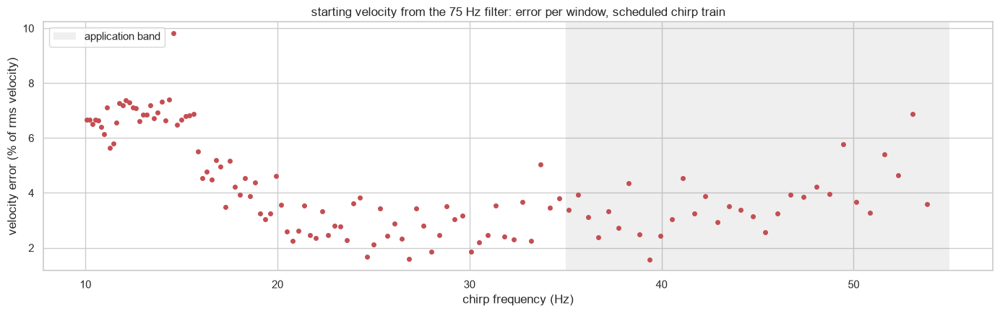

In [23]:
H_lp = lambda f: 1 / (1 + (f / F_LP) ** (2 * ORDER_LP))  # zero-phase gain of the 75 Hz filter
rows_v = []
for t0 in np.arange(0.0, t_m[-1] - WIN_M, WIN_M):        # the same windows as above
    m = (t_m >= t0) & (t_m < t0 + WIN_M)
    tm, tc_ = t_m[m], t_m[m].mean()
    fc_ = f_fn_m(tc_)
    ph = phase_m(tm)
    X = np.column_stack([np.cos(ph), np.sin(ph)] + [(tm - tc_) ** j for j in range(4)])
    q = np.linalg.lstsq(X, x_m[m], rcond=None)[0]
    f_v, P_v = signal.periodogram(x_m[m] - X @ q, fs=FS_RAW, window="hann", detrend=False)
    A1 = np.hypot(q[0], q[1])
    noise_v2 = np.sum(H_lp(f_v) ** 2 * (2 * np.pi * f_v) ** 2 * P_v) * (f_v[1] - f_v[0])
    cut_v2 = (1 - H_lp(fc_)) ** 2 * 0.5 * (2 * np.pi * fc_ * A1) ** 2
    v_rms = 2 * np.pi * fc_ * A1 / np.sqrt(2)
    rows_v.append((fc_, np.sqrt(noise_v2 + cut_v2) / v_rms, np.sqrt(noise_v2 + cut_v2), A1))
fc_v, rel_v, dv_abs, A1_v = np.array(rows_v).T

M_OVER_C = 51.5 / 1600.0                                # s, order of magnitude only
for lo, hi in ((10, 20), (20, 35), (35, 45), (45, 55)):
    b_ = (fc_v >= lo) & (fc_v < hi)
    print(f"{lo}-{hi} Hz: velocity error {np.median(rel_v[b_]) * 100:.1f} % of the motion's rms velocity; "
          f"implied position shift about {np.median(dv_abs[b_] * M_OVER_C / A1_v[b_]) * 100:.0f} % of the motion's amplitude")

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(fc_v, rel_v * 100, "o", ms=4, color="C3")
ax.axvspan(35, 55, color="0.5", alpha=0.12, lw=0, label="application band")
ax.set(xlabel="chirp frequency (Hz)", ylabel="velocity error (% of rms velocity)",
       title="starting velocity from the 75 Hz filter: error per window, scheduled chirp train")
ax.legend()
plt.tight_layout(); plt.show()

**Findings (starting velocity).**

- **The filtered velocity itself is good:** 3–4 % off in the application band (6.6 % at 10–20 Hz, where the laser's harmonics fall inside the passband).
- **Its effect on a prediction grows with frequency.** The implied position shift rises from about 11 % of the motion at 20–35 Hz to about 28 % at 45–55 Hz (an order of magnitude: $m/c$ is not identified yet). The starting velocity can account for a large part of the high-frequency prediction error, also in Model C's validation.

**Decision: a burn-in before every scored prediction.** Instead of starting the simulation exactly at the start point $t_s$, it starts a time $B$ earlier, from the measured position and the filtered velocity there, and only the part from $t_s$ on is scored:

$$\hat{x}(t_s - B) = x(t_s - B), \qquad \hat{v}(t_s - B) = v_\text{filtered}(t_s - B), \qquad \text{simulate from } t_s - B,\ \text{score } t_s \ldots t_s + H$$

```
   t_s - B              t_s                       t_s + H
      |---- burn-in ------|-------- scored ----------|
   start from the        the model's own state
   filtered state        at t_s, not the measured one
```

- **Why it works.** A starting error $\delta v$ causes a free response that dies out with the damping, with a time constant of roughly $2m/c \approx$ 65 ms. After $B$ = 150 ms about $e^{-150/65} \approx 10\,\%$ of it is left, so the scored part is driven by the input current through the model, not by the estimate of the starting velocity.
- **What it changes in the meaning of the score.** At $t_s$ the state is the model's own, after 150 ms of running on the input. The score therefore also includes how well the model follows the motion over those 150 ms: a model with wrong parameters has already drifted a little. That is a fair part of the test, since the application also runs the model on the input; but a score is no longer purely a prediction from a known state.
- **$B$ = 150 ms, the same in the fit and in the standard validation**, so that both measure the same thing.

### The new loader

All decisions of this section in one function, `load_v2(path)`, for any chirp run:

1. **Read the raw log** at 2 kHz, every row (stale rows included: their in-band effect is a 0.2 ms delay, absorbed by $\tau_d$).
2. **Rebuild the sent current** $i_\text{sent}(t)$ from the file name and the firmware formula, and keep it as a function of time, so the simulator can evaluate $i_\text{sent}(t - \tau_d)$ at any RK4 stage.
3. **Remove the 50 Hz pickup** from the laser position: window estimates with all chirp harmonics up to 100 Hz, a constant amplitude and a phase spline, subtracted (section 2).
4. **Low-pass the position** with the 8th-order Butterworth at 75 Hz, zero phase, over the whole log (idle window included, so the run starts without a filter transient) (section 3).
5. **Velocity and acceleration** from the filtered position (section 3).
6. **Keep the run** ($t \geq 0$) **at 1 kHz**: every other sample (section 3).

Returned per run: `t`, `x`, `v`, `a` (m, m/s, m/s²), `f` (chirp frequency), `i` (the sent current at the samples, for plots and the starting-value fit), `i_fn` (the sent current as a function of time), `a_meas` (the accelerometer at its nominal scale, for reference) and `sweep` (the chirp itself, $t < T$).

Not done here: the laser's 34.8 Hz mode and its distortion are left in the data; they are for the measurement equation of the model.

Shown, for the scheduled chirp (train), the old loader (`load`: 50 and 150 Hz notches, `TAU` = 0.65 ms, 100 Hz 4th-order low-pass) against the new one: the position over 50 ms where the chirp passes 50 Hz; and the spectrum of the position, both at 1 kHz.

The loader also reads the older log format of September (no idle window, the duplicate first time stamp at $t$ = 0, no bias-corrected accelerometer: then the accelerometer's run mean is taken as its bias).


chirpsched train: 120000 samples at 1 kHz, t = 0.000 to 119.999 s, x from -5.72 to 4.52 mm
chirpsched test : 120000 samples at 1 kHz, t = 0.000 to 119.999 s, x from -4.39 to 6.47 mm
chirp      train: 120000 samples at 1 kHz, t = 0.000 to 119.999 s, x from -21.97 to 20.04 mm
chirp      test : 120000 samples at 1 kHz, t = 0.000 to 119.999 s, x from -21.19 to 20.02 mm


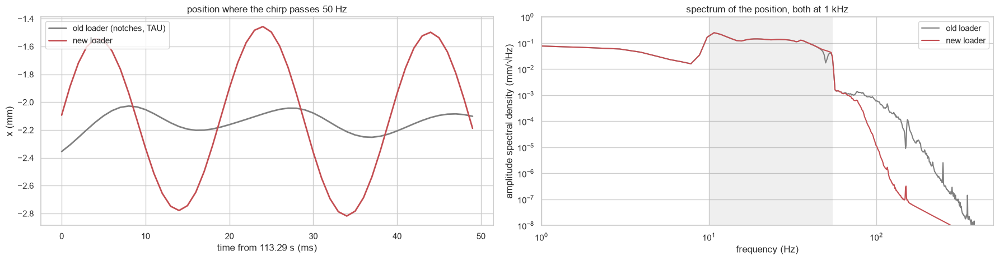

In [24]:
def load_v2(path):
    "Load a chirp run with all processing decisions of this section; returns the run at 1 kHz (see the text above)."
    raw = read_raw(path)
    if raw["time_s"].iloc[1] == raw["time_s"].iloc[0]:
        raw = raw.iloc[1:].reset_index(drop=True)      # the firmware repeats its first time stamp: drop the duplicate
    t = raw["time_s"].to_numpy()
    pos_mm = raw["position_mm"].to_numpy()
    i_fn, f_fn = sent_current_fn(path)
    tc_, A_, th_, _ = pickup_windows(t, pos_mm, path)  # 50 Hz pickup, per window
    p_fn, _ = fit_pickup(tc_, A_, th_)
    x_full = signal.sosfiltfilt(sos_lp, (pos_mm - p_fn(t)) * 1e-3)    # m, pickup removed, 75 Hz low-pass, zero phase
    v_full = np.gradient(x_full, 1 / FS_RAW)            # uniform 0.5 ms rows (the time stamp repeats once at the start)
    a_full = np.gradient(v_full, 1 / FS_RAW)
    keep = np.flatnonzero(t >= 0)[::2]                  # the run, at 1 kHz
    T_ch = float(re.search(r"_[\d.]+to[\d.]+Hz_([\d.]+)s_", path.name).group(1))
    d = dict(t=t[keep], x=x_full[keep], v=v_full[keep], a=a_full[keep], f=f_fn(t[keep]), i=i_fn(t[keep]), i_fn=i_fn,
             a_meas=(raw["ai2_corrected_V"].to_numpy() if "ai2_corrected_V" in raw    # older logs: no idle window, bias = run mean
                     else raw["ai2_value_V"].to_numpy() - raw["ai2_value_V"].mean())[keep] * ACC_M_S2_PER_V, path=path)
    d["sweep"] = d["t"] < T_ch
    return d


NEW = {key: load_v2(path) for key, path in RAW_LOGS.items()}
for key, d_ in NEW.items():
    print(f"{key[0]:10s} {key[1]:5s}: {len(d_['t'])} samples at 1 kHz, t = {d_['t'][0]:.3f} to {d_['t'][-1]:.3f} s, "
          f"x from {d_['x'].min() * 1e3:.2f} to {d_['x'].max() * 1e3:.2f} mm")

old_d = load(RAW_LOGS["chirpsched", "train"])          # the old loader, for comparison
new_d = NEW["chirpsched", "train"]
t50 = new_d["t"][np.argmin(abs(new_d["f"] - 50.0))]   # where the chirp passes 50 Hz
fig, ax = plt.subplots(1, 2, figsize=(18, 4.8))
z_o = (old_d["t"] >= t50) & (old_d["t"] < t50 + 0.05)
z_n = (new_d["t"] >= t50) & (new_d["t"] < t50 + 0.05)
ax[0].plot((old_d["t"][z_o] - t50) * 1e3, old_d["x"][z_o] * 1e3, color="0.5", lw=2, label="old loader (notches, TAU)")
ax[0].plot((new_d["t"][z_n] - t50) * 1e3, new_d["x"][z_n] * 1e3, color="C3", lw=2, label="new loader")
ax[0].set(xlabel=f"time from {t50:.2f} s (ms)", ylabel="x (mm)", title="position where the chirp passes 50 Hz")
ax[0].legend(loc="upper left")
for d_, lab, color in ((old_d, "old loader", "0.5"), (new_d, "new loader", "C3")):
    f_, P_ = signal.welch(d_["x"][d_["t"] >= 0] * 1e3, fs=1000.0, window="hann", nperseg=1024, noverlap=512, detrend="constant")
    ax[1].loglog(f_[1:], np.sqrt(P_[1:]), color=color, lw=1.5, label=lab)
ax[1].axvspan(10, 55, color="0.5", alpha=0.12, lw=0)
ax[1].set(xlim=(1, 500), ylim=(1e-8, 1), xlabel="frequency (Hz)", ylabel="amplitude spectral density (mm/√Hz)",
          title="spectrum of the position, both at 1 kHz")
ax[1].legend()
plt.tight_layout(); plt.show()

## Data

Two experiment types, each with a train and a test run, from `data/train` and `data/test`, loaded with `load_v2` (all decisions of the section above):
- `chirpsched`: chirp 10→55 Hz with amplitude ramps, about ±6 mm. Fitted on the train run (`sweep`, the whole chirp) and judged on the test run.
- `chirp`: plain chirp 1→55 Hz at constant current, up to ±21 mm. Not fitted; kept for later validation.

Per run, at 1 kHz from $t$ = 0: the position with the pickup removed and low-passed at 75 Hz, its velocity and acceleration, the chirp frequency, and the sent current (as samples and as a function of time). The figure shows position and sent current of every run, with the fit window shaded.

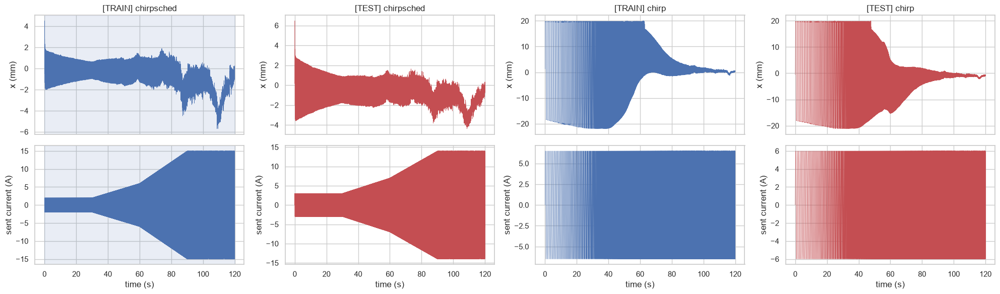

In [25]:
DATA = {exp: {s: NEW[exp, s] for s in ("train", "test")} for exp in ("chirp", "chirpsched")}   # loaded with load_v2 above

# overview: position (top) and sent current (bottom) of every run, TRAIN in blue, TEST in red; shaded: the window the fit uses
SETS = [("TRAIN", "chirpsched", DATA["chirpsched"]["train"], "sweep"),   # fit
        ("TEST", "chirpsched", DATA["chirpsched"]["test"], None),        # validation
        ("TRAIN", "chirp", DATA["chirp"]["train"], None),                # not used yet
        ("TEST", "chirp", DATA["chirp"]["test"], None)]                  # not used yet
fig, ax = plt.subplots(2, len(SETS), figsize=(20, 6), sharex="col")
for col, (role, name, d, band) in enumerate(SETS):
    color = "C0" if role == "TRAIN" else "C3"
    sns.lineplot(x=d["t"], y=d["x"] * 1e3, ax=ax[0, col], lw=0.4, color=color).set(title=f"[{role}] {name}", ylabel="x (mm)")
    sns.lineplot(x=d["t"], y=d["i"], ax=ax[1, col], lw=0.4, color=color).set(xlabel="time (s)", ylabel="sent current (A)")
    if band:
        for a_ in ax[:, col]:
            a_.fill_between(d["t"], 0, 1, where=d[band], transform=a_.get_xaxis_transform(), color=color, alpha=0.12)
plt.tight_layout(); plt.show()

## Simulation

Every model is simulated the same way, following the decisions above:

- **Input:** the sent current through the drive block D1, $i_\text{coil}(t) = i_\text{sent}(t - \tau_d)$, evaluated exactly at each RK4 stage (the sent current is a formula). $\tau_d$ is a model parameter.
- **Integration:** RK4 at $T_s$ = 1 ms, the rate of the data.
- **Burn-in:** each prediction for start index $s$ starts `BURN_IN` = 150 steps earlier, from the measured position and the filtered velocity at $s - B$; only $s \ldots s + H$ is returned:

$$\hat{x}(t_s - B) = x(t_s - B), \qquad \hat{v}(t_s - B) = v(t_s - B), \qquad \text{returned: } \hat{x}(t_s) \ldots \hat{x}(t_s + H)$$

For a rigid-mass force law `Fs(x, u, q)` with parameters `p = [Γ, c, *q]`, the acceleration is $\big(\Gamma\, u - c\,\dot{x} - F_s(x, u, q)\big)/m$, as in the setup's `rollout`.

In [26]:
BURN_IN = 150                                           # steps (1 ms each) simulated before every scored prediction


def rollout_v2(Fs, p, d, s, H, tau_d=0.0, B=BURN_IN, with_burn_in=False):
    "Predicted x at s..s+H, shape (len(s), H+1) (or s-B..s+H with with_burn_in): RK4 at TS from the measured state at s-B, input i_sent(t - tau_d) exact at every stage."
    i_fn = d["i_fn"]
    acc = lambda x, v, t: (p[0] * (u := i_fn(t - tau_d)) - p[1] * v - Fs(x, u, p[2:])) / M
    s = np.asarray(s)
    x, v, t = d["x"][s - B].copy(), d["v"][s - B].copy(), d["t"][s - B].copy()
    out = []
    with np.errstate(all="ignore"):                     # a diverging model gives inf/nan instead of an exception
        for k in range(B + H):
            if k >= B or with_burn_in:
                out.append(x)
            k1x, k1v = v, acc(x, v, t)
            k2x, k2v = v + TS / 2 * k1v, acc(x + TS / 2 * k1x, v + TS / 2 * k1v, t + TS / 2)
            k3x, k3v = v + TS / 2 * k2v, acc(x + TS / 2 * k2x, v + TS / 2 * k2v, t + TS / 2)
            k4x, k4v = v + TS * k3v, acc(x + TS * k3x, v + TS * k3v, t + TS)
            x = x + TS / 6 * (k1x + 2 * k2x + 2 * k3x + k4x)
            v = v + TS / 6 * (k1v + 2 * k2v + 2 * k3v + k4v)
            t = t + TS
        out.append(x)
    return np.stack(out, axis=1)


# self-check: without input, a linear spring from x = 1 mm (no burn-in) must follow cos(wt)
_k = 1e5
_d = dict(t=np.arange(1000) * TS, x=np.full(1000, 1e-3), v=np.zeros(1000), i_fn=lambda t: 0.0 * t)
_x = rollout_v2(lambda x, u, q: q[0] * x, [0.0, 0.0, _k], _d, np.array([0]), 900, B=0)[0]
assert np.allclose(_x, 1e-3 * np.cos(np.sqrt(_k / M) * TS * np.arange(901)), atol=1e-8)

## Standard validation

Every model in this notebook is checked with the same call, `validate(name, predict)`, so results stay comparable from step to step.

**Interface.** `predict(d, s, H)` returns the predicted position, shape (len(s), H+1), for the run `d` at the start indices `s`, after the burn-in of `BURN_IN` = 150 ms (section Simulation). Any model fits this interface, whatever its states or simulator. For a force law on the rigid mass, `predict = lambda d, s, H: rollout_v2(Fs, p, d, s, H, tau_d)`. Starts closer than `BURN_IN` to the beginning of the run are left out.

**Data.** The scheduled chirp, train and test, over the whole sweep (10–55 Hz). The test run is never used in a fit.

**What it shows.**
1. Position NRMSE against horizon, 1 to `VAL_H` = 1000 steps, normalised by the std of $x$ over the sweep.
2. NRMSE per 5 Hz band of the chirp frequency, at `VAL_K` = 10 and 100 steps ahead. Each band is normalised by the std of $x$ in that band, so the small motion at high frequency is judged on its own scale:
$$\mathrm{NRMSE}_b(k) = \frac{\sqrt{\frac{1}{N_b}\sum_{s \in b}\left(\hat{x}_{s+k\mid s} - x_{s+k}\right)^2}}{\operatorname{std}_b(x)}$$
   - 10 steps (10 ms): about half a period at 50 Hz, mostly the local gain and phase;
   - 100 steps (0.1 s): 1 to 5.5 periods over 10–55 Hz, where errors have had time to build up.
3. **Offset-free:** the same per-band error over the whole `VAL_HP_H` = 100 ms window of each prediction, with that prediction's best-fitting straight line (offset $\alpha_s$ and slope $\beta_s$) removed from its error:
$$\mathrm{NRMSE}^{\text{hp}}_b = \frac{\sqrt{\frac{1}{N_b}\sum_{s \in b} \frac{1}{H}\sum_{k=1}^{H} \big(e_{s,k} - \alpha_s - \beta_s k\big)^2}}{\operatorname{std}_b(x)}, \qquad e_{s,k} = \hat{x}_{s+k\mid s} - x_{s+k}$$
   What remains is the error in the oscillation itself (amplitude and phase); what is removed is the slow part, mostly below about 5 Hz. Side by side with panel 2, it shows how much of the error is the dynamics in the band and how much a slow offset.
4. Example predictions on the test run, `VAL_TRACE_H` = 100 steps after the burn-in, starting where the chirp passes `VAL_TRACE_F` = 20, 40 and 50 Hz.

The shaded span is the application band, 35–55 Hz. Every result is stored in `RESULTS[name]`. With `ref=<earlier name>`, that model's test results are drawn as a grey dashed line. With `table=True`, the numbers behind the plots are printed as well.

**Colours:** measured in black; the model being validated in red (test solid, train faint); the reference model in grey. The same in the free-run validation.


In [27]:
VAL_H = 1000                                            # steps, horizon of the NRMSE curve
VAL_EDGES = np.arange(10.0, 55.0 + 1e-9, 5.0)          # Hz, band edges of the per-frequency error
VAL_K = (10, 100)                                       # steps ahead at which the per-band error is read
VAL_HP_H = 100                                          # steps, window of the offset-free per-band error
VAL_TRACE_F = (20.0, 40.0, 50.0)                        # Hz, chirp frequency where the example predictions start
VAL_TRACE_H = 100                                       # steps, length of the example predictions
APP_BAND = (35.0, 55.0)                                 # Hz, application band
RESULTS = {}                                            # name -> predict and its metrics, for later comparison
# one colour per role, in every validation figure: measured black, the validated model red (test solid, train faint), the reference grey
STYLE = {"test": dict(color="C3", lw=2), "train": dict(color="C3", lw=1.5, alpha=0.4)}
REF = dict(color="0.5", lw=1.5)


def horizon_nrmse(predict, d, band, H):
    "Position NRMSE per horizon step 1..H over the starts in band, normalised by the std of x in band."
    s = starts(d, band, H)
    s = s[s >= BURN_IN]                                 # room for the burn-in
    e = predict(d, s, H) - target(d, s, H)
    return np.sqrt(np.mean(e[:, 1:] ** 2, axis=0)) / np.std(d["x"][band])


def band_nrmse(predict, d, edges, ks, H_hp=VAL_HP_H):
    "Per chirp-frequency band: NRMSE at each horizon in ks, and the offset-free NRMSE over H_hp steps (line removed per prediction)."
    H = max(max(ks), H_hp)
    out = np.full((len(edges) - 1, len(ks)), np.nan)
    out_hp = np.full(len(edges) - 1, np.nan)
    kk = np.arange(1, H_hp + 1)
    L = np.column_stack([np.ones_like(kk), kk]).astype(float)   # offset and slope over the window
    proj = L @ np.linalg.pinv(L)                        # projection onto the straight lines
    for j, (lo, hi) in enumerate(zip(edges[:-1], edges[1:])):
        band = d["sweep"] & (d["f"] >= lo) & (d["f"] < hi)
        s = starts(d, band, H)
        s = s[s >= BURN_IN]                             # room for the burn-in
        if len(s):
            e = predict(d, s, H) - target(d, s, H)
            out[j] = np.sqrt(np.mean(e[:, list(ks)] ** 2, axis=0)) / np.std(d["x"][band])
            e_w = e[:, 1:H_hp + 1]
            out_hp[j] = np.sqrt(np.mean((e_w - e_w @ proj.T) ** 2)) / np.std(d["x"][band])
    return out, out_hp


def validate(name, predict, runs=None, ref=None, table=False):
    "Standard validation of one model on the scheduled chirp (train and test); stores the result in RESULTS[name]. table=True also prints the numbers."
    runs = runs if runs is not None else DATA["chirpsched"]
    bands = {sp: band_nrmse(predict, d, VAL_EDGES, VAL_K) for sp, d in runs.items()}
    res = dict(predict=predict, runs=runs,
               curve={sp: horizon_nrmse(predict, d, d["sweep"], VAL_H) for sp, d in runs.items()},
               bands={sp: b[0] for sp, b in bands.items()}, bands_hp={sp: b[1] for sp, b in bands.items()})
    RESULTS[name] = res
    R = RESULTS[ref] if ref else None

    fig = plt.figure(figsize=(22, 8.5))
    gs = fig.add_gridspec(2, 12)
    ax_h = fig.add_subplot(gs[0, 0:3])
    ax_b = [fig.add_subplot(gs[0, 3:6]), fig.add_subplot(gs[0, 6:9])]
    ax_hp = fig.add_subplot(gs[0, 9:12])
    ax_t = [fig.add_subplot(gs[1, 4 * j:4 * j + 4]) for j in range(3)]
    # 1. NRMSE against horizon
    k = np.arange(1, VAL_H + 1)
    for sp in ("train", "test"):
        ax_h.plot(k, res["curve"][sp], **STYLE[sp], label=f"{name}, {sp}")
    if R:
        ax_h.plot(k, R["curve"]["test"], **REF, label=f"{ref}, test")
    ax_h.set(xscale="log", xlabel="steps ahead (1 step = 1 ms)", ylabel="position NRMSE (sweep)", title="NRMSE against horizon")
    ax_h.legend(fontsize=8)
    # 2. NRMSE per frequency band at each horizon in VAL_K, and 3. offset-free
    f_mid = 0.5 * (VAL_EDGES[:-1] + VAL_EDGES[1:])
    panels = [(ax_b[col], lambda r, sp, col=col: r["bands"][sp][:, col], f"per band, {kk} steps ({kk} ms) ahead")
              for col, kk in enumerate(VAL_K)]
    panels.append((ax_hp, lambda r, sp: r["bands_hp"][sp], f"per band, offset-free, over {VAL_HP_H} ms"))
    for a_, get, title in panels:
        a_.axvspan(*APP_BAND, color="0.5", alpha=0.12, lw=0, label="application band")
        for sp in ("train", "test"):
            a_.plot(f_mid, get(res, sp), marker="o", ms=5, **STYLE[sp], label=f"{name}, {sp}")
        if R and "bands_hp" in R:
            a_.plot(f_mid, get(R, "test"), marker="o", ms=5, **REF, label=f"{ref}, test")
        a_.set(xlabel="chirp frequency (Hz)", ylabel="position NRMSE (per band)", xticks=VAL_EDGES[::2], title=title)
    ax_b[0].legend(fontsize=8)
    # 4. example predictions on the test run, from the first sample where the chirp reaches each VAL_TRACE_F
    d = runs["test"]
    for a_, f0 in zip(ax_t, VAL_TRACE_F):
        s0 = np.array([np.flatnonzero(d["sweep"] & (d["f"] >= f0))[0]])
        t = (d["t"][s0[0]:s0[0] + VAL_TRACE_H + 1] - d["t"][s0[0]]) * 1e3
        a_.plot(t, target(d, s0, VAL_TRACE_H)[0] * 1e3, color="k", lw=2, label="measured")
        a_.plot(t, predict(d, s0, VAL_TRACE_H)[0] * 1e3, **STYLE["test"], label=name)
        if R:
            a_.plot(t, R["predict"](d, s0, VAL_TRACE_H)[0] * 1e3, **REF, label=ref)
        a_.set(xlabel="time from start (ms)", ylabel="x (mm)", title=f"test: prediction after the burn-in, at {f0:.0f} Hz")
    ax_t[0].legend(fontsize=8)
    fig.suptitle(f"Validation: {name}" + (f" (grey: {ref})" if ref else ""))
    plt.tight_layout(); plt.show()

    if not table:
        return
    # table: horizon NRMSE over the sweep, then NRMSE per band (at VAL_K, and offset-free)
    print("NRMSE at k = 10, 100, 1000 (sweep): " + "; ".join(
        f"{sp} " + ", ".join(f"{res['curve'][sp][j - 1]:.3f}" for j in (10, 100, 1000)) for sp in runs))
    cols = [(name, sp) for sp in runs] + ([(ref, "test")] if R else [])
    print(f"{'band (Hz)':10s}" + "".join(f"{(n[:20] + ' ' + sp):>33s}" for n, sp in cols))
    print(f"{'':10s}" + "".join(f"{'k=' + str(VAL_K[0]):>11s}{'k=' + str(VAL_K[1]):>11s}{'hp':>11s}" for _ in cols))
    for j in range(len(VAL_EDGES) - 1):
        vals = [(RESULTS[n]["bands"][sp][j], RESULTS[n]["bands_hp"][sp][j]) for n, sp in cols]
        print(f"{VAL_EDGES[j]:4.0f}-{VAL_EDGES[j + 1]:<5.0f}" + "".join(f"{v[0]:11.3f}{v[1]:11.3f}{h:11.3f}" for v, h in vals))

## Model C: unequal magnets with a position-dependent motor constant, LLS

The baseline from the previous notebook, refitted on the new data. The moving mass is one rigid body on an air bearing, driven by the motor and held by two repelling end magnets:

$$m\ddot{x} = (\Gamma + \Gamma_1 x)\, i - c\,\dot{x} - \left(\frac{C_R}{(g_0 - x)^3} - \frac{C_L}{(g_0 + x)^3}\right)$$

- $m$: the moving mass, 51.5 kg;
- $\Gamma + \Gamma_1 x$: the motor constant, linear in position;
- $c$: viscous damping;
- $C_R, C_L \geq 0$: the strengths of the two magnets, at the measured gap $g_0$ = `G00` = 22.3 mm. Each magnet always repels, so the net spring always restores and stiffens with stroke. $C_R \neq C_L$ gives the asymmetry.

With the gap fixed, the model is linear in all five parameters $\Gamma, c, \Gamma_1, C_R, C_L$.

**Fit.** Weighted, bounded linear least squares on the force equation (equation error), on the train sweep:

$$\hat{\theta} = \arg\min_{\theta} \left\| W\left(\Phi\,\theta - m\ddot{x}\right) \right\|^2, \qquad c,\, C_R,\, C_L \geq 0$$

$W = \mathrm{diag}\big(1/|\mathcal{H}\{i\}|\big)$ is the inverse current amplitude (Hilbert envelope), so every part of the amplitude-ramped sweep counts about equally.

**Input.** The sent current, with no drive delay yet ($\tau_d$ = 0): Model C as it was, only on the new data. The drive block D1 is the next step.

**Comparison.** The same fit on the data of the old loader (`load`: notches, `TAU`, 100 Hz low-pass, the target readback as input) gives the old Model C. Both are validated the same way (section Simulation, standard validation), so the difference is the processing alone.

In [28]:
def fit_model_C(d, return_cost=False):
    "Model C by weighted, bounded linear least squares on the force equation, on the sweep of run d; returns [Gamma, c, Gamma1, C_R, C_L] (and the rms weighted residual)."
    sel = d["sweep"]
    x, i, v = d["x"][sel], d["i"][sel], d["v"][sel]
    w = 1 / np.abs(signal.hilbert(d["i"]))[sel]                      # 1 / current amplitude, so every part of the sweep counts about equally
    cols = {"Gamma": i, "c": -v, "Gamma1": x * i, "C_R": -1 / (G00 - x)**3, "C_L": 1 / (G00 + x)**3}   # m a = (Gamma + Gamma1 x) i - c v - (C_R / (g0 - x)^3 - C_L / (g0 + x)^3)
    A = np.column_stack(list(cols.values()))
    lb = [-np.inf if n in ("Gamma", "Gamma1") else 0.0 for n in cols]   # c, C_R, C_L >= 0
    sc = np.linalg.norm(A * w[:, None], axis=0)                      # column scaling
    p = lsq_linear(A * w[:, None] / sc, M * d["a"][sel] * w, bounds=(lb, np.inf)).x / sc
    return (p, np.sqrt(np.mean(((A @ p - M * d["a"][sel]) * w) ** 2))) if return_cost else p


p_C_old = fit_model_C(old_d)                            # old loader (notches, TAU, 100 Hz, target readback), scheduled chirp train
p_C = fit_model_C(DATA["chirpsched"]["train"])          # new loader
G, c, G1, C_R, C_L = p_C
print("old processing: Gamma = {:.1f} N/A, c = {:.1f} N s/m, Gamma1 = {:.4g} N/(A m), C_R = {:.4g}, C_L = {:.4g} N m^3".format(*p_C_old))
print("new processing: ", end="")
magnets = lambda x, u, q: q[1] / (G00 - x)**3 - q[2] / (G00 + x)**3 - q[0] * x * u   # magnets, minus Gamma1 x i so the motor force is (Gamma + Gamma1 x) i
print(f"Gamma = {G:.1f} N/A, c = {c:.1f} N s/m; Gamma1 = {G1:.4g} N/(A m); C_R = {C_R:.4g} N m^3, C_L = {C_L:.4g} N m^3 "
      f"(C_R / C_L = {C_R / C_L:.3f}; PDF guess C_mu = {CMU0} N m^2)")
print(f"stiffness at x = 0: {3 * (C_R + C_L) / G00**4:.3g} N/m, force at x = 0: {(C_R - C_L) / G00**3:.3g} N")   # dF/dx = 3 C_R / (g0 - x)^4 + 3 C_L / (g0 + x)^4
print("Gamma(x)/Gamma at -5, +5 mm: " + ", ".join(f"{1 + G1 * xx / G:.3f}" for xx in (-5e-3, 5e-3)))

old processing: Gamma = 200.9 N/A, c = 1586.3 N s/m, Gamma1 = 3573 N/(A m), C_R = 0.001604, C_L = 0.001574 N m^3
new processing: Gamma = 175.3 N/A, c = 220.1 N s/m; Gamma1 = -1089 N/(A m); C_R = 0.002985 N m^3, C_L = 0.002819 N m^3 (C_R / C_L = 1.059; PDF guess C_mu = 2.423 N m^2)
stiffness at x = 0: 7.04e+04 N/m, force at x = 0: 15 N
Gamma(x)/Gamma at -5, +5 mm: 1.031, 0.969


### Model C: validation

The old Model C (fitted on the old loader's data) first, then the Model C refitted on the new data, with the old one as reference. Both are validated on the new data, with the new simulator and the burn-in; the input is the sent current, without drive delay.

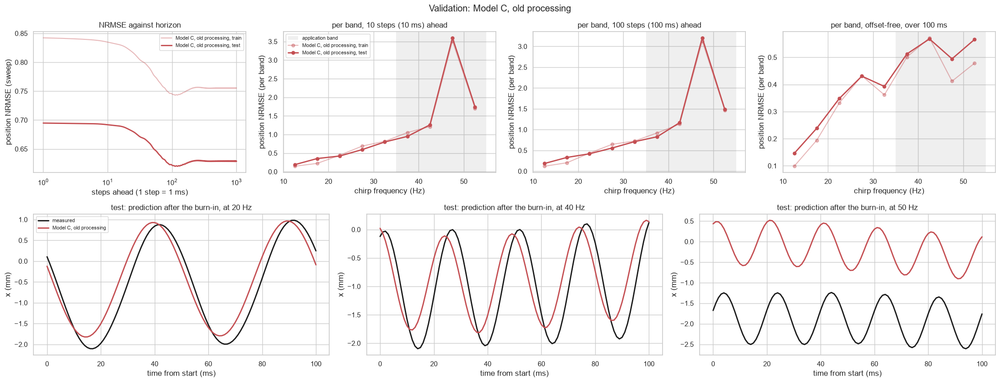

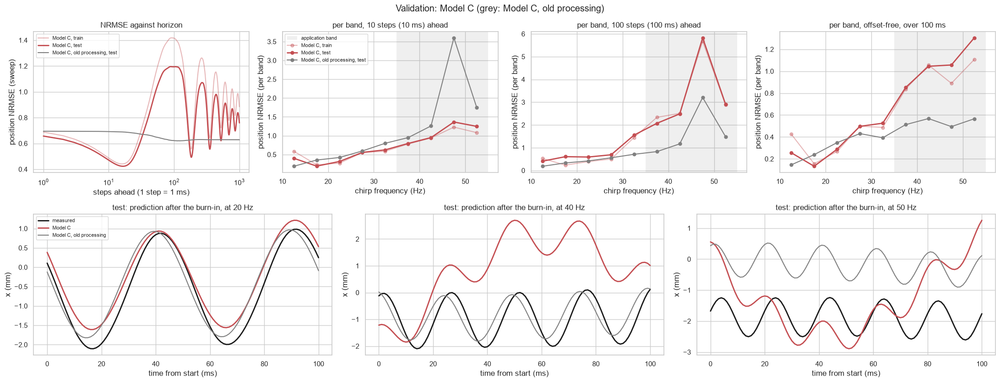

In [29]:
validate("Model C, old processing", lambda d, s, H: rollout_v2(magnets, p_C_old, d, s, H))
validate("Model C", lambda d, s, H: rollout_v2(magnets, p_C, d, s, H), ref="Model C, old processing")

**Findings (Model C on the new data, no drive delay).**

- **Without a drive delay the damping collapses,** from 1586 to 220 N·s/m. The new input, the sent current, comes 1–3 ms before the force; the fit absorbs that delay as a negative damping $m\omega^2\tau$. The old data hid it: its input was the target readback, already 1.16 ms late, and its position was shifted by `TAU`.
- **So this model rings.** With $c$ = 220 a starting error decays in about $2m/c \approx$ 470 ms, which the 150 ms burn-in cannot absorb: the horizon curve oscillates at the spring resonance (about 6 Hz), and the predictions drift on a slow swing.
- **The drive delay is not optional with the sent current as input.** Next: Model C with the drive block D1.

## Model C with the drive delay (D1)

Model C on the new data, with the input through the drive block D1: the coil current is the sent current, delayed by $\tau_d$,

$$m\ddot{x} = (\Gamma + \Gamma_1 x)\, i_\text{sent}(t - \tau_d) - c\,\dot{x} - \left(\frac{C_R}{(g_0 - x)^3} - \frac{C_L}{(g_0 + x)^3}\right)$$

$\tau_d$ collects every delay between the sent current and the measured position: the drive (about 1.2 ms for the readback, about 1.6 ms for the drive's measured current), the stale rows (about 0.2 ms) and the laser's own path.

**Fit.** For a fixed $\tau_d$ the model is linear in its five parameters, so the same weighted least-squares fit is run for every $\tau_d$ on a grid (`TAU_D_GRID`, 0–5 ms in 0.05 ms steps), with $i_\text{sent}(t - \tau_d)$ evaluated exactly. The $\tau_d$ with the smallest weighted residual is the fit. Shown: the residual against $\tau_d$, and how $\Gamma$, $c$ and the stiffness at $x = 0$ change with it.

best drive delay tau_d = 2.95 ms
Model C + D1: Gamma = 225.7 N/A, c = 2677.0 N s/m, Gamma1 = -890.1 N/(A m), C_R = 0.0006609, C_L = 0.0006098 N m^3; stiffness at x = 0: 1.54e+04 N/m


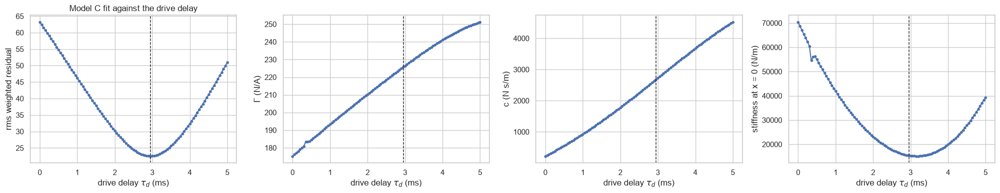

In [30]:
TAU_D_GRID = np.arange(0.0, 5.0 + 1e-9, 0.05) * 1e-3   # s, drive delays tried

d_tr = DATA["chirpsched"]["train"]
scan = []
for tau_ in TAU_D_GRID:
    d_del = dict(d_tr, i=d_tr["i_fn"](d_tr["t"] - tau_))   # the run with the delayed sent current as input
    p_, cost_ = fit_model_C(d_del, return_cost=True)
    scan.append((tau_, cost_, *p_))
scan = np.array(scan)
j_best = np.argmin(scan[:, 1])
tau_D1, p_D1 = scan[j_best, 0], scan[j_best, 2:]
k_lin_ = lambda p_: 3 * (p_[3] + p_[4]) / G00 ** 4      # N/m, stiffness at x = 0
print(f"best drive delay tau_d = {tau_D1 * 1e3:.2f} ms")
print("Model C + D1: Gamma = {:.1f} N/A, c = {:.1f} N s/m, Gamma1 = {:.4g} N/(A m), C_R = {:.4g}, C_L = {:.4g} N m^3".format(*p_D1)
      + f"; stiffness at x = 0: {k_lin_(p_D1):.3g} N/m")

fig, ax = plt.subplots(1, 4, figsize=(20, 4))
for a_, y_, lab in ((ax[0], scan[:, 1], "rms weighted residual"), (ax[1], scan[:, 2], "Γ (N/A)"),
                    (ax[2], scan[:, 3], "c (N s/m)"), (ax[3], [k_lin_(r[2:]) for r in scan], "stiffness at x = 0 (N/m)")):
    a_.plot(scan[:, 0] * 1e3, y_, "o-", ms=3, color="C0")
    a_.axvline(tau_D1 * 1e3, color="k", ls="--", lw=1)
    a_.set(xlabel="drive delay $\\tau_d$ (ms)", ylabel=lab)
ax[0].set_title("Model C fit against the drive delay")
plt.tight_layout(); plt.show()

### Model C with the drive delay: validation

Validated with the delay in the simulator, $i_\text{sent}(t - \tau_d)$, against the old Model C.

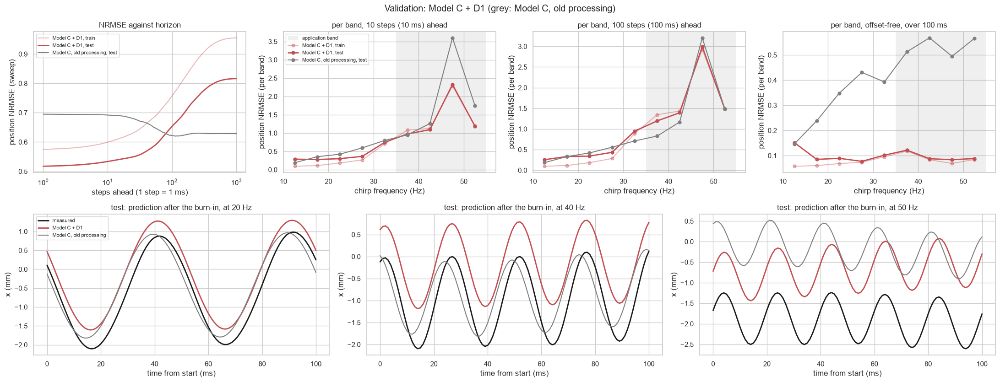

In [31]:
validate("Model C + D1", lambda d, s, H: rollout_v2(magnets, p_D1, d, s, H, tau_d=tau_D1), ref="Model C, old processing")

**Findings (Model C with the drive delay).**

- **The fitted drive delay is 2.95 ms, a clear minimum.** It matches what was known: 1.16 ms from the sent current to the drive's readback, plus the 1.75 ms the previous notebook found between that readback and the laser. Of the latter, about 0.45 ms is the drive's measured current and 0.2 ms the stale rows; about 1.1 ms lies in the laser path or in how the force builds up, which this data cannot separate.
- **With the delay, the model has a weaker spring and more damping** than the old Model C: stiffness 1.5·10⁴ against 3.9·10⁴ N/m, damping 2677 against 1586 N·s/m, Γ 226 against 201 N/A. The position-error fits of the previous notebook found the same pattern.
- **Short predictions are clearly better.** Test NRMSE at 1 ms ahead 0.52 against 0.70; at 10 ms ahead lower in almost every band, also at the top of the band (45–50 Hz: 2.3 against 3.6).
- **At 100 ms about equal, over 1 s worse** (0.82 against 0.63).
- **The phase and shape of the motion now match; a slow offset remains.** In the examples at 20, 40 and 50 Hz the predicted oscillation lines up with the measured one, but sits 0.5–1 mm off. Where the motion is small (near 50 Hz) that offset dominates the error.
- **The offset may be physical.** The nonlinear terms turn the fast oscillation into a steady force (for example $\Gamma_1 x\, i$ has a constant part when position and current oscillate together); if they are slightly off, the predicted offset drifts from the measured one. A hypothesis, not tested.

**Findings (offset-free error).**

- **Model C with the drive delay gets the oscillation right in the whole band.** With the slow offset of each prediction removed, its error is about 8–12 % of the motion in every band, the application band included: four to six times better than the old Model C (0.49–0.57 in the application band).
- **Nearly all of its remaining error is the slow offset.** The errors of 1–3 per band at 10 and 100 ms ahead are almost entirely that offset; the examples show the same: shape and phase line up, the level does not.
- **Without the drive delay the dynamics are wrong too.** That model's offset-free error rises to about 1 in the band: the delay is the key ingredient for the high-frequency dynamics.
- **Next: the slow offset.** Either the model produces the wrong slow motion (its nonlinear terms turn the oscillation into a steady force), or the slow motion is not caused by the input at all (for example drift in the laser or its mount). The first calls for a better force law, the second for treating it as a disturbance.

## The slow offset

The remaining error of Model C + D1 is a slow offset between prediction and measurement. Is it motion the model should produce from the input, or something else?

**Comparison.** Model C + D1 is simulated once over each whole run (scheduled chirp, train and test), from the measured state at the start, with the sent current through the drive delay. The slow part of the prediction and of the measured position is taken with the same zero-phase low-pass (`F_SLOW` = 8 Hz, 4th-order Butterworth):

- the prediction follows the measured slow motion in shape, but with a different size or level: the model produces it, but its force law is slightly off;
- the measured slow motion does things the prediction never does: it is not caused by the input, and has to be treated as a disturbance.

Shown: the slow part of the measured and the predicted position against time, per run. Printed: their rms, correlation and the rms of their difference.

train: slow part rms, measured 0.92 mm, predicted 0.16 mm; correlation -0.48; rms difference 1.18 mm; means -0.69 / -0.07 mm


test : slow part rms, measured 0.66 mm, predicted 0.12 mm; correlation -0.26; rms difference 1.03 mm; means -0.80 / -0.05 mm


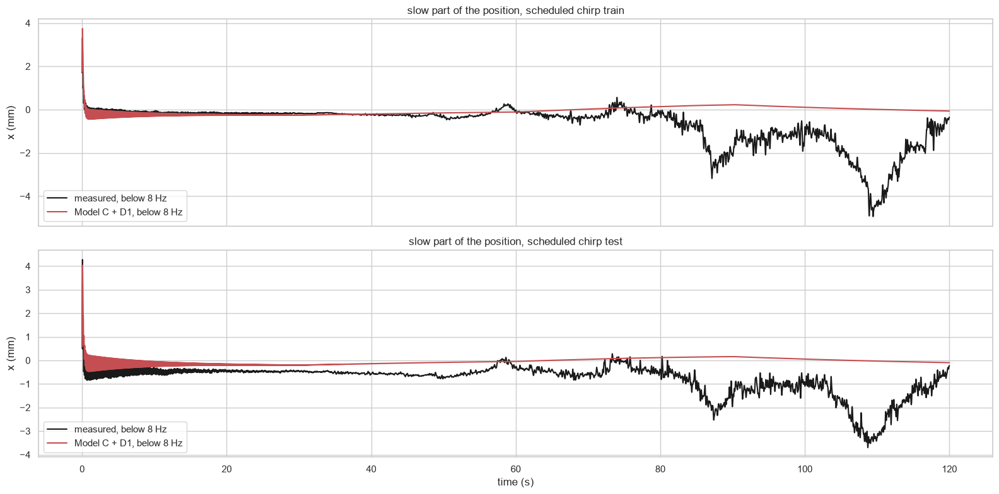

In [32]:
F_SLOW = 8.0                                            # Hz, low-pass for the slow part
sos_slow = signal.butter(4, F_SLOW / 500.0, output="sos")   # at 1 kHz

fig, ax = plt.subplots(2, 1, figsize=(16, 8), sharex=True)
for a_, sp in zip(ax, ("train", "test")):
    d_ = DATA["chirpsched"][sp]
    n_ = len(d_["t"]) - 1
    x_sim = rollout_v2(magnets, p_D1, d_, np.array([0]), n_, tau_d=tau_D1, B=0)[0]   # the whole run, from the measured start
    slow_meas = signal.sosfiltfilt(sos_slow, d_["x"])
    slow_sim = signal.sosfiltfilt(sos_slow, x_sim)
    keep_ = d_["t"] >= 1.0                              # leave out the start-up second
    print(f"{sp:5s}: slow part rms, measured {np.std(slow_meas[keep_]) * 1e3:.2f} mm, predicted {np.std(slow_sim[keep_]) * 1e3:.2f} mm; "
          f"correlation {np.corrcoef(slow_meas[keep_], slow_sim[keep_])[0, 1]:.2f}; "
          f"rms difference {np.sqrt(np.mean((slow_meas[keep_] - slow_sim[keep_]) ** 2)) * 1e3:.2f} mm; "
          f"means {np.mean(slow_meas[keep_]) * 1e3:.2f} / {np.mean(slow_sim[keep_]) * 1e3:.2f} mm")
    a_.plot(d_["t"], slow_meas * 1e3, color="k", lw=1.5, label="measured, below 8 Hz")
    a_.plot(d_["t"], slow_sim * 1e3, color="C3", lw=1.5, label="Model C + D1, below 8 Hz")
    a_.set(ylabel="x (mm)", title=f"slow part of the position, scheduled chirp {sp}")
    a_.legend(loc="lower left")
ax[-1].set_xlabel("time (s)")
plt.tight_layout(); plt.show()

**Locked to frequency, and pushed by the current?** In both scheduled runs the measured slow motion dips at the same moments, about 87 s and 110 s, where the chirp is at about 34.4 Hz (the laser mode is at 34.8 Hz) and about 47.7 Hz. Two checks, model-free:

1. **The slow part of the position against the chirp frequency, all four runs.** The plain chirps pass the same frequencies at other times (34.4 Hz at about 106 s, 47.7 Hz at about 116 s) and at a constant current. Dips at the same frequencies in all runs mean the slow motion is locked to the frequency, as a resonance would be.
2. **The slow part of the drive's measured current, the same runs.** If it has a slow component that matches the dips, the mass is pushed by the current. If it is clean, the cause sits after the current: a missing nonlinearity, or the laser and its mount moving rather than the mass. For scale: with the stiffness of Model C + D1 (about 1.5·10⁴ N/m), a 3 mm shift takes a steady force of about 45 N, a slow current of about 0.2 A.

Both use the same 8 Hz low-pass (zero phase), and start at a chirp frequency of 12 Hz: below that, the plain chirps' own fundamental would pass the filter.

scheduled train: 2 A, ramp to 6 A from 15 Hz     at 34.4 Hz: slow position -2.17 mm, slow measured current -0.012 A
scheduled train: 2 A, ramp to 6 A from 15 Hz     at 47.7 Hz: slow position -4.42 mm, slow measured current -0.029 A
scheduled test: 3 A, ramp to 7 A from 15 Hz      at 34.4 Hz: slow position -1.89 mm, slow measured current -0.008 A
scheduled test: 3 A, ramp to 7 A from 15 Hz      at 47.7 Hz: slow position -3.20 mm, slow measured current +0.008 A
plain train: 6.5 A                               at 34.4 Hz: slow position +0.56 mm, slow measured current -0.001 A
plain train: 6.5 A                               at 47.7 Hz: slow position -0.48 mm, slow measured current +0.011 A
plain test: 6.0 A                                at 34.4 Hz: slow position -0.90 mm, slow measured current +0.007 A
plain test: 6.0 A                                at 47.7 Hz: slow position -1.71 mm, slow measured current +0.008 A


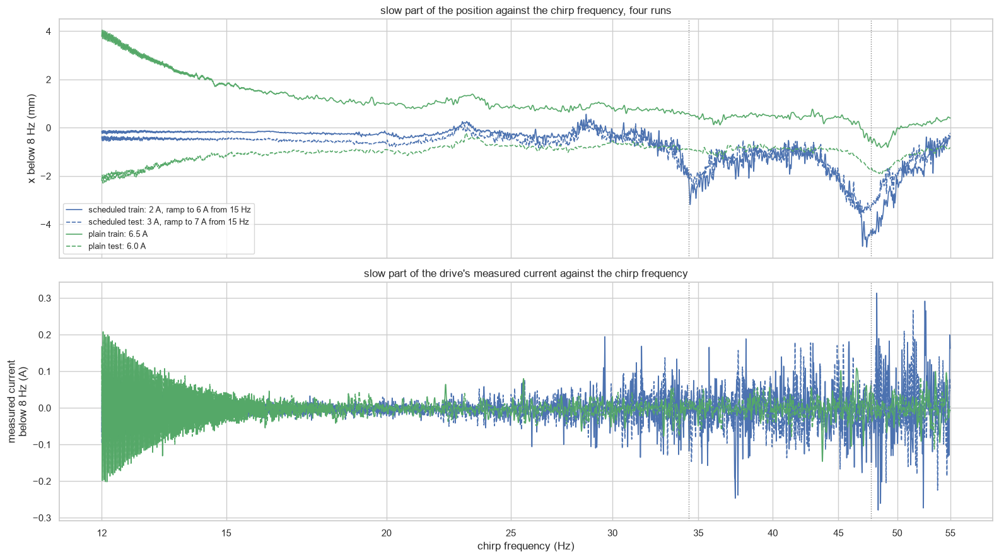

In [33]:
sos_slow_2k = signal.butter(4, F_SLOW / (FS_RAW / 2), output="sos")   # the same 8 Hz low-pass, at 2 kHz
F_MIN_SLOW = 12.0                                       # Hz, chirp frequencies shown from here

fig, ax = plt.subplots(2, 1, figsize=(16, 9), sharex=True)
for key, label, color, ls in RUNS_AMP:
    d_ = DATA[key[0]][key[1]]
    sel_ = d_["f"] >= F_MIN_SLOW
    ax[0].plot(d_["f"][sel_], signal.sosfiltfilt(sos_slow, d_["x"])[sel_] * 1e3, ls, color=color, lw=1.2, label=label)
    raw_ = RAW_DF[key]
    t_ = raw_["time_s"].to_numpy()
    _, f_fn_ = sent_current_fn(RAW_LOGS[key])
    run_ = (t_ >= 0) & (f_fn_(t_) >= F_MIN_SLOW)
    i_slow = signal.sosfiltfilt(sos_slow_2k, raw_["actual_current_A"].to_numpy())
    ax[1].plot(f_fn_(t_[run_]), i_slow[run_], ls, color=color, lw=1.2, label=label)
    for f_dip in (34.4, 47.7):
        near = run_ & (np.abs(f_fn_(t_) - f_dip) < 0.5)
        print(f"{label:48s} at {f_dip} Hz: slow position {np.mean(signal.sosfiltfilt(sos_slow, d_['x'])[np.abs(d_['f'] - f_dip) < 0.5]) * 1e3:+.2f} mm, "
              f"slow measured current {np.mean(i_slow[near]):+.3f} A")
for a_ in ax:
    for f_dip in (34.4, 47.7):
        a_.axvline(f_dip, color="0.5", ls=":", lw=1)
ax[0].set(ylabel="x below 8 Hz (mm)", title="slow part of the position against the chirp frequency, four runs")
ax[1].set(ylabel="measured current\nbelow 8 Hz (A)", xlabel="chirp frequency (Hz)", xscale="log",
          title="slow part of the drive's measured current against the chirp frequency")
ax[1].set_xticks([12, 15, 20, 25, 30, 35, 40, 45, 50, 55]); ax[1].get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax[0].legend(fontsize=9, loc="lower left")
plt.tight_layout(); plt.show()

**Findings (slow offset).**

- **Model C + D1 produces almost none of the measured slow motion.** Its slow part is nearly flat (rms 0.12–0.16 mm against 0.66–0.92 mm measured), uncorrelated with the measurement.
- **The measured slow motion is locked to the chirp frequency.** All four runs dip at about 34.5 Hz and about 47.5 Hz, although the plain chirps pass those frequencies at other times.
- **The dips grow with the current:** 2–4 mm at 14–15 A (scheduled runs), about 1 mm at 6 A (plain chirps).
- **The current does not push the mass there.** The drive's measured current has no slow component at the dips (at most about 0.03 A, against the roughly 0.2 A a 3–4 mm shift would need).
- **The actuator's nonlinear terms are far too weak to cause it.** The strongest, $\Gamma_1 x\, i$, gives about $\tfrac12 |\Gamma_1| X I \approx$ 4 N at 47 Hz and 15 A, against 60 N or more for a 4 mm shift.
- **So the cause most likely sits outside the actuator:** the laser, its mount or the frame shifting slowly when the structure is shaken at its resonances (34.5 Hz is the laser mode found before; 47.5 Hz would be a second structural mode). The most plausible reading, not proven: the accelerometer cannot see such slow shifts.
- **Decision: the slow motion is treated as a measurement disturbance**, $y(t) = x(t) + d_\text{slow}(t) + e(t)$, not as something the force law has to produce. The fit compares the oscillation with the slow part removed, like the offset-free metric, which becomes the main yardstick. The trade-off: the slowest dynamics, where the spring matters most, are judged less directly; over 10–55 Hz the spring still shows in the oscillation.

## Model C + D1, fitted on the oscillation (output error)

The equation-error fit compares forces, from a twice-differentiated position. Here the model is fitted on what the validation judges: the predicted position, with the slow disturbance removed.

**Cost.** Predictions start every `STRIDE_OE` = 50 ms on the sweep of the scheduled chirp (train), each after the 150 ms burn-in and `H_OE` = 100 ms long. Per prediction $s$, the error $e_{s,k} = \hat{x}_{s+k\mid s} - x_{s+k}$ has its best-fitting straight line removed (as in the offset-free metric) and is divided by the size of the measured oscillation in that window, $\sigma_s$ (the rms of the measured position with its own straight line removed), so the small motion at high frequency counts as much as the large motion at low frequency:

$$\hat\theta, \hat\tau_d = \arg\min \sum_s \sum_{k=1}^{H} \left(\frac{e_{s,k} - \alpha_s - \beta_s k}{\sigma_s}\right)^2$$

**Parameters:** $\Gamma, c, \Gamma_1, C_R, C_L$ and the drive delay $\tau_d$, all free, from the equation-error values (Model C + D1). Bounds: $c, C_R, C_L \geq 0$, $0 \leq \tau_d \leq$ 5 ms. Nonlinear least squares (`least_squares`, trust region).

In [34]:
STRIDE_OE, H_OE = 50, 100                               # steps: spacing of the predictions and their length

d_oe = DATA["chirpsched"]["train"]
s_oe = np.arange(BURN_IN, len(d_oe["t"]) - H_OE - 1, STRIDE_OE)
s_oe = s_oe[d_oe["sweep"][s_oe + H_OE]]
k_oe = np.arange(1, H_OE + 1)
L_oe = np.column_stack([np.ones_like(k_oe), k_oe]).astype(float)
P_oe = np.eye(H_OE) - L_oe @ np.linalg.pinv(L_oe)      # removes the best-fitting straight line
X_oe = target(d_oe, s_oe, H_OE)[:, 1:]
sig_oe = np.sqrt(np.mean((X_oe @ P_oe.T) ** 2, axis=1))  # size of the measured oscillation per window


def res_oe(q):
    "Residuals of the offset-free output-error fit; q = [Gamma, c, Gamma1, C_R, C_L, tau_d]."
    x_hat = rollout_v2(magnets, q[:5], d_oe, s_oe, H_OE, tau_d=q[5])[:, 1:]
    e = np.nan_to_num(x_hat - X_oe, nan=1.0, posinf=1.0, neginf=-1.0)   # a diverged prediction counts as a 1 m error
    return ((e @ P_oe.T) / sig_oe[:, None]).ravel()


q0 = np.r_[p_D1, tau_D1]
lb_oe = [-np.inf, 0.0, -np.inf, 0.0, 0.0, 0.0]
ub_oe = [np.inf, np.inf, np.inf, np.inf, np.inf, 5e-3]
r0 = res_oe(q0)
fit_oe = cached("fit_oe", (q0, lb_oe, ub_oe, s_oe, H_OE, BURN_IN),
                lambda: least_squares(res_oe, q0, bounds=(lb_oe, ub_oe), x_scale=np.abs(q0) + 1e-12))
p_OE, tau_OE = fit_oe.x[:5], fit_oe.x[5]
print(f"{fit_oe.message} ({fit_oe.nfev} evaluations, {len(s_oe)} predictions)")
print(f"rms relative offset-free error: start {np.sqrt(np.mean(r0 ** 2)):.4f}, end {np.sqrt(np.mean(fit_oe.fun ** 2)):.4f}")
print(f"tau_d = {tau_OE * 1e3:.2f} ms (equation error: {tau_D1 * 1e3:.2f} ms)")
print("Gamma = {:.1f} N/A, c = {:.1f} N s/m, Gamma1 = {:.4g} N/(A m), C_R = {:.4g}, C_L = {:.4g} N m^3".format(*p_OE)
      + f"; stiffness at x = 0: {k_lin_(p_OE):.3g} N/m (equation error: {k_lin_(p_D1):.3g} N/m)")

[cache] fit_oe: loaded
`ftol` termination condition is satisfied. (18 evaluations, 2395 predictions)
rms relative offset-free error: start 0.0937, end 0.0924
tau_d = 2.98 ms (equation error: 2.95 ms)
Gamma = 228.7 N/A, c = 2787.6 N s/m, Gamma1 = -969.4 N/(A m), C_R = 0.0003328, C_L = 0.000219 N m^3; stiffness at x = 0: 6.69e+03 N/m (equation error: 1.54e+04 N/m)


### Validation

The offset-free output-error fit, against Model C + D1 from the equation-error fit.

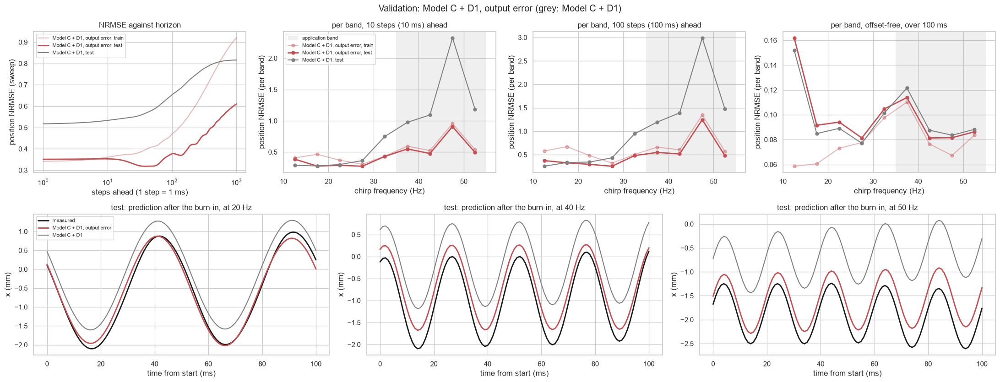

In [35]:
validate("Model C + D1, output error", lambda d, s, H: rollout_v2(magnets, p_OE, d, s, H, tau_d=tau_OE), ref="Model C + D1")

**Findings (output-error fit).**

- **The drive delay is confirmed at about 2.95–3.0 ms.** Two very different fits (force equation, predicted position) give the same value.
- **The dynamics in the band barely change.** The offset-free error stays at about 8–12 % per band (0.094 → 0.092 on the fit data): the equation-error fit was already close to the best for the oscillation.
- **The spring roughly halves again** (1.5·10⁴ → 6.7·10³ N/m). With the slow part removed from the cost the data hardly determine the spring, and the fit lets it drift.
- **The validation improves a lot, but through that weak spring.** At 45–50 Hz the error drops from 2.3 to 0.9 (10 ms) and from 3.0 to 1.25 (100 ms), and over 1 s to 0.61 (old Model C 0.63). A spring that soft pulls back to its rest position only slowly, so the measured offset the model starts with after the burn-in stays in its prediction: the offset is remembered, not predicted. The spring value cannot be trusted.
- **Next:** the remaining dynamics error peaks at 35–40 Hz (about 12 %), at the laser mode: the laser's sensor model. The spring is to be pinned down later with low-frequency data (the plain chirps at 1–10 Hz), not by a high-frequency fit.

## The laser's sensor model

The remaining error in the oscillation peaks at 35–40 Hz, at the laser mode found in the processing (a dip and a 25 % step in the laser's force per ampere at 34–35.5 Hz, absent from the accelerometer). It is described in the measurement equation, not in the force law: the laser reads the mass position through a filter $S$,

$$y = S(s)\,x, \qquad S(s) = \frac{s^2/\omega_z^2 + 2\zeta_z\, s/\omega_z + 1}{s^2/\omega_p^2 + 2\zeta_p\, s/\omega_p + 1}, \qquad S(0) = 1$$

a lightly damped pole pair (the mode, $f_p$, $\zeta_p$) with a zero pair ($f_z$, $\zeta_z$) close to it, which sets the gain step across the mode. $S(0) = 1$ keeps the laser's calibration at low frequency.

**In the simulation.** The predicted position, burn-in included, passes through $S$, discretised with the bilinear transform at 1 kHz (pole and zero frequencies prewarped). The filter starts at rest at the first burn-in sample, so by the start of each scored window it carries the burn-in's motion. The pole and zero lie close together, so a start-up transient of $S$ is small.

**Fit.** The same offset-free output-error cost as above. Fitted: $\Gamma$, $c$, $\tau_d$ and the four sensor parameters $f_p, \zeta_p, f_z, \zeta_z$, starting from Model C + D1 and from the previous notebook's estimate (pole 34.87 Hz, zero 34.71 Hz, both $\zeta$ = 0.02). Kept at the equation-error values of Model C + D1: $\Gamma_1$, $C_R$, $C_L$, so the spring cannot drift as in the last fit and the comparison isolates the sensor model. Bounds: $f_p, f_z$ in 30–40 Hz, $\zeta$ in 0.001–0.3.

In [36]:
def sensor_sos(f_p, z_p, f_z, z_z, fs=1000.0):
    "S(s) as a discrete second-order section (bilinear, pole and zero frequencies prewarped), S(0) = 1."
    warp = lambda f: 2 * fs * np.tan(np.pi * f / fs)    # rad/s
    wp, wz = warp(f_p), warp(f_z)
    b, a = signal.bilinear([1 / wz ** 2, 2 * z_z / wz, 1.0], [1 / wp ** 2, 2 * z_p / wp, 1.0], fs=fs)
    return b / a[0], a / a[0]


def predict_sensor(Fs, p, tau_d, sens, d, s, H, B=BURN_IN):
    "Laser reading predicted at s..s+H: the rollout with burn-in, through the sensor filter S, one pole-zero pair per 4 entries of sens (each at rest at the first burn-in sample)."
    y_full = rollout_v2(Fs, p, d, s, H, tau_d=tau_d, B=B, with_burn_in=True)
    for pair in np.reshape(sens, (-1, 4)):              # pairs in series: S = S_1 S_2 ...
        b, a = sensor_sos(*pair)
        zi = signal.lfilter_zi(b, a)[None, :] * y_full[:, :1]   # steady state for the first sample
        y_full, _ = signal.lfilter(b, a, y_full, axis=1, zi=zi)
    return y_full[:, -(H + 1):]


SENS0 = np.r_[34.87, 0.02, 34.71, 0.02]                 # previous notebook: pole, damping, zero, damping


def res_sens(q):
    "Offset-free output-error residuals; q = [Gamma, c, tau_d, f_p, z_p, f_z, z_z]; Gamma1, C_R, C_L from Model C + D1."
    p_ = np.r_[q[0], q[1], p_D1[2:]]
    y_hat = predict_sensor(magnets, p_, q[2], q[3:], d_oe, s_oe, H_OE)[:, 1:]
    e = np.nan_to_num(y_hat - X_oe, nan=1.0, posinf=1.0, neginf=-1.0)
    return ((e @ P_oe.T) / sig_oe[:, None]).ravel()


qs0 = np.r_[p_D1[0], p_D1[1], tau_D1, SENS0]
lb_s = [-np.inf, 0.0, 0.0, 30.0, 0.001, 30.0, 0.001]
ub_s = [np.inf, np.inf, 5e-3, 40.0, 0.3, 40.0, 0.3]
r_s0 = res_sens(qs0)
fit_s = cached("fit_s", (qs0, lb_s, ub_s, p_D1, s_oe, H_OE, BURN_IN),
               lambda: least_squares(res_sens, qs0, bounds=(lb_s, ub_s), x_scale=np.abs(qs0)))
p_S = np.r_[fit_s.x[0], fit_s.x[1], p_D1[2:]]
tau_S, sens_S = fit_s.x[2], fit_s.x[3:]
print(f"{fit_s.message} ({fit_s.nfev} evaluations)")
print(f"rms relative offset-free error: Model C + D1 {np.sqrt(np.mean(res_oe(np.r_[p_D1, tau_D1]) ** 2)):.4f}, "
      f"with the sensor model at its start values {np.sqrt(np.mean(r_s0 ** 2)):.4f}, fitted {np.sqrt(np.mean(fit_s.fun ** 2)):.4f}")
print(f"Gamma = {p_S[0]:.1f} N/A, c = {p_S[1]:.1f} N s/m, tau_d = {tau_S * 1e3:.2f} ms")
print(f"sensor: pole {sens_S[0]:.2f} Hz (zeta {sens_S[1]:.3f}), zero {sens_S[2]:.2f} Hz (zeta {sens_S[3]:.3f}); "
      f"gain above the mode (f_p/f_z)^2 = {(sens_S[0] / sens_S[2]) ** 2:.3f}")

[cache] fit_s: loaded
`ftol` termination condition is satisfied. (9 evaluations)


rms relative offset-free error: Model C + D1 0.0937, with the sensor model at its start values 0.0845, fitted 0.0820
Gamma = 229.3 N/A, c = 2836.4 N s/m, tau_d = 3.08 ms
sensor: pole 34.03 Hz (zeta 0.020), zero 33.89 Hz (zeta 0.017); gain above the mode (f_p/f_z)^2 = 1.008


### Validation

Model C + D1 with the laser's sensor model, against Model C + D1 (the same spring, without the sensor model).

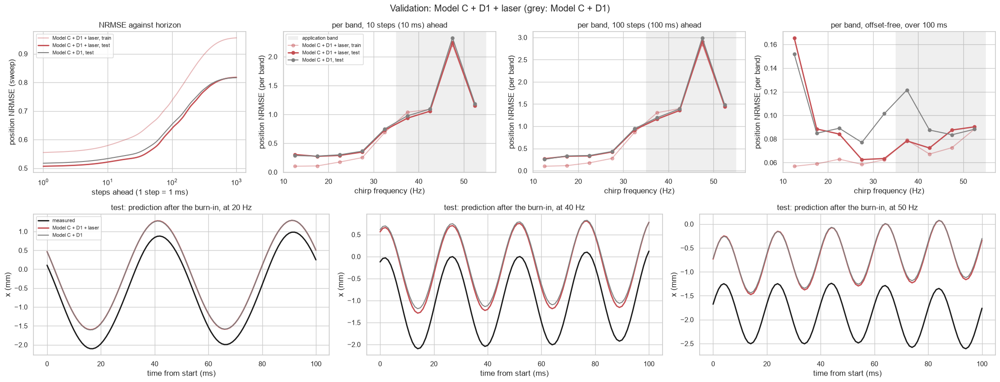

In [37]:
validate("Model C + D1 + laser", lambda d, s, H: predict_sensor(magnets, p_S, tau_S, sens_S, d, s, H), ref="Model C + D1")

**Findings (laser sensor model).**

- **The sensor model removes the error peak at the laser mode.** The offset-free error at 35–40 Hz drops from 0.121 to 0.078 (test), and 25–45 Hz all improve; overall 0.094 → 0.082 on the fit data.
- **The fitted mode is very narrow:** pole 34.03 Hz, zero 33.89 Hz, damping ratios about 0.02, a gain step of only 0.8 %. It sits about 0.8 Hz below the previous notebook's estimate, at the dip in the laser's force per ampere at 34 Hz.
- **It does not explain the laser's 7–13 % over-reading above 35 Hz** seen against the accelerometer; that larger step is absorbed elsewhere or has another cause. Open.
- **The errors including the slow offset do not change**: the offset still dominates them, and the spring is the same.
- **What is left in the oscillation:** about 9 % at 45–55 Hz, untouched, where the second slow dip sits (about 47.5 Hz) and the laser's force per ampere also dips (near 47 Hz): a second structural mode in the laser path. And up to about 16 % at 10–20 Hz, where the scheduled runs are at 2–3 A: the force loss at small current found in the processing, outside the application band.

### A second mode in the laser path, near 47.5 Hz

The sensor model with a second pole-zero pair in series:

$$S(s) = S_1(s)\,S_2(s), \qquad S_j(s) = \frac{s^2/\omega_{z,j}^2 + 2\zeta_{z,j}\, s/\omega_{z,j} + 1}{s^2/\omega_{p,j}^2 + 2\zeta_{p,j}\, s/\omega_{p,j} + 1}$$

$S_1$ starts at the 34 Hz pair fitted above; $S_2$ at a pole of 47.6 Hz and a zero of 47.3 Hz, damping ratios 0.02, within 44–51 Hz. Fitted as before (offset-free output error): $\Gamma$, $c$, $\tau_d$ and both pairs; $\Gamma_1$, $C_R$, $C_L$ kept at the values of Model C + D1.

In [38]:
SENS2_0 = np.r_[sens_S, 47.6, 0.02, 47.3, 0.02]         # start: the 34 Hz pair fitted above, and a pair near 47.5 Hz


def res_sens2(q):
    "Offset-free output-error residuals; q = [Gamma, c, tau_d, pair 1 (4), pair 2 (4)]; Gamma1, C_R, C_L from Model C + D1."
    p_ = np.r_[q[0], q[1], p_D1[2:]]
    y_hat = predict_sensor(magnets, p_, q[2], q[3:], d_oe, s_oe, H_OE)[:, 1:]
    e = np.nan_to_num(y_hat - X_oe, nan=1.0, posinf=1.0, neginf=-1.0)
    return ((e @ P_oe.T) / sig_oe[:, None]).ravel()


qs2_0 = np.r_[p_S[0], p_S[1], tau_S, SENS2_0]
lb_s2 = [-np.inf, 0.0, 0.0, 30.0, 0.001, 30.0, 0.001, 44.0, 0.001, 44.0, 0.001]
ub_s2 = [np.inf, np.inf, 5e-3, 40.0, 0.3, 40.0, 0.3, 51.0, 0.3, 51.0, 0.3]
r_s2_0 = res_sens2(qs2_0)
fit_s2 = cached("fit_s2", (qs2_0, lb_s2, ub_s2, p_D1, s_oe, H_OE, BURN_IN),
                lambda: least_squares(res_sens2, qs2_0, bounds=(lb_s2, ub_s2), x_scale=np.abs(qs2_0)))
p_S2 = np.r_[fit_s2.x[0], fit_s2.x[1], p_D1[2:]]
tau_S2, sens_S2 = fit_s2.x[2], fit_s2.x[3:]
print(f"{fit_s2.message} ({fit_s2.nfev} evaluations)")
print(f"rms relative offset-free error: one pair {np.sqrt(np.mean(fit_s.fun ** 2)):.4f}, "
      f"two pairs at their start values {np.sqrt(np.mean(r_s2_0 ** 2)):.4f}, fitted {np.sqrt(np.mean(fit_s2.fun ** 2)):.4f}")
print(f"Gamma = {p_S2[0]:.1f} N/A, c = {p_S2[1]:.1f} N s/m, tau_d = {tau_S2 * 1e3:.2f} ms")
for j, pair in enumerate(np.reshape(sens_S2, (-1, 4)), start=1):
    print(f"pair {j}: pole {pair[0]:.2f} Hz (zeta {pair[1]:.3f}), zero {pair[2]:.2f} Hz (zeta {pair[3]:.3f}); "
          f"gain above it (f_p/f_z)^2 = {(pair[0] / pair[2]) ** 2:.3f}")

[cache] fit_s2: loaded
`ftol` termination condition is satisfied. (20 evaluations)
rms relative offset-free error: one pair 0.0820, two pairs at their start values 0.0962, fitted 0.0786
Gamma = 237.5 N/A, c = 3074.4 N s/m, tau_d = 3.38 ms
pair 1: pole 34.74 Hz (zeta 0.036), zero 34.45 Hz (zeta 0.034); gain above it (f_p/f_z)^2 = 1.017
pair 2: pole 51.00 Hz (zeta 0.217), zero 49.69 Hz (zeta 0.203); gain above it (f_p/f_z)^2 = 1.054


#### Validation

With both pairs, against the model with the 34 Hz pair only.

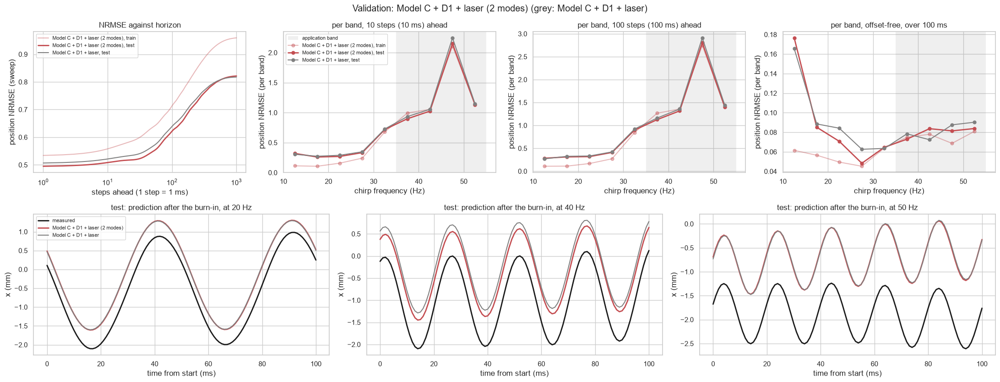

In [39]:
validate("Model C + D1 + laser (2 modes)", lambda d, s, H: predict_sensor(magnets, p_S2, tau_S2, sens_S2, d, s, H), ref="Model C + D1 + laser")

**Findings (second mode): a dead end.**

- **The fit did not find a mode near 47.5 Hz.** The second pair ran to the upper bound (pole at 51 Hz) and became broad (damping ratio about 0.2 instead of 0.02): a smooth gain step of about 5 % around 50 Hz, not a resonance.
- **The improvement is small and mixed.** Offset-free error 0.082 → 0.079 on the fit data; on the test run 45–55 Hz and 20–30 Hz improve slightly, 40–45 Hz and 10–15 Hz get worse.
- **The other parameters shift with it** (the drive delay by 0.3 ms, the damping and $\Gamma$ up): a parameter at its bound and correlated shifts point at fitting a shape, not physics.
- **A more plausible source of that broad step is the drive.** Its measured current rises slowly with frequency in every run (gain about 0.85 at 15 Hz, 0.87–0.89 at 50 Hz, section 4), while D1 assumes a constant gain.
- **Decision: the second pair is not adopted.** Model C + D1 + laser (one pair) stays the current best. Next: a drive block whose gain changes with frequency, its shape taken from the drive's measured current.

## A drive block with a frequency-dependent gain (D2)

D1 passes the sent current with a delay and a constant gain. The drive's own measured current, however, rises slowly with frequency (section 4). A lead-lag in the drive block can carry that:

$$D_2(s) = e^{-s\tau_d}\,\frac{1 + s\tau_1}{1 + s\tau_2}$$

**First, model-free: the shape from the drive's measured current.** On all four runs, the frequency response from the sent current to `actual_current_A` is estimated ($H_1$, Welch, `NPERSEG_R` samples, exact sent current as input, raw 2 kHz, chirp band 10–55 Hz) and fitted with

$$H(j\omega) = g\, e^{-j\omega\tau}\, \frac{1 + j\omega\tau_1}{1 + j\omega\tau_2}$$

by least squares on the relative complex error. Only the shape, $\tau_1$ and $\tau_2$, would go into $D_2$: the gain $g$ is absorbed by $\Gamma$, and the delay to the force is fitted separately (the measured current has its own measurement path). Shown: the measured gain and phase (the phase with the fitted delay removed) and the fit, per run.

scheduled train: 2 A, ramp to 6 A from 15 Hz     g = 0.855, tau = 2.49 ms, tau1 = 0.87 ms, tau2 = 0.00 ms; gain change 10 -> 55 Hz 1.042
scheduled test: 3 A, ramp to 7 A from 15 Hz      g = 0.850, tau = 2.56 ms, tau1 = 0.96 ms, tau2 = 0.00 ms; gain change 10 -> 55 Hz 1.051


plain train: 6.5 A                               g = 0.852, tau = 2.28 ms, tau1 = 0.61 ms, tau2 = 0.00 ms; gain change 10 -> 55 Hz 1.021
plain test: 6.0 A                                g = 0.850, tau = 2.28 ms, tau1 = 0.61 ms, tau2 = 0.00 ms; gain change 10 -> 55 Hz 1.021


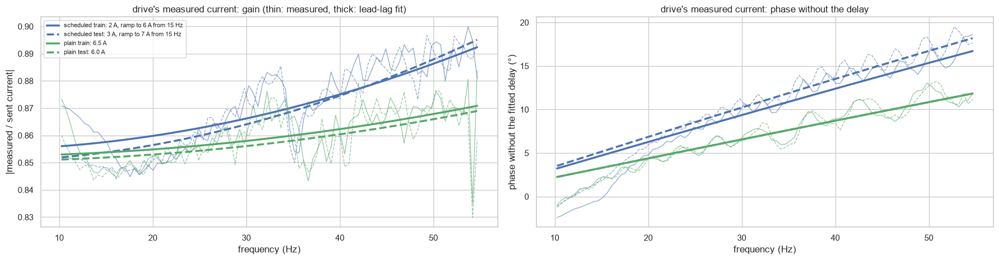

In [40]:
def fit_leadlag(f, H):
    "Fit H(jw) = g exp(-jw tau) (1 + jw tau1) / (1 + jw tau2) to a measured response; returns g, tau, tau1, tau2."
    w = 2 * np.pi * f
    model = lambda q: q[0] * np.exp(-1j * w * q[1]) * (1 + 1j * w * q[2]) / (1 + 1j * w * q[3])
    def res(q):
        e = (model(q) - H) / np.abs(H)
        return np.r_[e.real, e.imag]
    q = least_squares(res, [np.abs(H).mean(), 1.6e-3, 1e-3, 1e-3], bounds=([0, 0, 0, 0], [np.inf, 1e-2, 1e-1, 1e-1]),
                      x_scale=[1.0, 1e-3, 1e-3, 1e-3]).x
    return q, model(q)


fig, ax = plt.subplots(1, 2, figsize=(18, 4.8))
LL = {}
for key, label, color, ls in RUNS_AMP:
    raw_ = RAW_DF[key]
    t_ = raw_["time_s"].to_numpy()
    i_fn_, f_fn_ = sent_current_fn(RAW_LOGS[key])
    run_ = (t_ >= 0) & (f_fn_(t_) >= 8.0)               # the chirp above 8 Hz (leaves out the plain chirps' large strokes)
    f_h, H_h, coh_h = h1(i_fn_(t_[run_]), raw_["actual_current_A"].to_numpy()[run_])
    b_h = (f_h >= 10) & (f_h <= 55)
    q_ll, H_fit = fit_leadlag(f_h[b_h], H_h[b_h])
    LL[key] = q_ll
    print(f"{label:48s} g = {q_ll[0]:.3f}, tau = {q_ll[1] * 1e3:.2f} ms, tau1 = {q_ll[2] * 1e3:.2f} ms, tau2 = {q_ll[3] * 1e3:.2f} ms; "
          f"gain change 10 -> 55 Hz {np.abs(H_fit[-1]) / np.abs(H_fit[0]):.3f}")
    w_h = 2 * np.pi * f_h[b_h]
    ax[0].plot(f_h[b_h], np.abs(H_h[b_h]), ls, color=color, lw=1, alpha=0.6)
    ax[0].plot(f_h[b_h], np.abs(H_fit), ls, color=color, lw=2.5, label=label)
    ph_meas = np.degrees(np.unwrap(np.angle(H_h[b_h] * np.exp(1j * w_h * q_ll[1]))))
    ph_fit = np.degrees(np.unwrap(np.angle(H_fit * np.exp(1j * w_h * q_ll[1]))))
    ax[1].plot(f_h[b_h], ph_meas, ls, color=color, lw=1, alpha=0.6)
    ax[1].plot(f_h[b_h], ph_fit, ls, color=color, lw=2.5, label=label)
ax[0].set(xlabel="frequency (Hz)", ylabel="|measured / sent current|", title="drive's measured current: gain (thin: measured, thick: lead-lag fit)")
ax[1].set(xlabel="frequency (Hz)", ylabel="phase without the fitted delay (°)", title="drive's measured current: phase without the delay")
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Findings (the drive's measured current).**

- **The drive's current rises with frequency as a pure lead.** The fit gives $\tau_2 = 0$ (at its bound) and $\tau_1$ = 0.6–1.0 ms: a zero at about 170–260 Hz, which inside the band raises the gain by a few percent and adds a phase lead growing with frequency (about 17° at 55 Hz).
- **The lead and the delay trade off.** The fitted delay (2.3–2.6 ms) is larger than the 1.6 ms found before because the lead gives phase back; at low frequency the net is about $\tau - \tau_1 \approx$ 1.6 ms, as before.
- **The rise depends on the current:** +4–5 % over 10–55 Hz in the scheduled runs (14–15 A at high frequency), +2 % in the plain chirps (6 A).
- **The scheduled runs' 4–5 % matches the broad 5 % step** the second sensor pair tried to build, which supports the drive as its source.
- **Not captured:** a dip in gain and a bump in phase at about 12–20 Hz, mainly in the scheduled train run, where the current is small.

### Model C + D2 + laser

The lead in the drive block, with $\tau_1$ = `TAU1_D2` = 0.9 ms, the value of the scheduled runs (the fit uses a scheduled run):

$$D_2(s) = e^{-s\tau_d}\,(1 + s\tau_1) \quad\Longleftrightarrow\quad i_\text{coil}(t) = i_\text{sent}(t - \tau_d) + \tau_1\, \frac{d}{dt} i_\text{sent}(t - \tau_d)$$

The sent current is a formula, so its derivative is evaluated directly (central difference with a step of 10 µs) at every RK4 stage: no filter is needed. Fitted as before (offset-free output error): $\Gamma$, $c$, $\tau_d$ and the 34 Hz sensor pair; $\Gamma_1$, $C_R$, $C_L$ kept at the values of Model C + D1. $\tau_d$ starts at the delay of Model C + D1 + laser plus $\tau_1$, since the lead gives about that much phase back.

Two caveats: the lead comes from the drive's measured current, which assumes that current shows how the coil current behaves; and its size depends on the amplitude, so a fixed $\tau_1$ fits the scheduled runs but is too large for the plain chirps (6 A).

In [41]:
TAU1_D2 = 0.9e-3                                        # s, lead of the drive (scheduled runs)
H_DIFF = 1e-5                                           # s, step of the central difference for d/dt i_sent


def with_lead(d, tau1):
    "Copy of run d whose current function includes the drive's lead: i(t) + tau1 di/dt."
    i0 = d["i_fn"]
    return dict(d, i_fn=lambda t: i0(t) + tau1 * (i0(t + H_DIFF) - i0(t - H_DIFF)) / (2 * H_DIFF))


d_oe2 = with_lead(d_oe, TAU1_D2)


def res_d2(q):
    "Offset-free output-error residuals with the lead; q = [Gamma, c, tau_d, f_p, z_p, f_z, z_z]; Gamma1, C_R, C_L from Model C + D1."
    p_ = np.r_[q[0], q[1], p_D1[2:]]
    y_hat = predict_sensor(magnets, p_, q[2], q[3:], d_oe2, s_oe, H_OE)[:, 1:]
    e = np.nan_to_num(y_hat - X_oe, nan=1.0, posinf=1.0, neginf=-1.0)
    return ((e @ P_oe.T) / sig_oe[:, None]).ravel()


qd0 = np.r_[p_S[0], p_S[1], tau_S + TAU1_D2, sens_S]
lb_d2 = [-np.inf, 0.0, 0.0, 30.0, 0.001, 30.0, 0.001]
ub_d2 = [np.inf, np.inf, 6e-3, 40.0, 0.3, 40.0, 0.3]
fit_d2 = cached("fit_d2", (qd0, lb_d2, ub_d2, TAU1_D2, p_D1, s_oe, H_OE, BURN_IN),
                lambda: least_squares(res_d2, qd0, bounds=(lb_d2, ub_d2), x_scale=np.abs(qd0)))
p_D2 = np.r_[fit_d2.x[0], fit_d2.x[1], p_D1[2:]]
tau_D2, sens_D2 = fit_d2.x[2], fit_d2.x[3:]
print(f"{fit_d2.message} ({fit_d2.nfev} evaluations)")
print(f"rms relative offset-free error: D1 + laser {np.sqrt(np.mean(fit_s.fun ** 2)):.4f}, "
      f"D1 + laser (2 modes) {np.sqrt(np.mean(fit_s2.fun ** 2)):.4f}, D2 + laser {np.sqrt(np.mean(fit_d2.fun ** 2)):.4f}")
print(f"Gamma = {p_D2[0]:.1f} N/A, c = {p_D2[1]:.1f} N s/m, tau_d = {tau_D2 * 1e3:.2f} ms (net delay at low frequency tau_d - tau1 = "
      f"{(tau_D2 - TAU1_D2) * 1e3:.2f} ms)")
print(f"sensor: pole {sens_D2[0]:.2f} Hz (zeta {sens_D2[1]:.3f}), zero {sens_D2[2]:.2f} Hz (zeta {sens_D2[3]:.3f})")

[cache] fit_d2: loaded
`ftol` termination condition is satisfied. (9 evaluations)
rms relative offset-free error: D1 + laser 0.0820, D1 + laser (2 modes) 0.0786, D2 + laser 0.0817
Gamma = 225.6 N/A, c = 2782.1 N s/m, tau_d = 3.92 ms (net delay at low frequency tau_d - tau1 = 3.02 ms)
sensor: pole 33.87 Hz (zeta 0.015), zero 33.76 Hz (zeta 0.012)


#### Validation

With the drive's lead, against Model C + D1 + laser (one sensor pair, no lead).

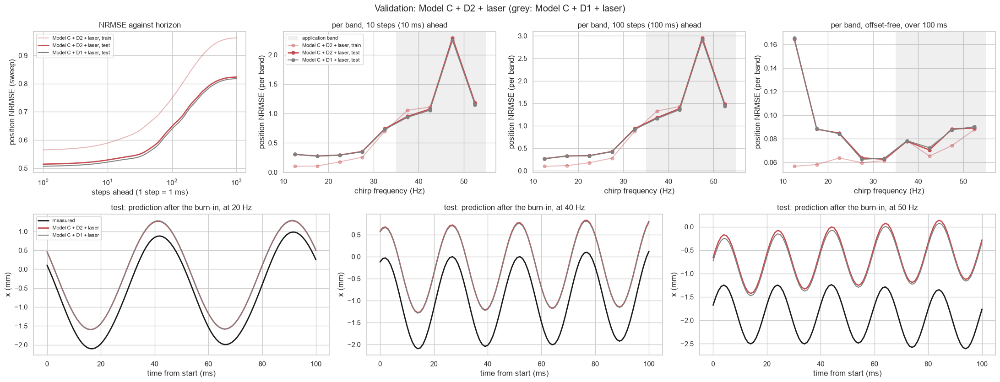

In [42]:
validate("Model C + D2 + laser", lambda d, s, H: predict_sensor(magnets, p_D2, tau_D2, sens_D2, with_lead(d, TAU1_D2), s, H),
         ref="Model C + D1 + laser")

**Findings (drive lead): a second dead end.**

- **The drive's lead makes no difference to the motion.** The offset-free error stays the same (0.0820 → 0.0817), in every band.
- **The fit absorbs the lead into the delay.** $\tau_d$ grows by almost exactly $\tau_1$ (3.08 → 3.92 ms), so the net delay at low frequency stays about 3 ms.
- **So the lead in the drive's measured current does not reach the force.** Most likely it belongs to the drive's own current measurement, not to the current in the coil. It is not the source of the broad step the second sensor pair tried to build; that step, and the about 9 % left at 45–55 Hz, stay unexplained.
- **Decision: D2 is not adopted.** Model C + D1 + laser stays the current best: the simplest model with the same result.

## The spring, from low frequencies

The scheduled chirps start at 10 Hz, where the mass line dominates and the spring barely shows: the fits let it drift between 6.7·10³ and 3.9·10⁴ N/m. The plain chirps cover 1–10 Hz, around the spring resonance, where the spring dominates. They also swing up to ±20 mm, close to the magnets at the 22.3 mm gap, where the 1/gap³ law and the linear motor constant may no longer hold (the previous notebook found Model C diverging there).

**First look: how far does the current best model get on the plain chirps?** Model C + D1 + laser, simulated over each whole plain chirp from its start (after the burn-in), with the sent current through the drive delay:

- **in time:** predicted against measured position; the laser's range limit (+19.76 mm) is marked;
- **in frequency:** the response from the sent current to the position at 1–20 Hz, measured and predicted, both estimated the same way ($H_1$, Welch, from the same sent current), so nonlinear effects are treated alike.

plain train: prediction finite and within 100 mm until t = 120.0 s; measured |x| max 22.0 mm


plain test: prediction finite and within 100 mm until t = 120.0 s; measured |x| max 21.2 mm


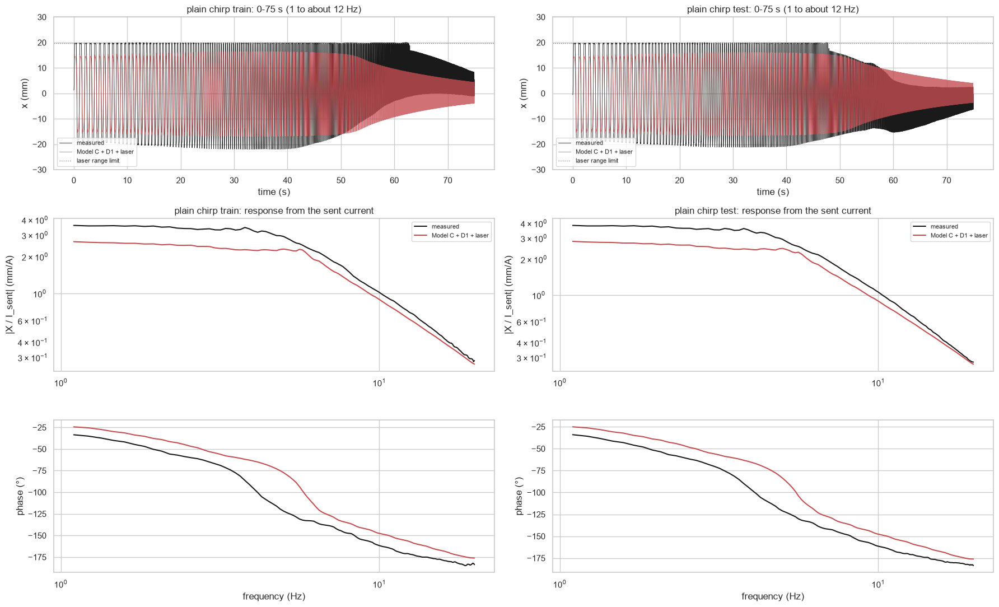

In [43]:
X_CLIP_MM = 19.76                                       # mm, upper end of the laser's range
best = dict(p=p_S, tau=tau_S, sens=sens_S)              # Model C + D1 + laser

fig, ax = plt.subplots(3, 2, figsize=(18, 11))
for col, sp in enumerate(("train", "test")):
    d_ = DATA["chirp"][sp]
    n_ = len(d_["t"]) - BURN_IN - 1
    y_hat = predict_sensor(magnets, best["p"], best["tau"], best["sens"], d_, np.array([BURN_IN]), n_)[0]
    t_hat = d_["t"][BURN_IN:]
    ok = np.isfinite(y_hat) & (np.abs(y_hat) < 0.1)
    print(f"plain {sp}: prediction finite and within 100 mm until t = {t_hat[np.argmin(ok)] if not ok.all() else t_hat[-1]:.1f} s; "
          f"measured |x| max {np.abs(d_['x']).max() * 1e3:.1f} mm")
    a_ = ax[0, col]
    win = d_["t"] <= 75.0                                # the chirp from 1 to about 12 Hz
    a_.plot(d_["t"][win], d_["x"][win] * 1e3, color="k", lw=0.6, label="measured")
    w_h = (t_hat <= 75.0) & ok
    a_.plot(t_hat[w_h], y_hat[w_h] * 1e3, color="C3", lw=0.6, alpha=0.8, label="Model C + D1 + laser")
    a_.axhline(X_CLIP_MM, color="0.5", ls=":", lw=1, label="laser range limit")
    a_.set(xlabel="time (s)", ylabel="x (mm)", title=f"plain chirp {sp}: 0-75 s (1 to about 12 Hz)", ylim=(-30, 30))
    a_.legend(loc="lower left", fontsize=8)
    # frequency response from the sent current, measured and predicted, the same estimator
    sel_ = (d_["f"] >= 0.8) & (d_["f"] <= 22) & np.r_[np.zeros(BURN_IN, bool), ok]
    i_ = d_["i"][sel_]
    for y_, lab, color in ((d_["x"][sel_], "measured", "k"), (np.r_[np.full(BURN_IN, np.nan), y_hat][sel_], "Model C + D1 + laser", "C3")):
        f_, P_uu = signal.welch(i_, fs=1000.0, nperseg=8192)
        _, P_uy = signal.csd(i_, y_, fs=1000.0, nperseg=8192)
        H_ = P_uy / P_uu
        b_ = (f_ >= 1) & (f_ <= 20)
        ax[1, col].loglog(f_[b_], np.abs(H_[b_]) * 1e3, color=color, lw=1.5, label=lab)
        ax[2, col].semilogx(f_[b_], np.degrees(np.unwrap(np.angle(H_[b_]))), color=color, lw=1.5, label=lab)
    ax[1, col].set(ylabel="|X / I_sent| (mm/A)", title=f"plain chirp {sp}: response from the sent current")
    ax[2, col].set(ylabel="phase (°)", xlabel="frequency (Hz)")
    ax[1, col].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Findings (plain chirps, current best model).**

- **The laser clips on the plain chirps.** Until about 62 s (train) and 47 s (test) the measured position runs flat at exactly +19.76 mm, the laser's range limit, while the negative side swings freely to about −21 mm: the top of each swing is cut off in the large-stroke half of both runs. These are the samples the spring has to come from, so they are masked below.
- **The model stays stable at large stroke but swings less:** about ±15 mm against −21 mm measured (and an unknown amount on the clipped side).
- **Below about 5 Hz its gain is about 25–30 % too low** (2.6 against 3.6 mm/A; the clipping makes the measured value itself an underestimate).
- **Its spring resonance sits too high:** the phase passes −90° at about 5.5–6 Hz against about 4.5–5 Hz measured. With the low gain: the model is too stiff at large stroke, as the 1/gap³ law at a 22.3 mm gap stiffens sharply near ±20 mm.
- **Above 10 Hz it is about 10 % low**, not yet explained.

### Masking the clipped samples

A sample is invalid where the raw laser reading is within `CLIP_MARGIN_MM` = 0.1 mm of the range limit, widened by `CLIP_PAD` = 50 ms on both sides (the 75 Hz filter spreads the edge of a flat top over a few tens of milliseconds). Every run gets a mask `valid`; the scheduled chirps never reach the limit and are valid throughout.

In [44]:
CLIP_MARGIN_MM, CLIP_PAD = 0.1, 0.050                   # mm, s

for key in RAW_LOGS:
    raw_ = RAW_DF[key]
    t_ = raw_["time_s"].to_numpy()
    near = np.abs(raw_["position_mm"].to_numpy() - X_CLIP_MM) <= CLIP_MARGIN_MM
    pad = int(round(CLIP_PAD * FS_RAW))
    bad = np.convolve(near.astype(float), np.ones(2 * pad + 1), mode="same") > 0   # widened on both sides
    d_ = DATA[key[0]][key[1]]
    d_["valid"] = ~np.interp(d_["t"], t_[1:], bad[1:].astype(float)).astype(bool)  # onto the 1 kHz samples (first time stamp repeats)
    print(f"{key[0]:10s} {key[1]:5s}: {100 * (1 - d_['valid'].mean()):.1f} % of the samples masked")

chirpsched train: 0.0 % of the samples masked
chirpsched test : 0.0 % of the samples masked
chirp      train: 26.8 % of the samples masked
chirp      test : 17.6 % of the samples masked


### The spring at large stroke

At 1–10 Hz the force balance is dominated by the spring, so the spring is fitted on the force equation (equation error), on the plain chirp (train): valid samples with the chirp below `F_SPRING` = 10 Hz. Following the datasheet's quadratic fall-off of the motor constant, $\Gamma(x)$ gets a quadratic term, and the magnet gap is an effective gap $g$, free:

$$m\ddot{x} = (\Gamma + \Gamma_1 x + \Gamma_2 x^2)\, i_\text{sent}(t - \tau_d) - c\,\dot{x} - \left(\frac{C_R}{(g - x)^3} - \frac{C_L}{(g + x)^3}\right)$$

$\Gamma$, $c$ and $\tau_d$ stay at the values of Model C + D1 + laser (identified at 10–55 Hz). For a fixed $g$ the model is linear in $\Gamma_1, \Gamma_2, C_R, C_L$ ($C_R, C_L \geq 0$), fitted by least squares; $g$ is chosen on a grid (`G_GRID`, 22.5–150 mm) by the smallest residual. Printed: the effective gap, the parameters, the stiffness at $x = 0$ and the motor constant at ±15 mm relative to the centre.

36207 samples; best effective gap g = 38.0 mm (rms residual 381.9 N)
Gamma1 = 962.9 N/(A m), Gamma2 = -2.204e+05 N/(A m^2), C_R = 0.003707, C_L = 0.004447 N m^3
stiffness at x = 0: 1.17e+04 N/m (resonance 2.40 Hz); Gamma(x)/Gamma at -15, +15 mm: 0.721, 0.847


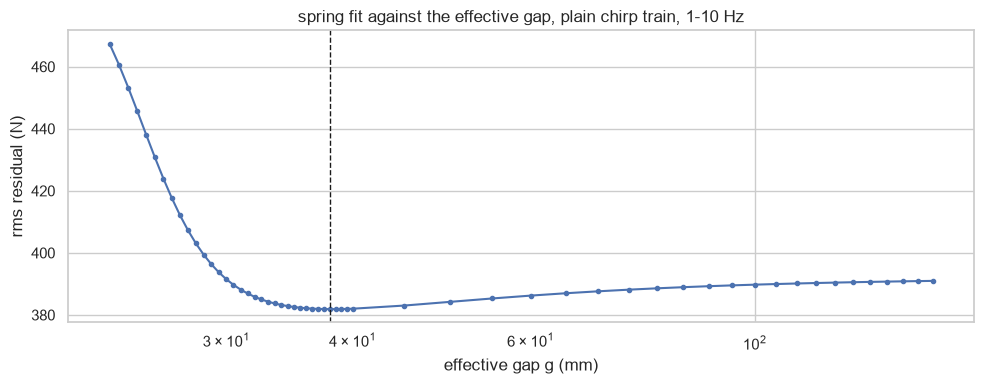

In [45]:
F_SPRING = 10.0                                         # Hz, chirp frequencies used for the spring
G_GRID = np.r_[np.arange(22.5, 40.0, 0.5), np.arange(40.0, 150.01, 5.0)] * 1e-3   # m, effective gaps tried

d_sp = DATA["chirp"]["train"]
sel_sp = d_sp["valid"] & (d_sp["f"] <= F_SPRING) & (d_sp["t"] >= 1.0)
x_, v_, a_ = d_sp["x"][sel_sp], d_sp["v"][sel_sp], d_sp["a"][sel_sp]
i_ = d_sp["i_fn"](d_sp["t"][sel_sp] - tau_S)            # sent current through the drive delay
y_sp = M * a_ - p_S[0] * i_ + p_S[1] * v_               # what Gamma1 x i + Gamma2 x^2 i - F_s must explain


def fit_spring(g):
    "Least squares for [Gamma1, Gamma2, C_R, C_L] at effective gap g (C_R, C_L >= 0); returns the parameters and the rms residual."
    A = np.column_stack([x_ * i_, x_ ** 2 * i_, -1 / (g - x_) ** 3, 1 / (g + x_) ** 3])
    sc = np.linalg.norm(A, axis=0)
    q = lsq_linear(A / sc, y_sp, bounds=([-np.inf, -np.inf, 0, 0], np.inf)).x / sc
    return q, np.sqrt(np.mean((A @ q - y_sp) ** 2))


ok_g = G_GRID > np.abs(x_).max() + 1e-3                  # the gap must lie outside the stroke
scan_g = [(g, *fit_spring(g)) for g in G_GRID[ok_g]]
g_best, q_sp, cost_sp = min(scan_g, key=lambda r: r[2])
G1_sp, G2_sp, CR_sp, CL_sp = q_sp
k_sp = 3 * (CR_sp + CL_sp) / g_best ** 4
print(f"{sel_sp.sum()} samples; best effective gap g = {g_best * 1e3:.1f} mm (rms residual {cost_sp:.1f} N)")
print(f"Gamma1 = {G1_sp:.4g} N/(A m), Gamma2 = {G2_sp:.4g} N/(A m^2), C_R = {CR_sp:.4g}, C_L = {CL_sp:.4g} N m^3")
print(f"stiffness at x = 0: {k_sp:.3g} N/m (resonance {np.sqrt(k_sp / M) / (2 * np.pi):.2f} Hz); "
      f"Gamma(x)/Gamma at -15, +15 mm: " + ", ".join(f"{1 + (G1_sp * xx + G2_sp * xx ** 2) / p_S[0]:.3f}" for xx in (-15e-3, 15e-3)))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot([r[0] * 1e3 for r in scan_g], [r[2] for r in scan_g], "o-", ms=3)
ax.axvline(g_best * 1e3, color="k", ls="--", lw=1)
ax.set(xscale="log", xlabel="effective gap g (mm)", ylabel="rms residual (N)", title="spring fit against the effective gap, plain chirp train, 1-10 Hz")
plt.tight_layout(); plt.show()

### The new spring: check

The model with the new spring and motor constant (and Γ, c, $\tau_d$, the sensor pair of Model C + D1 + laser):

$$F_s(x, i) = \frac{C_R}{(g - x)^3} - \frac{C_L}{(g + x)^3} - (\Gamma_1 x + \Gamma_2 x^2)\, i$$

1. **Plain chirps (test):** each whole run simulated from its start; the position NRMSE per frequency band of the chirp on valid samples, for the old spring (Model C + D1 + laser) and the new one. No offset is removed: at these frequencies the oscillation itself is slow.
2. **Scheduled chirps:** the standard validation, against Model C + D1 + laser.

Model C + D1 + laser   NRMSE per band: 1-2 Hz 0.53, 2-3 Hz 0.60, 3-4 Hz 0.90, 4-5 Hz 0.93, 5-6 Hz 0.51, 6-8 Hz 0.52, 8-10 Hz 0.99, 10-15 Hz 0.81, 15-25 Hz 0.69, 25-55 Hz 1.59


new spring             NRMSE per band: 1-2 Hz 0.18, 2-3 Hz 0.22, 3-4 Hz 0.48, 4-5 Hz 0.38, 5-6 Hz 0.25, 6-8 Hz 0.51, 8-10 Hz 1.00, 10-15 Hz 0.92, 15-25 Hz 1.38, 25-55 Hz 4.24


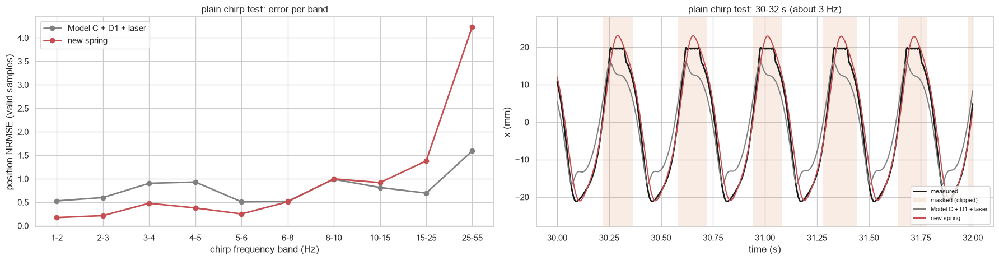

In [46]:
spring_E = lambda x, u, q: q[2] / (g_best - x) ** 3 - q[3] / (g_best + x) ** 3 - (q[0] * x + q[1] * x ** 2) * u   # q = [Gamma1, Gamma2, C_R, C_L]
p_E = np.r_[p_S[0], p_S[1], G1_sp, G2_sp, CR_sp, CL_sp]
MODELS_PLAIN = {"Model C + D1 + laser": (magnets, p_S), "new spring": (spring_E, p_E)}
BANDS_PLAIN = [(1, 2), (2, 3), (3, 4), (4, 5), (5, 6), (6, 8), (8, 10), (10, 15), (15, 25), (25, 55)]

fig, ax = plt.subplots(1, 2, figsize=(18, 4.8))
d_pt = DATA["chirp"]["test"]
n_ = len(d_pt["t"]) - BURN_IN - 1
for (name, (Fs_, p_)), color in zip(MODELS_PLAIN.items(), ("0.5", "C3")):
    y_hat = np.r_[np.full(BURN_IN, np.nan), predict_sensor(Fs_, p_, tau_S, sens_S, d_pt, np.array([BURN_IN]), n_)[0]]
    errs = []
    for lo, hi in BANDS_PLAIN:
        b_ = d_pt["valid"] & (d_pt["f"] >= lo) & (d_pt["f"] < hi) & np.isfinite(y_hat)
        errs.append(np.sqrt(np.mean((y_hat[b_] - d_pt["x"][b_]) ** 2)) / np.std(d_pt["x"][b_]))
    print(f"{name:22s} NRMSE per band: " + ", ".join(f"{lo}-{hi} Hz {e:.2f}" for (lo, hi), e in zip(BANDS_PLAIN, errs)))
    ax[0].plot([f"{lo}-{hi}" for lo, hi in BANDS_PLAIN], errs, "o-", color=color, lw=2, ms=6, label=name)
    z_ = (d_pt["t"] >= 30.0) & (d_pt["t"] < 32.0)       # about 3 Hz, large stroke
    if name == "Model C + D1 + laser":
        ax[1].plot(d_pt["t"][z_], d_pt["x"][z_] * 1e3, color="k", lw=2, label="measured")
        ax[1].fill_between(d_pt["t"][z_], -30, 30, where=~d_pt["valid"][z_], color="C1", alpha=0.15, lw=0, label="masked (clipped)")
    ax[1].plot(d_pt["t"][z_], y_hat[z_] * 1e3, color=color, lw=1.5, label=name)
ax[0].set(xlabel="chirp frequency band (Hz)", ylabel="position NRMSE (valid samples)", title="plain chirp test: error per band")
ax[0].legend()
ax[1].set(xlabel="time (s)", ylabel="x (mm)", ylim=(-28, 28), title="plain chirp test: 30-32 s (about 3 Hz)")
ax[1].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

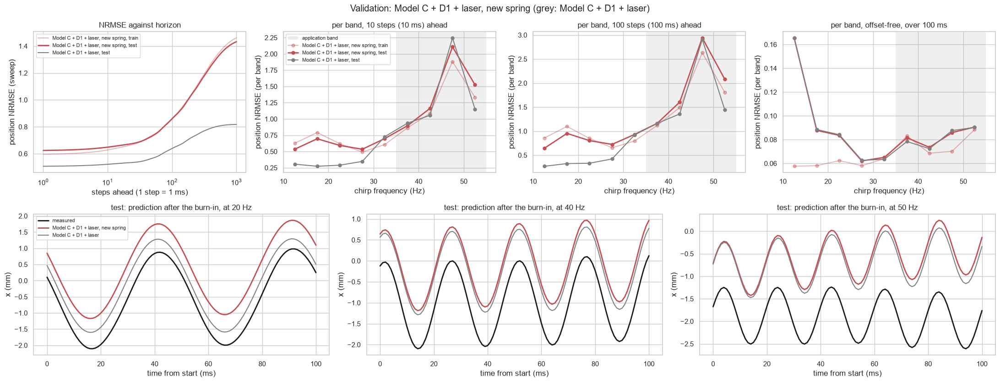

In [47]:
validate("Model C + D1 + laser, new spring", lambda d, s, H: predict_sensor(spring_E, p_E, tau_S, sens_S, d, s, H), ref="Model C + D1 + laser")

**Findings (the spring at large stroke).**

- **The best effective gap is 38 mm, not the measured 22.3 mm.** Stiffness at the centre 1.17·10⁴ N/m (spring resonance 2.4 Hz).
- **The motor constant falls off at large stroke, asymmetrically:** to 0.72 of the centre value at −15 mm and 0.85 at +15 mm (datasheet: 0.54 at 15 mm).
- **Large stroke is now much better, on a run the fit did not see.** On the plain test run the error at 1–6 Hz drops from 0.51–0.93 to 0.18–0.48; at 3 Hz the model follows the measured swing and its asymmetric shape, and predicts the top the laser cuts off (about +23 mm against the clipped 19.76 mm).
- **The oscillation in the band is unchanged.** On the scheduled runs the offset-free error is identical in every band.
- **The slow offset gets worse at small stroke.** On the scheduled runs the errors including the offset rise at 10–30 Hz (10 ms ahead from about 0.3 to 0.5–0.8), and on the plain test run above 15 Hz. The new nonlinear terms ($\Gamma_1$ changes sign, $\Gamma_2$ and the unequal magnets are strong) turn the oscillation into a steady force, and the model drifts to an offset of its own.
- **Decision: the new spring is adopted** (Model C + D1 + laser, new spring): the physically better description, validated at large stroke, with the band dynamics unchanged; the offset-free error stays the main yardstick, as the slow offset is largely a measurement disturbance. The remaining offset at small stroke is left for a learned correction.

## A learned correction on the output

The grey box (Model C + D1 + laser, new spring) gets each regime about right on its own; what differs between small stroke at high frequency and large stroke at low frequency is mainly a slow offset, whose size depends on the operating condition. A learned term adds what the grey box misses, on its output:

$$\hat{y}(t) = \underbrace{S(s)\,x_\text{model}(t)}_{\text{grey box}} + \underbrace{g_\psi\big(\phi(t)\big)}_{\text{learned}}$$

- **On the output, outside the dynamics:** a learner's error cannot feed back through the state and grow (the main failure of the learned force term in the previous notebook).
- **Free run.** The grey box runs freely over each whole run, from its start, driven only by the sent current; $g_\psi$ is learned for that use (predicting the laser reading from the input). The standard validation restarts every prediction from the measured state, which already carries part of the measured offset into it; a correction learned in free run would count that part twice. So this step is judged in free run.
- **Target:** the grey box's residual $r(t) = y(t) - S\,x_\text{model}(t)$, on valid samples (clipping masked), from 1 s into each run.
- **Features $\phi(t)$, all causal:** the sent current through the drive delay over the last `N_LAG_ML` = 30 ms, $i_\text{sent}(t - \tau_d - j\,T_s)$; the rms of the sent current over the last 0.5 s and 2 s (the operating condition: how hard it is driven); and the grey box's own predicted position, now and its rms over the last 0.5 s.
- **Training data, both regimes:** the scheduled chirp (train) and the plain chirp (train), every `ML_THIN`-th valid sample.
- **Learners, from simple to flexible:** ridge regression (linear in the features), then gradient-boosted trees (`HistGradientBoostingRegressor`).
- **Judged on runs never seen, both regimes:** the scheduled chirp (test) and the plain chirp (test). Per band of the chirp frequency, on valid samples: the position NRMSE as it is, and offset-free (non-overlapping 100 ms windows with their straight line removed, as in the standard validation).

In [48]:
import os

os.environ.setdefault("OMP_NUM_THREADS", "4")              # a fixed thread count: unlimited OpenMP threads can hang inside the kernel on Windows
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

N_LAG_ML, ML_THIN = 30, 5                               # steps of current history; thinning of the training samples
GREY = dict(Fs=spring_E, p=p_E, tau=tau_S, sens=sens_S)   # Model C + D1 + laser, new spring


def free_run(d):
    "Grey box over the whole run from its start (after the burn-in at the first samples); NaN before."
    n_ = len(d["t"]) - BURN_IN - 1
    y_ = predict_sensor(GREY["Fs"], GREY["p"], GREY["tau"], GREY["sens"], d, np.array([BURN_IN]), n_)[0]
    return np.r_[np.full(BURN_IN, np.nan), y_]


def trailing_rms(s, n):
    "Causal rms of s over the last n samples (shorter at the start)."
    c2 = np.r_[0.0, np.cumsum(s ** 2)]
    k = np.arange(1, len(s) + 1)
    lo = np.maximum(k - n, 0)
    return np.sqrt((c2[k] - c2[lo]) / (k - lo))


def features(d, y_grey):
    "Causal features per sample: delayed sent-current history, its rms over 0.5 s and 2 s, the grey-box output and its 0.5 s rms."
    t_ = d["t"]
    i_del = d["i_fn"](t_ - GREY["tau"])
    lags = np.column_stack([np.r_[np.zeros(j), i_del[:len(i_del) - j]] for j in range(N_LAG_ML)])
    yg = np.nan_to_num(y_grey)
    return np.column_stack([lags, trailing_rms(i_del, 500), trailing_rms(i_del, 2000), yg, trailing_rms(yg - np.mean(yg), 500)])


RUNS_ML = {"scheduled train": DATA["chirpsched"]["train"], "plain train": DATA["chirp"]["train"],
           "scheduled test": DATA["chirpsched"]["test"], "plain test": DATA["chirp"]["test"]}
ML = {}
for name, d_ in RUNS_ML.items():
    y_g = free_run(d_)
    use = d_["valid"] & np.isfinite(y_g) & (d_["t"] >= 1.0) & d_["sweep"]
    ML[name] = dict(d=d_, y_grey=y_g, X=features(d_, y_g), r=d_["x"] - y_g, use=use)

train_idx = {n: np.flatnonzero(ML[n]["use"])[::ML_THIN] for n in ("scheduled train", "plain train")}
X_tr = np.vstack([ML[n]["X"][i] for n, i in train_idx.items()])
r_tr = np.concatenate([ML[n]["r"][i] for n, i in train_idx.items()])
learners = {"+ ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
            "+ boosted trees": HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, random_state=0)}
for lab, mdl in learners.items():
    mdl.fit(X_tr, r_tr)
print(f"trained on {len(r_tr)} samples (scheduled train and plain train)")

trained on 41251 samples (scheduled train and plain train)


### Judged on the test runs

Per band of the chirp frequency, on valid samples, for the grey box alone and with each learner: the position NRMSE as it is (left), and offset-free (right).

scheduled test  grey box         NRMSE: 10-20 1.16, 20-35 1.41, 35-45 2.42, 45-55 2.94 | offset-free: 0.147, 0.067, 0.073, 0.055
scheduled test  + ridge          NRMSE: 10-20 0.99, 20-35 0.61, 35-45 0.63, 45-55 1.51 | offset-free: 0.128, 0.100, 0.110, 0.121
scheduled test  + boosted trees  NRMSE: 10-20 0.72, 20-35 0.57, 35-45 0.72, 45-55 0.59 | offset-free: 0.129, 0.069, 0.088, 0.077


plain test      grey box         NRMSE: 1-2 0.17, 2-4 0.31, 4-6 0.27, 6-10 0.66, 10-20 0.94, 20-35 2.49, 35-55 5.43 | offset-free: 0.066, 0.116, 0.087, 0.154, 0.206, 0.071, 0.104
plain test      + ridge          NRMSE: 1-2 0.20, 2-4 0.31, 4-6 0.23, 6-10 0.62, 10-20 0.79, 20-35 1.69, 35-55 3.94 | offset-free: 0.067, 0.117, 0.074, 0.138, 0.191, 0.097, 0.145
plain test      + boosted trees  NRMSE: 1-2 0.08, 2-4 0.11, 4-6 0.22, 6-10 1.39, 10-20 1.58, 20-35 1.23, 35-55 2.71 | offset-free: 0.040, 0.053, 0.097, 0.094, 0.075, 0.072, 0.113


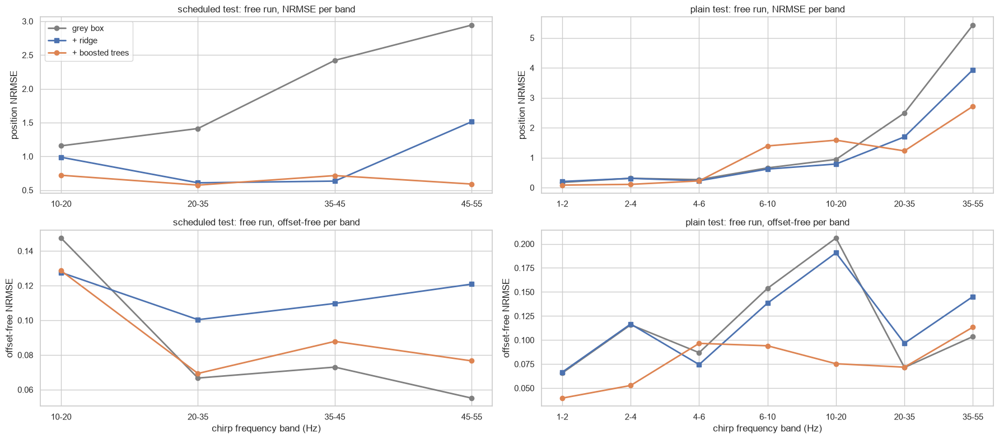

In [49]:
BANDS_ML = {"scheduled test": [(10, 20), (20, 35), (35, 45), (45, 55)],
            "plain test": [(1, 2), (2, 4), (4, 6), (6, 10), (10, 20), (20, 35), (35, 55)]}
W_HP = 100                                              # samples, window of the offset-free error


def band_errors(y_hat, e_d, bands, use):
    "Per band: NRMSE as it is, and offset-free (non-overlapping W_HP windows with their straight line removed)."
    out = []
    kk = np.arange(W_HP)
    for lo, hi in bands:
        b_ = use & (e_d["f"] >= lo) & (e_d["f"] < hi)
        err = (y_hat - e_d["x"])
        tot = np.sqrt(np.mean(err[b_] ** 2)) / np.std(e_d["x"][b_])
        res_w = []
        for s0 in np.flatnonzero(b_)[::W_HP]:
            w_ = slice(s0, s0 + W_HP)
            if len(err[w_]) == W_HP and b_[w_].all():   # whole windows only
                e_w = err[w_]
                res_w.append(e_w - np.polyval(np.polyfit(kk, e_w, 1), kk))
        out.append((tot, np.sqrt(np.mean(np.concatenate(res_w) ** 2)) / np.std(e_d["x"][b_]) if res_w else np.nan))
    return np.array(out)


fig, ax = plt.subplots(2, 2, figsize=(18, 8))
ML_STYLE = {"grey box": dict(color="0.5", marker="o"), "+ ridge": dict(color="C0", marker="s"),
            "+ boosted trees": dict(color="C1", marker="o"), "+ trees, all features": dict(color="C1", marker="o"),
            "+ trees, slow only": dict(color="C2", marker="s")}   # one fixed colour per model, in both comparison figures
for col, name in enumerate(("scheduled test", "plain test")):
    e_ = ML[name]
    variants = {"grey box": e_["y_grey"]}
    for lab, mdl in learners.items():
        variants[lab] = e_["y_grey"] + np.where(np.isfinite(e_["y_grey"]), mdl.predict(e_["X"]), np.nan)
    labels = [f"{lo}-{hi}" for lo, hi in BANDS_ML[name]]
    for lab, y_hat in variants.items():
        be = band_errors(y_hat, e_["d"], BANDS_ML[name], e_["use"])
        ax[0, col].plot(labels, be[:, 0], lw=2, ms=6, label=lab, **ML_STYLE[lab])
        ax[1, col].plot(labels, be[:, 1], lw=2, ms=6, label=lab, **ML_STYLE[lab])
        print(f"{name:15s} {lab:16s} NRMSE: " + ", ".join(f"{l} {v:.2f}" for l, v in zip(labels, be[:, 0]))
              + " | offset-free: " + ", ".join(f"{v:.3f}" for v in be[:, 1]))
    ax[0, col].set(title=f"{name}: free run, NRMSE per band", ylabel="position NRMSE")
    ax[1, col].set(title=f"{name}: free run, offset-free per band", ylabel="offset-free NRMSE", xlabel="chirp frequency band (Hz)")
ax[0, 0].legend()
plt.tight_layout(); plt.show()

**Findings (learned correction).**

- **The trees learn the regime-dependent offset: one correction covers both regimes, mostly.** On the scheduled test run the error including the offset drops by a factor 2–5 in every band (to about 0.6–0.7 in the application band, from 2.4–2.9); on the plain test run it about halves at 1–4 Hz and 20–55 Hz.
- **It goes wrong where the regimes meet.** At 6–20 Hz on the plain test run the trees make it worse (0.66 → 1.39, 0.94 → 1.58): that combination of stroke and frequency hardly occurs in the training data (the scheduled runs start at 10 Hz with small stroke, the plain runs are at large stroke there), so the learner extrapolates.
- **The learners slightly harm the oscillation in the band.** Offset-free at 45–55 Hz: 0.055 → 0.077 (trees), 0.12 (ridge). They fix the offset but add error to the dynamics the grey box already had right.
- **Ridge is clearly weaker than the trees:** the offset depends on the operating condition nonlinearly.
- **Next:** limit the learner to the slow offset (target and features slow only), so the oscillation in the band stays fully with the grey box.

### Slow-only correction

The learner is limited to what it is good at, the slow offset:

- **Target:** the slow part of the residual, $r_\text{slow}$ = $r$ low-passed at `F_SLOW` = 8 Hz (4th-order Butterworth, zero phase). Masked (clipped) samples are bridged by linear interpolation before filtering, so they do not leak into their neighbours, and are left out of the training.
- **Features, slow and causal only:** the rms of the sent current (through the drive delay) over the last 0.5 s and 2 s; the grey box's output, its rms and its mean over the last 0.5 s and 2 s. No fast current history: the learner has nothing to shape the oscillation with.
- **Learner:** gradient-boosted trees (ridge was clearly weaker), trained on both train runs as before.

Judged as before (free run, both test runs, per band), against the grey box and the trees with all features.

scheduled test  grey box               NRMSE: 10-20 1.16, 20-35 1.41, 35-45 2.42, 45-55 2.94 | offset-free: 0.147, 0.067, 0.073, 0.055
scheduled test  + trees, all features  NRMSE: 10-20 0.72, 20-35 0.57, 35-45 0.72, 45-55 0.59 | offset-free: 0.129, 0.069, 0.088, 0.077


scheduled test  + trees, slow only     NRMSE: 10-20 0.29, 20-35 0.56, 35-45 0.74, 45-55 0.62 | offset-free: 0.147, 0.084, 0.088, 0.072


plain test      grey box               NRMSE: 1-2 0.17, 2-4 0.31, 4-6 0.27, 6-10 0.66, 10-20 0.94, 20-35 2.49, 35-55 5.43 | offset-free: 0.066, 0.116, 0.087, 0.154, 0.206, 0.071, 0.104
plain test      + trees, all features  NRMSE: 1-2 0.08, 2-4 0.11, 4-6 0.22, 6-10 1.39, 10-20 1.58, 20-35 1.23, 35-55 2.71 | offset-free: 0.040, 0.053, 0.097, 0.094, 0.075, 0.072, 0.113
plain test      + trees, slow only     NRMSE: 1-2 0.14, 2-4 0.19, 4-6 0.24, 6-10 1.38, 10-20 1.22, 20-35 1.07, 35-55 2.68 | offset-free: 0.069, 0.110, 0.093, 0.155, 0.301, 0.071, 0.117


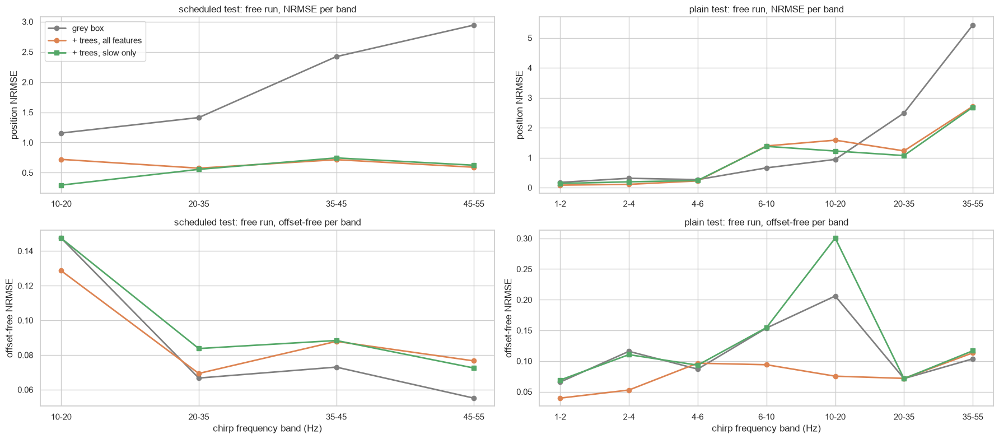

In [50]:
def trailing_mean(s, n):
    "Causal mean of s over the last n samples (shorter at the start)."
    c1 = np.r_[0.0, np.cumsum(s)]
    k = np.arange(1, len(s) + 1)
    lo = np.maximum(k - n, 0)
    return (c1[k] - c1[lo]) / (k - lo)


def slow_features(d, y_grey):
    "Slow, causal features: rms of the delayed sent current over 0.5 s and 2 s; grey-box output rms and mean over 0.5 s and 2 s."
    i_del = d["i_fn"](d["t"] - GREY["tau"])
    yg = np.nan_to_num(y_grey)
    return np.column_stack([trailing_rms(i_del, 500), trailing_rms(i_del, 2000),
                            trailing_rms(yg - trailing_mean(yg, 2000), 500), trailing_rms(yg - trailing_mean(yg, 2000), 2000),
                            trailing_mean(yg, 500), trailing_mean(yg, 2000)])


def slow_residual(e_):
    "Residual low-passed at F_SLOW (zero phase), with masked and missing samples bridged by interpolation first."
    r_ = e_["r"].copy()
    good = e_["d"]["valid"] & np.isfinite(r_)
    r_ = np.interp(np.arange(len(r_)), np.flatnonzero(good), r_[good])
    return signal.sosfiltfilt(sos_slow, r_)


for name, e_ in ML.items():
    e_["Xs"] = slow_features(e_["d"], e_["y_grey"])
    e_["r_slow"] = slow_residual(e_)
Xs_tr = np.vstack([ML[n]["Xs"][i] for n, i in train_idx.items()])
rs_tr = np.concatenate([ML[n]["r_slow"][i] for n, i in train_idx.items()])
slow_trees = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, random_state=0).fit(Xs_tr, rs_tr)

fig, ax = plt.subplots(2, 2, figsize=(18, 8))
for col, name in enumerate(("scheduled test", "plain test")):
    e_ = ML[name]
    fin = np.isfinite(e_["y_grey"])
    variants = {"grey box": e_["y_grey"],
                "+ trees, all features": e_["y_grey"] + np.where(fin, learners["+ boosted trees"].predict(e_["X"]), np.nan),
                "+ trees, slow only": e_["y_grey"] + np.where(fin, slow_trees.predict(e_["Xs"]), np.nan)}
    labels = [f"{lo}-{hi}" for lo, hi in BANDS_ML[name]]
    for lab, y_hat in variants.items():
        be = band_errors(y_hat, e_["d"], BANDS_ML[name], e_["use"])
        ax[0, col].plot(labels, be[:, 0], lw=2, ms=6, label=lab, **ML_STYLE[lab])
        ax[1, col].plot(labels, be[:, 1], lw=2, ms=6, label=lab, **ML_STYLE[lab])
        print(f"{name:15s} {lab:22s} NRMSE: " + ", ".join(f"{l} {v:.2f}" for l, v in zip(labels, be[:, 0]))
              + " | offset-free: " + ", ".join(f"{v:.3f}" for v in be[:, 1]))
    ax[0, col].set(title=f"{name}: free run, NRMSE per band", ylabel="position NRMSE")
    ax[1, col].set(title=f"{name}: free run, offset-free per band", ylabel="offset-free NRMSE", xlabel="chirp frequency band (Hz)")
ax[0, 0].legend()
plt.tight_layout(); plt.show()

### Free-run validation

The standard validation restarts every prediction from the measured state after a burn-in, so each prediction inherits part of the measured offset; the learned corrections are trained for free run and would count that part twice there. For models used in free run, the same check in free run, in the standard layout:

- **One free-run simulation per run** (the grey box from the start of the run, driven by the sent current; plus the learned correction, if any), on valid samples.
- **Two rows:** the scheduled chirps (top, 5 Hz bands over 10–55 Hz) and the plain chirps (bottom, bands over 1–55 Hz), so both regimes are in one figure.
- **Per row:** the position NRMSE per band, and offset-free per band (non-overlapping 100 ms windows with their straight line removed), for train (blue) and test (red); and three stretches of the free run on the test run (scheduled: 20, 40, 50 Hz, 100 ms; plain: 3, 10, 40 Hz, at least two periods; masked stretches shaded).
- **No horizon curve**, and one per-band panel instead of the 10 ms and 100 ms panels: in free run there is no "ahead".
- **A reference model in grey**, as in the standard validation. Results are stored in `RESULTS_FREE`.

Validated: the grey box; with the trees on all features; with the slow-only trees; and with the slow-only trees, their output smoothed by a causal 8 Hz low-pass (2nd-order Butterworth). The trees' output is piecewise constant: it jumps where a feature crosses a threshold, and a jump inside a 100 ms window counts as error in the oscillation. The smoothing removes the jumps and keeps the slow offset; being causal, it stays usable online.

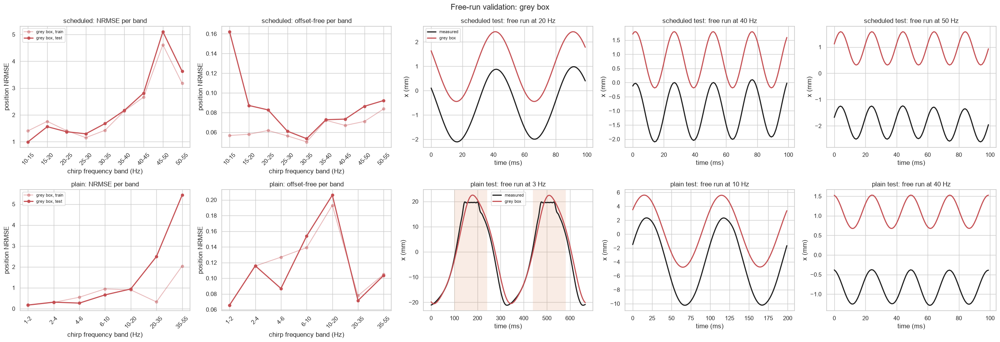

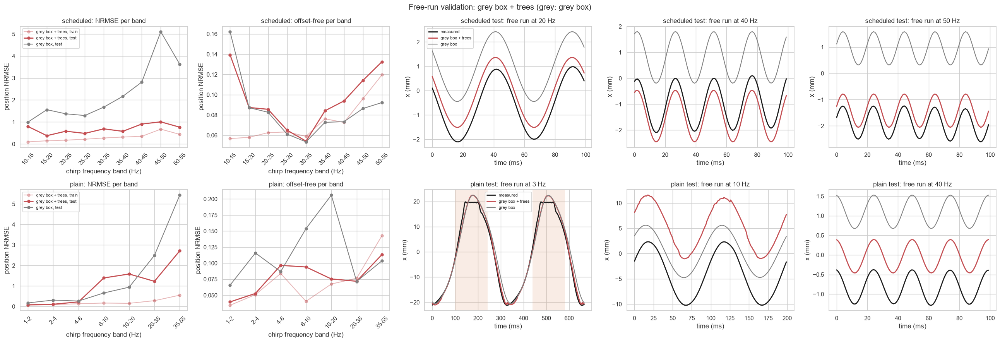

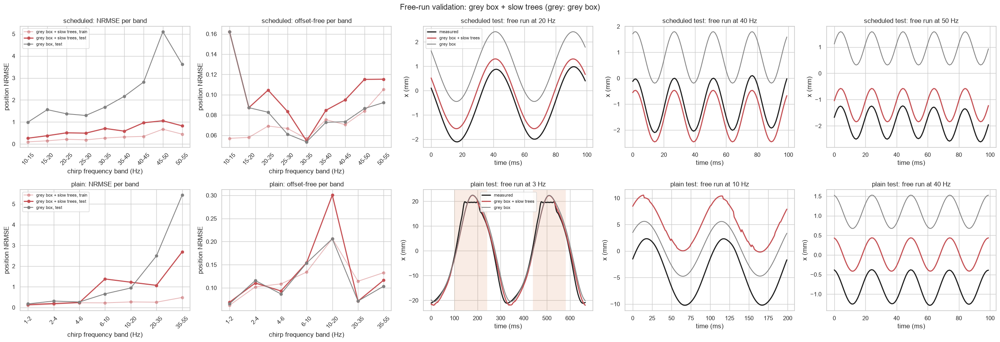

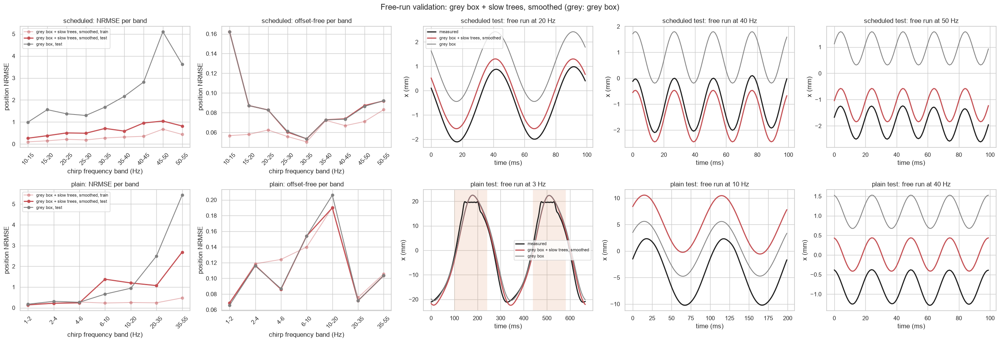

In [51]:
FREE_ROWS = {"scheduled": dict(runs=("scheduled train", "scheduled test"), bands=[(lo, lo + 5) for lo in range(10, 55, 5)],
                               trace_f=(20.0, 40.0, 50.0)),
             "plain": dict(runs=("plain train", "plain test"), bands=[(1, 2), (2, 4), (4, 6), (6, 10), (10, 20), (20, 35), (35, 55)],
                           trace_f=(3.0, 10.0, 40.0))}
RESULTS_FREE = {}


def validate_free(name, y_by_run, ref=None):
    "Free-run validation of one model: y_by_run maps each run in ML to its full-run prediction; stored in RESULTS_FREE[name]."
    res = {run: band_errors(y_by_run[run], ML[run]["d"], FREE_ROWS[row]["bands"], ML[run]["use"])
           for row in FREE_ROWS for run in FREE_ROWS[row]["runs"]}
    RESULTS_FREE[name] = dict(errors=res, y=y_by_run)
    R = RESULTS_FREE[ref] if ref else None
    fig, ax = plt.subplots(2, 5, figsize=(26, 9))
    for r_i, (row, cfg) in enumerate(FREE_ROWS.items()):
        labels = [f"{lo}-{hi}" for lo, hi in cfg["bands"]]
        for col, title in ((0, "NRMSE per band"), (1, "offset-free per band")):
            a_ = ax[r_i, col]
            for run, sp in zip(cfg["runs"], ("train", "test")):
                a_.plot(labels, res[run][:, col], marker="o", ms=5, **STYLE[sp], label=f"{name}, {sp}")
            if R:
                a_.plot(labels, R["errors"][cfg["runs"][1]][:, col], marker="o", ms=5, **REF, label=f"{ref}, test")
            a_.set(title=f"{row}: {title}", xlabel="chirp frequency band (Hz)", ylabel="position NRMSE")
            a_.tick_params(axis="x", labelrotation=45)
        ax[r_i, 0].legend(fontsize=8)
        run_t = cfg["runs"][1]
        e_d = ML[run_t]["d"]
        for j, f0 in enumerate(cfg["trace_f"]):
            a_ = ax[r_i, 2 + j]
            L = max(100, int(round(2 / f0 * 1000)))      # samples: 100 ms or two periods
            s0 = np.flatnonzero(ML[run_t]["use"] & (e_d["f"] >= f0))[0]
            w_ = slice(s0, s0 + L)
            t_ = (e_d["t"][w_] - e_d["t"][s0]) * 1e3
            a_.plot(t_, e_d["x"][w_] * 1e3, color="k", lw=2, label="measured")
            a_.plot(t_, y_by_run[run_t][w_] * 1e3, **STYLE["test"], label=name)
            if R:
                a_.plot(t_, R["y"][run_t][w_] * 1e3, **REF, label=ref)
            if not e_d["valid"][w_].all():
                a_.fill_between(t_, 0, 1, where=~e_d["valid"][w_], transform=a_.get_xaxis_transform(), color="C1", alpha=0.15, lw=0)
            a_.set(title=f"{run_t}: free run at {f0:.0f} Hz", xlabel="time (ms)", ylabel="x (mm)")
        ax[r_i, 2].legend(fontsize=8)
    fig.suptitle(f"Free-run validation: {name}" + (f" (grey: {ref})" if ref else ""))
    plt.tight_layout(); plt.show()


def corrected(learner, feat):
    "Full-run predictions of the grey box plus a learned correction, for every run in ML."
    return {run: e_["y_grey"] + np.where(np.isfinite(e_["y_grey"]), learner.predict(e_[feat]), np.nan) for run, e_ in ML.items()}


validate_free("grey box", {run: e_["y_grey"] for run, e_ in ML.items()})
validate_free("grey box + trees", corrected(learners["+ boosted trees"], "X"), ref="grey box")
validate_free("grey box + slow trees", corrected(slow_trees, "Xs"), ref="grey box")


sos_corr = signal.butter(2, F_SLOW / 500.0, output="sos")   # causal 8 Hz low-pass for the learned correction (usable online)


def corrected_smooth(learner, feat):
    "As corrected, with the learned correction smoothed by a causal 8 Hz low-pass (removes the trees' steps)."
    out = {}
    for run, e_ in ML.items():
        g = np.nan_to_num(learner.predict(e_[feat]))
        out[run] = e_["y_grey"] + np.where(np.isfinite(e_["y_grey"]), signal.sosfilt(sos_corr, g), np.nan)
    return out


validate_free("grey box + slow trees, smoothed", corrected_smooth(slow_trees, "Xs"), ref="grey box")

**Findings (learned correction, free run).**

- **Slow-only trees keep the offset gain but still harm the band:** their output is piecewise constant and jumps where a feature crosses a threshold; a jump inside a 100 ms window counts as error in the oscillation (offset-free at 45–55 Hz 0.055 → 0.073).
- **Smoothing the correction (causal, 8 Hz) removes that harm completely.** With the smoothed slow-only correction the offset-free error equals the grey box's in every band.
- **On the scheduled runs this is the best combination so far.** In free run the error including the offset drops by a factor 3–5 in every band (application band from about 1.7–5.1 to 0.6–1.0); the corrected predictions lie close to the measurement where the grey box alone was 1–2 mm off.
- **On the plain chirps part of the offset cannot be learned from the input.** The two plain runs have slow offsets of opposite sign at the same frequencies (about +4 mm and −2 mm at 12 Hz), under the same excitation: it depends on something not in the input (the state of the laser or the mount after the large strokes). The learner memorises the train run's offset (train errors 0.2–0.5, test 1–2.7) and gets 6–20 Hz worse on the test run (up to about 8 mm off at 10 Hz); 1–6 Hz and 20–55 Hz improve.
- **Where this leaves the model.** The grey box (Model C + D1 + laser, new spring) has the oscillation right to about 6–9 % over 10–55 Hz and describes large stroke at 1–6 Hz well. The smoothed slow correction adds the laser's slow offset where it is reproducible: the scheduled, small-stroke regime, which includes the application band. The run-dependent offset at large stroke it cannot predict.
- **Next:** PRBS as a validation outside the chirps; then new measurements (a medium-stroke run at 5–20 Hz, where training data are missing, and a repeat of a plain chirp, to see how reproducible the large-stroke offset is).

## Validation on PRBS

All fits and the learned correction used chirps. The PRBS run of 23 September (±5 A, bits of 7 ms, flat to about 55 Hz, 120 s) is a different excitation: broadband and random-like, with strokes up to about ±20 mm. It is used for validation only.

**Loading.** The same processing as `load_v2`, with two differences:
- **The sent current** is rebuilt from the firmware of that day (commit `07ab654`): a 15-bit shift register ($x^{15} + x^{14} + 1$, seed 1), each bit held 14 cycles (7 ms), at ±5 A. The bit index follows from the logged time, as the chirp phase does.
- **The pickup** is estimated with the 50 Hz window fit alone (no chirp harmonics to model). The broadband motion inside the 1 Hz window around 50 Hz is several times smaller than the 93 µm pickup, so the spline through the windows still finds it. That log has no idle window and no bias-corrected accelerometer.

The laser reaches its range limit briefly (about 200 samples); they are masked as before.

**Metric.** A PRBS has no chirp frequency, so the error per band comes from band-pass filtering (4th-order Butterworth, zero phase) both the error and the measured position into the bands 1–5, 5–10, 10–20, 20–35 and 35–55 Hz, in free run, on valid samples:

$$\mathrm{NRMSE}_b = \frac{\operatorname{rms}\big(\mathrm{BP}_b(\hat{y} - y)\big)}{\operatorname{rms}\big(\mathrm{BP}_b(y)\big)}$$

Unlike the chirp metric, this is offset-free by construction above 1 Hz. Compared: Model C + D1 + laser (old spring), the grey box (new spring), and the grey box with the smoothed slow correction (an excitation it never saw in training).

PRBS: 120000 samples, pickup 111.9 µm, 1.99 % masked, x from -20.4 to 20.0 mm


rebuilt PRBS against the target readback: delay 0.76 ms, gain 0.965, rms misfit 26.4 %


Model C + D1 + laser (old spring)  NRMSE per band: 1-5 Hz 0.27, 5-10 Hz 0.30, 10-20 Hz 0.35, 20-35 Hz 0.31, 35-55 Hz 0.42
grey box (new spring)              NRMSE per band: 1-5 Hz 0.29, 5-10 Hz 0.28, 10-20 Hz 0.24, 20-35 Hz 0.18, 35-55 Hz 0.38
grey box + slow trees, smoothed    NRMSE per band: 1-5 Hz 0.32, 5-10 Hz 0.28, 10-20 Hz 0.24, 20-35 Hz 0.19, 35-55 Hz 0.38


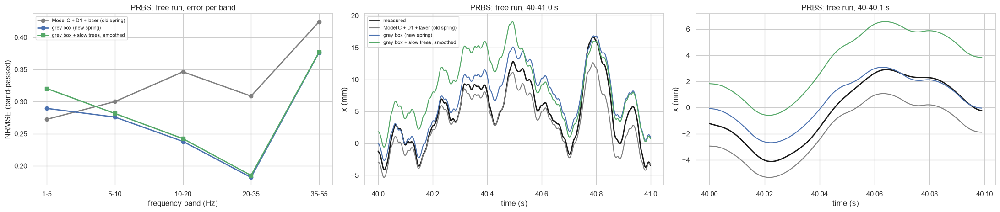

In [52]:
def load_prbs(path):
    "Load a PRBS run like load_v2: sent current rebuilt, 50 Hz pickup removed, 75 Hz low-pass, 1 kHz, clipping mask."
    raw = read_raw(path)
    t = raw["time_s"].to_numpy()
    pos_mm = raw["position_mm"].to_numpy()
    i_fn = prbs_current_fn(path)
    tc_, A_, th_, _ = pickup_windows(t, pos_mm, path)
    p_fn, _ = fit_pickup(tc_, A_, th_)
    x_full = signal.sosfiltfilt(sos_lp, (pos_mm - p_fn(t)) * 1e-3)
    v_full = np.gradient(x_full, 1 / FS_RAW)
    a_full = np.gradient(v_full, 1 / FS_RAW)
    keep = np.flatnonzero(t >= 0)[1::2]                 # 1 kHz (the first time stamp repeats)
    near = np.abs(pos_mm - X_CLIP_MM) <= CLIP_MARGIN_MM
    pad = int(round(CLIP_PAD * FS_RAW))
    bad = np.convolve(near.astype(float), np.ones(2 * pad + 1), mode="same") > 0
    d = dict(t=t[keep], x=x_full[keep], v=v_full[keep], a=a_full[keep], i=i_fn(t[keep]), i_fn=i_fn, path=path,
             valid=~bad[keep], f=np.full(len(keep), np.nan))
    d["sweep"] = d["t"] < 120.0
    print(f"PRBS: {len(d['t'])} samples, pickup {np.mean(A_) * 1e3:.1f} µm, {100 * (1 - d['valid'].mean()):.2f} % masked, "
          f"x from {d['x'].min() * 1e3:.1f} to {d['x'].max() * 1e3:.1f} mm")
    return d


PRBS_PATH = next(Path("data").glob("voice_coil_log_prbs_*.csv"))
d_prbs = load_prbs(PRBS_PATH)
# sanity check of the rebuilt current against the logged target readback (1.16 ms later, see section 1)
raw_p = read_raw(PRBS_PATH)
t_p = raw_p["time_s"].to_numpy()
tau_p, g_p, r_p = delay_gain(t_p[t_p > 1], raw_p["target_current_A"].to_numpy()[t_p > 1], d_prbs["i_fn"])
print(f"rebuilt PRBS against the target readback: delay {tau_p * 1e3:.2f} ms, gain {g_p:.3f}, rms misfit {r_p * 100:.1f} %")

BANDS_PRBS = [(1, 5), (5, 10), (10, 20), (20, 35), (35, 55)]


def prbs_band_errors(y_hat, d):
    "Per band: rms of the band-passed error over the rms of the band-passed measurement, on valid, finite samples."
    ok = d["valid"] & np.isfinite(y_hat) & (d["t"] >= 1.0)
    err = np.where(np.isfinite(y_hat), y_hat - d["x"], 0.0)
    out = []
    for lo, hi in BANDS_PRBS:
        sos_b = signal.butter(4, [lo / 500.0, hi / 500.0], btype="band", output="sos")
        out.append(np.sqrt(np.mean(signal.sosfiltfilt(sos_b, err)[ok] ** 2)) /
                   np.sqrt(np.mean(signal.sosfiltfilt(sos_b, d["x"])[ok] ** 2)))
    return np.array(out)


n_p = len(d_prbs["t"]) - BURN_IN - 1
y_old = np.r_[np.full(BURN_IN, np.nan), predict_sensor(magnets, p_S, tau_S, sens_S, d_prbs, np.array([BURN_IN]), n_p)[0]]
y_grey_p = free_run(d_prbs)
g_p_corr = signal.sosfilt(sos_corr, np.nan_to_num(slow_trees.predict(slow_features(d_prbs, y_grey_p))))
PRBS_MODELS = {"Model C + D1 + laser (old spring)": y_old, "grey box (new spring)": y_grey_p,
               "grey box + slow trees, smoothed": y_grey_p + np.where(np.isfinite(y_grey_p), g_p_corr, np.nan)}
PRBS_STYLE = {"Model C + D1 + laser (old spring)": dict(color="0.5", marker="o"), "grey box (new spring)": dict(color="C0", marker="o"),
              "grey box + slow trees, smoothed": dict(color="C2", marker="s")}   # one fixed colour per model

fig, ax = plt.subplots(1, 3, figsize=(22, 4.8))
labels = [f"{lo}-{hi}" for lo, hi in BANDS_PRBS]
for name, y_hat in PRBS_MODELS.items():
    be = prbs_band_errors(y_hat, d_prbs)
    print(f"{name:34s} NRMSE per band: " + ", ".join(f"{l} Hz {v:.2f}" for l, v in zip(labels, be)))
    ax[0].plot(labels, be, lw=2, ms=6, label=name, **PRBS_STYLE[name])
ax[0].set(xlabel="frequency band (Hz)", ylabel="NRMSE (band-passed)", title="PRBS: free run, error per band")
ax[0].legend(fontsize=8)
for a_, (t0, L) in zip(ax[1:], ((40.0, 1.0), (40.0, 0.1))):
    w_ = (d_prbs["t"] >= t0) & (d_prbs["t"] < t0 + L)
    a_.plot(d_prbs["t"][w_], d_prbs["x"][w_] * 1e3, color="k", lw=2, label="measured")
    for name, y_hat in PRBS_MODELS.items():
        a_.plot(d_prbs["t"][w_], y_hat[w_] * 1e3, lw=1.5, color=PRBS_STYLE[name]["color"], label=name)
    a_.set(xlabel="time (s)", ylabel="x (mm)", title=f"PRBS: free run, {t0:.0f}-{t0 + L:.1f} s")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Findings (PRBS).**

- **The PRBS is rebuilt correctly.** Away from the bit changes the rebuilt current has the sign of the logged readback in 99.99–100 % of the samples. The fit against the readback looks worse than for the chirps (0.76 ms, gain 0.965, 26 % misfit) only because of the bit edges: there the 0.5 ms grid and the stale rows cost a full 10 A jump for a sample or two.
- **The grey box with the new spring carries over to PRBS, and is the best from 5 Hz up.** At 10–35 Hz its error is about 30–40 % below the old spring's (0.24 / 0.18 against 0.35 / 0.31), and it follows the measured broadband motion closely, strokes up to about 17 mm included; the old spring under-reads the large swings.
- **At 1–5 Hz the two springs are about equal** (0.27 / 0.29).
- **The 35–55 Hz error is higher for all models (about 0.4):** a PRBS with 7 ms bits has little energy there, and the pickup on that day was larger (112 µm).
- **The learned slow correction does not carry over to PRBS.** The band errors from 1 Hz up barely change, but in the time trace it shifts the prediction 2–4 mm the wrong way: a broadband PRBS gives operating conditions the learner never saw. The correction is valid for chirp-like, small-stroke excitation only.
- **Conclusion:** the grey box (Model C + D1 + laser, new spring) is the model that carries over, from chirps to PRBS and from small to large stroke; the learned correction is a narrow add-on for one kind of excitation.

## More runs: the plain chirps of 23 September

Three more plain chirps exist, recorded on 23 September with the same hardware (22.3 mm magnet gap), the same laser calibration (the same sign, the same range limit at about +19.76 mm) and the same chirp formula (firmware commit `b29c717`, parameters from the file name):

| Run | Current | Chirp |
|---|---|---|
| 23 Sep, 15:18 | 5.0 A | 1–50 Hz |
| 23 Sep, 15:55 | 6.5 A | 1–55 Hz |
| 23 Sep, 16:05 | 6.5 A | 1–55 Hz |

They are in the older log format (no idle window, no bias-corrected accelerometer), which `load_v2` now reads. No fit used them. Three uses:

1. **Timing:** the rebuilt sent current against the logged readback of each run (as in section 1: 1.16 ms and a gain of 1 if the reconstruction holds).
2. **Reproducibility of the slow offset at large stroke.** The two plain chirps of 2 October had slow offsets of opposite sign at the same frequencies, which the learned correction could not predict; but they were at different currents (6.5 and 6 A). The two 6.5 A runs of 23 September and the 6.5 A run of 2 October are three repeats of one excitation: if their slow offsets differ, the offset at large stroke varies from run to run.
3. **Validation of the grey box** (Model C + D1 + laser, new spring) in free run, against the old spring, on runs no fit has seen: a third and fourth large-stroke run, one at a different current (5 A).

Clipped samples are masked as before (within 0.1 mm of the range limit, widened by 50 ms).

In [53]:
SEP_LOGS = {f"Sep {Path(p).name.split('_')[-1][:4]}, {Path(p).name.split('_')[4]}": Path(p)
            for p in sorted(Path("data").glob("voice_coil_log_chirp_*_20260923_*.csv"))}


def add_clip_mask(d, path):
    "The clipping mask of the masking section, for any run: within CLIP_MARGIN_MM of the range limit, widened by CLIP_PAD."
    raw_ = read_raw(path)
    t_ = raw_["time_s"].to_numpy()
    near = np.abs(raw_["position_mm"].to_numpy() - X_CLIP_MM) <= CLIP_MARGIN_MM
    pad = int(round(CLIP_PAD * FS_RAW))
    bad = np.convolve(near.astype(float), np.ones(2 * pad + 1), mode="same") > 0
    d["valid"] = ~(np.interp(d["t"], t_, bad.astype(float)) > 0)
    return d


SEP = {}
for name, path in SEP_LOGS.items():
    SEP[name] = add_clip_mask(load_v2(path), path)
    raw_ = read_raw(path)
    t_ = raw_["time_s"].to_numpy()
    tau_, g_, r_ = delay_gain(t_[t_ > 1], raw_["target_current_A"].to_numpy()[t_ > 1], SEP[name]["i_fn"])
    print(f"{name:16s} {path.name[:46]}: {len(SEP[name]['t'])} samples, {100 * (1 - SEP[name]['valid'].mean()):.1f} % masked; "
          f"rebuilt current against the readback: delay {tau_ * 1e3:.2f} ms, gain {g_:.3f}, misfit {r_ * 100:.1f} %")

Sep 1518, 5.0A   voice_coil_log_chirp_5.0A_1.0to50.0Hz_120.0s_2: 120000 samples, 14.4 % masked; rebuilt current against the readback: delay 1.16 ms, gain 0.999, misfit 3.9 %


Sep 1555, 6.5A   voice_coil_log_chirp_6.5A_1.0to55.0Hz_120.0s_2: 120000 samples, 27.0 % masked; rebuilt current against the readback: delay 1.16 ms, gain 0.999, misfit 4.1 %


Sep 1605, 6.5A   voice_coil_log_chirp_6.5A_1.0to55.0Hz_120.0s_2: 120000 samples, 18.7 % masked; rebuilt current against the readback: delay 1.18 ms, gain 0.999, misfit 4.3 %


### Is the slow offset at large stroke reproducible?

The slow part of the position (below `F_SLOW` = 8 Hz, zero phase) against the chirp frequency, from 12 Hz up (below, the chirp's own fundamental would pass the filter), for all five plain chirps: the three 6.5 A runs (two of 23 September, one of 2 October), the 6 A run of 2 October and the 5 A run of 23 September. Printed: the mean slow position near 12, 20, 34.4 and 47.7 Hz per run.

Oct 0936, 6.5A   slow position at 12, 20, 34.4, 47.7 Hz: +3.94, +1.01, +0.56, -0.48 mm
Oct 0942, 6.0A   slow position at 12, 20, 34.4, 47.7 Hz: -2.18, -0.98, -0.90, -1.71 mm
Sep 1518, 5.0A   slow position at 12, 20, 34.4, 47.7 Hz: +0.13, -0.01, -0.01, -0.67 mm
Sep 1555, 6.5A   slow position at 12, 20, 34.4, 47.7 Hz: +4.33, +1.25, +0.77, -0.27 mm
Sep 1605, 6.5A   slow position at 12, 20, 34.4, 47.7 Hz: -3.99, -1.29, -1.09, -1.95 mm


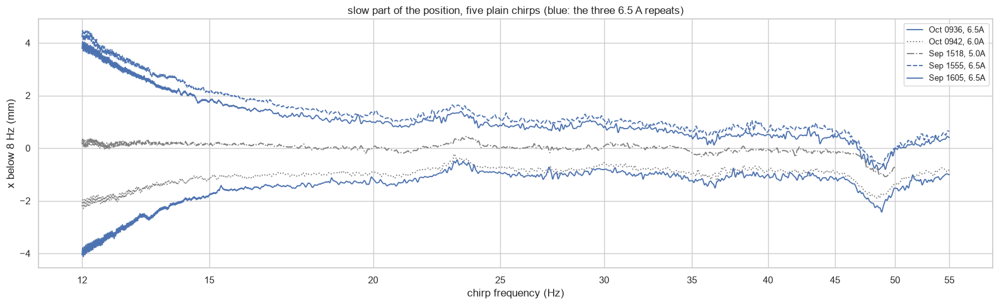

In [54]:
PLAIN_ALL = {"Oct 0936, 6.5A": DATA["chirp"]["train"], "Oct 0942, 6.0A": DATA["chirp"]["test"], **SEP}
PLAIN_STYLE = {name: dict(color="C0" if "6.5A" in name else "0.5", ls=ls)   # the 6.5 A repeats in blue (line style per run), others in grey
               for name, ls in zip(PLAIN_ALL, ("-", ":", "-.", "--", "-"))}
PLAIN_STYLE["Sep 1518, 5.0A"] = dict(color="0.5", ls="-.")

fig, ax = plt.subplots(figsize=(16, 5))
for name, d_ in PLAIN_ALL.items():
    slow_ = signal.sosfiltfilt(sos_slow, d_["x"])
    sel_ = d_["f"] >= 12.0
    ax.plot(d_["f"][sel_], slow_[sel_] * 1e3, lw=1.3, label=name, **PLAIN_STYLE[name])
    vals = [np.mean(slow_[np.abs(d_["f"] - f0) < 0.5]) * 1e3 for f0 in (12.0, 20.0, 34.4, 47.7)]
    print(f"{name:16s} slow position at 12, 20, 34.4, 47.7 Hz: " + ", ".join(f"{v:+.2f}" for v in vals) + " mm")
ax.set(xscale="log", xlabel="chirp frequency (Hz)", ylabel="x below 8 Hz (mm)", title="slow part of the position, five plain chirps (blue: the three 6.5 A repeats)")
ax.set_xticks([12, 15, 20, 25, 30, 35, 40, 45, 50, 55]); ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

### Validation on the September runs

The grey box (Model C + D1 + laser, new spring) and the old spring (Model C + D1 + laser), each simulated over each September run from its start, in free run. Per band of the chirp frequency, on valid samples (from 1 s, clipping masked): the position NRMSE as it is, and offset-free (non-overlapping 100 ms windows with their straight line removed), as in the free-run validation. Colours as everywhere: the grey box in red, the reference in grey.

Sep 1518, 5.0A   grey box (new spring)  NRMSE: 1-2 0.16, 2-4 0.33, 4-6 0.25, 6-10 0.32, 10-20 0.43, 20-35 1.71, 35-50 3.79 | offset-free: 0.054, 0.107, 0.085, 0.173, 0.217, 0.059, 0.110


Sep 1518, 5.0A   old spring             NRMSE: 1-2 0.46, 2-4 0.65, 4-6 0.39, 6-10 0.29, 10-20 0.25, 20-35 0.44, 35-50 0.75 | offset-free: 0.047, 0.112, 0.104, 0.174, 0.218, 0.059, 0.110


Sep 1555, 6.5A   grey box (new spring)  NRMSE: 1-2 0.16, 2-4 0.28, 4-6 0.51, 6-10 0.97, 10-20 0.98, 20-35 0.32, 35-50 1.37 | offset-free: 0.066, 0.105, 0.120, 0.133, 0.189, 0.084, 0.093


Sep 1555, 6.5A   old spring             NRMSE: 1-2 0.57, 2-4 0.72, 4-6 1.53, 6-10 0.97, 10-20 1.04, 20-35 1.52, 35-50 1.62 | offset-free: 0.088, 0.202, 0.550, 0.137, 0.192, 0.085, 0.093


Sep 1605, 6.5A   grey box (new spring)  NRMSE: 1-2 0.17, 2-4 0.31, 4-6 0.28, 6-10 0.97, 10-20 1.16, 20-35 2.52, 35-50 5.02 | offset-free: 0.067, 0.115, 0.091, 0.134, 0.183, 0.075, 0.093


Sep 1605, 6.5A   old spring             NRMSE: 1-2 0.55, 2-4 0.73, 4-6 0.71, 6-10 1.01, 10-20 1.08, 20-35 1.14, 35-50 2.34 | offset-free: 0.085, 0.205, 0.245, 0.154, 0.186, 0.076, 0.093


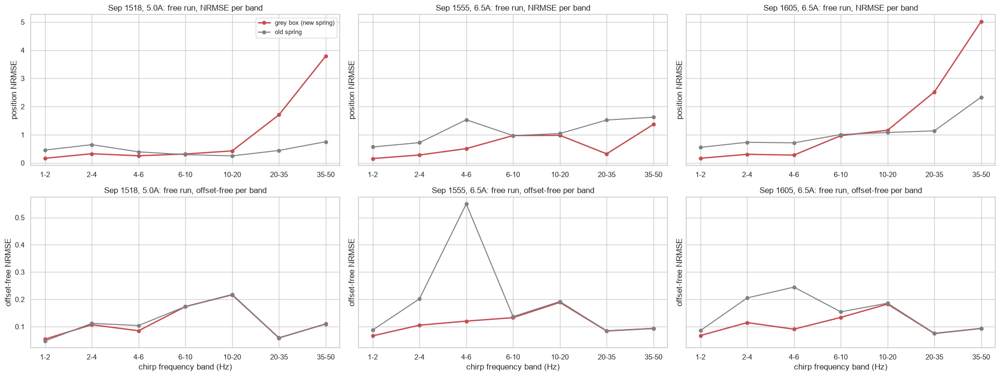

In [55]:
BANDS_SEP = [(1, 2), (2, 4), (4, 6), (6, 10), (10, 20), (20, 35), (35, 50)]
labels = [f"{lo}-{hi}" for lo, hi in BANDS_SEP]
fig, ax = plt.subplots(2, len(SEP), figsize=(7 * len(SEP), 8), sharey="row")
for col, (name, d_) in enumerate(SEP.items()):
    use_ = d_["valid"] & (d_["t"] >= 1.0) & d_["sweep"]
    for lab, Fs_, p_, style in (("grey box (new spring)", spring_E, p_E, STYLE["test"]), ("old spring", magnets, p_S, REF)):
        n_ = len(d_["t"]) - BURN_IN - 1
        y_ = np.r_[np.full(BURN_IN, np.nan), predict_sensor(Fs_, p_, tau_S, sens_S, d_, np.array([BURN_IN]), n_)[0]]
        be = band_errors(y_, d_, BANDS_SEP, use_ & np.isfinite(y_))
        print(f"{name:16s} {lab:22s} NRMSE: " + ", ".join(f"{l} {v:.2f}" for l, v in zip(labels, be[:, 0]))
              + " | offset-free: " + ", ".join(f"{v:.3f}" for v in be[:, 1]))
        ax[0, col].plot(labels, be[:, 0], marker="o", ms=5, label=lab, **style)
        ax[1, col].plot(labels, be[:, 1], marker="o", ms=5, label=lab, **style)
    ax[0, col].set(title=f"{name}: free run, NRMSE per band", ylabel="position NRMSE")
    ax[1, col].set(title=f"{name}: free run, offset-free per band", ylabel="offset-free NRMSE", xlabel="chirp frequency band (Hz)")
ax[0, 0].legend(fontsize=9)
plt.tight_layout(); plt.show()

**Findings (September runs).**

- **The older runs fit the processing.** For all three, the rebuilt sent current matches the logged readback: delay 1.16–1.18 ms, gain 0.999, misfit about 4 %, as for the October runs. 14–27 % of the samples are masked as clipped.
- **The slow offset at large stroke is not reproducible: its sign varies from run to run.** Under the identical excitation (6.5 A, three runs) it starts at +3.9, +4.3 and −4.0 mm at 12 Hz, and decays towards the end of the sweep along mirrored paths. Its size grows with the current: about 0 mm at 5 A, 2 mm at 6 A, 4 mm at 6.5 A. A dip near 48–49 Hz is common to all runs.
- **So no model can predict that offset from the input**, grey box or learned: its sign is not in the input. This settles the question the new measurements were meant to answer, with existing data. Its cause (the laser or its mount settling one way or the other after the large strokes, or the mass itself) stays open.
- **The new spring is better at large stroke on all three runs, which no fit has seen.** At 1–6 Hz the error drops from 0.39–1.53 to 0.16–0.51; offset-free the new spring is as good as or better than the old one in every band (4–6 Hz on the 15:55 run: 0.55 → 0.12).
- **Above 20 Hz the errors including the offset follow the sign of each run's offset, not the model.** The grey box with the new spring produces a slow offset of its own; it matches the runs whose offset is positive (15:55: 0.32 against 1.52 at 20–35 Hz) and contradicts those whose offset is negative or zero (16:05: 5.0 against 2.3 at 35–50 Hz). Offset-free, both springs are the same there.
- **The new spring's asymmetry has probably absorbed part of one run's offset.** It was fitted on the 6.5 A run of 2 October alone, whose offset was positive (+3.9 mm); its own offset leans the same way. A spring fitted on several runs with offsets of both signs would average that out.

## The spring from several runs

The spring fitted on one run (the 6.5 A plain chirp of 2 October) has probably absorbed part of that run's slow offset into its asymmetry: the offset's sign varies from run to run, and the model now produces a positive offset of its own. Here the spring is fitted on four plain runs at once, two with a positive and two with a negative offset, and each run gets its own constant force $F_{0,r}$ in the fit:

$$m\ddot{x} = (\Gamma + \Gamma_1 x + \Gamma_2 x^2)\, i_\text{sent}(t - \tau_d) - c\,\dot{x} - \left(\frac{C_R}{(g - x)^3} - \frac{C_L}{(g + x)^3}\right) + F_{0,r}$$

- **Fit runs:** the plain chirps at 6.0–6.5 A: 2 October 09:36 (6.5 A, offset +3.9 mm at 12 Hz), 2 October 09:42 (6.0 A, −2.2 mm), 23 September 15:55 (6.5 A, +4.3 mm) and 16:05 (6.5 A, −4.0 mm). Valid samples, chirp below `F_SPRING` = 10 Hz, from 1 s.
- **$F_{0,r}$ only keeps the fit honest:** it takes up each run's constant offset force, so the spring's asymmetry ($C_R \neq C_L$, $\Gamma_1$) is not bent to explain it. It is not part of the model used afterwards.
- As before: $\Gamma$, $c$ and $\tau_d$ from Model C + D1 + laser; linear in $\Gamma_1, \Gamma_2, C_R, C_L, F_{0,r}$ for a fixed effective gap $g$ ($C_R, C_L \geq 0$); $g$ on the grid `G_GRID`.
- **Validated on what the fit did not use:** the 5 A plain chirp of 23 September, the PRBS run, and the scheduled chirps.

Printed: the effective gap, the parameters next to those of the single-run fit, the stiffness at $x = 0$, the motor constant at ±15 mm, and $F_{0,r}$ per run.

In [56]:
FIT_RUNS_M = {"Oct 0936, 6.5A": DATA["chirp"]["train"], "Oct 0942, 6.0A": DATA["chirp"]["test"],
              "Sep 1555, 6.5A": SEP["Sep 1555, 6.5A"], "Sep 1605, 6.5A": SEP["Sep 1605, 6.5A"]}
rows_m = []
for r_i, (name, d_) in enumerate(FIT_RUNS_M.items()):
    sel_ = d_["valid"] & (d_["f"] <= F_SPRING) & (d_["t"] >= 1.0)
    rows_m.append(dict(x=d_["x"][sel_], v=d_["v"][sel_], a=d_["a"][sel_], i=d_["i_fn"](d_["t"][sel_] - tau_S), r=r_i))
x_m_ = np.concatenate([r["x"] for r in rows_m]); v_m_ = np.concatenate([r["v"] for r in rows_m])
a_m_ = np.concatenate([r["a"] for r in rows_m]); i_m_ = np.concatenate([r["i"] for r in rows_m])
run_m_ = np.concatenate([np.full(len(r["x"]), r["r"]) for r in rows_m])
y_m_ = M * a_m_ - p_S[0] * i_m_ + p_S[1] * v_m_          # what Gamma1 x i + Gamma2 x^2 i - F_s + F0_r must explain
ONEHOT = np.column_stack([(run_m_ == r).astype(float) for r in range(len(FIT_RUNS_M))])
w_m_ = np.concatenate([np.full(len(r["x"]), 1 / np.sqrt(len(r["x"]))) for r in rows_m])   # each run weighs the same


def fit_spring_multi(g):
    "Least squares for [Gamma1, Gamma2, C_R, C_L, F0_1..F0_R] at effective gap g; returns the parameters and the weighted rms residual."
    A = np.column_stack([x_m_ * i_m_, x_m_ ** 2 * i_m_, -1 / (g - x_m_) ** 3, 1 / (g + x_m_) ** 3, ONEHOT])
    sc = np.linalg.norm(A * w_m_[:, None], axis=0)
    lb = [-np.inf, -np.inf, 0, 0] + [-np.inf] * len(FIT_RUNS_M)
    q = lsq_linear(A * w_m_[:, None] / sc, y_m_ * w_m_, bounds=(lb, np.inf)).x / sc
    return q, np.sqrt(np.sum(((A @ q - y_m_) * w_m_) ** 2) / np.sum(w_m_ ** 2))


ok_gm = G_GRID > np.abs(x_m_).max() + 1e-3
scan_gm = [(g, *fit_spring_multi(g)) for g in G_GRID[ok_gm]]
g_multi, q_multi, cost_multi = min(scan_gm, key=lambda r: r[2])
p_M = np.r_[p_S[0], p_S[1], q_multi[:4]]                # [Gamma, c, Gamma1, Gamma2, C_R, C_L]
spring_M = lambda x, u, q, g=g_multi: q[2] / (g - x) ** 3 - q[3] / (g + x) ** 3 - (q[0] * x + q[1] * x ** 2) * u
k_m = 3 * (q_multi[2] + q_multi[3]) / g_multi ** 4
print(f"{len(x_m_)} samples from {len(FIT_RUNS_M)} runs; best effective gap g = {g_multi * 1e3:.1f} mm (single run: {g_best * 1e3:.1f} mm)")
print(f"four runs : Gamma1 = {q_multi[0]:.4g}, Gamma2 = {q_multi[1]:.4g}, C_R = {q_multi[2]:.4g}, C_L = {q_multi[3]:.4g} (C_R/C_L = {q_multi[2] / q_multi[3]:.3f})")
print(f"one run   : Gamma1 = {G1_sp:.4g}, Gamma2 = {G2_sp:.4g}, C_R = {CR_sp:.4g}, C_L = {CL_sp:.4g} (C_R/C_L = {CR_sp / CL_sp:.3f})")
print(f"stiffness at x = 0: {k_m:.3g} N/m (resonance {np.sqrt(k_m / M) / (2 * np.pi):.2f} Hz; single run {k_sp:.3g} N/m); "
      f"Gamma(x)/Gamma at -15, +15 mm: " + ", ".join(f"{1 + (q_multi[0] * xx + q_multi[1] * xx ** 2) / p_S[0]:.3f}" for xx in (-15e-3, 15e-3)))
print("F0 per run (N): " + ", ".join(f"{n} {f0:+.1f}" for n, f0 in zip(FIT_RUNS_M, q_multi[4:])))
print(f"static force at x = 0 from the magnets: four runs {(q_multi[2] - q_multi[3]) / g_multi ** 3:+.1f} N, one run {(CR_sp - CL_sp) / g_best ** 3:+.1f} N")

165324 samples from 4 runs; best effective gap g = 40.0 mm (single run: 38.0 mm)
four runs : Gamma1 = -783.2, Gamma2 = -3.096e+05, C_R = 0.008052, C_L = 0.006227 (C_R/C_L = 1.293)
one run   : Gamma1 = 962.9, Gamma2 = -2.204e+05, C_R = 0.003707, C_L = 0.004447 (C_R/C_L = 0.834)
stiffness at x = 0: 1.67e+04 N/m (resonance 2.87 Hz; single run 1.17e+04 N/m); Gamma(x)/Gamma at -15, +15 mm: 0.747, 0.645
F0 per run (N): Oct 0936, 6.5A +12.7, Oct 0942, 6.0A -13.8, Sep 1555, 6.5A +8.8, Sep 1605, 6.5A -38.3
static force at x = 0 from the magnets: four runs +28.5 N, one run -13.5 N


### Does the model still lean to one side?

Each spring's own slow offset under a 6.5 A plain chirp: the model simulated in free run on the 23 September 15:55 run, its slow part (below 8 Hz) against the chirp frequency, with the measured slow parts of the two 23 September 6.5 A repeats (offsets of opposite sign) for reference. A model without a lean should sit between them.

old spring             own slow position at 12, 20, 34.4, 47.7 Hz: +0.25, -0.01, -0.19, -0.24 mm


spring from one run    own slow position at 12, 20, 34.4, 47.7 Hz: +0.44, +0.90, +1.07, +1.11 mm


spring from four runs  own slow position at 12, 20, 34.4, 47.7 Hz: -1.93, -1.81, -1.75, -1.73 mm


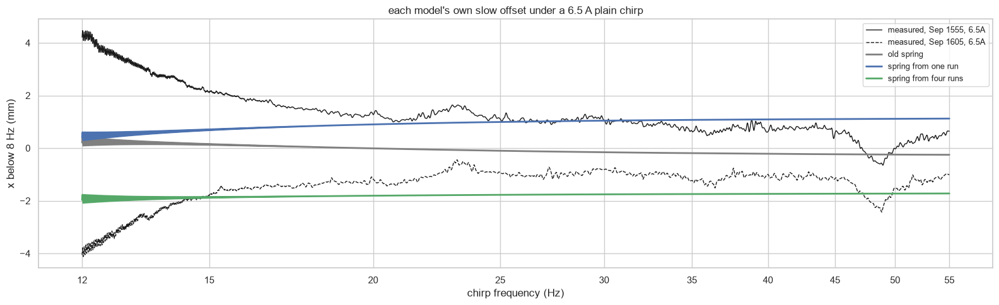

In [57]:
SPRINGS = {"old spring": (magnets, p_S, dict(color="0.5")), "spring from one run": (spring_E, p_E, dict(color="C0")),
           "spring from four runs": (spring_M, p_M, dict(color="C2"))}   # one fixed colour per model


def sim_free(Fs_, p_, d_):
    "The grey box with this force law, over the whole run d_ from its start (after the burn-in); NaN before."
    n_ = len(d_["t"]) - BURN_IN - 1
    return np.r_[np.full(BURN_IN, np.nan), predict_sensor(Fs_, p_, tau_S, sens_S, d_, np.array([BURN_IN]), n_)[0]]


d_ref = SEP["Sep 1555, 6.5A"]
sel_ = d_ref["f"] >= 12.0
fig, ax = plt.subplots(figsize=(16, 5))
for name in ("Sep 1555, 6.5A", "Sep 1605, 6.5A"):
    ax.plot(SEP[name]["f"][sel_], signal.sosfiltfilt(sos_slow, SEP[name]["x"])[sel_] * 1e3, color="k", lw=1, ls="-" if "1555" in name else "--",
            label=f"measured, {name}")
for name, (Fs_, p_, st) in SPRINGS.items():
    y_ = sim_free(Fs_, p_, d_ref)
    slow_ = signal.sosfiltfilt(sos_slow, np.nan_to_num(y_, nan=y_[BURN_IN]))
    ax.plot(d_ref["f"][sel_], slow_[sel_] * 1e3, lw=2, label=name, **st)
    print(f"{name:22s} own slow position at 12, 20, 34.4, 47.7 Hz: "
          + ", ".join(f"{np.mean(slow_[np.abs(d_ref['f'] - f0) < 0.5]) * 1e3:+.2f}" for f0 in (12.0, 20.0, 34.4, 47.7)) + " mm")
ax.set(xscale="log", xlabel="chirp frequency (Hz)", ylabel="x below 8 Hz (mm)", title="each model's own slow offset under a 6.5 A plain chirp")
ax.set_xticks([12, 15, 20, 25, 30, 35, 40, 45, 50, 55]); ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

### Validation on what the fit did not use

1. **The 5 A plain chirp of 23 September:** per band of the chirp frequency, in free run, on valid samples, the position NRMSE as it is and offset-free (as in the free-run validation).
2. **PRBS:** per band, band-passed, in free run (as in the PRBS section).

Then the standard validation on the scheduled chirps (next cell), against the spring from one run.

old spring             5 A run NRMSE: 1-2 0.46, 2-4 0.65, 4-6 0.39, 6-10 0.29, 10-20 0.25, 20-35 0.44, 35-50 0.75 | offset-free: 0.047, 0.112, 0.104, 0.174, 0.218, 0.059, 0.110
                       PRBS NRMSE: 1-5 0.27, 5-10 0.30, 10-20 0.35, 20-35 0.31, 35-55 0.42


spring from one run    5 A run NRMSE: 1-2 0.16, 2-4 0.33, 4-6 0.25, 6-10 0.32, 10-20 0.43, 20-35 1.71, 35-50 3.79 | offset-free: 0.054, 0.107, 0.085, 0.173, 0.217, 0.059, 0.110
                       PRBS NRMSE: 1-5 0.29, 5-10 0.28, 10-20 0.24, 20-35 0.18, 35-55 0.38


spring from four runs  5 A run NRMSE: 1-2 0.18, 2-4 0.16, 4-6 0.26, 6-10 0.39, 10-20 0.88, 20-35 2.97, 35-50 4.07 | offset-free: 0.034, 0.076, 0.082, 0.175, 0.218, 0.059, 0.110
                       PRBS NRMSE: 1-5 0.22, 5-10 0.27, 10-20 0.23, 20-35 0.17, 35-55 0.37


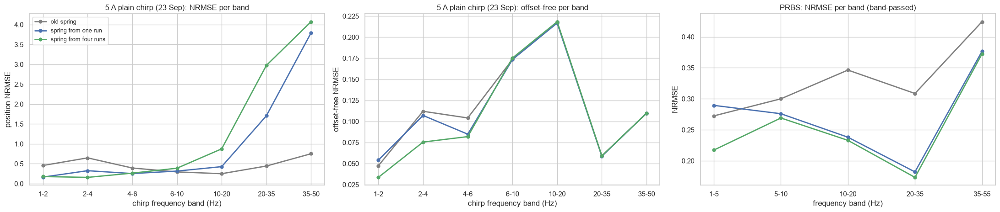

In [58]:
d_5a = SEP["Sep 1518, 5.0A"]
use_5a = d_5a["valid"] & (d_5a["t"] >= 1.0) & d_5a["sweep"]
labels_s = [f"{lo}-{hi}" for lo, hi in BANDS_SEP]
labels_p = [f"{lo}-{hi}" for lo, hi in BANDS_PRBS]
fig, ax = plt.subplots(1, 3, figsize=(22, 4.8))
for name, (Fs_, p_, st) in SPRINGS.items():
    y_5 = sim_free(Fs_, p_, d_5a)
    be = band_errors(y_5, d_5a, BANDS_SEP, use_5a & np.isfinite(y_5))
    y_p = sim_free(Fs_, p_, d_prbs)
    bp = prbs_band_errors(y_p, d_prbs)
    print(f"{name:22s} 5 A run NRMSE: " + ", ".join(f"{l} {v:.2f}" for l, v in zip(labels_s, be[:, 0]))
          + " | offset-free: " + ", ".join(f"{v:.3f}" for v in be[:, 1]))
    print(f"{'':22s} PRBS NRMSE: " + ", ".join(f"{l} {v:.2f}" for l, v in zip(labels_p, bp)))
    ax[0].plot(labels_s, be[:, 0], marker="o", ms=5, lw=2, label=name, **st)
    ax[1].plot(labels_s, be[:, 1], marker="o", ms=5, lw=2, label=name, **st)
    ax[2].plot(labels_p, bp, marker="o", ms=5, lw=2, label=name, **st)
ax[0].set(title="5 A plain chirp (23 Sep): NRMSE per band", xlabel="chirp frequency band (Hz)", ylabel="position NRMSE")
ax[1].set(title="5 A plain chirp (23 Sep): offset-free per band", xlabel="chirp frequency band (Hz)", ylabel="offset-free NRMSE")
ax[2].set(title="PRBS: NRMSE per band (band-passed)", xlabel="frequency band (Hz)", ylabel="NRMSE")
ax[0].legend(fontsize=9)
plt.tight_layout(); plt.show()

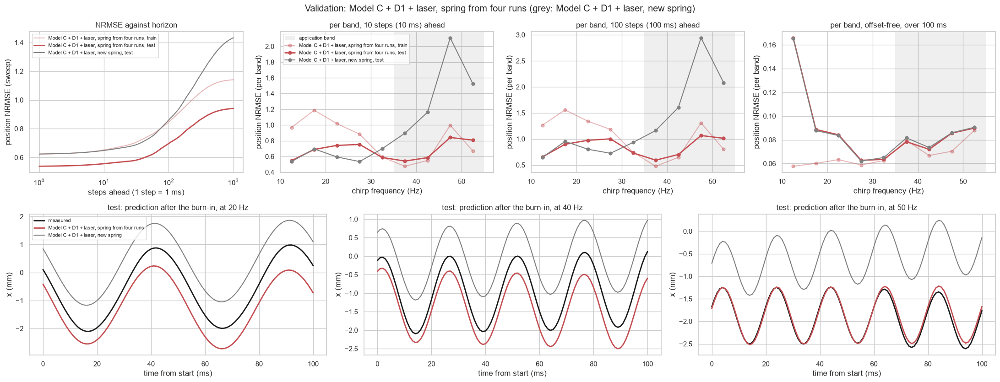

In [59]:
validate("Model C + D1 + laser, spring from four runs", lambda d, s, H: predict_sensor(spring_M, p_M, tau_S, sens_S, d, s, H),
         ref="Model C + D1 + laser, new spring")

**Findings (spring from four runs).**

- **The spring is no longer bent by one run's offset, but the model still leans, now the other way.** Under a 6.5 A plain chirp its own slow position sits at −1.9 mm (one-run spring: about +1 mm). The per-run offset forces come out with the signs of the runs' measured offsets (+12.7, −13.8, +8.8, −38.3 N).
- **The model's resting level is not determined by the data.** A constant force can be split freely between the magnets' static force (here +28.5 N at $x = 0$) and the per-run offset forces: the fit picks a split, the data do not.
- **The measured resting level itself moves from run to run** (next cell): at 0 A, at rest, the four October runs read +1.3, −0.5, +1.5 and +0.2 mm, up to 2 mm apart on one day. A mass held by magnets on an air bearing should rest at the same place each time: the laser's zero, or its mount, most likely shifts between runs, in line with everything found about the slow offset.
- **The stiffness and the motor constant's fall-off hold on what the fit did not use.** Stiffness 1.67·10⁴ N/m (resonance 2.9 Hz), effective gap 40 mm, $\Gamma$ at ∓15 mm 0.75 / 0.65. On the 5 A run the offset-free error at 1–4 Hz improves (0.054 / 0.107 → 0.034 / 0.076); on PRBS every band improves slightly (0.17–0.37, the best so far); the scheduled runs' offset-free error is identical.
- **The scheduled runs' errors including the offset improve a lot** (45–50 Hz at 10 ms: 2.1 → 0.85), but largely because the −1.9 mm lean happens to match those runs' level: not a real gain.
- **Next: a convention for the resting level.** The per-run offset forces sum to zero, so the model's resting level is the average over the fit runs, the most neutral choice the data allow. The absolute resting level stays uncertain by about ±2 mm in the laser's frame: for control a slow disturbance, the job of the filter's offset states, not of the model.

In [60]:
# the measured position at rest (0 A, idle window) in the runs that have one
for key, raw_ in RAW_DF.items():
    idle_ = raw_["time_s"] < 0
    print(f"{key[0]:10s} {key[1]:5s}: position at rest (0 A, idle window) {raw_['position_mm'][idle_].mean():+.2f} mm")

chirpsched train: position at rest (0 A, idle window) +1.49 mm
chirpsched test : position at rest (0 A, idle window) +0.17 mm
chirp      train: position at rest (0 A, idle window) +1.31 mm
chirp      test : position at rest (0 A, idle window) -0.50 mm


### The spring from four runs, with the offset forces summing to zero

The same fit, with one condition: $\sum_r F_{0,r} = 0$. The common part of the constant force then goes to the spring, and the model's resting level becomes the average over the four fit runs. In the regression, the last run's offset force is minus the sum of the others. The stiffness and the fall-off of the motor constant should hardly change; only the spring's constant part (the static force at $x = 0$) does.

Checked as before: each model's own slow offset under a 6.5 A plain chirp; the 5 A plain chirp and PRBS; and the standard validation on the scheduled chirps, against the spring from four runs without the condition.

effective gap g = 39.5 mm; rms residual 399.8 N (without the condition 399.8 N)
Gamma1 = -816.1, Gamma2 = -3.111e+05, C_R = 0.007781, C_L = 0.005716 (C_R/C_L = 1.361)
stiffness at x = 0: 1.66e+04 N/m (resonance 2.86 Hz); Gamma(x)/Gamma at -15, +15 mm: 0.748, 0.641
static force at x = 0 from the magnets: +33.5 N (without the condition +28.5 N)
F0 per run (N): Oct 0936, 6.5A +20.4, Oct 0942, 6.0A -6.2, Sep 1555, 6.5A +16.5, Sep 1605, 6.5A -30.7


spring from one run              own slow position at 12, 20, 34.4, 47.7 Hz: +0.44, +0.90, +1.07, +1.11 mm
                                 5 A run NRMSE: 1-2 0.16, 2-4 0.33, 4-6 0.25, 6-10 0.32, 10-20 0.43, 20-35 1.71, 35-50 3.79 | offset-free: 0.054, 0.107, 0.085, 0.173, 0.217, 0.059, 0.110
                                 PRBS NRMSE: 1-5 0.29, 5-10 0.28, 10-20 0.24, 20-35 0.18, 35-55 0.38


spring from four runs            own slow position at 12, 20, 34.4, 47.7 Hz: -1.93, -1.81, -1.75, -1.73 mm
                                 5 A run NRMSE: 1-2 0.18, 2-4 0.16, 4-6 0.26, 6-10 0.39, 10-20 0.88, 20-35 2.97, 35-50 4.07 | offset-free: 0.034, 0.076, 0.082, 0.175, 0.218, 0.059, 0.110
                                 PRBS NRMSE: 1-5 0.22, 5-10 0.27, 10-20 0.23, 20-35 0.17, 35-55 0.37


spring from four runs, sum zero  own slow position at 12, 20, 34.4, 47.7 Hz: -2.41, -2.19, -2.08, -2.06 mm
                                 5 A run NRMSE: 1-2 0.19, 2-4 0.15, 4-6 0.28, 6-10 0.43, 10-20 1.04, 20-35 3.53, 35-50 4.94 | offset-free: 0.033, 0.073, 0.082, 0.175, 0.218, 0.059, 0.110
                                 PRBS NRMSE: 1-5 0.22, 5-10 0.27, 10-20 0.23, 20-35 0.17, 35-55 0.37


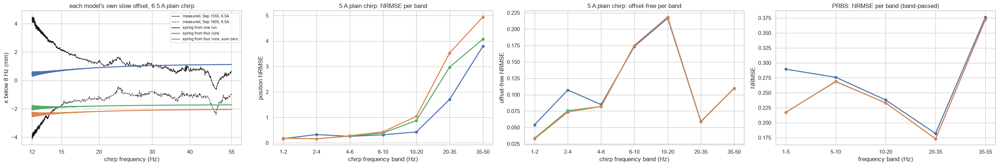

In [61]:
SUMZERO = np.column_stack([ONEHOT[:, r] - ONEHOT[:, -1] for r in range(len(FIT_RUNS_M) - 1)])   # F0_last = -(F0_1 + ... + F0_{R-1})


def fit_spring_sumzero(g):
    "As fit_spring_multi, with the per-run offset forces constrained to sum to zero."
    A = np.column_stack([x_m_ * i_m_, x_m_ ** 2 * i_m_, -1 / (g - x_m_) ** 3, 1 / (g + x_m_) ** 3, SUMZERO])
    sc = np.linalg.norm(A * w_m_[:, None], axis=0)
    lb = [-np.inf, -np.inf, 0, 0] + [-np.inf] * SUMZERO.shape[1]
    q = lsq_linear(A * w_m_[:, None] / sc, y_m_ * w_m_, bounds=(lb, np.inf)).x / sc
    return q, np.sqrt(np.sum(((A @ q - y_m_) * w_m_) ** 2) / np.sum(w_m_ ** 2))


scan_g0 = [(g, *fit_spring_sumzero(g)) for g in G_GRID[ok_gm]]
g_m0, q_m0, cost_m0 = min(scan_g0, key=lambda r: r[2])
p_M0 = np.r_[p_S[0], p_S[1], q_m0[:4]]
spring_M0 = lambda x, u, q, g=g_m0: q[2] / (g - x) ** 3 - q[3] / (g + x) ** 3 - (q[0] * x + q[1] * x ** 2) * u
F0_m0 = np.r_[q_m0[4:], -np.sum(q_m0[4:])]
k_m0 = 3 * (q_m0[2] + q_m0[3]) / g_m0 ** 4
print(f"effective gap g = {g_m0 * 1e3:.1f} mm; rms residual {cost_m0:.1f} N (without the condition {cost_multi:.1f} N)")
print(f"Gamma1 = {q_m0[0]:.4g}, Gamma2 = {q_m0[1]:.4g}, C_R = {q_m0[2]:.4g}, C_L = {q_m0[3]:.4g} (C_R/C_L = {q_m0[2] / q_m0[3]:.3f})")
print(f"stiffness at x = 0: {k_m0:.3g} N/m (resonance {np.sqrt(k_m0 / M) / (2 * np.pi):.2f} Hz); "
      f"Gamma(x)/Gamma at -15, +15 mm: " + ", ".join(f"{1 + (q_m0[0] * xx + q_m0[1] * xx ** 2) / p_S[0]:.3f}" for xx in (-15e-3, 15e-3)))
print(f"static force at x = 0 from the magnets: {(q_m0[2] - q_m0[3]) / g_m0 ** 3:+.1f} N (without the condition {(q_multi[2] - q_multi[3]) / g_multi ** 3:+.1f} N)")
print("F0 per run (N): " + ", ".join(f"{n} {f0:+.1f}" for n, f0 in zip(FIT_RUNS_M, F0_m0)))

SPRINGS["spring from four runs, sum zero"] = (spring_M0, p_M0, dict(color="C1"))   # one fixed colour per model

fig, ax = plt.subplots(1, 4, figsize=(28, 4.8))
sel_ = d_ref["f"] >= 12.0
for name in ("Sep 1555, 6.5A", "Sep 1605, 6.5A"):
    ax[0].plot(SEP[name]["f"][sel_], signal.sosfiltfilt(sos_slow, SEP[name]["x"])[sel_] * 1e3, color="k", lw=1,
               ls="-" if "1555" in name else "--", label=f"measured, {name}")
for name, (Fs_, p_, st) in SPRINGS.items():
    if name == "old spring":
        continue
    y_ = sim_free(Fs_, p_, d_ref)
    slow_ = signal.sosfiltfilt(sos_slow, np.nan_to_num(y_, nan=y_[BURN_IN]))
    ax[0].plot(d_ref["f"][sel_], slow_[sel_] * 1e3, lw=2, label=name, **st)
    y_5 = sim_free(Fs_, p_, d_5a)
    be = band_errors(y_5, d_5a, BANDS_SEP, use_5a & np.isfinite(y_5))
    bp = prbs_band_errors(sim_free(Fs_, p_, d_prbs), d_prbs)
    print(f"{name:32s} own slow position at 12, 20, 34.4, 47.7 Hz: "
          + ", ".join(f"{np.mean(slow_[np.abs(d_ref['f'] - f0) < 0.5]) * 1e3:+.2f}" for f0 in (12.0, 20.0, 34.4, 47.7)) + " mm")
    print(f"{'':32s} 5 A run NRMSE: " + ", ".join(f"{l} {v:.2f}" for l, v in zip(labels_s, be[:, 0]))
          + " | offset-free: " + ", ".join(f"{v:.3f}" for v in be[:, 1]))
    print(f"{'':32s} PRBS NRMSE: " + ", ".join(f"{l} {v:.2f}" for l, v in zip(labels_p, bp)))
    ax[1].plot(labels_s, be[:, 0], marker="o", ms=5, lw=2, label=name, **st)
    ax[2].plot(labels_s, be[:, 1], marker="o", ms=5, lw=2, label=name, **st)
    ax[3].plot(labels_p, bp, marker="o", ms=5, lw=2, label=name, **st)
ax[0].set(xscale="log", xlabel="chirp frequency (Hz)", ylabel="x below 8 Hz (mm)", title="each model's own slow offset, 6.5 A plain chirp")
ax[0].set_xticks([12, 15, 20, 30, 40, 55]); ax[0].get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax[1].set(title="5 A plain chirp: NRMSE per band", xlabel="chirp frequency band (Hz)", ylabel="position NRMSE")
ax[2].set(title="5 A plain chirp: offset-free per band", xlabel="chirp frequency band (Hz)", ylabel="offset-free NRMSE")
ax[3].set(title="PRBS: NRMSE per band (band-passed)", xlabel="frequency band (Hz)", ylabel="NRMSE")
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

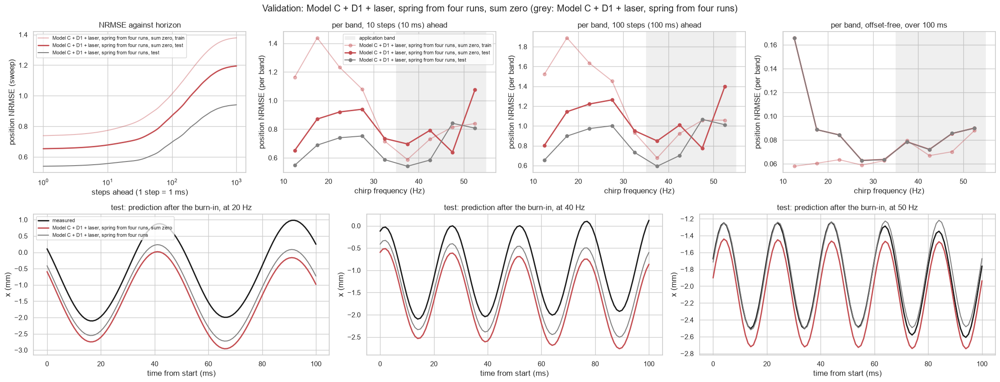

In [62]:
validate("Model C + D1 + laser, spring from four runs, sum zero", lambda d, s, H: predict_sensor(spring_M0, p_M0, tau_S, sens_S, d, s, H),
         ref="Model C + D1 + laser, spring from four runs")

**Findings (spring from four runs, sum zero).**

- **The condition does not remove the model's lean; it grows slightly** (−1.9 → −2.4 mm under a 6.5 A plain chirp). The stiffness (1.66·10⁴ N/m), the effective gap (39.5 mm) and the motor constant's fall-off (0.75 / 0.64 at ∓15 mm) barely change; the static magnet force goes from +28.5 to +33.5 N.
- **So the lean is not just a constant force to be moved around.** In free run the model's resting level also comes from how its nonlinear terms (the falling motor constant at large stroke, the unequal magnets) turn the large oscillation into a steady force; the fit's constants only partly control it.
- **The dynamics are the same for every version.** Offset-free, on the 5 A run and on PRBS, the errors are identical.
- **Decision: the final model is Model C + D1 + laser with the spring from four runs, sum zero.** Its resting level is a convention the data cannot pin down (the measured rest position itself moves by up to 2 mm between runs); for control it is a slow disturbance for the filter's offset states, not a property to model. The remaining lean (about −2 mm under large stroke) is a known limit.

## Side by side: the original model and the final model

**The original model:** Method C of the original notebook (`vca_greybox_fit.ipynb`, from the previous notebook): Model C fitted by equation error on the old loader's data (50 and 150 Hz notches, position shifted by `TAU` = 0.65 ms, 100 Hz 4th-order low-pass, the target readback as input), simulated with the setup's `rollout` (input held over each step).

**The final model:** Model C + D1 + laser with the spring from four runs (offset forces summing to zero): the sent current through the drive delay $\tau_d$, the laser's 34 Hz mode in the measurement, the spring and motor constant from the large-stroke runs; on the new loader's data.

**The original model's timing on the new data.** Its input, the target readback, is the sent current 1.16 ms late (section 1), and its position was shifted 0.65 ms earlier by `TAU`: between the sent current and the position it assumes about 1.81 ms. Wherever it runs on the new data, it gets that delay (`TAU_ORIG`), without a sensor model, so it is not handicapped by a timing it was not fitted for.

Two parts:
- **A. The original evaluation function**, each model on the data it was made for.
- **B. The same data and the same yardsticks for both:** the standard validation, the free-run validation, PRBS and the plain chirps.

### A. The original evaluation function

The original notebook's `evaluate`, copied unchanged (with `nrmse_curve`): for every 10th sample of the sweep, the model is started from the measured position and the differentiated velocity (no burn-in) and simulated 1000 steps; the position NRMSE against the horizon is normalised by the std of the position over the sweep; and one 1000-step prediction is shown from the middle of the sweep. It runs on the original model and the old loader's data (`DATA_ORIG`), exactly as in the original notebook.

For the final model, the same function with one change: the prediction comes from the model's prediction function, also started from the measured state without burn-in (`evaluate_predict`). A check confirms that it reproduces the original function's numbers for the original model. Then both side by side: the original on top, the final model below, each against its own measured data (notched and shifted for the original, cleaned for the final model).

train NRMSE at k = 1, 10, 100, 1000: 0.003, 0.206, 0.760, 0.710


test  NRMSE at k = 1, 10, 100, 1000: 0.003, 0.190, 0.616, 0.577


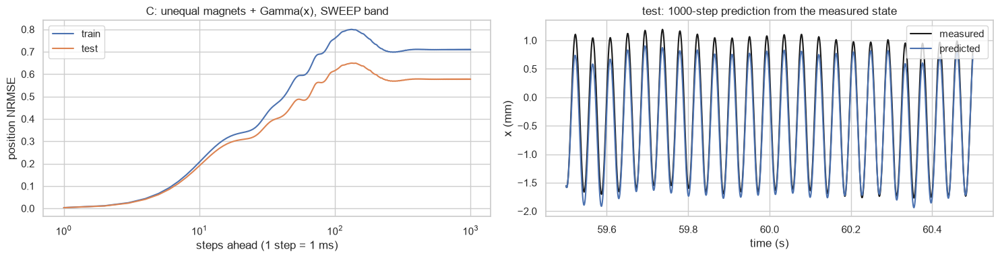

In [63]:
# ---- the original evaluation function, unchanged (vca_greybox_fit.ipynb), on the old loader's data ----
H_EVAL_ORIG = 1000
DATA_ORIG = {"chirpsched": {s: load(next(Path("data", s).glob("voice_coil_log_chirpsched_*.csv"))) for s in ("train", "test")}}


def nrmse_curve(Fs, p, d, band, H=H_EVAL_ORIG):
    "Position RMS error per horizon step, normalised by the std of x in the band."
    s = starts(d, band, H)
    e = rollout(Fs, p, d, s, H) - target(d, s, H)
    return np.sqrt(np.mean(e ** 2, axis=0)) / np.std(d["x"][band])


CURVES = []

def evaluate(name, Fs, p, exp, band, H=H_EVAL_ORIG):
    "Left: NRMSE against horizon, train and test. Right: one H-step prediction on test, started mid-band."
    fig, ax = plt.subplots(1, 2, figsize=(15, 4))
    k = np.arange(1, H + 1)
    for split, d in DATA[exp].items():
        e = nrmse_curve(Fs, p, d, d[band], H)[1:]
        CURVES.append(dict(method=name, split=split, exp=exp, band=band, k=k, nrmse=e))   # kept for the comparison cell
        sns.lineplot(x=k, y=e, ax=ax[0], label=split)
        print(f"{split:5s} NRMSE at k = 1, 10, 100, {H}: " + ", ".join(f"{e[j - 1]:.3f}" for j in (1, 10, 100, H)))
    ax[0].set(xscale="log", xlabel="steps ahead (1 step = 1 ms)", ylabel="position NRMSE", title=f"{name}, {band.upper()} band")
    d = DATA[exp]["test"]
    s0 = starts(d, d[band], H)
    s0 = s0[len(s0) // 2:][:1]                          # one start in the middle of the band
    t = d["t"][s0[0]:s0[0] + H + 1]
    sns.lineplot(x=t, y=target(d, s0, H)[0] * 1e3, ax=ax[1], label="measured", color="k")
    sns.lineplot(x=t, y=rollout(Fs, p, d, s0, H)[0] * 1e3, ax=ax[1], label="predicted")
    ax[1].set(xlabel="time (s)", ylabel="x (mm)", title=f"test: {H}-step prediction from the measured state")
    plt.tight_layout(); plt.show()


_DATA_NEW = DATA
DATA = DATA_ORIG                                        # the original function reads the global DATA
evaluate("C: unequal magnets + Gamma(x)", magnets, p_C_old, "chirpsched", "sweep", H=1000)
DATA = _DATA_NEW

original model (old data)  train NRMSE at k = 1, 10, 100, 1000: 0.003, 0.206, 0.760, 0.710
original model (old data)  test  NRMSE at k = 1, 10, 100, 1000: 0.003, 0.190, 0.616, 0.577


final model (new data)     train NRMSE at k = 1, 10, 100, 1000: 0.001, 0.086, 0.535, 1.375
final model (new data)     test  NRMSE at k = 1, 10, 100, 1000: 0.001, 0.088, 0.464, 1.191


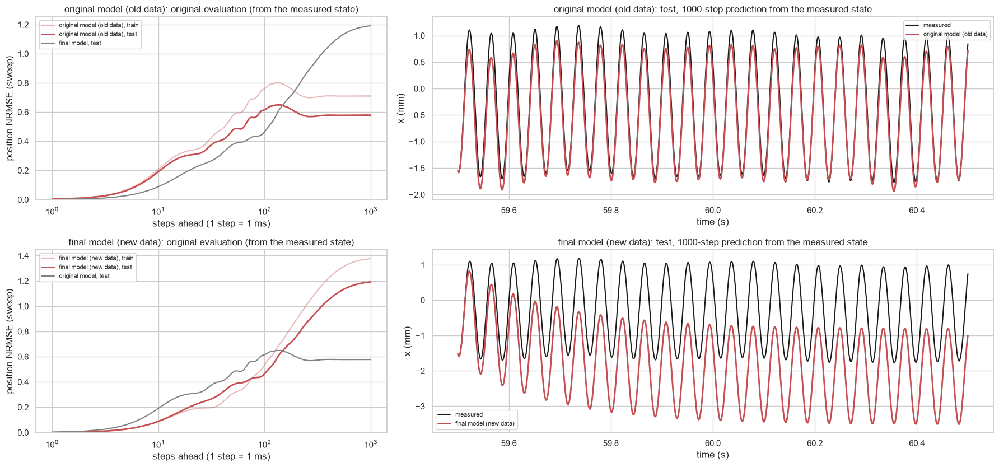

In [64]:
# ---- the same evaluation for any prediction function (the only change: predict instead of rollout) ----
def eval_curves(predict, runs, H=H_EVAL_ORIG):
    "As nrmse_curve, for train and test: NRMSE per horizon step 1..H over the sweep, from the measured state."
    out = {}
    for split, d in runs.items():
        s = starts(d, d["sweep"], H)
        e = predict(d, s, H) - target(d, s, H)
        out[split] = (np.sqrt(np.mean(e ** 2, axis=0)) / np.std(d["x"][d["sweep"]]))[1:]
    return out


TAU_ORIG = 1.16e-3 + TAU                                # s, the original model's timing on the new data (readback + position shift)
predict_orig_old = lambda d, s, H: rollout(magnets, p_C_old, d, s, H)                       # the original, on the old data
predict_final_m = lambda d, s, H: predict_sensor(spring_M0, p_M0, tau_S, sens_S, d, s, H, B=0)   # final model, from the measured state

curves_orig = eval_curves(predict_orig_old, DATA_ORIG["chirpsched"])
assert np.allclose(curves_orig["test"], CURVES[-1]["nrmse"]), "the copied evaluation must reproduce the original function"
curves_final = eval_curves(predict_final_m, DATA["chirpsched"])

fig, ax = plt.subplots(2, 2, figsize=(18, 8.5), gridspec_kw=dict(width_ratios=(1, 1.6)))
k = np.arange(1, H_EVAL_ORIG + 1)
for row, (lab, curves, runs, predict) in enumerate((("original model (old data)", curves_orig, DATA_ORIG["chirpsched"], predict_orig_old),
                                                     ("final model (new data)", curves_final, DATA["chirpsched"], predict_final_m))):
    for sp in ("train", "test"):
        ax[row, 0].plot(k, curves[sp], **STYLE[sp], label=f"{lab}, {sp}")
        print(f"{lab:26s} {sp:5s} NRMSE at k = 1, 10, 100, 1000: " + ", ".join(f"{curves[sp][j - 1]:.3f}" for j in (1, 10, 100, 1000)))
    other = curves_final if row == 0 else curves_orig
    ax[row, 0].plot(k, other["test"], **REF, label=("final" if row == 0 else "original") + " model, test")
    ax[row, 0].set(xscale="log", xlabel="steps ahead (1 step = 1 ms)", ylabel="position NRMSE (sweep)", ylim=(0, None),
                   title=f"{lab}: original evaluation (from the measured state)")
    ax[row, 0].legend(fontsize=8)
    d = runs["test"]
    s0 = starts(d, d["sweep"], H_EVAL_ORIG)
    s0 = s0[len(s0) // 2:][:1]                          # one start in the middle of the sweep, as the original
    t_ = d["t"][s0[0]:s0[0] + H_EVAL_ORIG + 1]
    ax[row, 1].plot(t_, target(d, s0, H_EVAL_ORIG)[0] * 1e3, color="k", lw=1.5, label="measured")
    ax[row, 1].plot(t_, predict(d, s0, H_EVAL_ORIG)[0] * 1e3, **STYLE["test"], label=lab)
    ax[row, 1].set(xlabel="time (s)", ylabel="x (mm)", title=f"{lab}: test, 1000-step prediction from the measured state")
    ax[row, 1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### B. The same data and the same yardsticks

Both models on the new data; the original with its native timing (`TAU_ORIG` = 1.81 ms, no sensor model). First the standard validation (burn-in, per band, offset-free), the final model against the original as reference; then the free-run validation (both regimes); then PRBS and the five plain chirps per band, in free run. A summary table closes the comparison.

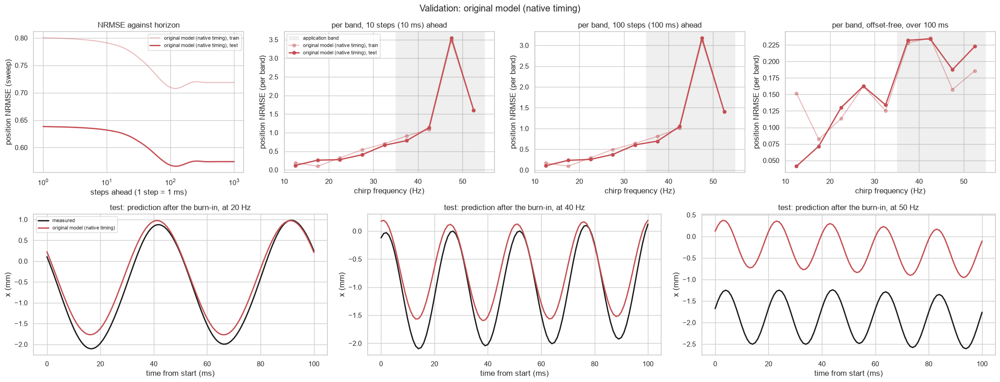

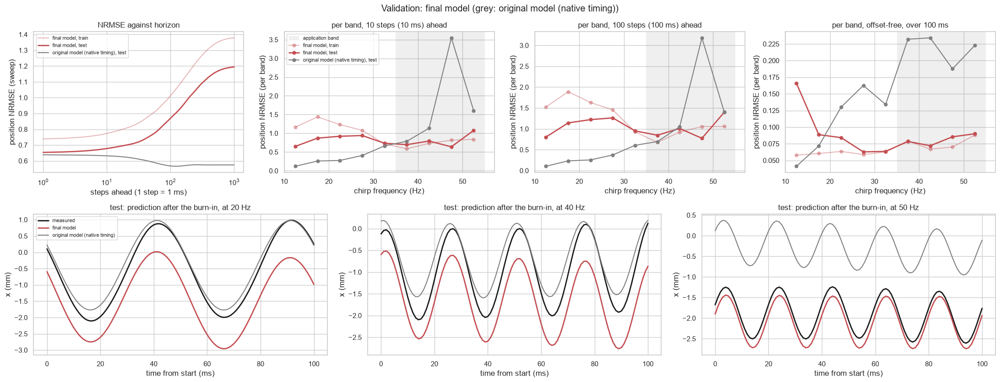

In [65]:
predict_orig_new = lambda d, s, H: rollout_v2(magnets, p_C_old, d, s, H, tau_d=TAU_ORIG)
predict_final = lambda d, s, H: predict_sensor(spring_M0, p_M0, tau_S, sens_S, d, s, H)
validate("original model (native timing)", predict_orig_new)
validate("final model", predict_final, ref="original model (native timing)")

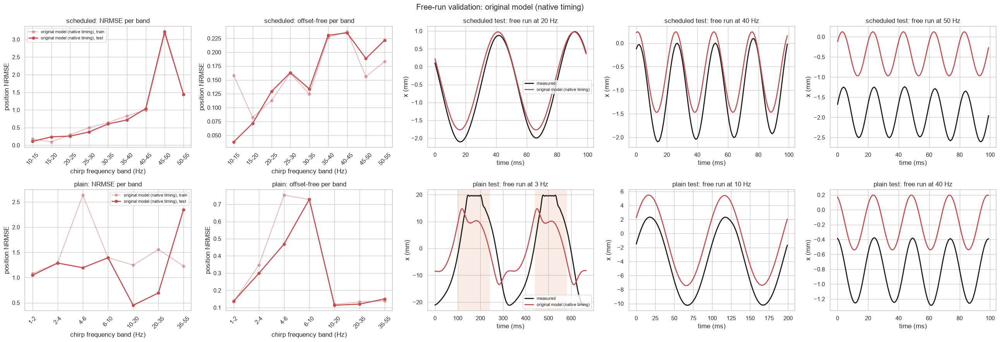

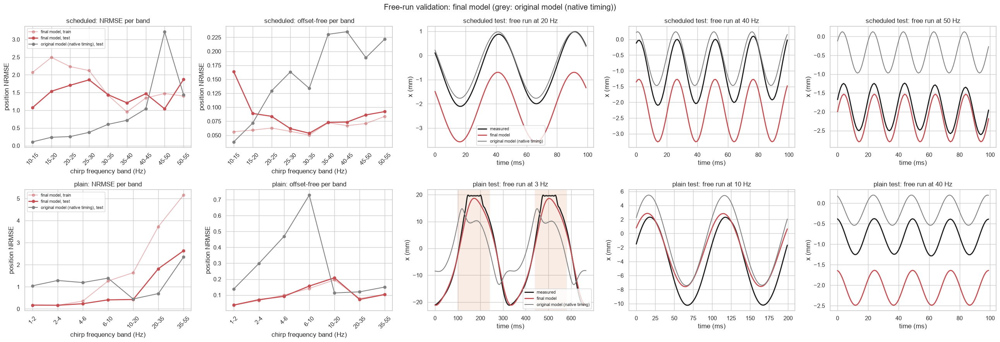

In [66]:
def sim_any(predict_full, d_):
    "Full-run free prediction from a prediction function (one start after the burn-in); NaN before."
    n_ = len(d_["t"]) - BURN_IN - 1
    return np.r_[np.full(BURN_IN, np.nan), predict_full(d_, np.array([BURN_IN]), n_)[0]]


y_orig_runs = {run: sim_any(predict_orig_new, e_["d"]) for run, e_ in ML.items()}
y_final_runs = {run: sim_any(predict_final, e_["d"]) for run, e_ in ML.items()}
validate_free("original model (native timing)", y_orig_runs)
validate_free("final model", y_final_runs, ref="original model (native timing)")

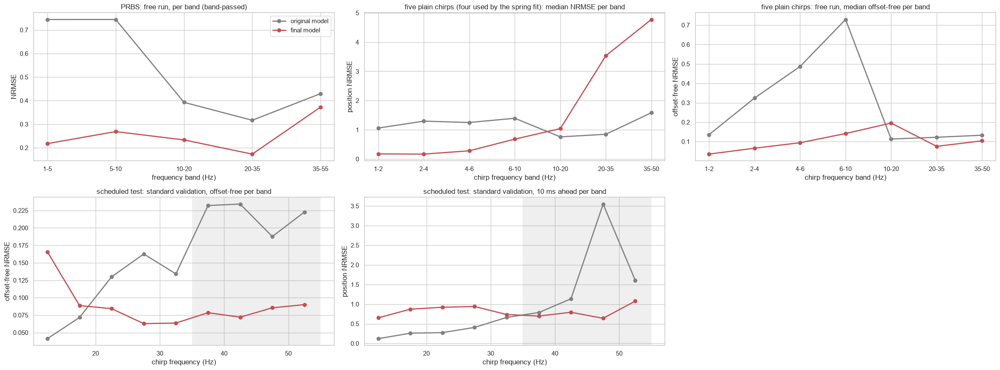

summary (original -> final):
  scheduled test, standard validation, offset-free, 35-55 Hz: 0.219 -> 0.082
  scheduled test, standard validation, 10 ms ahead, 35-55 Hz: 1.77 -> 0.80
  PRBS per band: 1-5 0.74 -> 0.22, 5-10 0.74 -> 0.27, 10-20 0.39 -> 0.23, 20-35 0.32 -> 0.17, 35-55 0.43 -> 0.37
  plain chirps (median of five), per band: 1-2 1.06 -> 0.17, 2-4 1.30 -> 0.17, 4-6 1.25 -> 0.28, 6-10 1.39 -> 0.68, 10-20 0.76 -> 1.04, 20-35 0.85 -> 3.53, 35-50 1.58 -> 4.78
  5 A plain chirp (not used by any fit), per band: 1-2 0.94 -> 0.19, 2-4 1.27 -> 0.15, 4-6 1.10 -> 0.28, 6-10 1.08 -> 0.43, 10-20 0.34 -> 1.04, 20-35 0.53 -> 3.53, 35-50 0.85 -> 4.94
  5 A plain chirp, offset-free: 1-2 0.098 -> 0.033, 2-4 0.256 -> 0.073, 4-6 0.349 -> 0.082, 6-10 0.570 -> 0.175, 10-20 0.107 -> 0.218, 20-35 0.096 -> 0.059, 35-50 0.126 -> 0.110
  plain chirps, offset-free: 1-2 0.136 -> 0.036, 2-4 0.324 -> 0.066, 4-6 0.487 -> 0.094, 6-10 0.729 -> 0.142, 10-20 0.113 -> 0.196, 20-35 0.122 -> 0.076, 35-50 0.133 -> 0

In [67]:
# PRBS and the five plain chirps, per band, in free run: both models
CMP = {"original model": (predict_orig_new, dict(color="0.5", marker="o")), "final model": (predict_final, dict(color="C3", marker="o"))}
plain_runs = {"Oct 0936, 6.5A (fit)": DATA["chirp"]["train"], "Oct 0942, 6.0A (fit)": DATA["chirp"]["test"],
              "Sep 1555, 6.5A (fit)": SEP["Sep 1555, 6.5A"], "Sep 1605, 6.5A (fit)": SEP["Sep 1605, 6.5A"], "Sep 1518, 5.0A": SEP["Sep 1518, 5.0A"]}
SUMMARY = {}
fig, ax = plt.subplots(2, 3, figsize=(24, 9))
for name, (pred, st) in CMP.items():
    bp = prbs_band_errors(sim_any(pred, d_prbs), d_prbs)
    SUMMARY[name, "PRBS"] = bp
    ax[0, 0].plot(labels_p, bp, lw=2, ms=6, label=name, **st)
    agg, agg_hp = [], []
    for run, d_ in plain_runs.items():
        y_ = sim_any(pred, d_)
        use_ = d_["valid"] & (d_["t"] >= 1.0) & d_["sweep"] & np.isfinite(y_)
        be = band_errors(y_, d_, BANDS_SEP, use_)
        agg.append(be[:, 0]); agg_hp.append(be[:, 1])
    SUMMARY[name, "5A"] = (agg[-1], agg_hp[-1])          # the one plain chirp the final spring was not fitted on
    agg, agg_hp = np.median(agg, axis=0), np.median(agg_hp, axis=0)
    SUMMARY[name, "plain"] = agg
    SUMMARY[name, "plain hp"] = agg_hp
    ax[0, 1].plot(labels_s, agg, lw=2, ms=6, label=name, **st)
    ax[0, 2].plot(labels_s, agg_hp, lw=2, ms=6, label=name, **st)
    SUMMARY[name, "sched hp"] = RESULTS["original model (native timing)" if name == "original model" else "final model"]["bands_hp"]["test"]
    SUMMARY[name, "sched 10ms"] = RESULTS["original model (native timing)" if name == "original model" else "final model"]["bands"]["test"][:, 0]
    ax[1, 0].plot(VAL_EDGES[:-1] + 2.5, SUMMARY[name, "sched hp"], lw=2, ms=6, label=name, **st)
    ax[1, 1].plot(VAL_EDGES[:-1] + 2.5, SUMMARY[name, "sched 10ms"], lw=2, ms=6, label=name, **st)
ax[0, 0].set(title="PRBS: free run, per band (band-passed)", xlabel="frequency band (Hz)", ylabel="NRMSE")
ax[0, 1].set(title="five plain chirps (four used by the spring fit): median NRMSE per band", xlabel="chirp frequency band (Hz)", ylabel="position NRMSE")
ax[0, 2].set(title="five plain chirps: free run, median offset-free per band", xlabel="chirp frequency band (Hz)", ylabel="offset-free NRMSE")
ax[1, 0].set(title="scheduled test: standard validation, offset-free per band", xlabel="chirp frequency (Hz)", ylabel="offset-free NRMSE")
ax[1, 1].set(title="scheduled test: standard validation, 10 ms ahead per band", xlabel="chirp frequency (Hz)", ylabel="position NRMSE")
for a_ in (ax[1, 0], ax[1, 1]):
    a_.axvspan(*APP_BAND, color="0.5", alpha=0.12, lw=0)
ax[1, 2].axis("off")
ax[0, 0].legend()
plt.tight_layout(); plt.show()

app = (VAL_EDGES[:-1] >= 35)
print("summary (original -> final):")
print(f"  scheduled test, standard validation, offset-free, 35-55 Hz: "
      f"{SUMMARY['original model', 'sched hp'][app].mean():.3f} -> {SUMMARY['final model', 'sched hp'][app].mean():.3f}")
print(f"  scheduled test, standard validation, 10 ms ahead, 35-55 Hz: "
      f"{SUMMARY['original model', 'sched 10ms'][app].mean():.2f} -> {SUMMARY['final model', 'sched 10ms'][app].mean():.2f}")
print("  PRBS per band: " + ", ".join(f"{l} {a:.2f} -> {b:.2f}" for l, a, b in zip(labels_p, SUMMARY['original model', 'PRBS'], SUMMARY['final model', 'PRBS'])))
print("  plain chirps (median of five), per band: " + ", ".join(f"{l} {a:.2f} -> {b:.2f}" for l, a, b in zip(labels_s, SUMMARY['original model', 'plain'], SUMMARY['final model', 'plain'])))
print("  5 A plain chirp (not used by any fit), per band: " + ", ".join(f"{l} {a:.2f} -> {b:.2f}" for l, a, b in zip(labels_s, SUMMARY['original model', '5A'][0], SUMMARY['final model', '5A'][0])))
print("  5 A plain chirp, offset-free: " + ", ".join(f"{l} {a:.3f} -> {b:.3f}" for l, a, b in zip(labels_s, SUMMARY['original model', '5A'][1], SUMMARY['final model', '5A'][1])))
print("  plain chirps, offset-free: " + ", ".join(f"{l} {a:.3f} -> {b:.3f}" for l, a, b in zip(labels_s, SUMMARY['original model', 'plain hp'], SUMMARY['final model', 'plain hp'])))

**Findings (side by side).**

- **With the original evaluation, the final model is better up to about 150 ms ahead and worse beyond.** Test NRMSE at 10 / 100 / 1000 steps: original 0.19 / 0.62 / 0.58, final 0.09 / 0.46 / 1.19. In the 1000-step prediction the final model's oscillation matches, but its level drifts about 2 mm below the measurement: the final model's own lean (its resting level, which the data do not pin down). The original model, with its stiff spring fitted on that same run, stays near the measured level.
- **On the same data, the oscillation in the application band is about 2.7 times better**, not 6 times: offset-free at 35–55 Hz 0.22 → 0.08 (scheduled test, standard validation). Earlier in this notebook the original model was validated on the new data without a drive delay, which handicapped it; with its native timing (1.81 ms) it is considerably better.
- **On PRBS, an excitation no fit used, every band improves:** 1–10 Hz 0.74 → 0.22–0.27, 10–35 Hz 0.32–0.39 → 0.17–0.23, 35–55 Hz 0.43 → 0.37.
- **At large stroke the dynamics improve four to seven times** (plain chirps, 1–10 Hz, offset-free median 0.14–0.73 → 0.04–0.14; the unseen 5 A run 0.10–0.57 → 0.03–0.18).
- **Where the final model is worse, it is the slow level, not the dynamics.** Including the offset it is worse at 10–30 Hz on the scheduled runs (10 ms ahead: 0.13–0.41 → 0.65–0.95) and at 10–50 Hz on the plain chirps; offset-free it is worse only at 10–20 Hz (small current on the scheduled runs, 0.04–0.07 → 0.09–0.17; plain chirps 0.11 → 0.20).
- **Verdict:** the final model's dynamics are clearly better everywhere except the small-current band (10–20 Hz), and they carry over to unseen excitation. Its slow level is worse than the original's: the lean of about −2 mm is now its largest weakness, and it dominates long free-run predictions.

## A symmetric spring

The final model's weakness is its rest position. In a 1000-step prediction from the measured state its oscillation stays right, but its level slides from the measured −0.3 mm to about −2.2 mm with the time constant of its own spring and damper ($c/k \approx$ 0.17 s): the model relaxes to its own rest position, which the asymmetry of its spring (unequal magnets, $\Gamma_1$) puts about 2 mm off. That asymmetry was fitted at large stroke, where the run-to-run offset bends it; it is not trustworthy.

Here the spring is symmetric by construction, fitted on the same four plain runs, with an offset force per run:

$$m\ddot{x} = (\Gamma + \Gamma_2 x^2)\, i_\text{sent}(t - \tau_d) - c\,\dot{x} - C\left(\frac{1}{(g - x)^3} - \frac{1}{(g + x)^3}\right) + F_{0,r}$$

- one magnet strength $C$ for both sides ($C_R = C_L$), and no $\Gamma_1$: the spring force is odd in $x$, so it has no constant part, and $x^2 i$ has no constant part for a symmetric oscillation. The model's rest position is the centre.
- the motor constant's fall-off $\Gamma_2 x^2$ stays (symmetric).
- with no constant part in the spring, the offset forces $F_{0,r}$ are no longer ambiguous: no sum-zero condition is needed.
- $\Gamma$, $c$, $\tau_d$ and the sensor pair as before; $g$ on the grid `G_GRID`.

If the dynamics stay as good, the symmetric model wins: simpler, and neutral in level. If they get worse, the asymmetry is real, and the lean is its price.

In [68]:
def fit_spring_sym(g):
    "Least squares for [Gamma2, C, F0_1..F0_R] at effective gap g, symmetric spring (C >= 0); returns the parameters and the weighted rms residual."
    A = np.column_stack([x_m_ ** 2 * i_m_, -(1 / (g - x_m_) ** 3 - 1 / (g + x_m_) ** 3), ONEHOT])
    sc = np.linalg.norm(A * w_m_[:, None], axis=0)
    lb = [-np.inf, 0] + [-np.inf] * ONEHOT.shape[1]
    q = lsq_linear(A * w_m_[:, None] / sc, y_m_ * w_m_, bounds=(lb, np.inf)).x / sc
    return q, np.sqrt(np.sum(((A @ q - y_m_) * w_m_) ** 2) / np.sum(w_m_ ** 2))


scan_gs = [(g, *fit_spring_sym(g)) for g in G_GRID[ok_gm]]
g_sym, q_sym, cost_sym = min(scan_gs, key=lambda r: r[2])
p_SYM = np.r_[p_S[0], p_S[1], q_sym[:2]]                # [Gamma, c, Gamma2, C]
spring_SYM = lambda x, u, q, g=g_sym: q[1] * (1 / (g - x) ** 3 - 1 / (g + x) ** 3) - q[0] * x ** 2 * u
k_sym = 6 * q_sym[1] / g_sym ** 4
print(f"effective gap g = {g_sym * 1e3:.1f} mm; rms residual {cost_sym:.1f} N (asymmetric, sum zero: {cost_m0:.1f} N)")
print(f"Gamma2 = {q_sym[0]:.4g} N/(A m^2), C = {q_sym[1]:.4g} N m^3; stiffness at x = 0: {k_sym:.3g} N/m "
      f"(resonance {np.sqrt(k_sym / M) / (2 * np.pi):.2f} Hz); Gamma(x)/Gamma at +-15 mm: {1 + q_sym[0] * 15e-3 ** 2 / p_S[0]:.3f}")
print("F0 per run (N): " + ", ".join(f"{n} {f0:+.1f}" for n, f0 in zip(FIT_RUNS_M, q_sym[2:])))
print(f"slow time constant c / k: symmetric {p_S[1] / k_sym:.3f} s, asymmetric {p_S[1] / k_m0:.3f} s")

effective gap g = 40.0 mm; rms residual 400.1 N (asymmetric, sum zero: 399.8 N)
Gamma2 = -2.644e+05 N/(A m^2), C = 0.00645 N m^3; stiffness at x = 0: 1.51e+04 N/m (resonance 2.73 Hz); Gamma(x)/Gamma at +-15 mm: 0.741
F0 per run (N): Oct 0936, 6.5A -11.5, Oct 0942, 6.0A -37.2, Sep 1555, 6.5A -15.6, Sep 1605, 6.5A -62.3
slow time constant c / k: symmetric 0.188 s, asymmetric 0.171 s


### The symmetric model against the final and the original model

1. **Lean:** each model's own slow position under a 6.5 A plain chirp (free run on the 23 September 15:55 run).
2. **The original evaluation** (from the measured state, no burn-in, NRMSE over the sweep against the horizon, a 1000-step prediction mid-sweep), three rows: the original model on the old data, the asymmetric final model and the symmetric model on the new data.

final model (asymmetric)   own slow position at 12, 20, 34.4, 47.7 Hz: -2.41, -2.19, -2.08, -2.06 mm


symmetric model            own slow position at 12, 20, 34.4, 47.7 Hz: +0.00, -0.00, +0.00, +0.00 mm


original model (old data)            train NRMSE at k = 1, 10, 100, 1000: 0.003, 0.206, 0.760, 0.710
original model (old data)            test  NRMSE at k = 1, 10, 100, 1000: 0.003, 0.190, 0.616, 0.577


final model, asymmetric (new data)   train NRMSE at k = 1, 10, 100, 1000: 0.001, 0.086, 0.535, 1.375
final model, asymmetric (new data)   test  NRMSE at k = 1, 10, 100, 1000: 0.001, 0.088, 0.464, 1.191


symmetric model (new data)           train NRMSE at k = 1, 10, 100, 1000: 0.001, 0.086, 0.345, 0.917
symmetric model (new data)           test  NRMSE at k = 1, 10, 100, 1000: 0.001, 0.088, 0.331, 0.814


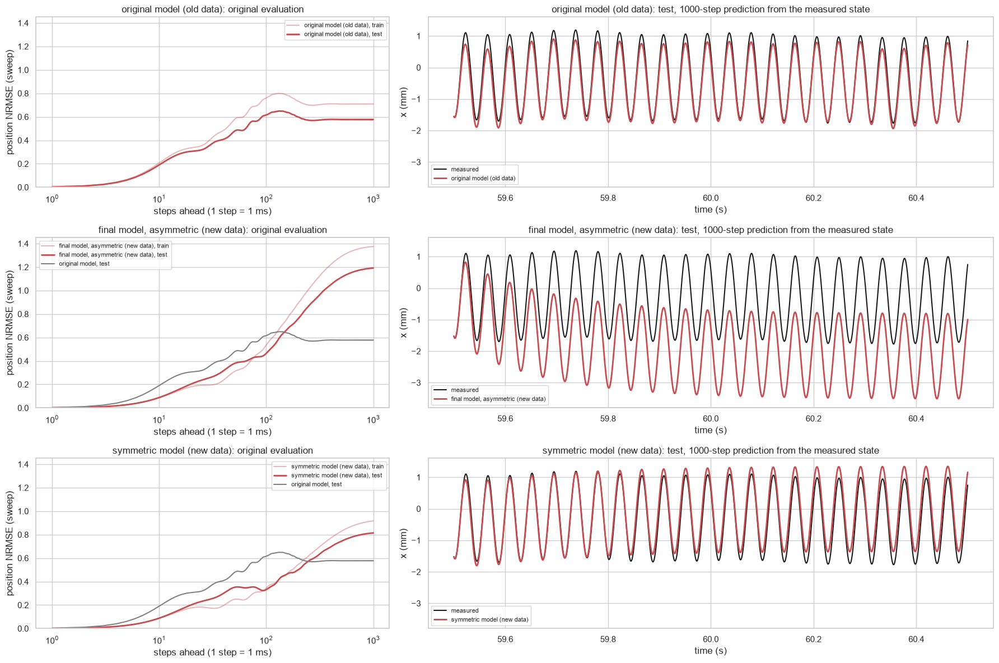

In [69]:
predict_sym = lambda d, s, H: predict_sensor(spring_SYM, p_SYM, tau_S, sens_S, d, s, H)
predict_sym_m = lambda d, s, H: predict_sensor(spring_SYM, p_SYM, tau_S, sens_S, d, s, H, B=0)
for name, pred in (("final model (asymmetric)", predict_final), ("symmetric model", predict_sym)):
    y_ = sim_any(pred, d_ref)
    slow_ = signal.sosfiltfilt(sos_slow, np.nan_to_num(y_, nan=y_[BURN_IN]))
    print(f"{name:26s} own slow position at 12, 20, 34.4, 47.7 Hz: "
          + ", ".join(f"{np.mean(slow_[np.abs(d_ref['f'] - f0) < 0.5]) * 1e3:+.2f}" for f0 in (12.0, 20.0, 34.4, 47.7)) + " mm")

curves_sym = eval_curves(predict_sym_m, DATA["chirpsched"])
ROWS3 = (("original model (old data)", curves_orig, DATA_ORIG["chirpsched"], predict_orig_old),
         ("final model, asymmetric (new data)", curves_final, DATA["chirpsched"], predict_final_m),
         ("symmetric model (new data)", curves_sym, DATA["chirpsched"], predict_sym_m))
fig, ax = plt.subplots(3, 2, figsize=(18, 12), gridspec_kw=dict(width_ratios=(1, 1.6)))
k = np.arange(1, H_EVAL_ORIG + 1)
for row, (lab, curves, runs, predict) in enumerate(ROWS3):
    for sp in ("train", "test"):
        ax[row, 0].plot(k, curves[sp], **STYLE[sp], label=f"{lab}, {sp}")
        print(f"{lab:36s} {sp:5s} NRMSE at k = 1, 10, 100, 1000: " + ", ".join(f"{curves[sp][j - 1]:.3f}" for j in (1, 10, 100, 1000)))
    if row > 0:
        ax[row, 0].plot(k, curves_orig["test"], **REF, label="original model, test")
    ax[row, 0].set(xscale="log", xlabel="steps ahead (1 step = 1 ms)", ylabel="position NRMSE (sweep)", ylim=(0, 1.45),
                   title=f"{lab}: original evaluation")
    ax[row, 0].legend(fontsize=8)
    d = runs["test"]
    s0 = starts(d, d["sweep"], H_EVAL_ORIG)
    s0 = s0[len(s0) // 2:][:1]
    t_ = d["t"][s0[0]:s0[0] + H_EVAL_ORIG + 1]
    ax[row, 1].plot(t_, target(d, s0, H_EVAL_ORIG)[0] * 1e3, color="k", lw=1.5, label="measured")
    ax[row, 1].plot(t_, predict(d, s0, H_EVAL_ORIG)[0] * 1e3, **STYLE["test"], label=lab)
    ax[row, 1].set(xlabel="time (s)", ylabel="x (mm)", ylim=(-3.8, 1.6), title=f"{lab}: test, 1000-step prediction from the measured state")
    ax[row, 1].legend(fontsize=8)
plt.tight_layout(); plt.show()

3. **The standard validation** of the symmetric model, against the asymmetric final model.
4. **The same data and yardsticks for all three** (the original with its native timing): the scheduled test run (standard validation, offset-free and 10 ms ahead, application band), PRBS per band, the 5 A plain chirp (not used by any fit) per band, as it is and offset-free.

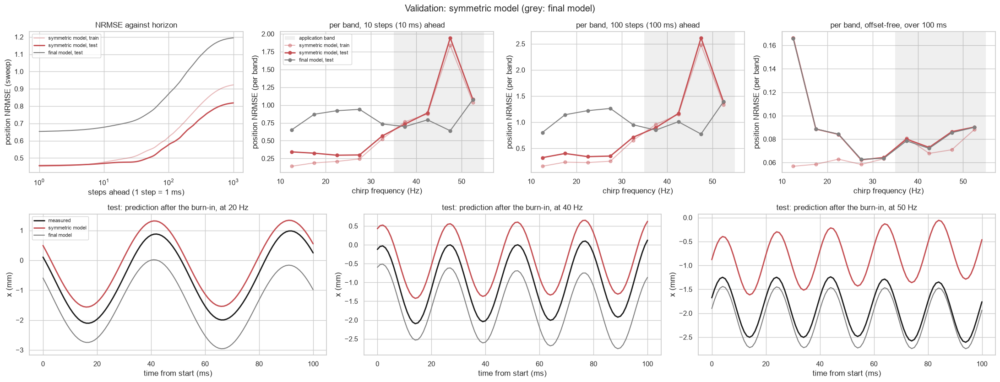

In [70]:
validate("symmetric model", predict_sym, ref="final model")

                            sched hp 35-55  sched 10ms 35-55   PRBS 1-5 .. 35-55            5 A run, as it is (1-2 .. 35-50)                        5 A run, offset-free


original model                       0.219              1.77   0.74 0.74 0.39 0.32 0.43    0.94 1.27 1.10 1.08 0.34 0.53 0.85    0.098 0.256 0.349 0.570 0.107 0.096 0.126


final model (asymmetric)             0.082              0.80   0.22 0.27 0.23 0.17 0.37    0.19 0.15 0.28 0.43 1.04 3.53 4.94    0.033 0.073 0.082 0.175 0.218 0.059 0.110


symmetric model                      0.082              1.16   0.24 0.27 0.23 0.18 0.37    0.15 0.23 0.24 0.30 0.25 0.22 1.02    0.043 0.092 0.083 0.175 0.219 0.059 0.110


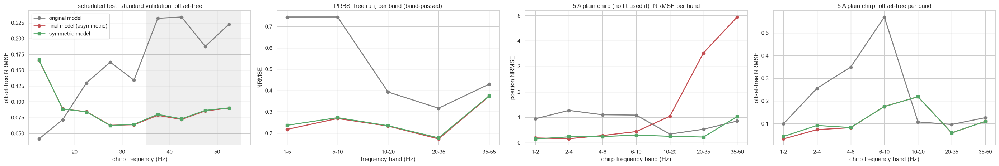

In [71]:
CMP3 = {"original model": (predict_orig_new, dict(color="0.5", marker="o"), "original model (native timing)"),
        "final model (asymmetric)": (predict_final, dict(color="C3", marker="o"), "final model"),
        "symmetric model": (predict_sym, dict(color="C2", marker="s"), "symmetric model")}   # one fixed colour per model
fig, ax = plt.subplots(1, 4, figsize=(28, 4.8))
app = VAL_EDGES[:-1] >= 35
print(f"{'':26s} {'sched hp 35-55':>15s} {'sched 10ms 35-55':>17s}   PRBS 1-5 .. 35-55            5 A run, as it is (1-2 .. 35-50)                        5 A run, offset-free")
for name, (pred, st, key) in CMP3.items():
    hp = RESULTS[key]["bands_hp"]["test"]
    b10 = RESULTS[key]["bands"]["test"][:, 0]
    bp = prbs_band_errors(sim_any(pred, d_prbs), d_prbs)
    y5 = sim_any(pred, d_5a)
    be5 = band_errors(y5, d_5a, BANDS_SEP, use_5a & np.isfinite(y5))
    print(f"{name:26s} {hp[app].mean():15.3f} {b10[app].mean():17.2f}   " + " ".join(f"{v:.2f}" for v in bp)
          + "    " + " ".join(f"{v:.2f}" for v in be5[:, 0]) + "    " + " ".join(f"{v:.3f}" for v in be5[:, 1]))
    ax[0].plot(VAL_EDGES[:-1] + 2.5, hp, lw=2, ms=6, label=name, **st)
    ax[1].plot(labels_p, bp, lw=2, ms=6, label=name, **st)
    ax[2].plot(labels_s, be5[:, 0], lw=2, ms=6, label=name, **st)
    ax[3].plot(labels_s, be5[:, 1], lw=2, ms=6, label=name, **st)
ax[0].axvspan(*APP_BAND, color="0.5", alpha=0.12, lw=0)
ax[0].set(title="scheduled test: standard validation, offset-free", xlabel="chirp frequency (Hz)", ylabel="offset-free NRMSE")
ax[1].set(title="PRBS: free run, per band (band-passed)", xlabel="frequency band (Hz)", ylabel="NRMSE")
ax[2].set(title="5 A plain chirp (no fit used it): NRMSE per band", xlabel="chirp frequency band (Hz)", ylabel="position NRMSE")
ax[3].set(title="5 A plain chirp: offset-free per band", xlabel="chirp frequency band (Hz)", ylabel="offset-free NRMSE")
ax[0].legend()
plt.tight_layout(); plt.show()

**Findings (symmetric spring).**

- **The asymmetry buys nothing in the fit.** The force-equation residual is the same (400.1 against 399.8 N for the asymmetric spring, sum zero): the unequal magnets and $\Gamma_1$ were not needed to describe the force.
- **The large-stroke physics hardly change.** Stiffness at the centre 1.51·10⁴ N/m (resonance 2.7 Hz) against 1.66·10⁴, the same effective gap (40 mm), and a motor constant at ±15 mm of 0.74 of its centre value, between the asymmetric spring's 0.75 and 0.64.
- **The common constant force has moved into the per-run offset forces.** All four now come out negative (−12, −37, −16 and −62 N; mean about −32 N), where before they carried the signs of the runs' offsets. The asymmetric spring had built this force into its static magnet force (+33.5 N), which caused its −2 mm lean.
- **That steady force appears only at large stroke.** The measured rest positions at 0 A (+1.3, −0.5, +1.5, +0.2 mm) show no matching negative level. So it is not a property of the spring at rest: either the laser or its mount settles lower during large strokes, or a nonlinearity not in the model acts there. Cause open; for control it is part of the slow disturbance.
- **The model has no lean:** its own slow position under a 6.5 A plain chirp is 0 mm, against about −2.1 to −2.4 mm for the asymmetric model.
- **The dynamics are the same.** Offset-free on the scheduled test run identical in every band; on PRBS within 0.01 in every band.
- **The level is far better almost everywhere.** In the original evaluation the test error at 1000 steps drops from 1.19 to 0.81, and the 1000-step prediction stays at the measured level (about 0.35 mm above it, instead of about 1.8 mm below). In the standard validation at 10 ms ahead, 10–30 Hz drops from about 0.9 to 0.3; on the unseen 5 A plain run, 10–50 Hz drops from 1.0 / 3.5 / 4.9 to 0.25 / 0.22 / 1.0.
- **Except at 45–50 Hz, the second slow dip.** There the measured level falls to about −1.9 mm, where the asymmetric model's lean happened to sit (10 ms ahead: 0.64 against 1.95). That one band makes the application-band mean look worse (1.16 against 0.80). It is the laser's frequency-locked dip, not the dynamics: a task for an offset estimate, not for the spring.
- **A small cost at large stroke:** on the 5 A run the offset-free error at 1–4 Hz is slightly higher (0.043 / 0.092 against 0.033 / 0.073). The asymmetric terms may carry a little real large-stroke shape, too little to justify the lean.
- **The original model keeps the lowest error at 1000 steps** (0.58): its stiff spring was fitted on that same run, so it stays near that run's level.
- **Decision: the final model is Model C + D1 + laser with the symmetric spring** (`predict_sym`): simpler, neutral in level, with the same dynamics. It is the reference for every later step.

## Is the laser's over-read absorbed into the motor constant?

Above its 34 Hz mode the laser reads 7–13 % more motion than the accelerometer suggests (section 4), and the sensor model's 34 Hz pair explains only 0.8 % of that step. The rest is "absorbed elsewhere". The most likely place is the motor constant $\Gamma$: above the spring resonance the motion is about $\Gamma I / (m\omega^2)$, so a laser that over-reads by 10 % above 35 Hz pulls a fit over the whole band towards a larger $\Gamma$. Then the plant would carry part of a sensor error, and the force per ampere would be too high everywhere.

Two checks, on the final model (Model C + D1 + laser, symmetric spring):

- **A. $\Gamma$ from below and from above the mode.** The offset-free output-error fit of $\Gamma$, $c$ and $\tau_d$ (as in the laser's sensor model), with the spring and the sensor pair fixed, repeated on three sets of predictions of the scheduled chirp (train): the whole band, only 20–31 Hz (below the mode, where the laser is flat against the accelerometer), and only 36–55 Hz (above it). A $\Gamma$ above the mode that is larger by about the over-read means the laser's step lands in $\Gamma$.
- **B. Measured against model, per frequency, for both sensors.** The final model in free run over each scheduled chirp; per frequency the ratio of the measured to the predicted response to the sent current ($H_1$ from the same exact input, as in section 4), for the laser ($x$ against the model's laser reading $S\,x_\text{model}$) and for the accelerometer ($a_\text{meas}$ against the model's acceleration, $-\omega^2 H_{i \to x_\text{model}}$). The accelerometer rolls off on its own (about 24 % over 20–55 Hz), so each ratio is shown relative to its mean over 20–31 Hz: what matters is a change across 35 Hz in one sensor and not in the other.

In [72]:
G_RANGES = {"10-55 Hz (all)": (10.0, 55.0), "20-31 Hz (below the mode)": (20.0, 31.0), "36-55 Hz (above the mode)": (36.0, 55.0)}
f_oe_start, f_oe_end = d_oe["f"][s_oe], d_oe["f"][s_oe + H_OE]   # chirp frequency at the start and end of each prediction


def res_gamma(q, m):
    "Offset-free output-error residuals of the final model on the predictions m; q = [Gamma, c, tau_d], spring and sensor pair fixed."
    p_ = np.r_[q[0], q[1], p_SYM[2:]]
    y_hat = predict_sensor(spring_SYM, p_, q[2], sens_S, d_oe, s_oe[m], H_OE)[:, 1:]
    e = np.nan_to_num(y_hat - X_oe[m], nan=1.0, posinf=1.0, neginf=-1.0)
    return ((e @ P_oe.T) / sig_oe[m, None]).ravel()


qg0 = np.r_[p_SYM[0], p_SYM[1], tau_S]
lb_g, ub_g = [0.0, 0.0, 0.0], [np.inf, np.inf, 5e-3]
FIT_G = {}
for lab, (lo, hi) in G_RANGES.items():
    m_ = (f_oe_start >= lo) & (f_oe_end < hi)          # predictions that stay inside the range
    fit_ = cached(f"fit_gamma {lab}", (qg0, lb_g, ub_g, lo, hi, p_SYM, g_sym, sens_S, s_oe, H_OE, BURN_IN),
                  lambda: least_squares(res_gamma, qg0, bounds=(lb_g, ub_g), x_scale=np.abs(qg0), args=(m_,)))
    FIT_G[lab] = dict(x=fit_.x, n=int(m_.sum()), cost=np.sqrt(np.mean(fit_.fun ** 2)),
                      cost0=np.sqrt(np.mean(res_gamma(qg0, m_) ** 2)))
G_all = FIT_G["10-55 Hz (all)"]["x"][0]
print(f"final model: Gamma = {qg0[0]:.1f} N/A, c = {qg0[1]:.0f} N s/m, tau_d = {qg0[2] * 1e3:.2f} ms")
for lab, r_ in FIT_G.items():
    G_, c_, tau_ = r_["x"]
    print(f"{lab:27s} ({r_['n']:4d} predictions): Gamma = {G_:6.1f} N/A ({G_ / G_all:.3f} of the whole band), "
          f"c = {c_:5.0f} N s/m, tau_d = {tau_ * 1e3:.2f} ms; offset-free error {r_['cost0']:.4f} -> {r_['cost']:.4f}")

[cache] fit_gamma 10-55 Hz (all): loaded


[cache] fit_gamma 20-31 Hz (below the mode): loaded


[cache] fit_gamma 36-55 Hz (above the mode): loaded


final model: Gamma = 229.3 N/A, c = 2836 N s/m, tau_d = 3.08 ms
10-55 Hz (all)              (2395 predictions): Gamma =  230.0 N/A (1.000 of the whole band), c =  2841 N s/m, tau_d = 3.08 ms; offset-free error 0.0817 -> 0.0817
20-31 Hz (below the mode)   ( 615 predictions): Gamma =  226.2 N/A (0.984 of the whole band), c =  2175 N s/m, tau_d = 2.92 ms; offset-free error 0.0620 -> 0.0321
36-55 Hz (above the mode)   ( 594 predictions): Gamma =  230.8 N/A (1.004 of the whole band), c =  2097 N s/m, tau_d = 2.80 ms; offset-free error 0.1104 -> 0.1041


**Check B: measured against model, per frequency.** $H_1$ estimates at 1 kHz (Welch, 2048 samples: 2.05 s, 0.49 Hz resolution) from the sent current, over the sweep after the burn-in, for the measured laser position, the measured acceleration, the model's laser reading and the model's position (without $S$). Shown, per scheduled run: the magnitude of the two ratios, each divided by its mean over 20–31 Hz; and the phase of the laser ratio.

train laser         measured / model, relative to 20-31 Hz, mean over 10-20, 36-45, 45-55 Hz: 0.974, 1.028, 0.981
train accelerometer measured / model, relative to 20-31 Hz, mean over 10-20, 36-45, 45-55 Hz: 1.044, 0.857, 0.775


test  laser         measured / model, relative to 20-31 Hz, mean over 10-20, 36-45, 45-55 Hz: 1.055, 1.027, 0.990
test  accelerometer measured / model, relative to 20-31 Hz, mean over 10-20, 36-45, 45-55 Hz: 1.129, 0.856, 0.777


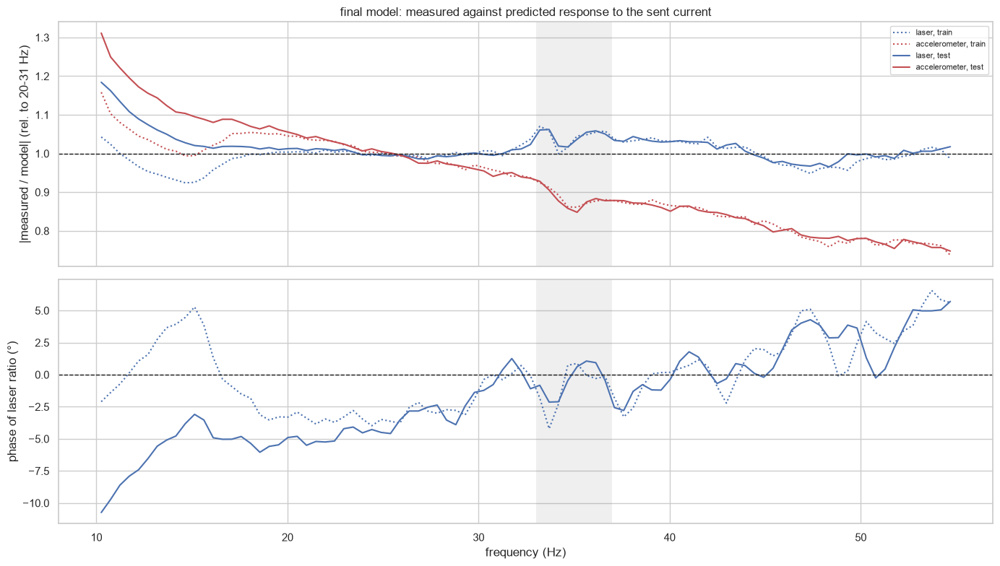

In [73]:
NPERSEG_B = 2048                                        # samples per Welch segment at 1 kHz: 2.05 s, 0.49 Hz resolution


def h1_1k(u, y):
    "H1 estimate of y / u at 1 kHz."
    f, Puu = signal.welch(u, fs=1000.0, nperseg=NPERSEG_B)
    _, Puy = signal.csd(u, y, fs=1000.0, nperseg=NPERSEG_B)
    return f, Puy / Puu


fig, ax = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for sp, ls in (("train", ":"), ("test", "-")):
    d_ = DATA["chirpsched"][sp]
    n_ = len(d_["t"]) - BURN_IN - 1
    s0_ = np.array([BURN_IN])
    x_mod = rollout_v2(spring_SYM, p_SYM, d_, s0_, n_, tau_d=tau_S)[0]   # the model's position, without the sensor model
    y_mod = predict_sym(d_, s0_, n_)[0]                                 # the model's laser reading
    w_ = slice(BURN_IN, BURN_IN + n_ + 1)
    use_ = d_["sweep"][w_]
    u_ = d_["i"][w_][use_]
    f_b, H_lm = h1_1k(u_, d_["x"][w_][use_])            # laser, measured
    _, H_lp = h1_1k(u_, y_mod[use_])                    # laser, model
    _, H_am = h1_1k(u_, d_["a_meas"][w_][use_])         # accelerometer, measured
    _, H_xp = h1_1k(u_, x_mod[use_])                    # position, model
    w_b = 2 * np.pi * f_b
    band_b = (f_b >= 10) & (f_b <= 55)
    ref_b = (f_b >= 20) & (f_b <= 31)
    R_las = H_lm / H_lp
    with np.errstate(invalid="ignore", divide="ignore"):
        R_acc = H_am / (-w_b ** 2 * H_xp)
    for R_, lab, color in ((R_las, "laser", "C0"), (R_acc, "accelerometer", "C3")):
        mag = np.abs(R_) / np.mean(np.abs(R_[ref_b]))
        ax[0].plot(f_b[band_b], mag[band_b], ls=ls, color=color, lw=1.5, label=f"{lab}, {sp}")
        print(f"{sp:5s} {lab:13s} measured / model, relative to 20-31 Hz, mean over 10-20, 36-45, 45-55 Hz: "
              + ", ".join(f"{np.mean(mag[(f_b >= lo) & (f_b < hi)]):.3f}" for lo, hi in ((10, 20), (36, 45), (45, 55))))
    ax[1].plot(f_b[band_b], np.degrees(np.angle(R_las[band_b])), ls=ls, color="C0", lw=1.5, label=f"laser, {sp}")
ax[0].axhline(1.0, color="k", lw=1, ls="--")
ax[0].set(ylabel="|measured / model| (rel. to 20-31 Hz)", title="final model: measured against predicted response to the sent current")
ax[0].legend(fontsize=8)
ax[1].axhline(0.0, color="k", lw=1, ls="--")
ax[1].set(xlabel="frequency (Hz)", ylabel="phase of laser ratio (°)")
for a_ in ax:
    a_.axvspan(33, 37, color="0.5", alpha=0.12, lw=0)
plt.tight_layout(); plt.show()

**Findings (laser over-read and the motor constant).**

- **The motor constant is the same below and above the laser mode.** Fitted on 20–31 Hz alone it is 226 N/A, on 36–55 Hz alone 231 N/A, on the whole band 230 N/A: 2 % apart, against the 7–13 % a bent $\Gamma$ would show. The laser's step has not landed in $\Gamma$.
- **Against the model, the laser is flat above the mode.** Its measured response stays within about ±5 % of its 20–31 Hz level over 36–55 Hz, on both runs.
- **The accelerometer is what rolls off.** Against the same model it falls smoothly from about 1.0 at 25 Hz to about 0.75 at 55 Hz, with an extra step of about 5 % at 33–35 Hz. A model with one constant $\Gamma$ matches the laser across the band, so the "over-read" of section 4 is mostly the accelerometer chain losing gain with frequency: the laser was compared with a sensor that is not flat itself.
- **Left at the mode: about ±5 %.** A bump of 3–6 % at 33–42 Hz that the 0.8 % sensor pair does not cover, and a dip of about 3 % at 45–50 Hz; in line with the 8–9 % offset-free error there. At 34 Hz the two sensors deviate from the model in opposite directions (laser up, accelerometer down), which suggests a feature in each sensor chain; with no third reference this is not settled.
- **The damping and the delay move between the ranges.** $c$ is about 2100–2200 N·s/m fitted below or above the mode alone, 2840 on the whole band; $\tau_d$ 2.8–2.9 against 3.1 ms. Fitted on 20–31 Hz alone, the offset-free error there halves (0.062 → 0.032). The whole-band fit is a compromise in phase.
- **The phase of the laser against the model drifts with frequency** (test run: about −10° at 10 Hz, −5° at 20 Hz, +5° at 55 Hz): the measured motion lags the model at low frequency and leads it at high frequency. That is the shape an extra lag in the drive at low frequency would give; it is tested next.
- **Decision: no change to $\Gamma$ or the sensor model.** The final model stays as it is; the open item is the phase, not the gain.

## The drive's lag below 20 Hz

The drive's measured current lags the sent current more at low frequency: about 1.7 ms above 20 Hz, 2.2 ms at 12.5 Hz at a constant 6 A and up to 2.8 ms at 2 A (section 4). The model has one constant delay $\tau_d$. The check above found the model's phase off in the same direction: the measured motion lags the model at low frequency.

**First, model-free: does the extra lag of the motion match the extra lag of the drive's current?** Per 5 Hz band of the chirp, on the four runs:

- **The motion's extra lag against the model.** The final model in free run over the whole run; both its laser reading and the measured position high-passed (6 Hz, 4th-order Butterworth, zero phase, on both alike) to remove the slow offset. Per band, on valid samples, the measurement is fitted as $y \approx a\,\hat y + b\,\dot{\hat y}$; for a small time shift $\delta$, $a\,\hat y(t - \delta) \approx a\,\hat y - a\delta\,\dot{\hat y}$, so $\delta = -b/a$: positive when the measured motion comes later than the model's.
- **The drive current's extra lag.** The delay of the drive's measured current after the sent current per band (as in section 4), minus its mean over 25–55 Hz: how much later the current arrives at low frequency than in the upper band.

If the two curves agree below 20 Hz, a lag in the drive is a candidate for the model. If the motion lags but the current does not (or the other way round), the cause is elsewhere: for example the damping, which shifts the phase most at low frequency.

scheduled train  motion lag against model (ms), 12.5 .. 52.5 Hz: -0.14 +0.19 +0.43 +0.29 +0.05 +0.05 -0.03 -0.15 -0.21
                 drive current extra lag (ms)               : +1.19 +0.39 +0.11 +0.01 +0.01 -0.05 -0.03 +0.05 +0.03
scheduled test   motion lag against model (ms), 12.5 .. 52.5 Hz: +1.79 +0.79 +0.59 +0.32 +0.05 +0.05 -0.04 -0.17 -0.17
                 drive current extra lag (ms)               : +0.89 +0.29 +0.05 -0.01 +0.03 -0.03 -0.03 +0.01 +0.03
plain train      motion lag against model (ms), 12.5 .. 52.5 Hz: +3.21 +1.58 +0.56 +0.21 -0.09 -0.45 -0.23 -0.46 -0.36
                 drive current extra lag (ms)               : +0.50 +0.14 +0.02 +0.02 +0.02 -0.02 -0.04 -0.00 +0.04
plain test       motion lag against model (ms), 12.5 .. 52.5 Hz: +3.02 +1.43 +0.53 +0.07 -0.11 -0.47 -0.31 -0.34 -0.32
                 drive current extra lag (ms)               : +0.55 +0.15 +0.01 +0.01 +0.01 -0.01 -0.05 +0.03 -0.01


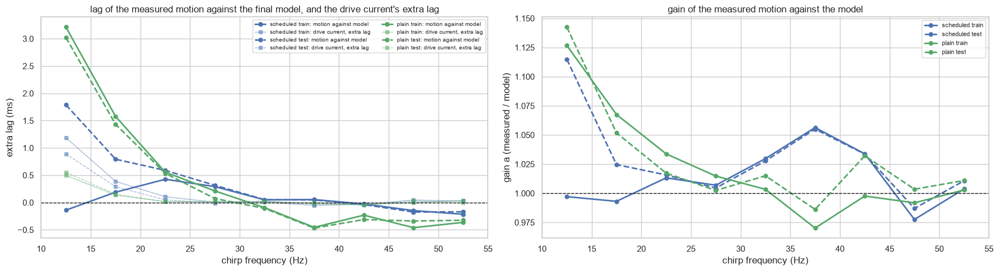

In [74]:
F_HP_LAG = 6.0                                          # Hz, high-pass that removes the slow offset before the lag fit
sos_hp_lag = signal.butter(4, F_HP_LAG / 500.0, btype="high", output="sos")
LAG_BANDS = list(zip(SENT_BANDS[:-1], SENT_BANDS[1:]))  # 5 Hz bands, 10-55 Hz
RUNS_LAG = {"scheduled train": ("chirpsched", "train"), "scheduled test": ("chirpsched", "test"),
            "plain train": ("chirp", "train"), "plain test": ("chirp", "test")}


def motion_lag(y_meas, y_mod, d_, use_):
    "Per band: time shift of the measurement against the model (s, positive = measured later) and the gain a, from y = a y_mod + b dy_mod/dt."
    ym = signal.sosfiltfilt(sos_hp_lag, y_meas)
    yp = signal.sosfiltfilt(sos_hp_lag, np.nan_to_num(y_mod, nan=y_mod[BURN_IN]))
    dyp = np.gradient(yp, TS)
    out = []
    for lo, hi in LAG_BANDS:
        m_ = use_ & (d_["f"] >= lo) & (d_["f"] < hi)
        A_ = np.column_stack([yp[m_], dyp[m_]])
        a_, b_ = np.linalg.lstsq(A_, ym[m_], rcond=None)[0]
        out.append((-b_ / a_, a_))
    return np.array(out)


LAG = {}
for name, key in RUNS_LAG.items():
    d_ = DATA[key[0]][key[1]]
    y_mod = sim_any(predict_sym, d_)
    use_ = d_["valid"] & d_["sweep"] & (d_["t"] >= 1.0) & np.isfinite(y_mod)
    raw_ = RAW_DF[key]
    i_fn_, f_fn_ = sent_current_fn(RAW_LOGS[key])
    t_ = raw_["time_s"].to_numpy()
    y_c = raw_["actual_current_A"].to_numpy()
    drv = np.array([delay_gain(t_[m_], y_c[m_], i_fn_)[0]
                    for lo, hi in LAG_BANDS for m_ in [(t_ >= 0) & (f_fn_(t_) >= lo) & (f_fn_(t_) < hi)]])
    LAG[name] = dict(motion=motion_lag(d_["x"], y_mod, d_, use_), drive=drv - drv[np.array([lo >= 25 for lo, _ in LAG_BANDS])].mean())

f_mid_l = np.array([0.5 * (lo + hi) for lo, hi in LAG_BANDS])
fig, ax = plt.subplots(1, 2, figsize=(18, 5))
for (name, r_), color, ls in zip(LAG.items(), ("C0", "C0", "C2", "C2"), ("-", "--", "-", "--")):
    ax[0].plot(f_mid_l, r_["motion"][:, 0] * 1e3, "o" + ls, color=color, lw=2, ms=5, label=f"{name}: motion against model")
    ax[0].plot(f_mid_l, r_["drive"] * 1e3, "s" + ls, color=color, lw=1, ms=4, alpha=0.5, label=f"{name}: drive current, extra lag")
    ax[1].plot(f_mid_l, r_["motion"][:, 1], "o" + ls, color=color, lw=2, ms=5, label=name)
    print(f"{name:16s} motion lag against model (ms), 12.5 .. 52.5 Hz: " + " ".join(f"{v * 1e3:+.2f}" for v in r_["motion"][:, 0]))
    print(f"{'':16s} drive current extra lag (ms)               : " + " ".join(f"{v * 1e3:+.2f}" for v in r_["drive"]))
ax[0].axhline(0.0, color="k", lw=1, ls="--")
ax[0].set(xlabel="chirp frequency (Hz)", ylabel="extra lag (ms)", xticks=SENT_BANDS,
          title="lag of the measured motion against the final model, and the drive current's extra lag")
ax[0].legend(fontsize=7, ncol=2)
ax[1].axhline(1.0, color="k", lw=1, ls="--")
ax[1].set(xlabel="chirp frequency (Hz)", ylabel="gain a (measured / model)", xticks=SENT_BANDS, title="gain of the measured motion against the model")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Findings (the drive's lag below 20 Hz).**

- **The motion's lag does not follow the drive's lag; it runs the other way.** At 12.5 Hz the drive current's extra lag is largest on the run with the smallest current (scheduled train, 2 A: +1.2 ms), then scheduled test (3 A: +0.9 ms), smallest on the plain chirps (6–6.5 A: +0.5 ms). The measured motion lags the model by −0.1, +1.8 and +3.0–3.2 ms on the same runs: the run whose current lags most is the one the model gets right.
- **The motion lags far more than the drive could explain:** up to 3 ms on the plain chirps, against 0.5 ms of extra current lag there.
- **Where the motion lags, it is also larger.** At 12.5 Hz the plain chirps are 13–14 % above the model, scheduled test 11 %, scheduled train about 0 %.
- **Lag and gain together are the signature of too much damping in the model.** Above the spring resonance the damping advances the phase by about $\arctan\!\big(c\omega / (m\omega^2 - k)\big)$: less damping gives more lag and more amplitude at once. From the lag at 12.5 Hz the effective damping is about 1600 N·s/m on the plain chirps, about 2100 on scheduled test and about 2840 (the model's value) on scheduled train; $c \approx 1600$ also predicts the plain chirps' gain (1.14 against 1.13–1.14 measured).
- **So the effective damping falls as the stroke grows.** The fitted $c$ is a compromise over the scheduled runs, which is why it moved between frequency ranges in the previous check. The effect fades above about 25 Hz, where the damping term becomes small against the mass term ($c\omega / m\omega^2 \propto 1/\omega$).
- **A small separate effect:** on the plain chirps above 35 Hz the measured motion leads the model by about 0.3–0.5 ms.
- **Decision: no drive block D3.** The drive's extra lag at low frequency is real in its current readback but does not show in the motion. Next: a damping that depends on the stroke.

## A friction force: damping that depends on the stroke

A force of constant size opposing the motion, Coulomb-like friction $F_c\,\operatorname{sign}(v)$, acts on a sinusoidal motion of amplitude $X$ at frequency $\omega$ like an equivalent viscous damping

$$c_\text{eq} = \frac{4 F_c}{\pi\,\omega X}$$

which is larger at small stroke: the direction found above. It would also explain the force loss at small current (section 4): a force that does not scale with the current takes a larger share of a small one. The damping becomes a viscous part and a friction part:

$$m\ddot{x} = (\Gamma + \Gamma_2 x^2)\, i_\text{sent}(t - \tau_d) - c_v\,\dot{x} - F_c \tanh\!\left(\frac{\dot{x}}{v_s}\right) - C\left(\frac{1}{(g - x)^3} - \frac{1}{(g + x)^3}\right)$$

- **$\tanh$ instead of the sign**, with a fixed $v_s$ = `V_S_FRIC` = 5 mm/s: smooth, so RK4 at 1 ms stays accurate (its slope at $v = 0$ gives a time constant $m v_s / F_c$ of about 2.6 ms at $F_c$ = 100 N), and far below the velocities in the band (about 0.1 m/s and up).
- **A rough estimate from the three effective dampings above:** $F_c$ of order 100 N with $c_v$ of about 1100 N·s/m. That is large for an air bearing; the term stands for anything that behaves like friction (cable drag, hysteresis), and the fit decides its size.
- **Fit on both train runs**, scheduled chirp and plain chirp: the effect is a difference between strokes, and one small-stroke run cannot separate the viscous from the friction part. The same offset-free output-error cost as before, on both runs' predictions (the plain chirp from 10 Hz, every window with its burn-in fully valid). Fitted: $\Gamma$, $c_v$, $\tau_d$, $F_c$; the symmetric spring and the sensor pair fixed.
- **A fair reference:** the same fit on the same two runs without friction ($\Gamma$, $c$, $\tau_d$), so a gain is not just from adding the plain run.
- **Judged on what neither fit used:** the scheduled test run (standard validation), the plain test run, the September runs at 6.5 A and 5 A, and PRBS, all in free run.

In [75]:
V_S_FRIC = 5e-3                                         # m/s, velocity scale of the smooth friction


def rollout_fric(p, F_c, d, s, H, tau_d, B=BURN_IN):
    "rollout_v2 with the symmetric spring and a friction force F_c tanh(v / V_S_FRIC); returns x at s-B..s+H (burn-in included). p = [Gamma, c_v, Gamma2, C]."
    i_fn = d["i_fn"]
    acc = lambda x, v, t: (p[0] * (u := i_fn(t - tau_d)) - p[1] * v - F_c * np.tanh(v / V_S_FRIC) - spring_SYM(x, u, p[2:])) / M
    s = np.asarray(s)
    x, v, t = d["x"][s - B].copy(), d["v"][s - B].copy(), d["t"][s - B].copy()
    out = []
    with np.errstate(all="ignore"):
        for k in range(B + H):
            out.append(x)
            k1x, k1v = v, acc(x, v, t)
            k2x, k2v = v + TS / 2 * k1v, acc(x + TS / 2 * k1x, v + TS / 2 * k1v, t + TS / 2)
            k3x, k3v = v + TS / 2 * k2v, acc(x + TS / 2 * k2x, v + TS / 2 * k2v, t + TS / 2)
            k4x, k4v = v + TS * k3v, acc(x + TS * k3x, v + TS * k3v, t + TS)
            x = x + TS / 6 * (k1x + 2 * k2x + 2 * k3x + k4x)
            v = v + TS / 6 * (k1v + 2 * k2v + 2 * k3v + k4v)
            t = t + TS
        out.append(x)
    return np.stack(out, axis=1)


def predict_fric(p, F_c, tau_d, d, s, H, B=BURN_IN):
    "Laser reading predicted at s..s+H by the friction model: the rollout with burn-in, through the 34 Hz sensor pair (as predict_sensor)."
    y_full = rollout_fric(p, F_c, d, s, H, tau_d, B=B)
    b, a = sensor_sos(*sens_S)
    zi = signal.lfilter_zi(b, a)[None, :] * y_full[:, :1]
    y_full, _ = signal.lfilter(b, a, y_full, axis=1, zi=zi)
    return y_full[:, -(H + 1):]


# self-check: without friction it must reproduce the final model
_s = s_oe[:5]
assert np.allclose(predict_fric(p_SYM, 0.0, tau_S, d_oe, _s, H_OE), predict_sym(d_oe, _s, H_OE), atol=1e-12)

# the plain chirp (train): predictions from 10 Hz whose whole window, burn-in included, is valid
d_pt = DATA["chirp"]["train"]
s_pt = np.arange(BURN_IN, len(d_pt["t"]) - H_OE - 1, STRIDE_OE)
s_pt = s_pt[d_pt["sweep"][s_pt + H_OE] & (d_pt["f"][s_pt] >= 10.0)]
n_bad = np.r_[0, np.cumsum(~d_pt["valid"])]
s_pt = s_pt[n_bad[s_pt + H_OE + 1] - n_bad[s_pt - BURN_IN] == 0]
X_pt = target(d_pt, s_pt, H_OE)[:, 1:]
sig_pt = np.sqrt(np.mean((X_pt @ P_oe.T) ** 2, axis=1))
FRIC_SETS = {"scheduled train": (d_oe, s_oe, X_oe, sig_oe), "plain train": (d_pt, s_pt, X_pt, sig_pt)}


def res_fric(q, split=False):
    "Offset-free output-error residuals on both train runs; q = [Gamma, c_v, tau_d] or [Gamma, c_v, tau_d, F_c]."
    F_c = q[3] if len(q) > 3 else 0.0
    out = {}
    for name, (d_, s_, X_, sg_) in FRIC_SETS.items():
        y_ = predict_fric(np.r_[q[0], q[1], p_SYM[2:]], F_c, q[2], d_, s_, H_OE)[:, 1:]
        e = np.nan_to_num(y_ - X_, nan=1.0, posinf=1.0, neginf=-1.0)
        out[name] = ((e @ P_oe.T) / sg_[:, None]).ravel()
    return out if split else np.concatenate(list(out.values()))


qn0 = np.r_[p_SYM[0], p_SYM[1], tau_S]                  # no friction: from the final model
qf0 = np.r_[p_SYM[0], 1100.0, tau_S, 100.0]             # friction: from the rough estimate
fit_nf = cached("fit_nofric_2runs", (qn0, p_SYM, g_sym, sens_S, s_oe, s_pt, H_OE, BURN_IN),
                lambda: least_squares(res_fric, qn0, bounds=([0, 0, 0], [np.inf, np.inf, 5e-3]), x_scale=np.abs(qn0)))
fit_fr = cached("fit_fric_2runs", (qf0, V_S_FRIC, p_SYM, g_sym, sens_S, s_oe, s_pt, H_OE, BURN_IN),
                lambda: least_squares(res_fric, qf0, bounds=([0, 0, 0, 0], [np.inf, np.inf, 5e-3, 300.0]), x_scale=np.abs(qf0)))
p_NF, tau_NF = np.r_[fit_nf.x[0], fit_nf.x[1], p_SYM[2:]], fit_nf.x[2]
p_FR, tau_FR, Fc_FR = np.r_[fit_fr.x[0], fit_fr.x[1], p_SYM[2:]], fit_fr.x[2], fit_fr.x[3]
predict_nf = lambda d, s, H: predict_fric(p_NF, 0.0, tau_NF, d, s, H)
predict_fr = lambda d, s, H: predict_fric(p_FR, Fc_FR, tau_FR, d, s, H)

print(f"{len(s_oe)} predictions on the scheduled train run, {len(s_pt)} on the plain train run")
for lab, q_ in (("final model (fitted on scheduled train)", qn0), ("refit without friction", fit_nf.x), ("with friction", fit_fr.x)):
    r_ = res_fric(q_, split=True)
    print(f"{lab:40s} Gamma = {q_[0]:6.1f} N/A, c = {q_[1]:5.0f} N s/m, tau_d = {q_[2] * 1e3:.2f} ms"
          + (f", F_c = {q_[3]:5.1f} N" if len(q_) > 3 else " " * 15)
          + "; offset-free error " + ", ".join(f"{n} {np.sqrt(np.mean(v ** 2)):.4f}" for n, v in r_.items()))
for X_amp in (1e-3, 2e-3, 5e-3):
    print(f"equivalent damping of the friction at 12.5 Hz, amplitude {X_amp * 1e3:.0f} mm: "
          f"{4 * Fc_FR / (np.pi * 2 * np.pi * 12.5 * X_amp):.0f} N s/m (plus c_v = {p_FR[1]:.0f})")

2395 predictions on the scheduled train run, 1018 on the plain train run


final model (fitted on scheduled train)  Gamma =  229.3 N/A, c =  2836 N s/m, tau_d = 3.08 ms               ; offset-free error scheduled train 0.0817, plain train 0.1705


refit without friction                   Gamma =  227.0 N/A, c =  2429 N s/m, tau_d = 2.88 ms               ; offset-free error scheduled train 0.0927, plain train 0.1362


with friction                            Gamma =  229.0 N/A, c =  1097 N s/m, tau_d = 2.73 ms, F_c = 130.9 N; offset-free error scheduled train 0.0655, plain train 0.0702
equivalent damping of the friction at 12.5 Hz, amplitude 1 mm: 2121 N s/m (plus c_v = 1097)
equivalent damping of the friction at 12.5 Hz, amplitude 2 mm: 1061 N s/m (plus c_v = 1097)
equivalent damping of the friction at 12.5 Hz, amplitude 5 mm: 424 N s/m (plus c_v = 1097)


### Validation

1. **The standard validation** on the scheduled chirps, against the final model.
2. **The lag and gain check** of the drive section, repeated with the friction model: if friction is the cause, its curves flatten.
3. **Free run on what neither fit used**, per band, as it is and offset-free: the plain test run (6 A), the September runs (6.5 A, 15:55 and 16:05; 5 A, 15:18), and PRBS. Three models: the final model, the refit without friction and the friction model.

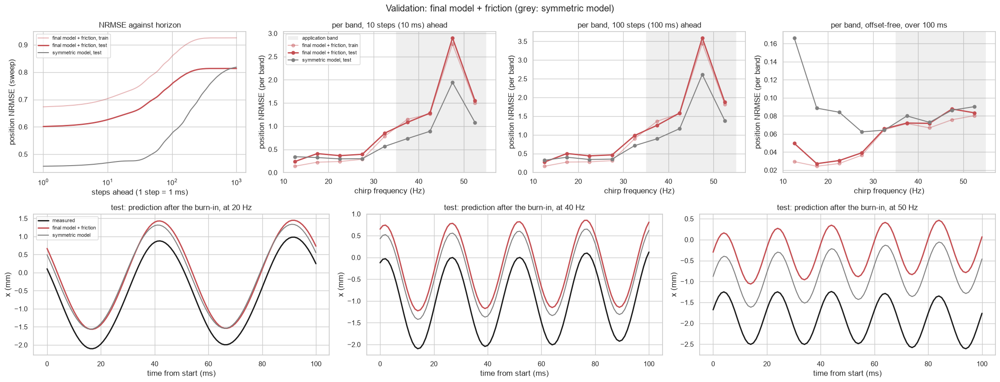

NRMSE at k = 10, 100, 1000 (sweep): train 0.704, 0.858, 0.925; test 0.626, 0.758, 0.813
band (Hz)        final model + fricti train        final model + fricti test             symmetric model test
                 k=10      k=100         hp       k=10      k=100         hp       k=10      k=100         hp
  10-15         0.136      0.161      0.029      0.236      0.272      0.050      0.342      0.322      0.166
  15-20         0.224      0.272      0.024      0.410      0.502      0.027      0.324      0.402      0.089
  20-25         0.238      0.279      0.027      0.365      0.439      0.031      0.296      0.342      0.084
  25-30         0.286      0.312      0.037      0.394      0.465      0.039      0.299      0.353      0.062
  30-35         0.786      0.897      0.065      0.851      0.982      0.066      0.566      0.712      0.064
  35-40         1.148      1.365      0.072      1.082      1.257      0.072      0.733      0.896      0.080
  40-45         1.263      1.570

In [76]:
validate("final model + friction", predict_fr, ref="symmetric model", table=True)

scheduled train  with friction: lag (ms) -0.11 +0.06 +0.08 -0.00 -0.12 +0.00 +0.03 -0.02 -0.03 | gain 1.018 0.988 0.987 0.982 1.008 1.040 1.022 0.970 1.000


scheduled test   with friction: lag (ms) +0.31 +0.17 +0.10 +0.01 -0.11 +0.01 +0.03 -0.03 +0.03 | gain 1.041 0.990 0.984 0.979 1.007 1.039 1.022 0.981 1.007


plain train      with friction: lag (ms) +0.01 +0.27 +0.05 +0.09 -0.00 -0.23 +0.06 -0.11 +0.02 | gain 0.998 1.009 1.000 0.997 0.994 0.971 1.000 1.003 1.015


plain test       with friction: lag (ms) -0.06 +0.21 +0.09 +0.01 +0.03 -0.21 +0.02 +0.04 +0.09 | gain 1.013 0.995 0.987 0.987 1.008 0.990 1.039 1.014 1.024


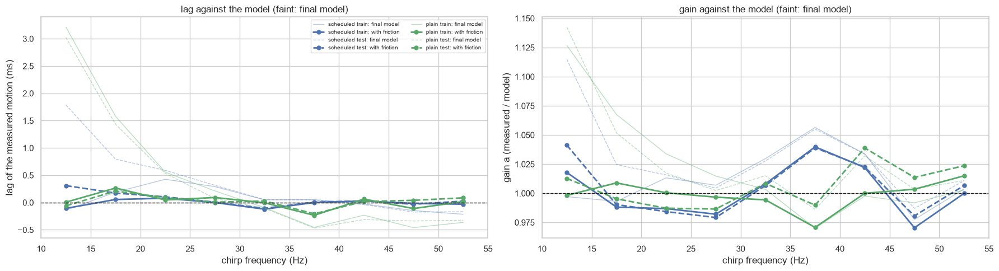

In [77]:
fig, ax = plt.subplots(1, 2, figsize=(18, 5))
for (name, key), color, ls in zip(RUNS_LAG.items(), ("C0", "C0", "C2", "C2"), ("-", "--", "-", "--")):
    d_ = DATA[key[0]][key[1]]
    y_fr = sim_any(predict_fr, d_)
    use_ = d_["valid"] & d_["sweep"] & (d_["t"] >= 1.0) & np.isfinite(y_fr)
    lag_fr = motion_lag(d_["x"], y_fr, d_, use_)
    for col in (0, 1):
        scale = 1e3 if col == 0 else 1.0
        ax[col].plot(f_mid_l, LAG[name]["motion"][:, col] * scale, ls, color=color, lw=1, alpha=0.4, label=f"{name}: final model")
        ax[col].plot(f_mid_l, lag_fr[:, col] * scale, "o" + ls, color=color, lw=2, ms=5, label=f"{name}: with friction")
    print(f"{name:16s} with friction: lag (ms) " + " ".join(f"{v * 1e3:+.2f}" for v in lag_fr[:, 0])
          + " | gain " + " ".join(f"{v:.3f}" for v in lag_fr[:, 1]))
ax[0].axhline(0.0, color="k", lw=1, ls="--")
ax[0].set(xlabel="chirp frequency (Hz)", ylabel="lag of the measured motion (ms)", xticks=SENT_BANDS, title="lag against the model (faint: final model)")
ax[0].legend(fontsize=7, ncol=2)
ax[1].axhline(1.0, color="k", lw=1, ls="--")
ax[1].set(xlabel="chirp frequency (Hz)", ylabel="gain a (measured / model)", xticks=SENT_BANDS, title="gain against the model (faint: final model)")
plt.tight_layout(); plt.show()

final model              Oct 0942, 6.0A  as it is: 0.15 0.23 0.25 0.63 0.73 1.10 2.55 | offset-free: 0.052 0.097 0.090 0.156 0.208 0.072 0.104


final model              Sep 1555, 6.5A  as it is: 0.15 0.21 0.45 0.98 1.10 1.39 1.28 | offset-free: 0.051 0.086 0.106 0.134 0.191 0.085 0.093


final model              Sep 1605, 6.5A  as it is: 0.15 0.23 0.26 0.97 1.02 1.27 2.78 | offset-free: 0.054 0.095 0.094 0.137 0.185 0.076 0.093


final model              Sep 1518, 5.0A  as it is: 0.15 0.23 0.24 0.30 0.25 0.22 1.02 | offset-free: 0.043 0.092 0.083 0.175 0.219 0.059 0.110


final model              PRBS            per band: 0.237 0.272 0.235 0.178 0.374


refit without friction   Oct 0942, 6.0A  as it is: 0.20 0.19 0.15 0.60 0.72 1.10 2.55 | offset-free: 0.031 0.053 0.057 0.109 0.156 0.056 0.098


... (5 outputs left out)

with friction            Sep 1555, 6.5A  as it is: 0.43 0.73 2.23 1.05 1.08 1.39 1.28 | offset-free: 0.118 0.231 0.483 0.082 0.026 0.037 0.079


with friction            Sep 1605, 6.5A  as it is: 0.41 0.73 1.01 0.98 1.00 1.27 2.78 | offset-free: 0.115 0.235 0.350 0.135 0.027 0.044 0.081


with friction            Sep 1518, 5.0A  as it is: 0.36 0.76 0.59 0.17 0.07 0.22 1.02 | offset-free: 0.073 0.162 0.158 0.083 0.036 0.045 0.079


with friction            PRBS            per band: 0.413 0.283 0.178 0.141 0.366


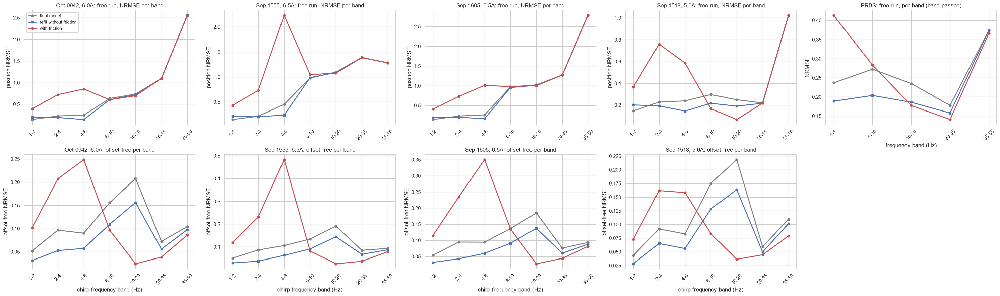

In [78]:
FRIC_CMP = {"final model": (predict_sym, dict(color="0.5", marker="o")),
            "refit without friction": (predict_nf, dict(color="C0", marker="s")),
            "with friction": (predict_fr, dict(color="C3", marker="o"))}
FREE_UNSEEN = {"Oct 0942, 6.0A": DATA["chirp"]["test"], "Sep 1555, 6.5A": SEP["Sep 1555, 6.5A"],
               "Sep 1605, 6.5A": SEP["Sep 1605, 6.5A"], "Sep 1518, 5.0A": SEP["Sep 1518, 5.0A"]}
fig, ax = plt.subplots(2, len(FREE_UNSEEN) + 1, figsize=(6 * (len(FREE_UNSEEN) + 1), 9))
for name, (pred, st) in FRIC_CMP.items():
    for col, (run, d_) in enumerate(FREE_UNSEEN.items()):
        y_ = sim_any(pred, d_)
        use_ = d_["valid"] & (d_["t"] >= 1.0) & d_["sweep"] & np.isfinite(y_)
        be = band_errors(y_, d_, BANDS_SEP, use_)
        ax[0, col].plot(labels_s, be[:, 0], lw=2, ms=5, label=name, **st)
        ax[1, col].plot(labels_s, be[:, 1], lw=2, ms=5, label=name, **st)
        ax[0, col].set(title=f"{run}: free run, NRMSE per band", ylabel="position NRMSE")
        ax[1, col].set(title=f"{run}: offset-free per band", ylabel="offset-free NRMSE", xlabel="chirp frequency band (Hz)")
        print(f"{name:24s} {run:15s} as it is: " + " ".join(f"{v:.2f}" for v in be[:, 0])
              + " | offset-free: " + " ".join(f"{v:.3f}" for v in be[:, 1]))
    bp = prbs_band_errors(sim_any(pred, d_prbs), d_prbs)
    ax[0, -1].plot(labels_p, bp, lw=2, ms=5, label=name, **st)
    print(f"{name:24s} {'PRBS':15s} per band: " + " ".join(f"{v:.3f}" for v in bp))
ax[0, -1].set(title="PRBS: free run, per band (band-passed)", xlabel="frequency band (Hz)", ylabel="NRMSE")
ax[1, -1].axis("off")
ax[0, 0].legend(fontsize=9)
for a_ in ax.ravel():
    a_.tick_params(axis="x", labelrotation=45)
plt.tight_layout(); plt.show()